# 05 — Global Direct Multi-Horizon XGBoost

## Objective

This notebook develops the first global machine-learning forecasting model for
the retail demand forecasting platform.

The model is designed directly around the production planning problem:

> At the end of forecast origin $T$, predict daily demand for every
> store-family combination from $T+1$ through $T+14$.

Instead of fitting one local model per time series, a single global XGBoost
model shares statistical strength across all store-family combinations.

The notebook covers:

- point-in-time-safe feature engineering;
- direct multi-horizon forecasting;
- historical lag and rolling behavioral features;
- known-in-advance target-date calendar features;
- store and family information;
- global XGBoost training;
- rolling temporal validation;
- portfolio, horizon, and demand-regime diagnostics;
- lightweight hyperparameter tuning;
- comparison against the classical forecasting benchmarks.

Promotion effects are intentionally excluded from this notebook and are handled
in the subsequent promotion/causal-analysis stage.

The final August 2–15, 2017 temporal holdout remains untouched throughout
model development.

## 1. Forecasting Formulation and Leakage Contract

### 1.1 Global direct multi-horizon formulation

Let:

- $s$ denote a store;
- $f$ denote a product family;
- $T$ denote the forecast origin;
- $h \in \{1,\ldots,14\}$ denote the forecast horizon;
- $Y_{s,f,t}$ denote observed sales for store $s$, family $f$, on date $t$.

For every forecast origin $T$, the target is:

$$
y_{s,f,T,h} = Y_{s,f,T+h}.
$$

The global forecasting model is written as:

$$
\hat{Y}_{s,f,T+h}
=
F\left(
I_s,
I_f,
H_{s,f,T},
C_{T+h},
h
\right),
$$

where:

- $I_s$ contains store identity and static store information;
- $I_f$ identifies the product family;
- $H_{s,f,T}$ contains historical demand information available by origin $T$;
- $C_{T+h}$ contains information known in advance about the target date;
- $h$ explicitly tells the model how far into the future it is forecasting.

This is a **global** model because the same function $F$ is estimated using
observations from all store-family series.

It uses a **horizon-conditioned direct multi-horizon formulation**.

Each `(forecast origin, horizon)` pair is represented as one supervised-learning
row. The target $Y_{T+h}$ is predicted directly from information available at
forecast origin $T$, together with target-date information known in advance.

Forecasts for earlier horizons are never fed back into the model to construct
later-horizon forecasts. The horizon $h$ is itself provided as a feature so
that one global model can learn horizon-dependent forecasting behavior.


### 1.2 Why use a horizon-conditioned long formulation?

The 14-day forecasting problem can be represented in several different ways.

#### Alternative 1 — One direct model per horizon

Train 14 separate models:

$$
F_h(X_T) \rightarrow Y_{T+h},
\qquad h=1,\ldots,14.
$$

This gives each horizon maximum flexibility, but:

- patterns cannot be shared statistically across horizons;
- 14 models must be trained, tuned, versioned, deployed, and monitored;
- relationships that are useful across several horizons must be relearned independently.

#### Alternative 2 — Multi-output forecasting

Keep one row per forecast origin and predict the complete future vector:

$$
\mathbf{Y}_T
=
\left[
Y_{T+1},
Y_{T+2},
\ldots,
Y_{T+14}
\right].
$$

This avoids multiplying the number of rows by 14 and produces the entire
forecast trajectory jointly.

However, the horizon dimension does not disappear: it moves into the output
dimension.

This creates additional complexity because:

- the target becomes vector-valued rather than scalar;
- known-future variables differ across the 14 target dates;
- variables such as weekday or promotion status would require
  horizon-specific representations;
- depending on the implementation, horizons may either share too little model
  structure or be forced to share a tree structure that is too restrictive.

#### Selected approach — Horizon-conditioned long formulation

The supervised-learning grain is:

$$
(\text{store},\text{family},\text{forecast origin},\text{horizon}).
$$

Each row has one scalar target:

$$
Y_{s,f,T+h}.
$$

Historical features remain anchored at the same origin $T$, while the horizon
and target-date variables change across rows.

This formulation allows a single model to share statistical strength across:

- stores;
- product families;
- forecast horizons.

At the same time, XGBoost can learn horizon-specific interactions.

For example, the trees may learn that:

- very recent sales are especially useful at short horizons;
- longer rolling averages become more important at longer horizons;
- calendar effects differ across families and forecast horizons.

The main cost is a larger supervised-learning table:

$$
N_{\text{rows}}
=
N_{\text{series}}
\times
N_{\text{forecast origins}}
\times
N_{\text{horizons}}.
$$

This increases memory and training cost, so the historical forecast-origin
sampling strategy must be designed explicitly.

For this project, this is the preferred trade-off because it combines:

- one production model;
- scalar XGBoost regression;
- cross-horizon statistical pooling;
- horizon-specific flexibility;
- natural support for target-date calendar and future promotion features.


### 1.3 Origin-relative historical features

Historical sales features are defined relative to the forecast origin.

For example:

$$
\text{sales\_at\_origin} = Y_T,
$$

$$
\text{sales\_lag\_1d} = Y_{T-1},
$$

$$
\text{sales\_lag\_7d} = Y_{T-7}.
$$

For a rolling calendar window of length $w$:

$$
\text{rolling\_mean}_{w}(T)
=
\frac{
\sum_{j=0}^{w-1}
Y_{T-j}
\mathbf{1}(Y_{T-j}\text{ observed})
}{
\sum_{j=0}^{w-1}
\mathbf{1}(Y_{T-j}\text{ observed})
}.
$$

The target may be $Y_{T+1}$ or $Y_{T+14}$, but these historical state features remain
anchored at the same forecast origin $T$.

A second class of historical features can instead be aligned with the future target
date $D=T+h$. For example, $Y_{D-364}$ describes demand on the same weekday
52 weeks before the target date. Those horizon-specific seasonal analogues are
constructed later, at the origin-horizon level, because they change with $h$.


### 1.4 Known-future features

Some information about $T+h$ is already known at forecast time.

Examples include:

- target day of week;
- target month;
- weekend status;
- forecast horizon $h$.

These are valid predictors because they do not depend on future realized demand.


### 1.5 Point-in-time leakage contract

A training row is valid only if both of the following conditions hold:

1. every historical feature is constructed exclusively from information
   available on or before its forecast origin $T$;
2. its target $Y_{T+h}$ had already been observed at the model-training cutoff.

Therefore, when fitting a model at validation cutoff $V$, a historical training
row may be used only if:

$$
T+h \le V.
$$

Checking only $T < V$ is insufficient because the target attached to that
historical forecast origin may still lie in the future relative to $V$.

The August 2–15 final temporal holdout is excluded from every feature-selection,
model-selection, and tuning decision.

## 2. Environment and Curated Data Access

The forecasting model is trained from the curated analytical layer produced
during the data-engineering stage.

The physical data is stored as Parquet files in Amazon S3. The AWS Glue Data
Catalog provides the logical table definition and its physical S3 location,
while Athena remains available for SQL analytics and data-quality queries.

For model development, the full historical dataset is required in the Python
environment to construct point-in-time lag and rolling features. Reading the
curated Parquet files directly therefore avoids an unnecessary intermediate
Athena CSV export:

$$
\text{S3 curated Parquet}
\rightarrow
\text{PyArrow}
\rightarrow
\text{pandas}
\rightarrow
\text{feature engineering}
$$

Only the development period through August 1, 2017 is loaded for model
development. The August 2–15 final temporal holdout remains excluded.

In [1]:
from pathlib import Path
import json
import subprocess

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.fs as pafs
import sklearn
import xgboost as xgb


pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)


AWS_REGION = "eu-west-1"

CURATED_DATABASE = "retail_demand_forecasting_curated"
SALES_TABLE = "stg_sales"

DEVELOPMENT_END_DATE = pd.Timestamp("2017-08-01")
FINAL_HOLDOUT_START = pd.Timestamp("2017-08-02")
FINAL_HOLDOUT_END = pd.Timestamp("2017-08-15")

FORECAST_HORIZON = 14

VALIDATION_ORIGINS = pd.to_datetime(
    [
        "2017-05-09",
        "2017-05-23",
        "2017-06-06",
        "2017-06-20",
        "2017-07-04",
        "2017-07-18",
    ]
)

In [2]:
print("Python environment ready")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("PyArrow:", pa.__version__)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)

Python environment ready
Pandas: 3.0.6
NumPy: 2.5.3
PyArrow: 26.0.0
scikit-learn: 1.9.1
XGBoost: 3.4.1


### 2.1 Resolve the curated table through AWS Glue

The notebook does not hard-code the physical S3 path of the curated sales
dataset.

Instead, it queries the AWS Glue Data Catalog for the storage location
associated with:

`retail_demand_forecasting_curated.stg_sales`

This keeps the model-development layer connected to the cataloged analytical
data platform rather than depending on an independently maintained file path.

In [3]:
def get_glue_table_location(
    database_name,
    table_name,
):
    """Return the physical S3 location registered for a Glue table."""

    result = subprocess.run(
        [
            "aws",
            "glue",
            "get-table",
            "--database-name",
            database_name,
            "--name",
            table_name,
            "--query",
            "Table.StorageDescriptor.Location",
            "--output",
            "text",
            "--region",
            AWS_REGION,
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    return result.stdout.strip()


STG_SALES_S3_LOCATION = get_glue_table_location(
    CURATED_DATABASE,
    SALES_TABLE,
)

print(
    "stg_sales S3 location:",
    STG_SALES_S3_LOCATION,
)

stg_sales S3 location: s3://retail-demand-forecasting-platform-aws-zaamine/curated/stg_sales


### 2.2 Inspect the curated Parquet dataset

PyArrow is used to access the physical Parquet dataset directly from S3.

Before loading the data into pandas, the dataset schema is inspected to verify
that the model-development code is reading the expected curated representation.

Only the columns required for the first forecasting model are selected:

- `date`
- `store_nbr`
- `family`
- `sales`

Promotion variables are deliberately excluded at this stage and will be
introduced separately during the promotion-analysis phase.

In [4]:
s3_filesystem, sales_dataset_path = (
    pafs.FileSystem.from_uri(
        STG_SALES_S3_LOCATION
    )
)

sales_dataset = ds.dataset(
    sales_dataset_path,
    filesystem=s3_filesystem,
    format="parquet",
)

print("Dataset path:", sales_dataset_path)
print()
print("Curated Parquet schema:")
print(sales_dataset.schema)

Dataset path: retail-demand-forecasting-platform-aws-zaamine/curated/stg_sales

Curated Parquet schema:
id: int64
date: date32[day]
store_nbr: int64
family: string
sales: double
onpromotion: int64
-- schema metadata --
writer.time.zone: 'UTC'


In [5]:
sales_fragments = list(
    sales_dataset.get_fragments()
)

print(
    "Parquet fragments:",
    len(sales_fragments),
)

for fragment in sales_fragments[:10]:
    print(fragment.path)

Parquet fragments: 1
retail-demand-forecasting-platform-aws-zaamine/curated/stg_sales/20261015_203001_00043_ern7f_d400624a-58b3-4187-ac69-074231b5af9b


In [6]:
date_arrow_type = (
    sales_dataset.schema.field("date").type
)

print(
    "Arrow date type:",
    date_arrow_type,
)

Arrow date type: date32[day]


In [7]:
if pa.types.is_date(date_arrow_type):
    development_cutoff_arrow = (
        DEVELOPMENT_END_DATE.date()
    )

elif pa.types.is_timestamp(date_arrow_type):
    development_cutoff_arrow = (
        DEVELOPMENT_END_DATE.to_pydatetime()
    )

else:
    raise TypeError(
        f"Unexpected Arrow date type: "
        f"{date_arrow_type}"
    )

In [8]:
sales_arrow = sales_dataset.to_table(
    columns=[
        "date",
        "store_nbr",
        "family",
        "sales",
    ],
    filter=(
        ds.field("date")
        <= development_cutoff_arrow
    ),
)

print(
    "Rows loaded from Parquet:",
    sales_arrow.num_rows,
)

print(
    "Columns loaded:",
    sales_arrow.num_columns,
)

print(
    "In-memory Arrow size:",
    f"{sales_arrow.nbytes / 1024**2:.1f} MB",
)

Rows loaded from Parquet: 2975940
Columns loaded: 4
In-memory Arrow size: 99.4 MB


In [9]:
sales = sales_arrow.to_pandas()

sales["date"] = pd.to_datetime(
    sales["date"]
)

sales["store_nbr"] = (
    sales["store_nbr"]
    .astype("int16")
)

sales["family"] = (
    sales["family"]
    .astype("category")
)

sales["sales"] = (
    sales["sales"]
    .astype("float32")
)

sales = (
    sales
    .sort_values(
        [
            "store_nbr",
            "family",
            "date",
        ]
    )
    .reset_index(drop=True)
)

sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 2975940 entries, 0 to 2975939
Data columns (total 4 columns):
 #   Column     Dtype        
---  ------     -----        
 0   date       datetime64[s]
 1   store_nbr  int16        
 2   family     category     
 3   sales      float32      
dtypes: category(1), datetime64[s](1), float32(1), int16(1)
memory usage: 42.6 MB


### 2.3 Development-data integrity checks

Before constructing any forecasting features, the development dataset is
validated at its required grain:

$$
\text{date}
\times
\text{store}
\times
\text{family}.
$$

The checks ensure that:

- no final-holdout observation has entered model development;
- the grain is unique;
- the target contains no missing values;
- all expected store-family combinations remain represented.

In [10]:
assert (
    sales["date"].max()
    == DEVELOPMENT_END_DATE
)

assert (
    sales["date"].max()
    < FINAL_HOLDOUT_START
)

assert (
    sales.duplicated(
        [
            "date",
            "store_nbr",
            "family",
        ]
    ).sum()
    == 0
)

assert (
    sales["sales"]
    .isna()
    .sum()
    == 0
)

observed_series = (
    sales[
        [
            "store_nbr",
            "family",
        ]
    ]
    .drop_duplicates()
    .shape[0]
)

expected_cartesian_series = (
    sales["store_nbr"].nunique()
    * sales["family"].nunique()
)

assert (
    observed_series
    == expected_cartesian_series
)

print(
    "Development-data integrity checks: PASSED"
)

Development-data integrity checks: PASSED


## 3. Point-in-Time Origin Feature Layer

The first modeling dataset is built at the **forecast-origin level**.

For each store-family series and each calendar date $T$, one row contains only
information that would have been available at the end of $T$.

The origin-level feature table is built before creating the 14 forecast
horizons. This keeps historical feature computation independent from the
future target date and makes leakage easier to reason about and test.

### 3.1 Calendar regularization and missing dates

The raw sales history contains four globally missing dates: Christmas Day
(December 25) in 2013–2016.

These missing dates are not interpreted as zero demand.

For the global XGBoost model, they are also **not imputed**.

Instead:

1. every store-family series is reindexed onto a complete daily calendar;
2. the four missing Christmas observations remain `NaN`;
3. lag features therefore remain missing when their exact historical date was
   not observed;
4. rolling statistics use the available observations inside the requested
   calendar window;
5. zero-demand and positive-demand rates use the number of actually observed
   days as their denominator;
6. rows whose future target is unobserved will later be excluded from training.

This differs from the ETS preprocessing because the ETS implementation required
a complete regular numerical sequence. XGBoost can natively route missing
feature values, so fabricating historical sales is unnecessary.

The regularized calendar is still essential: a 28-day rolling window must mean
28 **calendar days**, not 28 observed rows.

In [11]:
CALENDAR_START_DATE = sales["date"].min()

development_calendar = pd.date_range(
    start=CALENDAR_START_DATE,
    end=DEVELOPMENT_END_DATE,
    freq="D",
)

store_values = np.sort(
    sales["store_nbr"].unique()
)

family_values = (
    sales["family"]
    .cat.categories
    .tolist()
)

full_index = pd.MultiIndex.from_product(
    [
        store_values,
        family_values,
        development_calendar,
    ],
    names=[
        "store_nbr",
        "family",
        "date",
    ],
)

regularized_sales = (
    sales
    .set_index(
        [
            "store_nbr",
            "family",
            "date",
        ]
    )
    .reindex(full_index)
    .reset_index()
)

regularized_sales["store_nbr"] = (
    regularized_sales["store_nbr"]
    .astype("int16")
)

regularized_sales["family"] = (
    regularized_sales["family"]
    .astype("category")
)

regularized_sales["sales"] = (
    regularized_sales["sales"]
    .astype("float32")
)

regularized_sales["sales_observed"] = (
    regularized_sales["sales"]
    .notna()
)

In [12]:
expected_regularized_rows = (
    len(development_calendar)
    * observed_series
)

print(
    "Calendar days:",
    len(development_calendar),
)

print(
    "Expected regularized rows:",
    expected_regularized_rows,
)

print(
    "Observed regularized rows:",
    len(regularized_sales),
)

print(
    "Missing sales after regularization:",
    regularized_sales["sales"]
    .isna()
    .sum(),
)

assert (
    len(regularized_sales)
    == expected_regularized_rows
)

Calendar days: 1674
Expected regularized rows: 2983068
Observed regularized rows: 2983068
Missing sales after regularization: 7128


In [13]:
missing_sales_by_date = (
    regularized_sales.loc[
        ~regularized_sales["sales_observed"]
    ]
    .groupby("date")
    .size()
    .rename("missing_series")
    .reset_index()
)

display(
    missing_sales_by_date
    .style.hide(axis="index")
)

date,missing_series
2013-12-25 00:00:00,1782
2014-12-25 00:00:00,1782
2015-12-25 00:00:00,1782
2016-12-25 00:00:00,1782


In [14]:
assert len(missing_sales_by_date) == 4

assert (
    missing_sales_by_date[
        "missing_series"
    ]
    == observed_series
).all()

print(
    "Calendar regularization checks: PASSED"
)

Calendar regularization checks: PASSED


### 3.2 Historical features available at the forecast origin

Because forecasts are issued at the **end of day $T$**, sales observed on day
$T$ are available to the model.

The origin feature layer is intended to describe the **historical state of the
series at forecast time**. Multiple forecast origins will later provide many
labeled examples of different historical states, while the features below define
how each individual state is represented.

The feature set is deliberately compact and interpretable. Each feature must
represent a distinct forecasting concept rather than an arbitrary mathematical
transformation.

#### Point observations and lag structure

$$
\text{sales\_at\_origin} = Y_T
$$

and:

$$
\text{sales\_lag}_{k} = Y_{T-k}.
$$

The short- and medium-term lags are:

$$
k \in \{1,2,3,7,14,21,28,35\}.
$$

These lags are motivated by the earlier time-series diagnostics. The diagnostic
ACF analysis examined lags through 35 days and found strong weekly structure at
multiples of seven for representative high-volume demand, while other regimes
showed shorter-memory behavior.

One longer origin-aligned annual anchor is also retained:

$$
\text{sales\_lag}_{364d}=Y_{T-364}.
$$

The value 364 is used deliberately because $364=52\times7$, so the comparison
preserves the day of week. A fixed 365-day lag would shift the weekday and is
not equivalent to an exact calendar-year anniversary in leap years.

This origin-aligned annual lag answers:

> What was this series selling on the same weekday 52 weeks before the current
> forecasting state?

It is distinct from the later **target-aligned** annual features, which will
compare the future target date $T+h$ with the same seasonal position in prior
years.

#### Rolling demand level

For window length $w$:

$$
\text{rolling\_mean}_{w}(T)
=
\frac{
\sum_{j=0}^{w-1}Y_{T-j}\mathbf{1}(Y_{T-j}\text{ observed})
}{
\sum_{j=0}^{w-1}\mathbf{1}(Y_{T-j}\text{ observed})
}.
$$

The initial rolling windows are:

- 7 days;
- 14 days;
- 28 days.

These features summarize the current local demand level over progressively
longer recent horizons.

#### Scale-normalized recent demand state

The raw rolling means preserve absolute demand scale. A separate ratio captures
whether the most recent week is high or low relative to the current monthly
baseline:

$$
\text{recent\_level\_ratio}
=
\frac{\text{rolling\_mean}_{7}}
{\text{rolling\_mean}_{28}}.
$$

Its business interpretation is direct:

- values around 1 indicate a stable recent level;
- values above 1 indicate recent acceleration;
- values below 1 indicate recent slowdown.

The ratio is left missing when the 28-day mean is effectively zero because a
relative level is then not meaningful. Keeping the original rolling means
alongside this ratio preserves both absolute demand scale and the scale-free
state comparison.

#### Recent volatility

A 28-calendar-day rolling standard deviation captures recent demand instability.

#### Intermittency features

Within the latest 28 calendar days:

$$
\text{zero\_share}_{28}
=
\frac{\#\{\text{observed zero-demand days}\}}
{\#\{\text{observed days}\}},
$$

and:

$$
\text{positive\_rate}_{28}
=
\frac{\#\{\text{positive-demand days}\}}
{\#\{\text{observed days}\}}.
$$

The mean positive-demand magnitude is computed only over days where demand is
strictly positive.

Finally:

$$
\text{days\_since\_last\_positive}
=
T-\max\{t\le T:Y_t>0\}.
$$

These behavioral features allow the global model to distinguish different
current demand regimes without hard-coding an archetype label.

Longer multi-year seasonal summaries are intentionally deferred to the
origin-horizon table because the most relevant historical analogue depends on
the target date $T+h$, not only on forecast origin $T$.


In [15]:
SERIES_KEYS = [
    "store_nbr",
    "family",
]

# Origin-relative lags used to describe the historical state available at T.
# Short/weekly lags are motivated by the earlier diagnostics; 364 days is a
# same-weekday annual anchor (52 weeks) rather than an exact calendar-year lag.
LAG_DAYS = [
    1,
    2,
    3,
    7,
    14,
    21,
    28,
    35,
    364,
]


# The current-day sale is available because forecasts are issued at the end
# of forecast origin T.
regularized_sales[
    "sales_at_origin"
] = regularized_sales[
    "sales"
].astype("float32")


series_group = (
    regularized_sales
    .groupby(
        SERIES_KEYS,
        observed=True,
        sort=False,
    )
)


# Calendar regularization guarantees that shift(k) now means exactly T-k
# calendar days rather than the kth previous observed row.
for lag_days in LAG_DAYS:

    regularized_sales[
        f"sales_lag_{lag_days}d"
    ] = (
        series_group["sales"]
        .shift(lag_days)
        .astype("float32")
    )


In [16]:
def grouped_rolling_feature(
    dataframe,
    value_column,
    window,
    aggregation,
    min_periods=1,
):
    """
    Compute a calendar-aligned rolling feature independently
    for each store-family series.
    """

    rolling = (
        dataframe
        .groupby(
            SERIES_KEYS,
            observed=True,
            sort=False,
        )[value_column]
        .rolling(
            window=window,
            min_periods=min_periods,
        )
    )

    if aggregation == "mean":
        values = rolling.mean()

    elif aggregation == "sum":
        values = rolling.sum()

    elif aggregation == "count":
        values = rolling.count()

    elif aggregation == "std":
        values = rolling.std(ddof=0)

    else:
        raise ValueError(
            f"Unsupported aggregation: "
            f"{aggregation}"
        )

    return (
        values
        .reset_index(
            level=SERIES_KEYS,
            drop=True,
        )
        .sort_index()
    )

In [17]:
# Compute local demand level over 7-, 14-, and 28-calendar-day windows.
for window in [
    7,
    14,
    28,
]:

    regularized_sales[
        f"rolling_mean_{window}d"
    ] = (
        grouped_rolling_feature(
            dataframe=regularized_sales,
            value_column="sales",
            window=window,
            aggregation="mean",
        )
        .astype("float32")
    )


# Capture recent volatility over the same 28-day local-state horizon used by
# the intermittency features below.
regularized_sales[
    "rolling_std_28d"
] = (
    grouped_rolling_feature(
        dataframe=regularized_sales,
        value_column="sales",
        window=28,
        aggregation="std",
        min_periods=2,
    )
    .astype("float32")
)


# Compare the very recent level with the current one-month baseline.
# The ratio is intentionally missing when the baseline is effectively zero;
# XGBoost can route missing values natively and the ratio has no stable
# business interpretation in that case.
rolling_7 = regularized_sales["rolling_mean_7d"]
rolling_28 = regularized_sales["rolling_mean_28d"]

recent_level_ratio = pd.Series(
    np.nan,
    index=regularized_sales.index,
    dtype="float32",
)

valid_ratio = (
    rolling_7.notna()
    & rolling_28.notna()
    & (rolling_28.abs() > 1e-8)
)

recent_level_ratio.loc[valid_ratio] = (
    rolling_7.loc[valid_ratio]
    / rolling_28.loc[valid_ratio]
).astype("float32")

regularized_sales[
    "recent_level_ratio"
] = recent_level_ratio


In [18]:
regularized_sales[
    "_zero_indicator"
] = np.where(
    regularized_sales["sales"].isna(),
    np.nan,
    (
        regularized_sales["sales"] == 0
    ).astype(float),
)


regularized_sales[
    "_positive_indicator"
] = np.where(
    regularized_sales["sales"].isna(),
    np.nan,
    (
        regularized_sales["sales"] > 0
    ).astype(float),
)


regularized_sales[
    "_positive_sales"
] = regularized_sales[
    "sales"
].where(
    regularized_sales["sales"] > 0
)

In [19]:
regularized_sales[
    "observed_days_28d"
] = (
    grouped_rolling_feature(
        dataframe=regularized_sales,
        value_column="sales",
        window=28,
        aggregation="count",
    )
    .astype("float32")
)


regularized_sales[
    "zero_share_28d"
] = (
    grouped_rolling_feature(
        dataframe=regularized_sales,
        value_column="_zero_indicator",
        window=28,
        aggregation="mean",
    )
    .astype("float32")
)


regularized_sales[
    "positive_rate_28d"
] = (
    grouped_rolling_feature(
        dataframe=regularized_sales,
        value_column="_positive_indicator",
        window=28,
        aggregation="mean",
    )
    .astype("float32")
)


regularized_sales[
    "positive_sales_mean_28d"
] = (
    grouped_rolling_feature(
        dataframe=regularized_sales,
        value_column="_positive_sales",
        window=28,
        aggregation="mean",
    )
    .astype("float32")
)

In [20]:
regularized_sales[
    "_last_positive_date"
] = regularized_sales[
    "date"
].where(
    regularized_sales["sales"] > 0
)


regularized_sales[
    "_last_positive_date"
] = (
    regularized_sales
    .groupby(
        SERIES_KEYS,
        observed=True,
        sort=False,
    )["_last_positive_date"]
    .ffill()
)


regularized_sales[
    "days_since_last_positive"
] = (
    (
        regularized_sales["date"]
        - regularized_sales[
            "_last_positive_date"
        ]
    )
    .dt.days
    .astype("float32")
)

In [21]:
regularized_sales[
    "history_days_available"
] = (
    regularized_sales
    .groupby(
        SERIES_KEYS,
        observed=True,
        sort=False,
    )
    .cumcount()
    .astype("int16")
)

In [22]:
regularized_sales = (
    regularized_sales
    .drop(
        columns=[
            "_zero_indicator",
            "_positive_indicator",
            "_positive_sales",
            "_last_positive_date",
        ]
    )
)

In [23]:
regularized_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 2983068 entries, 0 to 2983067
Data columns (total 26 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   store_nbr                 int16         
 1   family                    category      
 2   date                      datetime64[us]
 3   sales                     float32       
 4   sales_observed            bool          
 5   sales_at_origin           float32       
 6   sales_lag_1d              float32       
 7   sales_lag_2d              float32       
 8   sales_lag_3d              float32       
 9   sales_lag_7d              float32       
 10  sales_lag_14d             float32       
 11  sales_lag_21d             float32       
 12  sales_lag_28d             float32       
 13  sales_lag_35d             float32       
 14  sales_lag_364d            float32       
 15  rolling_mean_7d           float32       
 16  rolling_mean_14d          float32       
 17  rolling_mean_28d   

### 3.3 Point-in-Time Feature Audit

Before materializing the origin feature layer, selected engineered feature rows
are independently recomputed from the validated calendar-regularized sales
history.

The calendar-regularization step has already established the canonical
historical time grid used for forecasting features:

- every store-family series has one row per calendar day;
- the four globally missing Christmas observations remain `NaN`;
- missing dates are never interpreted as zero demand.

The audit now verifies two separate properties:

1. **feature correctness** — engineered lag, rolling, intermittency, and recency
   features match their intended mathematical definitions;
2. **point-in-time safety** — features evaluated at forecast origin $T$ use only
   sales information dated on or before $T$.

The independent recomputation uses only the `date` and `sales` columns from the
regularized history and does not reuse any previously engineered feature
columns.

Test cases include:

- a dense series immediately after a globally missing Christmas date;
- an intermittent-demand series;
- a late-development origin.

A separate future-data invariance test then checks that changing observations
strictly after $T$ cannot alter the feature vector available at $T$.

In [24]:
FEATURE_COLUMNS = [
    "sales_at_origin",
    "sales_lag_1d",
    "sales_lag_2d",
    "sales_lag_3d",
    "sales_lag_7d",
    "sales_lag_14d",
    "sales_lag_21d",
    "sales_lag_28d",
    "sales_lag_35d",
    "sales_lag_364d",
    "rolling_mean_7d",
    "rolling_mean_14d",
    "rolling_mean_28d",
    "recent_level_ratio",
    "rolling_std_28d",
    "observed_days_28d",
    "zero_share_28d",
    "positive_rate_28d",
    "positive_sales_mean_28d",
    "days_since_last_positive",
    "history_days_available",
]


In [25]:
def recompute_origin_features(
    dataframe,
    store_nbr,
    family,
    origin_date,
):
    """
    Independently recompute historical features for one forecast origin
    from the validated calendar-regularized sales history.
    """

    origin_date = pd.Timestamp(origin_date)

    series = (
        dataframe.loc[
            (dataframe["store_nbr"] == store_nbr)
            & (dataframe["family"] == family),
            ["date", "sales"],
        ]
        .sort_values("date")
        .set_index("date")["sales"]
    )

    if origin_date not in series.index:
        raise ValueError(
            f"Origin {origin_date.date()} is not present for "
            f"store={store_nbr}, family={family}."
        )

    # Explicit point-in-time information boundary.
    historical_series = series.loc[:origin_date]

    result = {
        "sales_at_origin":
            historical_series.loc[origin_date],
    }

    # Exact calendar lags.
    for lag_days in LAG_DAYS:

        lag_date = (
            origin_date
            - pd.Timedelta(days=lag_days)
        )

        result[
            f"sales_lag_{lag_days}d"
        ] = series.get(
            lag_date,
            np.nan,
        )

    # Calendar rolling means.
    for window in [7, 14, 28]:

        window_start = (
            origin_date
            - pd.Timedelta(days=window - 1)
        )

        window_values = historical_series.loc[
            window_start:origin_date
        ]

        result[
            f"rolling_mean_{window}d"
        ] = window_values.mean()

    # Recompute the scale-normalized recent-level state independently from
    # the engineered feature table.
    rolling_mean_28 = result["rolling_mean_28d"]

    result["recent_level_ratio"] = (
        result["rolling_mean_7d"] / rolling_mean_28
        if (
            pd.notna(rolling_mean_28)
            and abs(rolling_mean_28) > 1e-8
        )
        else np.nan
    )

    # 28-calendar-day diagnostics.
    rolling_28 = historical_series.loc[
        origin_date - pd.Timedelta(days=27):
        origin_date
    ]

    observed_28 = rolling_28.dropna()

    result["rolling_std_28d"] = (
        observed_28.std(ddof=0)
        if len(observed_28) >= 2
        else np.nan
    )

    result["observed_days_28d"] = float(
        len(observed_28)
    )

    if len(observed_28) > 0:

        result["zero_share_28d"] = (
            (observed_28 == 0).mean()
        )

        result["positive_rate_28d"] = (
            (observed_28 > 0).mean()
        )

        positive_sales = (
            observed_28[
                observed_28 > 0
            ]
        )

        result[
            "positive_sales_mean_28d"
        ] = (
            positive_sales.mean()
            if len(positive_sales) > 0
            else np.nan
        )

    else:

        result["zero_share_28d"] = np.nan
        result["positive_rate_28d"] = np.nan
        result[
            "positive_sales_mean_28d"
        ] = np.nan

    # Time since the most recent strictly positive observed demand.
    positive_history = (
        historical_series[
            historical_series > 0
        ]
    )

    if len(positive_history) > 0:

        last_positive_date = (
            positive_history.index[-1]
        )

        result[
            "days_since_last_positive"
        ] = float(
            (
                origin_date
                - last_positive_date
            ).days
        )

    else:

        result[
            "days_since_last_positive"
        ] = np.nan

    # Number of calendar days available before the current origin.
    result[
        "history_days_available"
    ] = (
        origin_date
        - development_calendar[0]
    ).days

    return pd.Series(result)

In [26]:
def audit_origin_row(
    dataframe,
    store_nbr,
    family,
    origin_date,
):
    """
    Compare engineered features with an independent recomputation.
    """

    origin_date = pd.Timestamp(origin_date)

    engineered_rows = dataframe.loc[
        (dataframe["store_nbr"] == store_nbr)
        & (dataframe["family"] == family)
        & (dataframe["date"] == origin_date)
    ]

    if len(engineered_rows) != 1:
        raise ValueError(
            f"Expected exactly one engineered row, found "
            f"{len(engineered_rows)}."
        )

    engineered_row = engineered_rows.iloc[0]

    recomputed = recompute_origin_features(
        dataframe=dataframe,
        store_nbr=store_nbr,
        family=family,
        origin_date=origin_date,
    )

    records = []

    for feature in FEATURE_COLUMNS:

        engineered_value = (
            engineered_row[feature]
        )

        recomputed_value = (
            recomputed[feature]
        )

        matches = np.isclose(
            engineered_value,
            recomputed_value,
            equal_nan=True,
            rtol=1e-5,
            atol=1e-6,
        )

        records.append(
            {
                "feature": feature,
                "engineered": engineered_value,
                "recomputed": recomputed_value,
                "matches": matches,
            }
        )

    audit = pd.DataFrame(records)

    if not audit["matches"].all():

        failed_features = (
            audit.loc[
                ~audit["matches"],
                "feature",
            ]
            .tolist()
        )

        raise AssertionError(
            f"Feature audit failed for: "
            f"{failed_features}"
        )

    return audit

In [27]:
christmas_audit = audit_origin_row(
    dataframe=regularized_sales,
    store_nbr=27,
    family="GROCERY I",
    origin_date="2016-12-26",
)

display(
    christmas_audit.style.hide(axis="index")
)

feature,engineered,recomputed,matches
sales_at_origin,4312.000000,4312.000000,True
sales_lag_1d,nan,nan,True
sales_lag_2d,5216.000000,5216.000000,True
sales_lag_3d,5484.000000,5484.000000,True
sales_lag_7d,4835.000000,4835.000000,True
sales_lag_14d,4037.000000,4037.000000,True
sales_lag_21d,9621.000000,9621.000000,True
sales_lag_28d,4033.000000,4033.000000,True
sales_lag_35d,4318.000000,4318.000000,True
sales_lag_364d,2617.000000,2617.000000,True


In [28]:
christmas_row = regularized_sales.loc[
    (regularized_sales["store_nbr"] == 27)
    & (regularized_sales["family"] == "GROCERY I")
    & (
        regularized_sales["date"]
        == pd.Timestamp("2016-12-26")
    )
].iloc[0]


print(
    "sales_lag_1d:",
    christmas_row["sales_lag_1d"],
)

print(
    "observed_days_28d:",
    christmas_row["observed_days_28d"],
)


assert pd.isna(
    christmas_row["sales_lag_1d"]
)

assert (
    christmas_row["observed_days_28d"]
    == 27
)

print(
    "Missing-Christmas feature behavior: PASSED"
)

sales_lag_1d: nan
observed_days_28d: 27.0
Missing-Christmas feature behavior: PASSED


In [29]:
sparse_audit = audit_origin_row(
    dataframe=regularized_sales,
    store_nbr=35,
    family="SEAFOOD",
    origin_date="2017-07-04",
)

display(
    sparse_audit.style.hide(axis="index")
)

feature,engineered,recomputed,matches
sales_at_origin,3.000000,3.000000,True
sales_lag_1d,0.000000,0.000000,True
sales_lag_2d,4.000000,4.000000,True
sales_lag_3d,0.000000,0.000000,True
sales_lag_7d,0.000000,0.000000,True
sales_lag_14d,2.000000,2.000000,True
sales_lag_21d,1.000000,1.000000,True
sales_lag_28d,3.000000,3.000000,True
sales_lag_35d,3.000000,3.000000,True
sales_lag_364d,0.000000,0.000000,True


In [30]:
# Inspect the demand-regime features that are especially informative for the
# intermittent representative series.
display(
    sparse_audit.loc[
        sparse_audit["feature"].isin(
            [
                "rolling_mean_28d",
                "recent_level_ratio",
                "zero_share_28d",
                "positive_rate_28d",
                "positive_sales_mean_28d",
                "days_since_last_positive",
            ]
        )
    ]
    .style.hide(axis="index")
)


feature,engineered,recomputed,matches
rolling_mean_28d,0.821429,0.821429,True
recent_level_ratio,1.217391,1.217391,True
zero_share_28d,0.678571,0.678571,True
positive_rate_28d,0.321429,0.321429,True
positive_sales_mean_28d,2.555556,2.555556,True
days_since_last_positive,0.000000,0.000000,True


In [31]:
typical_audit = audit_origin_row(
    dataframe=regularized_sales,
    store_nbr=40,
    family="HOME AND KITCHEN I",
    origin_date="2017-07-18",
)

display(
    typical_audit.style.hide(axis="index")
)

feature,engineered,recomputed,matches
sales_at_origin,28.000000,28.000000,True
sales_lag_1d,32.000000,32.000000,True
sales_lag_2d,36.000000,36.000000,True
sales_lag_3d,43.000000,43.000000,True
sales_lag_7d,39.000000,39.000000,True
sales_lag_14d,26.000000,26.000000,True
sales_lag_21d,20.000000,20.000000,True
sales_lag_28d,35.000000,35.000000,True
sales_lag_35d,33.000000,33.000000,True
sales_lag_364d,53.000000,53.000000,True


In [32]:
assert christmas_audit["matches"].all()
assert sparse_audit["matches"].all()
assert typical_audit["matches"].all()

print(
    "Independent feature recomputation audits: PASSED"
)

Independent feature recomputation audits: PASSED


#### Future-data invariance test

The previous audits verify that the engineered features match their intended
definitions.

A second test targets the point-in-time property directly.

For a selected forecast origin $T$, the sales values strictly after $T$ are
artificially replaced with an extreme value:

$$
Y_t = 1{,}000{,}000
\qquad
\text{for all } t > T.
$$

The historical feature vector at $T$ is then recomputed.

If the feature pipeline is point-in-time safe, changing any future observation
must have no effect on the information available at the forecast origin:

$$
X_T(Y_{t \leq T}, Y_{t > T})
=
X_T(Y_{t \leq T}, \tilde{Y}_{t > T}).
$$

This test is intentionally extreme: the large replacement value makes any
accidental dependence on future sales easy to detect.

In [33]:
# Select one representative series and a late development-period origin.
# The test will verify that sales occurring after this origin cannot
# influence any feature available at the origin.

audit_store = 40
audit_family = "HOME AND KITCHEN I"
audit_origin = pd.Timestamp("2017-07-18")


audit_series = (
    regularized_sales.loc[
        (regularized_sales["store_nbr"] == audit_store)
        & (regularized_sales["family"] == audit_family),
        [
            "store_nbr",
            "family",
            "date",
            "sales",
        ],
    ]
    .copy()
)

In [34]:
# Compute the feature vector at T using the original sales history.

features_before_future_change = (
    recompute_origin_features(
        dataframe=audit_series,
        store_nbr=audit_store,
        family=audit_family,
        origin_date=audit_origin,
    )
)

In [35]:
# Deliberately corrupt every sales value strictly after the forecast origin.
# These observations should be invisible to features computed at T.
#
# The extreme value is intentional: if any future information leaks into
# the feature calculation, the resulting feature change should be obvious.

audit_series.loc[
    audit_series["date"] > audit_origin,
    "sales",
] = 1_000_000.0

In [36]:
# Recompute exactly the same feature vector after corrupting the future.
# A point-in-time-safe implementation must return identical values.

features_after_future_change = (
    recompute_origin_features(
        dataframe=audit_series,
        store_nbr=audit_store,
        family=audit_family,
        origin_date=audit_origin,
    )
)

In [37]:
# Compare every feature before and after the future-data modification.

future_invariance_check = pd.DataFrame(
    {
        "before_future_change":
            features_before_future_change,
        "after_future_change":
            features_after_future_change,
    }
)

future_invariance_check[
    "unchanged"
] = np.isclose(
    future_invariance_check[
        "before_future_change"
    ],
    future_invariance_check[
        "after_future_change"
    ],
    equal_nan=True,
    rtol=1e-5,
    atol=1e-6,
)


display(
    future_invariance_check.style
)


# Any changed feature would indicate future-data leakage.
assert (
    future_invariance_check[
        "unchanged"
    ].all()
)

print(
    "Future-data invariance check: PASSED"
)

,before_future_change,after_future_change,unchanged
sales_at_origin,28.000000,28.000000,True
sales_lag_1d,32.000000,32.000000,True
sales_lag_2d,36.000000,36.000000,True
sales_lag_3d,43.000000,43.000000,True
sales_lag_7d,39.000000,39.000000,True
sales_lag_14d,26.000000,26.000000,True
sales_lag_21d,20.000000,20.000000,True
sales_lag_28d,35.000000,35.000000,True
sales_lag_35d,33.000000,33.000000,True
sales_lag_364d,53.000000,53.000000,True


Future-data invariance check: PASSED


#### Audit conclusion

All feature audits passed.

The checks confirm that:

- exact calendar lags preserve missing dates correctly;
- the additional 21-, 35-, and 364-day lags follow the same point-in-time rule;
- rolling windows represent calendar windows rather than observation counts;
- missing Christmas observations are excluded rather than interpreted as zero
  demand;
- the scale-normalized recent-level ratio matches its intended definition;
- intermittency features match their intended definitions;
- engineered values match an independent recomputation;
- modifying sales strictly after forecast origin $T$ does not change any
  historical feature available at $T$.

The origin-level historical feature computation is therefore considered
point-in-time safe for the complete Version 1 feature set.


### 3.4 Origin Feature Contract — Version 1

The historical origin-feature pipeline has now passed:

- calendar-regularization checks;
- independent feature recomputation tests;
- explicit missing-Christmas behavior checks;
- a future-data invariance stress test.

The Version 1 origin-level feature contract can therefore be frozen.

The grain of this dataset is:

$$
(\text{store}, \text{family}, \text{forecast origin}).
$$

It is intentionally **not yet the supervised XGBoost training table**.

At this stage:

- there is no forecast horizon;
- there is no future target;
- there are no target-date calendar variables;
- target-aligned annual seasonal analogues have not yet been constructed.

The purpose of this layer is to represent the historical forecasting state
available at each origin $T$.

This separation is important:

$$
\text{curated sales}
\rightarrow
\boxed{\text{origin feature layer}}
\rightarrow
\boxed{\text{origin-horizon supervised table}}.
$$

The two layers answer different questions:

- **origin feature layer:** what was known about this store-family series at
  forecast origin $T$?
- **origin-horizon supervised table:** given that state, what should the model
  predict for target date $T+h$?

Keeping them separate means that the expensive historical state computation is
reusable if the training-origin sampling strategy, forecast horizon, or model
family changes.

The Version 1 contract contains:

**Identifiers and metadata**

- `store_nbr`
- `family`
- `forecast_origin`
- `sales_observed`

**Historical demand state**

- `sales_at_origin`
- `sales_lag_1d`
- `sales_lag_2d`
- `sales_lag_3d`
- `sales_lag_7d`
- `sales_lag_14d`
- `sales_lag_21d`
- `sales_lag_28d`
- `sales_lag_35d`
- `sales_lag_364d`

**Recent level and volatility**

- `rolling_mean_7d`
- `rolling_mean_14d`
- `rolling_mean_28d`
- `recent_level_ratio`
- `rolling_std_28d`

**Intermittency state**

- `observed_days_28d`
- `zero_share_28d`
- `positive_rate_28d`
- `positive_sales_mean_28d`
- `days_since_last_positive`

**History availability**

- `history_days_available`

`sales_observed` and `history_days_available` are retained primarily as
quality / eligibility metadata. Their presence in the materialized layer does
not automatically imply that they will be used as XGBoost predictors.

The 364-day origin lag is deliberately allowed to be missing during the first
year of history. Missing long-history features do not invalidate an otherwise
useful training state, and XGBoost can handle missing predictor values natively.


In [38]:
# Freeze the columns belonging to the validated Version 1 origin-feature
# contract. The raw `sales` column is not retained because `sales_at_origin`
# already carries the same information with clearer forecasting semantics.

ORIGIN_FEATURE_COLUMNS_V1 = [
    "store_nbr",
    "family",
    "date",
    "sales_observed",
    "sales_at_origin",
    "sales_lag_1d",
    "sales_lag_2d",
    "sales_lag_3d",
    "sales_lag_7d",
    "sales_lag_14d",
    "sales_lag_21d",
    "sales_lag_28d",
    "sales_lag_35d",
    "sales_lag_364d",
    "rolling_mean_7d",
    "rolling_mean_14d",
    "rolling_mean_28d",
    "recent_level_ratio",
    "rolling_std_28d",
    "observed_days_28d",
    "zero_share_28d",
    "positive_rate_28d",
    "positive_sales_mean_28d",
    "days_since_last_positive",
    "history_days_available",
]


origin_features_v1 = (
    regularized_sales[
        ORIGIN_FEATURE_COLUMNS_V1
    ]
    .rename(
        columns={
            "date": "forecast_origin",
        }
    )
)


print(
    "Origin-feature rows:",
    f"{len(origin_features_v1):,}",
)

print(
    "Origin-feature columns:",
    origin_features_v1.shape[1],
)


Origin-feature rows: 2,983,068
Origin-feature columns: 25


In [39]:
# Validate the grain and temporal scope before persisting the feature artifact.

assert (
    origin_features_v1.duplicated(
        [
            "store_nbr",
            "family",
            "forecast_origin",
        ]
    ).sum()
    == 0
)

assert (
    origin_features_v1[
        "forecast_origin"
    ].min()
    == CALENDAR_START_DATE
)

assert (
    origin_features_v1[
        "forecast_origin"
    ].max()
    == DEVELOPMENT_END_DATE
)

assert (
    len(origin_features_v1)
    == expected_regularized_rows
)

# Missing sales at the origin must correspond exactly to the four
# globally absent Christmas dates across all 1,782 series.
assert (
    origin_features_v1[
        "sales_at_origin"
    ].isna().sum()
    == 4 * observed_series
)

print(
    "Origin Feature Contract v1: PASSED"
)

Origin Feature Contract v1: PASSED


### 3.5 Materialize the Offline Origin Feature Layer

The validated origin-level feature contract is now persisted as a versioned
Parquet artifact in the project's S3 `features/` layer.

This is the first reusable **offline feature dataset** of the forecasting
pipeline.

The artifact is deliberately materialized **before** training-origin sampling and before horizon expansion.

This means that:

- historical feature computation has one canonical implementation;
- different training-sampling strategies can reuse the same feature layer;
- model experiments do not need to recompute rolling and lag features;
- training data can be reproduced from a versioned feature artifact;
- the feature layer remains independent from XGBoost-specific sampling choices.

For the current dataset size, a single compressed Parquet file with multiple
row groups is sufficient and avoids creating many small files.

If the project grows substantially, the same logical layer could later be
partitioned by date or another suitable key.

In [40]:
import pyarrow.parquet as pq
from urllib.parse import urlparse

# Derive the project bucket from the catalog-resolved curated S3 URI rather
# than duplicating the bucket name independently.

PROJECT_BUCKET = urlparse(
    STG_SALES_S3_LOCATION
).netloc

ORIGIN_FEATURE_VERSION = "v1"

ORIGIN_FEATURE_S3_URI = (
    f"s3://{PROJECT_BUCKET}/"
    f"features/global_xgboost/"
    f"origin_features/{ORIGIN_FEATURE_VERSION}/"
    f"development_end={DEVELOPMENT_END_DATE.date()}/"
    f"origin_features.parquet"
)

print(
    "Origin-feature artifact:",
    ORIGIN_FEATURE_S3_URI,
)

Origin-feature artifact: s3://retail-demand-forecasting-platform-aws-zaamine/features/global_xgboost/origin_features/v1/development_end=2017-08-01/origin_features.parquet


In [41]:
# Convert the validated pandas feature layer to Arrow once before writing.
# Zstandard compression keeps the offline artifact compact while preserving
# efficient Parquet reads.
#
# Row groups allow later readers to process the file in chunks without
# requiring a collection of many small physical files.

origin_features_arrow = pa.Table.from_pandas(
    origin_features_v1,
    preserve_index=False,
)

feature_filesystem, feature_path = (
    pafs.FileSystem.from_uri(
        ORIGIN_FEATURE_S3_URI
    )
)

pq.write_table(
    origin_features_arrow,
    feature_path,
    filesystem=feature_filesystem,
    compression="zstd",
    row_group_size=250_000,
)

In [42]:
# Verify the physical S3 artifact rather than assuming the write succeeded.

feature_file_info = (
    feature_filesystem.get_file_info(
        feature_path
    )
)

with feature_filesystem.open_input_file(
    feature_path
) as source:
    parquet_metadata = (
        pq.ParquetFile(source).metadata
    )


print(
    "Artifact size:",
    f"{feature_file_info.size / 1024**2:.1f} MB",
)

print(
    "Parquet rows:",
    f"{parquet_metadata.num_rows:,}",
)

print(
    "Parquet columns:",
    parquet_metadata.num_columns,
)

print(
    "Parquet row groups:",
    parquet_metadata.num_row_groups,
)


assert (
    parquet_metadata.num_rows
    == len(origin_features_v1)
)

assert (
    parquet_metadata.num_columns
    == origin_features_v1.shape[1]
)

print(
    "Offline origin feature materialization: PASSED"
)

Artifact size: 97.6 MB
Parquet rows: 2,983,068
Parquet columns: 25
Parquet row groups: 12
Offline origin feature materialization: PASSED


#### Origin feature layer conclusion

The Version 1 historical origin-feature layer is now:

- calendar-aligned;
- point-in-time validated;
- versioned;
- materialized in S3 as compressed Parquet;
- independent from model-specific training-origin sampling.

The next step is therefore no longer feature computation.

It is the construction of the supervised-learning population:

$$
(\text{store},\text{family},T,h)
\rightarrow
Y_{T+h}.
$$

The first design decision is how many historical forecast origins $T$ should
be used.

## 4. Training-Origin Design

### 4.1 Candidate forecast origins and why they are sampled

The production system is designed to issue forecasts every day. However, this
does **not** imply that every historical day must become a separate supervised
forecasting example.

A **forecast origin** $T$ is simply a historical date at which we ask:

> Given everything known by the end of $T$, what would demand have been over
> the next 14 days?

The underlying daily sales history is never downsampled. Every observed day can
still contribute to lags, rolling statistics, intermittency measures, and
other historical-state features. What is sampled is only the set of dates $T$
that are converted into labeled forecasting examples.

For each selected origin $T$, the long multi-horizon formulation can create up
to 14 supervised rows per store-family series:

$$
N_{\text{rows}}
\approx
N_{\text{series}}
\times
N_{\text{origins}}
\times
14.
$$

Using every eligible historical day would create about 40 million rows for the
current dataset. Consecutive daily origins are highly redundant: they share
nearly the same recent historical state and their 14-day target windows overlap
on 13 dates.

The sampling strategy therefore balances:

$$
\boxed{
\text{state diversity}
+
\text{temporal coverage}
+
\text{compute efficiency}
}.
$$

The Version 1 strategy selects approximately **one forecast origin per calendar
week while rotating the selected weekday across weeks**. This avoids restricting
training states to a single origin weekday while retaining the full multi-year
daily source history.

#### Minimum history requirement

A training origin does not need every optional long-history feature to be
non-missing. Requiring the longest lag to exist would discard the beginning of
the dataset simply because `sales_lag_35d` or `sales_lag_364d` is unavailable.

Version 1 instead requires **28 calendar days of core history**, because the
main recent-state and intermittency features use complete 28-day windows.
Longer lags are allowed to remain missing for early origins and are handled
natively by XGBoost.

#### Target admissibility

A horizon-level row is admissible only if its target date is both:

1. on or before the relevant model-training cutoff $V$;
2. actually observed in the historical dataset.

Therefore:

$$
T+h \le V
$$

is necessary but not sufficient when the source history contains unobserved
calendar dates such as the four missing Christmas Days.


In [43]:
# Build the set of calendar dates that may serve as historical forecast
# origins. An origin itself must have observed sales for every series.

date_origin_quality = (
    regularized_sales
    .groupby(
        "date",
        sort=True,
    )["sales_observed"]
    .all()
)


# Require a complete 28-day core state before a date may become a training
# origin. Longer features such as lag_35d and lag_364d are optional and may be
# NaN for early origins; requiring them would unnecessarily discard useful
# early training states.
MIN_CORE_HISTORY_DAYS = 28

earliest_eligible_origin = (
    CALENDAR_START_DATE
    + pd.Timedelta(
        days=MIN_CORE_HISTORY_DAYS
    )
)


daily_origin_candidates = (
    date_origin_quality.loc[
        (date_origin_quality.index
         >= earliest_eligible_origin)
        & (date_origin_quality.index
           < DEVELOPMENT_END_DATE)
        & date_origin_quality
    ]
    .index
)


print(
    "Eligible daily forecast origins:",
    len(daily_origin_candidates),
)

print(
    "First eligible origin:",
    daily_origin_candidates.min().date(),
)

print(
    "Last eligible origin:",
    daily_origin_candidates.max().date(),
)


Eligible daily forecast origins: 1641
First eligible origin: 2013-01-29
Last eligible origin: 2017-07-31


In [44]:
def count_supervised_rows(
    origin_dates,
    training_cutoff,
    observed_target_dates,
    n_series,
    max_horizon,
):
    """
    Count admissible horizon-level training rows at a given cutoff.

    A supervised row is valid only when:
    1. the target date is on or before the training cutoff;
    2. the target date is actually observed in the dataset.

    In the current dataset, the second condition removes the four globally
    missing Christmas dates.
    """

    training_cutoff = pd.Timestamp(
        training_cutoff
    )

    observed_target_dates = set(
        pd.DatetimeIndex(
            observed_target_dates
        )
    )

    horizon_rows_per_series = 0

    for origin in origin_dates:

        origin = pd.Timestamp(origin)

        for horizon in range(
            1,
            max_horizon + 1,
        ):

            target_date = (
                origin
                + pd.Timedelta(
                    days=horizon
                )
            )

            if (
                target_date
                <= training_cutoff
                and target_date
                in observed_target_dates
            ):
                horizon_rows_per_series += 1

    return (
        horizon_rows_per_series
        * n_series
    )

In [45]:
# `date_origin_quality` is True only on dates for which sales are observed
# for every store-family series. The four missing Christmas dates are False.

observed_target_dates = (
    date_origin_quality.loc[
        date_origin_quality
    ]
    .index
)

# Quantify the true supervised-table size when every eligible day is used
# as a forecast origin.

daily_training_rows = (
    count_supervised_rows(
        origin_dates=daily_origin_candidates,
        training_cutoff=DEVELOPMENT_END_DATE,
        observed_target_dates=observed_target_dates,
        n_series=observed_series,
        max_horizon=FORECAST_HORIZON,
    )
)


print(
    "Daily-origin training rows:",
    f"{daily_training_rows:,}",
)

print(
    "Daily-origin training rows (millions):",
    f"{daily_training_rows / 1_000_000:.2f}",
)

Daily-origin training rows: 40,677,714
Daily-origin training rows (millions): 40.68


In [46]:
# Build a deterministic one-origin-per-week sample.
#
# The selected weekday rotates across successive weeks:
# Monday -> Tuesday -> ... -> Sunday -> Monday -> ...
#
# This avoids the fixed-weekday bias that would arise from always selecting,
# for example, Mondays. Because production forecasts can be issued every day,
# all forecast-origin weekdays should be represented during training.

origin_sampling_frame = pd.DataFrame(
    {
        "forecast_origin":
            daily_origin_candidates,
    }
)


# Convert each candidate date to the Monday starting its calendar week.
# `.dt.dayofweek` returns Monday=0, ..., Sunday=6 for a datetime Series.

origin_sampling_frame[
    "week_start"
] = (
    origin_sampling_frame[
        "forecast_origin"
    ]
    - pd.to_timedelta(
        origin_sampling_frame[
            "forecast_origin"
        ].dt.dayofweek,
        unit="D",
    )
)


selected_weekly_origins = []


for week_number, (
    week_start,
    week_rows,
) in enumerate(
    origin_sampling_frame.groupby(
        "week_start",
        sort=True,
    )
):

    # Rotate the desired forecast-origin weekday from one week to the next.
    desired_weekday = (
        week_number % 7
    )

    week_rows = week_rows.copy()

    # Measure how far each available date is from the desired weekday.
    #
    # Usually the exact weekday exists. A fallback is necessary for incomplete
    # boundary weeks and for weeks containing a globally missing Christmas.
    week_rows[
        "weekday_distance"
    ] = (
        week_rows[
            "forecast_origin"
        ].dt.dayofweek
        - desired_weekday
    ).abs()

    selected_origin = (
        week_rows
        .sort_values(
            [
                "weekday_distance",
                "forecast_origin",
            ]
        )
        .iloc[0][
            "forecast_origin"
        ]
    )

    selected_weekly_origins.append(
        selected_origin
    )


selected_weekly_origins = (
    pd.DatetimeIndex(
        selected_weekly_origins
    )
    .sort_values()
)

In [47]:
# Measure the compute reduction produced by weekly rotating origins while
# preserving coverage across forecast-origin weekdays.

weekly_training_rows = (
    count_supervised_rows(
        origin_dates=selected_weekly_origins,
        training_cutoff=DEVELOPMENT_END_DATE,
        observed_target_dates=observed_target_dates,
        n_series=observed_series,
        max_horizon=FORECAST_HORIZON,
    )
)


weekday_coverage = (
    pd.Series(
        selected_weekly_origins.dayofweek
    )
    .value_counts()
    .sort_index()
    .rename_axis("weekday")
    .rename("n_origins")
)


print(
    "Selected weekly origins:",
    len(selected_weekly_origins),
)

print(
    "First sampled origin:",
    selected_weekly_origins.min().date(),
)

print(
    "Last sampled origin:",
    selected_weekly_origins.max().date(),
)

print()

print(
    "Weekly-origin training rows:",
    f"{weekly_training_rows:,}",
)

print(
    "Weekly-origin training rows (millions):",
    f"{weekly_training_rows / 1_000_000:.2f}",
)

print()

print(
    "Reduction vs daily origins:",
    f"{daily_training_rows / weekly_training_rows:.2f}x",
)

print()

display(
    weekday_coverage.to_frame()
)

Selected weekly origins: 236
First sampled origin: 2013-01-29
Last sampled origin: 2017-07-31

Weekly-origin training rows: 5,830,704
Weekly-origin training rows (millions): 5.83

Reduction vs daily origins: 6.98x



,n_origins
weekday,
0,34
1,35
2,34
3,35
4,32
5,33
6,33


### 4.2 Training-origin sampling decision

The deterministic rotating-weekly strategy selects approximately 236
historical forecast origins and produces about 5.83 million admissible
origin-horizon rows under the full development cutoff.

Compared with using every eligible historical day, this reduces the training
table by roughly seven times while preserving multi-year coverage and all seven
forecast-origin weekdays.

#### Why overlapping target windows are acceptable

Different forecast origins may share some realized target dates. This is
intentional rather than duplicate leakage.

For the same realized sale $Y_D$, the model may observe for example:

$$
(T_1,h=12)\rightarrow Y_D
$$

and:

$$
(T_2,h=4)\rightarrow Y_D.
$$

These are different forecasting problems because the historical states
$H_{T_1}$ and $H_{T_2}$ differ and the lead times differ. The same future sale
is therefore used to teach the model how forecast difficulty and available
information change with horizon.

The overlap does create correlated training rows, which is another reason not
to generate every possible daily origin unnecessarily.

#### One model fit, many historical states

The sampled origins do **not** correspond to separate XGBoost models. For a
given training cutoff, all admissible rows generated from all selected origins
and all series are concatenated into one supervised dataset, and one global
XGBoost model is fitted on that dataset.

The features describe each historical state; the many origins provide labeled
examples of different states. In other words:

$$
\boxed{\text{features = representation of a state}}
$$

while:

$$
\boxed{\text{multiple origins = examples of different states}}.
$$

#### Potential limitation: regime drift

Retail demand patterns may evolve over time. A uniformly sampled multi-year
history gives old and recent origins similar representation even though recent
states may better represent deployment conditions.

Possible challengers include denser recent origins, recency weights, or a
shorter training window. No additional recency mechanism is introduced yet;
those choices will be tested only if rolling validation demonstrates a material
benefit.


In [48]:
# Freeze the deterministic Version 1 training-origin population.
#
# Keeping this list explicit makes the supervised dataset reproducible:
# every rebuild of the model will use the same historical forecast origins
# unless the sampling strategy is deliberately versioned.

TRAINING_ORIGINS_V1 = (
    selected_weekly_origins
    .copy()
)

print(
    "Training origins v1:",
    len(TRAINING_ORIGINS_V1),
)

print(
    "Date range:",
    TRAINING_ORIGINS_V1.min().date(),
    "to",
    TRAINING_ORIGINS_V1.max().date(),
)

Training origins v1: 236
Date range: 2013-01-29 to 2017-07-31


### 4.3 Training origins are not rolling-backtest cutoffs

The sampled training origins $T$ and the rolling-backtest validation origins
$V$ play different roles.

- **sampled training origin $T$:** creates historical supervised examples;
- **validation origin / training cutoff $V$:** defines what information would
  have been available when evaluating one historical backtest fold.

The rolling-validation origins remain:

- 2017-05-09;
- 2017-05-23;
- 2017-06-06;
- 2017-06-20;
- 2017-07-04;
- 2017-07-18.

For each validation origin $V$, the **same model specification and
hyperparameters are refitted** using only supervised rows whose labels would
already have been observed:

$$
T+h\le V.
$$

The fitted model for that fold then forecasts:

$$
V+1,\ldots,V+14.
$$

Refitting is necessary for a leakage-safe expanding-window backtest. Training a
single model through August 1 and evaluating it on May or June would allow the
fitted trees to learn from data that were still in the future at those earlier
validation dates.

This is analogous to time-series cross-validation: the modeling recipe stays
fixed, but fitted parameters are recomputed at each historical cutoff to mimic
what could actually have been trained at that time.

After model selection and tuning are frozen, one final development model is
fitted using all admissible labels through August 1 and evaluated once on the
untouched August 2–15 holdout.


### 4.4 From origin features to supervised origin-horizon rows

The materialized origin feature layer currently has one row per:

$$
(\text{store},\text{family},T).
$$

XGBoost requires one scalar target per supervised row.

For each selected forecast origin $T$, the training dataset will therefore
create one row for each admissible forecast horizon:

$$
h \in \{1,\ldots,14\}.
$$

The final supervised grain becomes:

$$
(\text{store},\text{family},T,h).
$$

For every row:

- historical features are copied from the feature state available at origin
  $T$;
- `horizon` identifies the forecast lead time;
- `target_date = T + h`;
- target-date calendar features are computed from `target_date`;
- the label is the observed sales value $Y_{T+h}$.

A row is admissible only if:

$$
T+h \le V,
$$

where $V$ is the relevant training cutoff, and the target date is actually
observed.

This means that recent origins close to the cutoff may contribute fewer than
14 training horizons. Older origins contribute the full $h=1,\ldots,14$ range.

Importantly, historical features are **not recomputed for each horizon**. They
are computed once at origin $T$ and reused across the horizon-specific rows.


In [49]:
# Demonstrate the long multi-horizon representation on one series and one
# forecast origin before generating the full supervised dataset.

example_store = 40
example_family = "HOME AND KITCHEN I"

# Select a genuine Version 1 sampled training origin that still has the full
# 14-day target window observed before the development cutoff. This makes the
# example representative of the actual training-origin design.

example_origin = (
    TRAINING_ORIGINS_V1[
        TRAINING_ORIGINS_V1
        <= pd.Timestamp("2017-07-18")
    ][-1]
)

assert (
    example_origin
    in TRAINING_ORIGINS_V1
)

assert (
    example_origin
    + pd.Timedelta(days=FORECAST_HORIZON)
    <= DEVELOPMENT_END_DATE
)

print(
    "Example sampled origin:",
    example_origin.date(),
)


example_origin_row = (
    origin_features_v1.loc[
        (origin_features_v1["store_nbr"] == example_store)
        & (origin_features_v1["family"] == example_family)
        & (
            origin_features_v1["forecast_origin"]
            == example_origin
        )
    ]
    .iloc[0]
)


example_horizons = pd.DataFrame(
    {
        "horizon": np.arange(
            1,
            FORECAST_HORIZON + 1,
            dtype=np.int8,
        )
    }
)


example_horizons[
    "forecast_origin"
] = example_origin

example_horizons[
    "target_date"
] = (
    example_origin
    + pd.to_timedelta(
        example_horizons[
            "horizon"
        ],
        unit="D",
    )
)


display(
    example_horizons[
        [
            "forecast_origin",
            "horizon",
            "target_date",
        ]
    ].style.hide(axis="index")
)

Example sampled origin: 2017-07-11


forecast_origin,horizon,target_date
2017-07-11 00:00:00,1,2017-07-12 00:00:00
2017-07-11 00:00:00,2,2017-07-13 00:00:00
2017-07-11 00:00:00,3,2017-07-14 00:00:00
2017-07-11 00:00:00,4,2017-07-15 00:00:00
2017-07-11 00:00:00,5,2017-07-16 00:00:00
2017-07-11 00:00:00,6,2017-07-17 00:00:00
2017-07-11 00:00:00,7,2017-07-18 00:00:00
2017-07-11 00:00:00,8,2017-07-19 00:00:00
2017-07-11 00:00:00,9,2017-07-20 00:00:00
2017-07-11 00:00:00,10,2017-07-21 00:00:00


In [50]:
# Retrieve the realized future sales for the demonstration series.
#
# This lookup is used only to build supervised training labels. These future
# sales are never used as historical predictors available at the origin.

example_future_sales = (
    regularized_sales.loc[
        (regularized_sales["store_nbr"] == example_store)
        & (regularized_sales["family"] == example_family),
        [
            "date",
            "sales",
        ],
    ]
    .rename(
        columns={
            "date": "target_date",
            "sales": "target_sales",
        }
    )
)


example_horizons = (
    example_horizons
    .merge(
        example_future_sales,
        on="target_date",
        how="left",
        validate="one_to_one",
    )
)


display(
    example_horizons
    .style.hide(axis="index")
)

horizon,forecast_origin,target_date,target_sales
1,2017-07-11 00:00:00,2017-07-12 00:00:00,23.000000
2,2017-07-11 00:00:00,2017-07-13 00:00:00,35.000000
3,2017-07-11 00:00:00,2017-07-14 00:00:00,25.000000
4,2017-07-11 00:00:00,2017-07-15 00:00:00,43.000000
5,2017-07-11 00:00:00,2017-07-16 00:00:00,36.000000
6,2017-07-11 00:00:00,2017-07-17 00:00:00,32.000000
7,2017-07-11 00:00:00,2017-07-18 00:00:00,28.000000
8,2017-07-11 00:00:00,2017-07-19 00:00:00,14.000000
9,2017-07-11 00:00:00,2017-07-20 00:00:00,27.000000
10,2017-07-11 00:00:00,2017-07-21 00:00:00,20.000000


In [51]:
# Calendar variables are derived from the target date, not from the forecast
# origin. They are valid predictors because the calendar is known in advance.

example_horizons[
    "target_day_of_week"
] = (
    example_horizons[
        "target_date"
    ].dt.dayofweek
    .astype("int8")
)

example_horizons[
    "target_month"
] = (
    example_horizons[
        "target_date"
    ].dt.month
    .astype("int8")
)

example_horizons[
    "target_is_weekend"
] = (
    example_horizons[
        "target_day_of_week"
    ]
    .isin([5, 6])
    .astype("int8")
)


display(
    example_horizons
    .style.hide(axis="index")
)

horizon,forecast_origin,target_date,target_sales,target_day_of_week,target_month,target_is_weekend
1,2017-07-11 00:00:00,2017-07-12 00:00:00,23.000000,2,7,0
2,2017-07-11 00:00:00,2017-07-13 00:00:00,35.000000,3,7,0
3,2017-07-11 00:00:00,2017-07-14 00:00:00,25.000000,4,7,0
4,2017-07-11 00:00:00,2017-07-15 00:00:00,43.000000,5,7,1
5,2017-07-11 00:00:00,2017-07-16 00:00:00,36.000000,6,7,1
6,2017-07-11 00:00:00,2017-07-17 00:00:00,32.000000,0,7,0
7,2017-07-11 00:00:00,2017-07-18 00:00:00,28.000000,1,7,0
8,2017-07-11 00:00:00,2017-07-19 00:00:00,14.000000,2,7,0
9,2017-07-11 00:00:00,2017-07-20 00:00:00,27.000000,3,7,0
10,2017-07-11 00:00:00,2017-07-21 00:00:00,20.000000,4,7,0


### 4.5 Origin-aligned vs target-aligned annual information

Annual demand can be compared historically in several meaningful ways, and
these representations should not be conflated.

The origin feature layer already contains:

$$
\text{sales\_lag}_{364d}(T)=Y_{T-364},
$$

where:

$$
364=52\times7.
$$

This feature compares the current forecasting state with the **same weekday
52 weeks earlier**. It is useful when demand has a strong weekly structure.

For a particular forecast horizon, however, annual analogues should primarily
be aligned with the target date:

$$
D=T+h.
$$

Two complementary one-year comparisons are considered.

#### Same-weekday annual analogue

$$
\text{target\_sales\_lag}_{364d}
=
Y_{D-364}.
$$

This preserves the weekday and therefore limits contamination from ordinary
day-of-week effects.

#### Same-calendar-date annual analogue

A second feature retrieves sales on the same month and day in the previous
calendar year:

$$
\text{target\_sales\_lag}_{1y,\ calendar}
=
Y_{\text{calendar-year analogue of }D}.
$$

This comparison does not necessarily preserve the weekday, but it can capture
fixed-date seasonal behavior that a pure 52-week offset may miss.

Neither representation is universally superior:

- the 364-day analogue is naturally aligned with weekly retail seasonality;
- the calendar-year analogue is naturally aligned with fixed calendar dates.

Movable events such as holidays or school-vacation periods are better
represented through explicit known-in-advance event features rather than
inferred solely from annual lags.

A second same-weekday annual cycle is also retained:

$$
\text{target\_sales\_lag}_{728d}
=
Y_{D-728}.
$$

#### Multi-year seasonal level

Point observations from prior years may be noisy. A smoother multi-year
seasonal representation therefore uses 28-day historical demand levels around
the same 52-week-aligned seasonal position.

For annual cycle $k$:

$$
S_k(D)
=
\text{28-day mean ending at }D-364k,
\qquad
k\in\{1,2,3,4\}.
$$

The historical seasonal level is:

$$
\text{historical\_seasonal\_level}(D)
=
\operatorname{mean}
\left(
S_1(D),S_2(D),S_3(D),S_4(D)
\right),
$$

using only the annual cycles that are actually available.

Its business interpretation is:

> What demand level has this store-family combination historically experienced
> around the same seasonal period as the date currently being forecast?

A multi-year trend will also summarize whether this seasonal level has been
increasing or decreasing across successive years.

These features are target-aligned and therefore change with horizon $h$. They
belong in the origin-horizon supervised table rather than the reusable origin
feature layer.

All of them remain point-in-time safe: with a maximum horizon of 14 days, even
the closest one-year analogue lies hundreds of days before forecast origin $T$.

### 4.6 Target-Aligned Historical Analogue Layer

Before expanding the selected forecast origins into millions of supervised
rows, target-aligned historical information is precomputed once at the
store-family-date grain.

This avoids repeatedly reconstructing the same annual analogues when a target
date appears under several forecast origins or horizons.

For every historical target date, the lookup contains:

- the realized target sales used later as the supervised label;
- sales 52 weeks earlier;
- sales on the same calendar date one year earlier;
- sales 104 weeks earlier;
- a multi-year historical seasonal level;
- the number of usable prior seasonal cycles;
- the multi-year trend in that seasonal level.

The 28-day seasonal windows require at least 27 observed days. This allows the
known missing Christmas observation while excluding incomplete windows near the
beginning of the dataset.

In [52]:
# Define the annual historical analogues used for target-aligned features.
#
# 364 and 728 days preserve weekday alignment because they correspond to
# 52 and 104 complete weeks.

ANNUAL_CYCLE_DAYS = 364
TARGET_ANNUAL_LAG_DAYS = [
    364,
    728,
]

SEASONAL_CYCLES = [
    1,
    2,
    3,
    4,
]

# A normal 28-day window contains 28 observations. We allow 27 so that a
# window containing one of the globally missing Christmas dates remains valid.
MIN_SEASONAL_WINDOW_OBS = 27

In [53]:
# Start from one row per store-family-calendar date.
#
# This table is not yet the supervised dataset. It is a reusable lookup that
# describes historical analogues associated with a potential target date.

target_history_lookup = (
    regularized_sales[
        [
            "store_nbr",
            "family",
            "date",
            "sales",
        ]
    ]
    .rename(
        columns={
            "date": "target_date",
            "sales": "target_sales",
        }
    )
    .copy()
)


history_group = (
    regularized_sales
    .groupby(
        SERIES_KEYS,
        observed=True,
        sort=False,
    )
)


# Add same-weekday annual point observations aligned with the target date.
for lag_days in TARGET_ANNUAL_LAG_DAYS:

    target_history_lookup[
        f"target_sales_lag_{lag_days}d"
    ] = (
        history_group["sales"]
        .shift(lag_days)
        .astype("float32")
    )

In [54]:
def previous_calendar_year_date(date):
    """
    Return the same month/day in the previous calendar year.

    February 29 has no exact calendar-date analogue in a non-leap previous
    year, so it is intentionally left missing rather than silently mapped
    to February 28.
    """

    date = pd.Timestamp(date)

    try:
        return date.replace(
            year=date.year - 1
        )

    except ValueError:
        return pd.NaT


# Build the calendar-date mapping only once per unique date rather than
# executing calendar arithmetic millions of times.

unique_target_dates = pd.DatetimeIndex(
    target_history_lookup[
        "target_date"
    ].unique()
)

calendar_lag_1y_map = {
    date:
        previous_calendar_year_date(date)
    for date in unique_target_dates
}


target_history_lookup[
    "_calendar_lag_1y_date"
] = (
    target_history_lookup[
        "target_date"
    ]
    .map(calendar_lag_1y_map)
    .astype("datetime64[us]")
)

In [55]:
# Join the sales observation associated with the exact calendar-year analogue.
#
# The source sales table has a unique store-family-date grain, so every
# target row can match at most one historical observation.

calendar_sales_lookup = (
    regularized_sales[
        [
            "store_nbr",
            "family",
            "date",
            "sales",
        ]
    ]
    .rename(
        columns={
            "date":
                "_calendar_lag_1y_date",
            "sales":
                "target_sales_lag_1y_calendar",
        }
    )
)


rows_before_calendar_join = (
    len(target_history_lookup)
)


target_history_lookup = (
    target_history_lookup
    .merge(
        calendar_sales_lookup,
        on=[
            "store_nbr",
            "family",
            "_calendar_lag_1y_date",
        ],
        how="left",
        validate="many_to_one",
        sort=False,
    )
)


assert (
    len(target_history_lookup)
    == rows_before_calendar_join
)

In [56]:
# Retrieve the historical 28-day demand level around the same seasonal
# position in each of the previous four 52-week cycles.
#
# A shifted window is accepted only when at least 27 of its 28 calendar days
# were actually observed.

seasonal_level_columns = []


for cycle in SEASONAL_CYCLES:

    lag_days = (
        ANNUAL_CYCLE_DAYS
        * cycle
    )

    column = (
        f"_seasonal_level_{cycle}y"
    )

    historical_level = (
        history_group[
            "rolling_mean_28d"
        ]
        .shift(lag_days)
    )

    historical_observed_days = (
        history_group[
            "observed_days_28d"
        ]
        .shift(lag_days)
    )

    target_history_lookup[
        column
    ] = (
        historical_level
        .where(
            historical_observed_days
            >= MIN_SEASONAL_WINDOW_OBS
        )
        .astype("float32")
    )

    seasonal_level_columns.append(
        column
    )

In [57]:
# Summarize the annual seasonal windows while retaining how much historical
# evidence contributes to the summary.

seasonal_levels = (
    target_history_lookup[
        seasonal_level_columns
    ]
)


target_history_lookup[
    "seasonal_years_available"
] = (
    seasonal_levels
    .notna()
    .sum(axis=1)
    .astype("int8")
)


target_history_lookup[
    "historical_seasonal_level"
] = (
    seasonal_levels
    .mean(
        axis=1,
        skipna=True,
    )
    .astype("float32")
)

In [58]:
def compute_seasonal_level_trend(
    seasonal_level_frame,
):
    """
    Compute the row-wise linear trend across available annual seasonal levels.

    Columns must be ordered from the oldest cycle to the most recent cycle.
    A positive slope means the seasonal demand level has increased toward
    the present; a negative slope means it has declined.
    """

    values = (
        seasonal_level_frame
        .to_numpy(
            dtype=np.float32
        )
    )

    x = np.arange(
        values.shape[1],
        dtype=np.float32,
    )

    observed = np.isfinite(
        values
    )

    n = (
        observed
        .sum(axis=1)
        .astype(np.float32)
    )

    safe_values = np.where(
        observed,
        values,
        0.0,
    )

    sum_x = (
        observed
        * x
    ).sum(axis=1)

    sum_y = (
        safe_values
        .sum(axis=1)
    )

    sum_xy = (
        safe_values
        * x
    ).sum(axis=1)

    sum_x2 = (
        observed
        * (x ** 2)
    ).sum(axis=1)

    denominator = (
        n * sum_x2
        - sum_x ** 2
    )

    trend = np.full(
        len(values),
        np.nan,
        dtype=np.float32,
    )

    valid = (
        (n >= 2)
        & (denominator > 0)
    )

    trend[valid] = (
        (
            n[valid]
            * sum_xy[valid]
            - sum_x[valid]
            * sum_y[valid]
        )
        / denominator[valid]
    )

    return trend

In [59]:
# Reverse the columns so that the trend runs chronologically:
# oldest available cycle -> most recent cycle.

# Compute the absolute multi-year slope as an intermediate quantity.
#
# It is not retained as a model feature because its magnitude depends strongly
# on the sales scale of each store-family series.

target_history_lookup[
    "_seasonal_level_trend"
] = (
    compute_seasonal_level_trend(
        target_history_lookup[
            seasonal_level_columns[
                ::-1
            ]
        ]
    )
)


# Normalize the slope by the typical historical seasonal level.
#
# This creates a scale-free measure that is comparable across low- and
# high-volume series in the global model.

historical_seasonal_level = (
    target_history_lookup[
        "historical_seasonal_level"
    ]
)

target_history_lookup[
    "seasonal_level_trend_ratio"
] = np.where(
    (
        target_history_lookup[
            "seasonal_years_available"
        ]
        >= 2
    )
    & historical_seasonal_level.notna()
    & (
        historical_seasonal_level.abs()
        > 1e-8
    ),
    (
        target_history_lookup[
            "_seasonal_level_trend"
        ]
        / historical_seasonal_level
    ),
    np.nan,
).astype("float32")

In [60]:
# Keep only features that have a direct role in the supervised dataset.
# Internal source dates and per-year seasonal windows were construction aids
# and are removed to avoid feeding redundant features to XGBoost.

TARGET_HISTORY_FEATURE_COLUMNS_V1 = [
    "store_nbr",
    "family",
    "target_date",
    "target_sales",
    "target_sales_lag_364d",
    "target_sales_lag_1y_calendar",
    "target_sales_lag_728d",
    "historical_seasonal_level",
    "seasonal_level_trend_ratio",
    "seasonal_years_available",
]


target_history_features_v1 = (
    target_history_lookup[
        TARGET_HISTORY_FEATURE_COLUMNS_V1
    ]
    .copy()
)

In [61]:
assert (
    len(target_history_features_v1)
    == len(regularized_sales)
)

assert (
    target_history_features_v1
    .duplicated(
        [
            "store_nbr",
            "family",
            "target_date",
        ]
    )
    .sum()
    == 0
)

assert (
    target_history_features_v1[
        "target_sales"
    ]
    .isna()
    .sum()
    == 4 * observed_series
)


print(
    "Target-history rows:",
    f"{len(target_history_features_v1):,}",
)

print(
    "Target-history columns:",
    target_history_features_v1.shape[1],
)

print(
    "Target-aligned historical feature checks: PASSED"
)

Target-history rows: 2,983,068
Target-history columns: 10
Target-aligned historical feature checks: PASSED


In [62]:
# Inspect how multi-year historical coverage grows through the dataset.

seasonal_coverage = (
    target_history_features_v1[
        "seasonal_years_available"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "seasonal_years_available"
    )
    .rename(
        "rows"
    )
)


display(
    seasonal_coverage.to_frame()
)

,rows
seasonal_years_available,
0,694980
1,648648
2,648648
3,648648
4,342144


In [63]:
# Attach only the target-aligned historical predictors.
#
# `example_horizons` already contains `target_sales`, so the label is excluded
# from the right-hand table to avoid duplicate `_x` / `_y` columns.

example_target_history_features = (
    target_history_features_v1
    .drop(
        columns=[
            "target_sales",
        ]
    )
)


example_horizons_with_history = (
    example_horizons
    .assign(
        store_nbr=example_store,
        family=example_family,
    )
    .merge(
        example_target_history_features,
        on=[
            "store_nbr",
            "family",
            "target_date",
        ],
        how="left",
        validate="one_to_one",
    )
)

#### Current level relative to historical seasonal demand

The origin and target-aligned layers contain complementary information.

The origin feature:

$$
\text{rolling\_mean}_{28}(T)
$$

describes the **current local demand level**.

The target-aligned feature:

$$
\text{historical\_seasonal\_level}(D)
$$

describes the demand level historically observed around the same seasonal
period as target date $D=T+h$.

Their ratio is therefore:

$$
\text{current\_vs\_seasonal\_ratio}
=
\frac{
\text{rolling\_mean}_{28}(T)
}{
\text{historical\_seasonal\_level}(D)
}.
$$

This is a scale-free state feature:

- values around 1 mean current demand is close to its historical seasonal level;
- values above 1 indicate that current demand is elevated relative to historical
  demand at that seasonal position;
- values below 1 indicate a lower current level.

This feature can capture structural growth or decline while remaining
interpretable across store-family series with very different sales scales.

In [64]:
# Combine the current origin-level demand state with the target-aligned
# historical seasonal benchmark.

seasonal_level = (
    example_horizons_with_history[
        "historical_seasonal_level"
    ]
)

example_horizons_with_history[
    "current_vs_seasonal_ratio"
] = np.where(
    seasonal_level.notna()
    & (
        seasonal_level.abs()
        > 1e-8
    ),
    (
        example_origin_row[
            "rolling_mean_28d"
        ]
        / seasonal_level
    ),
    np.nan,
).astype("float32")

In [65]:
# Show the complete representative horizon-level feature set after combining
# origin state, target-aligned annual history, and the cross-layer seasonal ratio.

display(
    example_horizons_with_history[
        [
            "forecast_origin",
            "horizon",
            "target_date",
            "target_sales",
            "target_sales_lag_364d",
            "target_sales_lag_1y_calendar",
            "target_sales_lag_728d",
            "historical_seasonal_level",
            "seasonal_level_trend_ratio",
            "current_vs_seasonal_ratio",
            "seasonal_years_available",
        ]
    ]
    .style.hide(axis="index")
)

forecast_origin,horizon,target_date,target_sales,target_sales_lag_364d,target_sales_lag_1y_calendar,target_sales_lag_728d,historical_seasonal_level,seasonal_level_trend_ratio,current_vs_seasonal_ratio,seasonal_years_available
2017-07-11 00:00:00,1,2017-07-12 00:00:00,23.000000,19.000000,21.000000,9.000000,17.437500,0.438095,2.447516,4
2017-07-11 00:00:00,2,2017-07-13 00:00:00,35.000000,9.000000,19.000000,31.000000,19.205357,0.354626,2.222222,4
2017-07-11 00:00:00,3,2017-07-14 00:00:00,25.000000,25.000000,9.000000,23.000000,19.678570,0.344465,2.168784,4
2017-07-11 00:00:00,4,2017-07-15 00:00:00,43.000000,39.000000,25.000000,149.000000,20.946428,0.344075,2.037511,4
2017-07-11 00:00:00,5,2017-07-16 00:00:00,36.000000,30.000000,39.000000,10.000000,21.187500,0.332238,2.014328,4
2017-07-11 00:00:00,6,2017-07-17 00:00:00,32.000000,52.000000,30.000000,11.000000,21.571428,0.332781,1.978477,4
2017-07-11 00:00:00,7,2017-07-18 00:00:00,28.000000,53.000000,52.000000,27.000000,22.303572,0.339471,1.913531,4
2017-07-11 00:00:00,8,2017-07-19 00:00:00,14.000000,39.000000,53.000000,37.000000,23.500000,0.320061,1.816109,4
2017-07-11 00:00:00,9,2017-07-20 00:00:00,27.000000,82.000000,39.000000,34.000000,24.776785,0.317550,1.722522,4
2017-07-11 00:00:00,10,2017-07-21 00:00:00,20.000000,18.000000,82.000000,136.000000,25.839287,0.315135,1.651693,4


### 4.7 Target-Aligned Point-in-Time Safety Audit

Target-aligned annual features refer to historical dates determined from the
future target date $D=T+h$.

Although the target date itself lies after forecast origin $T$, every demand
observation used by these annual features must still have been available by
$T$.

For the maximum forecast horizon of 14 days:

$$
D-364
\le
T+14-364
=
T-350.
$$

Therefore, the closest 52-week historical analogue is still at least 350 days
before the forecast origin.

The following audit verifies this explicitly for all 14 horizons of the
representative example.

In [66]:
# Reconstruct the latest source dates used by the annual features.
#
# If all of them lie on or before the forecast origin, the target-aligned
# historical predictors are point-in-time safe.

annual_safety_audit = (
    example_horizons_with_history[
        [
            "forecast_origin",
            "horizon",
            "target_date",
        ]
    ]
    .copy()
)


annual_safety_audit[
    "same_weekday_1y_source"
] = (
    annual_safety_audit[
        "target_date"
    ]
    - pd.Timedelta(
        days=364
    )
)


annual_safety_audit[
    "calendar_1y_source"
] = (
    annual_safety_audit[
        "target_date"
    ]
    .map(
        calendar_lag_1y_map
    )
)


annual_safety_audit[
    "latest_annual_source"
] = (
    annual_safety_audit[
        [
            "same_weekday_1y_source",
            "calendar_1y_source",
        ]
    ]
    .max(axis=1)
)


annual_safety_audit[
    "point_in_time_safe"
] = (
    annual_safety_audit[
        "latest_annual_source"
    ]
    <= annual_safety_audit[
        "forecast_origin"
    ]
)


display(
    annual_safety_audit
    .style.hide(axis="index")
)


assert (
    annual_safety_audit[
        "point_in_time_safe"
    ].all()
)

print(
    "Target-aligned annual feature safety: PASSED"
)

forecast_origin,horizon,target_date,same_weekday_1y_source,calendar_1y_source,latest_annual_source,point_in_time_safe
2017-07-11 00:00:00,1,2017-07-12 00:00:00,2016-07-13 00:00:00,2016-07-12 00:00:00,2016-07-13 00:00:00,True
2017-07-11 00:00:00,2,2017-07-13 00:00:00,2016-07-14 00:00:00,2016-07-13 00:00:00,2016-07-14 00:00:00,True
2017-07-11 00:00:00,3,2017-07-14 00:00:00,2016-07-15 00:00:00,2016-07-14 00:00:00,2016-07-15 00:00:00,True
2017-07-11 00:00:00,4,2017-07-15 00:00:00,2016-07-16 00:00:00,2016-07-15 00:00:00,2016-07-16 00:00:00,True
2017-07-11 00:00:00,5,2017-07-16 00:00:00,2016-07-17 00:00:00,2016-07-16 00:00:00,2016-07-17 00:00:00,True
2017-07-11 00:00:00,6,2017-07-17 00:00:00,2016-07-18 00:00:00,2016-07-17 00:00:00,2016-07-18 00:00:00,True
2017-07-11 00:00:00,7,2017-07-18 00:00:00,2016-07-19 00:00:00,2016-07-18 00:00:00,2016-07-19 00:00:00,True
2017-07-11 00:00:00,8,2017-07-19 00:00:00,2016-07-20 00:00:00,2016-07-19 00:00:00,2016-07-20 00:00:00,True
2017-07-11 00:00:00,9,2017-07-20 00:00:00,2016-07-21 00:00:00,2016-07-20 00:00:00,2016-07-21 00:00:00,True
2017-07-11 00:00:00,10,2017-07-21 00:00:00,2016-07-22 00:00:00,2016-07-21 00:00:00,2016-07-22 00:00:00,True


Target-aligned annual feature safety: PASSED


## 5. Supervised Origin-Horizon Training Dataset

### 5.1 Final supervised-learning contract

The validated feature layers can now be combined into the dataset used to
train the global XGBoost model.

The supervised grain is:

$$
(\text{store},\text{family},T,h),
$$

where:

- $T$ is a selected historical forecast origin;
- $h \in \{1,\ldots,14\}$ is the forecast horizon;
- $D=T+h$ is the target date.

Each supervised row contains four classes of information.

**Series identity**

- store;
- product family.

**Origin-level historical state**

Features computed exclusively from information available by $T$, including:

- recent sales lags;
- rolling demand levels and volatility;
- intermittency statistics;
- origin-aligned annual information.

**Horizon and known-future information**

- forecast horizon;
- target weekday;
- target month;
- target weekend indicator.

**Target-aligned historical information**

Historical demand analogues associated with target date $D$, including:

- same-weekday annual demand;
- same-calendar-date annual demand;
- second annual cycle;
- historical seasonal level;
- normalized multi-year seasonal trend;
- historical-cycle availability.

The cross-layer feature:

$$
\text{current\_vs\_seasonal\_ratio}
=
\frac{
\text{rolling\_mean}_{28}(T)
}{
\text{historical\_seasonal\_level}(D)
}
$$

compares the current local demand regime with the historical demand level
associated with the future seasonal position.

The supervised label is:

$$
y=Y_D.
$$

A row is admissible only when:

1. its forecast origin belongs to the Version 1 training-origin population;
2. $D \le V$, where $V$ is the relevant training cutoff;
3. the target sales value is actually observed.

For the development dataset:

$$
V=\text{2017-08-01}.
$$

The resulting development table is a reusable superset for rolling validation.
For an earlier backtest cutoff $V_k$, training simply keeps rows satisfying:

$$
D \le V_k.
$$

The August 2–15 final holdout is therefore absent from the development
supervised dataset.

### 5.2 Memory-Efficient Batch Construction

Expanding every selected origin into 14 horizons creates approximately
5.83 million supervised rows.

The complete dataset is large enough that constructing several redundant
copies in pandas would create unnecessary memory pressure.

The dataset is therefore built in batches of forecast origins.

For each batch:

1. select the corresponding origin-feature rows;
2. expand each origin into horizons 1–14;
3. remove horizons whose target date exceeds the training cutoff;
4. add target-date calendar variables;
5. join target-aligned historical features;
6. remove rows whose target was not observed;
7. construct cross-layer features such as `current_vs_seasonal_ratio`.

The batch logic is first validated on a single real training origin before
full materialization.

In [67]:
def build_supervised_batch(
    origin_dates,
    training_cutoff,
):
    """
    Build point-in-time-safe horizon-level supervised rows for a set of
    historical forecast origins.

    Historical predictors remain anchored at each origin T. Target-aligned
    predictors and the label are joined using target date D = T + h.
    """

    origin_dates = pd.DatetimeIndex(
        origin_dates
    )

    training_cutoff = pd.Timestamp(
        training_cutoff
    )

    # Select one historical-state row per store-family-origin.
    batch_origin_rows = (
        origin_features_v1.loc[
            origin_features_v1[
                "forecast_origin"
            ].isin(origin_dates)
        ]
        .reset_index(drop=True)
    )

    if batch_origin_rows.empty:
        raise ValueError(
            "No origin-feature rows found for the requested origins."
        )

    # Repeat every origin state once for each forecast horizon.
    expanded = (
        batch_origin_rows.loc[
            batch_origin_rows.index.repeat(
                FORECAST_HORIZON
            )
        ]
        .reset_index(drop=True)
    )

    expanded[
        "horizon"
    ] = np.tile(
        np.arange(
            1,
            FORECAST_HORIZON + 1,
            dtype=np.int8,
        ),
        len(batch_origin_rows),
    )

    expanded[
        "target_date"
    ] = (
        expanded[
            "forecast_origin"
        ]
        + pd.to_timedelta(
            expanded[
                "horizon"
            ],
            unit="D",
        )
    )

    # At a historical training cutoff, future labels are not yet available.
    expanded = (
        expanded.loc[
            expanded[
                "target_date"
            ]
            <= training_cutoff
        ]
        .copy()
    )

    # Calendar information is known in advance for the target date.
    expanded[
        "target_day_of_week"
    ] = (
        expanded[
            "target_date"
        ]
        .dt.dayofweek
        .astype("int8")
    )

    expanded[
        "target_month"
    ] = (
        expanded[
            "target_date"
        ]
        .dt.month
        .astype("int8")
    )

    expanded[
        "target_is_weekend"
    ] = (
        expanded[
            "target_day_of_week"
        ]
        .isin([5, 6])
        .astype("int8")
    )

    # Restrict the historical target lookup to the dates actually needed by
    # this batch before performing the merge.
    min_target_date = (
        expanded[
            "target_date"
        ].min()
    )

    max_target_date = (
        expanded[
            "target_date"
        ].max()
    )

    target_history_batch = (
        target_history_features_v1.loc[
            (
                target_history_features_v1[
                    "target_date"
                ]
                >= min_target_date
            )
            & (
                target_history_features_v1[
                    "target_date"
                ]
                <= max_target_date
            )
        ]
    )

    expanded = (
        expanded
        .merge(
            target_history_batch,
            on=[
                "store_nbr",
                "family",
                "target_date",
            ],
            how="left",
            validate="many_to_one",
            sort=False,
        )
    )

    # A supervised example requires an observed label. This removes the four
    # globally missing Christmas target dates whenever they fall in a horizon.
    expanded = (
        expanded.loc[
            expanded[
                "target_sales"
            ].notna()
        ]
        .copy()
    )

    # Compare the current 28-day demand level at origin T with the historical
    # seasonal level associated with target date D.
    seasonal_level = (
        expanded[
            "historical_seasonal_level"
        ]
    )

    expanded[
        "current_vs_seasonal_ratio"
    ] = np.where(
        seasonal_level.notna()
        & (
            seasonal_level.abs()
            > 1e-8
        ),
        (
            expanded[
                "rolling_mean_28d"
            ]
            / seasonal_level
        ),
        np.nan,
    ).astype("float32")

    return (
        expanded
        .reset_index(drop=True)
    )

### 5.3 Single-Origin Supervised-Dataset Smoke Test

Before expanding all 236 selected origins, the batch builder is tested on
July 11, 2017.

This origin is useful because:

- it belongs to the Version 1 sampled training population;
- all 14 target horizons remain inside the development period;
- four prior annual seasonal cycles are available;
- the annual feature semantics were already inspected manually above.

With 1,782 store-family series and 14 valid horizons, the expected number of
supervised rows is:

$$
1,782 \times 14 = 24,948.
$$

In [68]:
SMOKE_TEST_ORIGIN = pd.Timestamp(
    "2017-07-11"
)


assert (
    SMOKE_TEST_ORIGIN
    in TRAINING_ORIGINS_V1
)


supervised_smoke_test = (
    build_supervised_batch(
        origin_dates=[
            SMOKE_TEST_ORIGIN,
        ],
        training_cutoff=
            DEVELOPMENT_END_DATE,
    )
)


print(
    "Smoke-test rows:",
    f"{len(supervised_smoke_test):,}",
)

print(
    "Smoke-test columns:",
    supervised_smoke_test.shape[1],
)

Smoke-test rows: 24,948
Smoke-test columns: 38


In [69]:
# Validate the fundamental supervised-table grain and date relationship.

assert (
    len(supervised_smoke_test)
    == (
        observed_series
        * FORECAST_HORIZON
    )
)


assert (
    supervised_smoke_test
    .duplicated(
        [
            "store_nbr",
            "family",
            "forecast_origin",
            "horizon",
        ]
    )
    .sum()
    == 0
)


assert (
    (
        supervised_smoke_test[
            "target_date"
        ]
        ==
        (
            supervised_smoke_test[
                "forecast_origin"
            ]
            + pd.to_timedelta(
                supervised_smoke_test[
                    "horizon"
                ],
                unit="D",
            )
        )
    )
    .all()
)


assert (
    supervised_smoke_test[
        "target_sales"
    ]
    .notna()
    .all()
)


assert (
    supervised_smoke_test[
        "target_date"
    ].max()
    <= DEVELOPMENT_END_DATE
)


print(
    "Single-origin supervised smoke test: PASSED"
)

Single-origin supervised smoke test: PASSED


In [70]:
display(
    supervised_smoke_test.loc[
        (
            supervised_smoke_test[
                "store_nbr"
            ]
            == example_store
        )
        & (
            supervised_smoke_test[
                "family"
            ]
            == example_family
        ),
        [
            "forecast_origin",
            "horizon",
            "target_date",
            "sales_at_origin",
            "sales_lag_7d",
            "rolling_mean_28d",
            "recent_level_ratio",
            "target_day_of_week",
            "target_month",
            "target_sales_lag_364d",
            "target_sales_lag_1y_calendar",
            "target_sales_lag_728d",
            "historical_seasonal_level",
            "seasonal_level_trend_ratio",
            "current_vs_seasonal_ratio",
            "seasonal_years_available",
            "target_sales",
        ],
    ]
    .style.hide(axis="index")
)

forecast_origin,horizon,target_date,sales_at_origin,sales_lag_7d,rolling_mean_28d,recent_level_ratio,target_day_of_week,target_month,target_sales_lag_364d,target_sales_lag_1y_calendar,target_sales_lag_728d,historical_seasonal_level,seasonal_level_trend_ratio,current_vs_seasonal_ratio,seasonal_years_available,target_sales
2017-07-11 00:00:00,1,2017-07-12 00:00:00,39.000000,26.000000,42.678570,1.007531,2,7,19.000000,21.000000,9.000000,17.437500,0.438095,2.447516,4,23.000000
2017-07-11 00:00:00,2,2017-07-13 00:00:00,39.000000,26.000000,42.678570,1.007531,3,7,9.000000,19.000000,31.000000,19.205357,0.354626,2.222222,4,35.000000
2017-07-11 00:00:00,3,2017-07-14 00:00:00,39.000000,26.000000,42.678570,1.007531,4,7,25.000000,9.000000,23.000000,19.678570,0.344465,2.168784,4,25.000000
2017-07-11 00:00:00,4,2017-07-15 00:00:00,39.000000,26.000000,42.678570,1.007531,5,7,39.000000,25.000000,149.000000,20.946428,0.344075,2.037511,4,43.000000
2017-07-11 00:00:00,5,2017-07-16 00:00:00,39.000000,26.000000,42.678570,1.007531,6,7,30.000000,39.000000,10.000000,21.187500,0.332238,2.014328,4,36.000000
2017-07-11 00:00:00,6,2017-07-17 00:00:00,39.000000,26.000000,42.678570,1.007531,0,7,52.000000,30.000000,11.000000,21.571428,0.332781,1.978477,4,32.000000
2017-07-11 00:00:00,7,2017-07-18 00:00:00,39.000000,26.000000,42.678570,1.007531,1,7,53.000000,52.000000,27.000000,22.303572,0.339471,1.913531,4,28.000000
2017-07-11 00:00:00,8,2017-07-19 00:00:00,39.000000,26.000000,42.678570,1.007531,2,7,39.000000,53.000000,37.000000,23.500000,0.320061,1.816109,4,14.000000
2017-07-11 00:00:00,9,2017-07-20 00:00:00,39.000000,26.000000,42.678570,1.007531,3,7,82.000000,39.000000,34.000000,24.776785,0.317550,1.722522,4,27.000000
2017-07-11 00:00:00,10,2017-07-21 00:00:00,39.000000,26.000000,42.678570,1.007531,4,7,18.000000,82.000000,136.000000,25.839287,0.315135,1.651693,4,20.000000


### 5.4 Supervised Dataset Contract — Version 1

The single-origin smoke test confirms that the complete feature pipeline behaves
as intended.

For each supervised row:

$$
(\text{store},\text{family},T,h)
\rightarrow
Y_{T+h},
$$

the model receives:

- store-family identity;
- historical state observed at forecast origin $T$;
- forecast horizon $h$;
- calendar information known for target date $T+h$;
- annual historical analogues aligned with the target date;
- scale-normalized comparisons between the current demand regime and historical
  seasonal behavior.

Origin-level features remain constant across the 14 horizon rows generated from
the same forecast origin, while horizon- and target-aligned features change with
$h$.

The development supervised dataset contains all admissible Version 1 sampled
training origins through the development cutoff:

$$
V=\text{2017-08-01}.
$$

The final temporal holdout from August 2 through August 15 remains completely
excluded.

Some columns are retained for metadata and auditing rather than necessarily
being used as XGBoost predictors. Predictor selection is frozen separately
before model training.

In [71]:
# Freeze the physical column contract of the Version 1 supervised dataset.
#
# The table intentionally retains dates and data-quality metadata. Predictor
# selection will be defined separately before fitting XGBoost.

SUPERVISED_COLUMNS_V1 = [
    "store_nbr",
    "family",
    "forecast_origin",
    "horizon",
    "target_date",

    # Origin metadata.
    "sales_observed",
    "history_days_available",

    # Historical state available at forecast origin T.
    "sales_at_origin",
    "sales_lag_1d",
    "sales_lag_2d",
    "sales_lag_3d",
    "sales_lag_7d",
    "sales_lag_14d",
    "sales_lag_21d",
    "sales_lag_28d",
    "sales_lag_35d",
    "sales_lag_364d",
    "rolling_mean_7d",
    "rolling_mean_14d",
    "rolling_mean_28d",
    "recent_level_ratio",
    "rolling_std_28d",
    "observed_days_28d",
    "zero_share_28d",
    "positive_rate_28d",
    "positive_sales_mean_28d",
    "days_since_last_positive",

    # Known target-date calendar information.
    "target_day_of_week",
    "target_month",
    "target_is_weekend",

    # Historical information aligned with target date D = T + h.
    "target_sales_lag_364d",
    "target_sales_lag_1y_calendar",
    "target_sales_lag_728d",
    "historical_seasonal_level",
    "seasonal_level_trend_ratio",
    "seasonal_years_available",

    # Cross-layer comparison.
    "current_vs_seasonal_ratio",

    # Supervised label.
    "target_sales",
]


assert len(SUPERVISED_COLUMNS_V1) == 38

assert (
    set(SUPERVISED_COLUMNS_V1)
    == set(supervised_smoke_test.columns)
)

print(
    "Supervised Dataset Contract v1: PASSED"
)

Supervised Dataset Contract v1: PASSED


### 5.5 Full Development-Dataset Materialization

The complete Version 1 development dataset contains approximately 5.83 million
supervised rows.

Constructing the full table as one pandas DataFrame would unnecessarily hold
several large copies of the same data in memory during expansion, merging, and
Parquet conversion.

Instead, the selected forecast origins are processed in small batches.

Each batch is independently:

1. transformed into the supervised origin-horizon representation;
2. validated against the frozen Version 1 column contract;
3. converted to Arrow;
4. written directly to S3 as compressed Parquet;
5. released from memory before the next batch is constructed.

The output is therefore a **Parquet dataset** composed of multiple physical
files rather than one monolithic file.

This does not change the logical dataset: all files together represent the same

$$
(\text{store},\text{family},T,h)
$$

training table.

The design improves:

- memory efficiency during feature construction;
- recoverability and observability of the build;
- downstream parallel reads;
- scalability to larger retail datasets.

Ten forecast origins are processed per batch. With 236 selected origins, this
produces 24 Parquet part files.

In [72]:
import gc


ORIGINS_PER_BATCH = 10

SUPERVISED_DATASET_VERSION = "v1"

SUPERVISED_DATASET_S3_URI = (
    f"s3://{PROJECT_BUCKET}/"
    "features/global_xgboost/"
    "supervised_training/"
    f"{SUPERVISED_DATASET_VERSION}/"
    f"development_end={DEVELOPMENT_END_DATE.date()}/"
)


supervised_fs, supervised_base_path = (
    pafs.FileSystem.from_uri(
        SUPERVISED_DATASET_S3_URI
    )
)


print(
    "Supervised dataset artifact:",
    SUPERVISED_DATASET_S3_URI,
)

Supervised dataset artifact: s3://retail-demand-forecasting-platform-aws-zaamine/features/global_xgboost/supervised_training/v1/development_end=2017-08-01/


### 5.6 Idempotent S3 Build

A notebook rerun must reproduce one coherent Version 1 artifact.

Before materialization, files already present under the exact supervised-dataset
Version 1 prefix are removed.

The deletion is deliberately scoped to:

`features/global_xgboost/supervised_training/v1/development_end=2017-08-01/`

and does not affect the reusable origin-feature artifact or any other S3
dataset.

In [73]:
# Remove only files belonging to this exact supervised-dataset build prefix.
#
# S3 does not require physical directories, so deleting the existing objects
# is sufficient before rebuilding the dataset.

existing_supervised_files = (
    supervised_fs.get_file_info(
        pafs.FileSelector(
            supervised_base_path,
            recursive=True,
            allow_not_found=True,
        )
    )
)


deleted_files = 0


for file_info in existing_supervised_files:

    if (
        file_info.type
        == pafs.FileType.File
    ):
        supervised_fs.delete_file(
            file_info.path
        )

        deleted_files += 1


print(
    "Existing supervised files removed:",
    deleted_files,
)

Existing supervised files removed: 25


In [74]:
# Materialize the complete development supervised dataset in batches.
#
# Each part contains several forecast origins and can be read independently.
# A reference Arrow schema is frozen from the first batch and checked against
# every subsequent batch to prevent silent schema drift.

training_origin_batches = [
    TRAINING_ORIGINS_V1[
        batch_start:
        batch_start + ORIGINS_PER_BATCH
    ]
    for batch_start in range(
        0,
        len(TRAINING_ORIGINS_V1),
        ORIGINS_PER_BATCH,
    )
]


build_manifest = []

reference_arrow_schema = None
materialized_rows = 0


for batch_number, origin_batch in enumerate(
    training_origin_batches
):

    supervised_batch = (
        build_supervised_batch(
            origin_dates=origin_batch,
            training_cutoff=
                DEVELOPMENT_END_DATE,
        )
    )

    # Enforce one deterministic column order before serialization.
    supervised_batch = (
        supervised_batch[
            SUPERVISED_COLUMNS_V1
        ]
        .copy()
    )

    assert (
        supervised_batch
        .duplicated(
            [
                "store_nbr",
                "family",
                "forecast_origin",
                "horizon",
            ]
        )
        .sum()
        == 0
    )

    assert (
        supervised_batch[
            "target_sales"
        ]
        .notna()
        .all()
    )

    assert (
        supervised_batch[
            "target_date"
        ].max()
        <= DEVELOPMENT_END_DATE
    )

    # Convert the family identifier to a physical string representation for
    # stable Parquet schemas across independently written batches.
    #
    # It will be converted back to a categorical feature before XGBoost
    # training.
    supervised_batch[
        "family"
    ] = (
        supervised_batch[
            "family"
        ]
        .astype("string")
    )

    arrow_table = (
        pa.Table.from_pandas(
            supervised_batch,
            preserve_index=False,
        )
    )

    # Ignore pandas metadata when comparing schemas; the physical data types
    # must remain identical across every Parquet part.
    current_schema = (
        arrow_table.schema
        .remove_metadata()
    )

    if reference_arrow_schema is None:

        reference_arrow_schema = (
            current_schema
        )

    else:

        assert (
            current_schema
            == reference_arrow_schema
        )

    part_name = (
        f"part-{batch_number:05d}.parquet"
    )

    part_path = (
        f"{supervised_base_path}/"
        f"{part_name}"
    )

    pq.write_table(
        arrow_table,
        part_path,
        filesystem=supervised_fs,
        compression="zstd",
        use_dictionary=True,
        row_group_size=100_000,
    )

    file_info = (
        supervised_fs
        .get_file_info(
            part_path
        )
    )

    batch_rows = (
        len(supervised_batch)
    )

    materialized_rows += (
        batch_rows
    )

    build_manifest.append(
        {
            "part":
                part_name,
            "first_origin":
                origin_batch.min(),
            "last_origin":
                origin_batch.max(),
            "n_origins":
                len(origin_batch),
            "rows":
                batch_rows,
            "size_bytes":
                file_info.size,
        }
    )

    print(
        f"[{batch_number + 1:02d}/"
        f"{len(training_origin_batches):02d}] "
        f"{part_name} | "
        f"{batch_rows:,} rows | "
        f"{file_info.size / 1024**2:.1f} MB"
    )

    # Release batch-local objects before constructing the next part.
    del supervised_batch
    del arrow_table

    gc.collect()

[01/24] part-00000.parquet | 249,480 rows | 0.8 MB
[02/24] part-00001.parquet | 249,480 rows | 0.9 MB
[03/24] part-00002.parquet | 249,480 rows | 0.9 MB
[04/24] part-00003.parquet | 249,480 rows | 0.9 MB
[05/24] part-00004.parquet | 245,916 rows | 1.1 MB
[06/24] part-00005.parquet | 249,480 rows | 2.4 MB
[07/24] part-00006.parquet | 249,480 rows | 2.4 MB
[08/24] part-00007.parquet | 249,480 rows | 2.5 MB
[09/24] part-00008.parquet | 249,480 rows | 2.6 MB
[10/24] part-00009.parquet | 244,134 rows | 2.7 MB
[11/24] part-00010.parquet | 249,480 rows | 3.6 MB
[12/24] part-00011.parquet | 249,480 rows | 3.4 MB
[13/24] part-00012.parquet | 249,480 rows | 3.8 MB
[14/24] part-00013.parquet | 249,480 rows | 4.1 MB
[15/24] part-00014.parquet | 249,480 rows | 4.3 MB
[16/24] part-00015.parquet | 245,916 rows | 4.4 MB
[17/24] part-00016.parquet | 249,480 rows | 4.1 MB
[18/24] part-00017.parquet | 249,480 rows | 4.4 MB
[19/24] part-00018.parquet | 249,480 rows | 4.6 MB
[20/24] part-00019.parquet | 24

In [75]:
build_manifest = (
    pd.DataFrame(
        build_manifest
    )
)


print(
    "Parquet parts:",
    len(build_manifest),
)

print(
    "Materialized rows:",
    f"{materialized_rows:,}",
)

print(
    "Expected rows:",
    f"{weekly_training_rows:,}",
)

print(
    "Artifact size:",
    (
        f"{build_manifest['size_bytes'].sum() / 1024**2:.1f} MB"
    ),
)


assert (
    len(build_manifest)
    == len(training_origin_batches)
)

assert (
    materialized_rows
    == weekly_training_rows
)

Parquet parts: 24
Materialized rows: 5,830,704
Expected rows: 5,830,704
Artifact size: 75.9 MB


In [76]:
# Verify the persisted Parquet metadata directly from S3.

stored_files = (
    supervised_fs.get_file_info(
        pafs.FileSelector(
            supervised_base_path,
            recursive=True,
        )
    )
)


stored_parquet_files = sorted(
    [
        file_info
        for file_info
        in stored_files
        if (
            file_info.type
            == pafs.FileType.File
            and file_info.path.endswith(
                ".parquet"
            )
        )
    ],
    key=lambda file_info:
        file_info.path,
)


stored_rows = 0


for file_info in stored_parquet_files:

    parquet_file = (
        pq.ParquetFile(
            file_info.path,
            filesystem=supervised_fs,
        )
    )

    stored_rows += (
        parquet_file
        .metadata
        .num_rows
    )

    assert (
        parquet_file
        .metadata
        .num_columns
        == len(
            SUPERVISED_COLUMNS_V1
        )
    )


assert (
    len(stored_parquet_files)
    == len(training_origin_batches)
)

assert (
    stored_rows
    == weekly_training_rows
)


print(
    "Stored Parquet parts:",
    len(stored_parquet_files),
)

print(
    "Stored Parquet rows:",
    f"{stored_rows:,}",
)

print(
    "Stored Parquet columns:",
    len(SUPERVISED_COLUMNS_V1),
)

print(
    "Full supervised dataset materialization: PASSED"
)

Stored Parquet parts: 24
Stored Parquet rows: 5,830,704
Stored Parquet columns: 38
Full supervised dataset materialization: PASSED


In [77]:
# Persist a lightweight build manifest next to the Parquet parts.
#
# The manifest is CSV rather than Parquet so that downstream Parquet dataset
# readers cannot accidentally interpret it as training data.

manifest_path = (
    f"{supervised_base_path}/"
    "manifest.csv"
)


manifest_csv = (
    build_manifest
    .to_csv(
        index=False
    )
    .encode("utf-8")
)


with (
    supervised_fs.open_output_stream(
        manifest_path
    )
    as output_stream
):
    output_stream.write(
        manifest_csv
    )


print(
    "Build manifest:",
    f"{SUPERVISED_DATASET_S3_URI}"
    "manifest.csv",
)

Build manifest: s3://retail-demand-forecasting-platform-aws-zaamine/features/global_xgboost/supervised_training/v1/development_end=2017-08-01/manifest.csv


### Materialization conclusion

The Version 1 supervised development dataset is now persisted as a partitioned
Parquet artifact on S3.

The build has been validated at three levels:

- a single-origin supervised smoke test;
- batch-level grain, target, and cutoff assertions;
- direct verification of persisted Parquet metadata on S3.

The artifact contains the complete development training population while the
August 2–15 final holdout remains untouched.

The next step is to define the exact XGBoost predictor matrix, separate model
features from metadata and labels, encode categorical identities correctly,
and run a small XGBoost smoke fit before any full rolling-validation training.

## 6. Global XGBoost Model

### 6.1 Predictor Contract — Version 1

The materialized supervised dataset contains 38 columns, but not every column
should be passed to XGBoost.

A production feature contract distinguishes between:

- model predictors;
- labels;
- temporal / audit metadata;
- data-quality metadata.

This prevents the model from learning from identifiers or technical variables
whose meaning is tied to dataset construction rather than to the forecasting
problem.

Several deliberately redundant variables are also removed.

In particular:

- `sales_observed` is a data-quality flag and is effectively constant for
  eligible forecast origins;
- `history_days_available` behaves almost like an absolute dataset-age
  variable and could encourage the model to learn chronology-specific
  shortcuts that do not extrapolate naturally;
- `observed_days_28d` primarily describes the source-data missingness pattern;
- `zero_share_28d` is redundant with `positive_rate_28d` because observed
  non-negative demand is either zero or positive;
- `target_is_weekend` is deterministic from `target_day_of_week`.

The retained predictors therefore aim to represent distinct forecasting
concepts rather than every available transformation.

Store, family, target weekday, and target month are treated as categorical
features.

Forecast horizon remains numeric because its ordering is meaningful:

$$
h=1 < h=2 < \cdots < h=14.
$$

In [87]:
LABEL_COLUMN = "target_sales"

CATEGORICAL_FEATURES_V1 = [
    "store_nbr",
    "family",
    "target_day_of_week",
    "target_month",
]


MODEL_FEATURES_V1 = [
    # Series identity.
    "store_nbr",
    "family",

    # Forecast lead time.
    "horizon",

    # Historical demand state at forecast origin T.
    "sales_at_origin",
    "sales_lag_1d",
    "sales_lag_2d",
    "sales_lag_3d",
    "sales_lag_7d",
    "sales_lag_14d",
    "sales_lag_21d",
    "sales_lag_28d",
    "sales_lag_35d",
    "sales_lag_364d",

    # Recent level, volatility, and demand occurrence.
    "rolling_mean_7d",
    "rolling_mean_14d",
    "rolling_mean_28d",
    "recent_level_ratio",
    "rolling_std_28d",
    "positive_rate_28d",
    "positive_sales_mean_28d",
    "days_since_last_positive",

    # Known target-date calendar information.
    "target_day_of_week",
    "target_month",
    "target_is_weekend",

    # Target-aligned historical information.
    "target_sales_lag_364d",
    "target_sales_lag_1y_calendar",
    "target_sales_lag_728d",
    "historical_seasonal_level",
    "seasonal_level_trend_ratio",
    "seasonal_years_available",

    # Current regime relative to historical seasonal behavior.
    "current_vs_seasonal_ratio",
]


NON_MODEL_COLUMNS_V1 = sorted(
    set(SUPERVISED_COLUMNS_V1)
    - set(MODEL_FEATURES_V1)
    - {
        LABEL_COLUMN,
    }
)


print(
    "Model predictors:",
    len(MODEL_FEATURES_V1),
)

print(
    "Categorical predictors:",
    len(CATEGORICAL_FEATURES_V1),
)

print(
    "Excluded metadata / DQ columns:",
    NON_MODEL_COLUMNS_V1,
)


assert (
    set(MODEL_FEATURES_V1)
    .issubset(
        SUPERVISED_COLUMNS_V1
    )
)

assert (
    LABEL_COLUMN
    not in MODEL_FEATURES_V1
)

print(
    "Predictor Contract v1: PASSED"
)

Model predictors: 31
Categorical predictors: 4
Excluded metadata / DQ columns: ['forecast_origin', 'history_days_available', 'observed_days_28d', 'sales_observed', 'target_date', 'zero_share_28d']
Predictor Contract v1: PASSED


### 6.2 Native Categorical Representation

Store and family identifiers are nominal variables rather than ordered numeric
quantities.

For example, a split such as:

$$
\text{store\_nbr} < 27
$$

has no natural business interpretation.

They are therefore represented as categorical features and handled using
XGBoost's native categorical support.

The same treatment is used for:

- target day of week;
- target month.

Category vocabularies are frozen explicitly so that training and validation
datasets always use identical category definitions, even when a particular
temporal slice does not contain every possible category.

In [88]:
STORE_CATEGORIES = sorted(
    origin_features_v1[
        "store_nbr"
    ]
    .dropna()
    .unique()
    .tolist()
)


if isinstance(
    origin_features_v1[
        "family"
    ].dtype,
    pd.CategoricalDtype,
):
    FAMILY_CATEGORIES = (
        origin_features_v1[
            "family"
        ]
        .cat.categories
        .tolist()
    )

else:
    FAMILY_CATEGORIES = sorted(
        origin_features_v1[
            "family"
        ]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )


CATEGORY_DTYPES_V1 = {
    "store_nbr":
        pd.CategoricalDtype(
            categories=STORE_CATEGORIES,
            ordered=False,
        ),

    "family":
        pd.CategoricalDtype(
            categories=FAMILY_CATEGORIES,
            ordered=False,
        ),

    "target_day_of_week":
        pd.CategoricalDtype(
            categories=list(range(7)),
            ordered=False,
        ),

    "target_month":
        pd.CategoricalDtype(
            categories=list(range(1, 13)),
            ordered=False,
        ),
}

In [89]:
def prepare_xgboost_xy(
    supervised_frame,
):
    """
    Separate predictors and label while enforcing the Version 1 categorical
    vocabularies required by XGBoost native categorical handling.
    """

    X = (
        supervised_frame[
            MODEL_FEATURES_V1
        ]
        .copy()
    )

    y = (
        supervised_frame[
            LABEL_COLUMN
        ]
        .astype("float32")
        .copy()
    )

    for (
        column,
        categorical_dtype,
    ) in CATEGORY_DTYPES_V1.items():

        X[column] = (
            X[column]
            .astype(
                categorical_dtype
            )
        )

    return X, y

### 6.3 XGBoost Refresher in the Forecasting Context

XGBoost is an ensemble of regression trees built sequentially.

A single regression tree partitions the feature space using rules such as:

$$
\text{rolling\_mean}_{28} < 20
$$

or:

$$
h < 8.
$$

Each terminal leaf outputs a constant adjustment.

One tree alone is usually too simple. Gradient boosting therefore builds trees
sequentially:

$$
\hat y_i^{(t)}
=
\hat y_i^{(t-1)}
+
\eta f_t(x_i),
$$

where:

- $\hat y_i^{(t-1)}$ is the prediction before tree $t$;
- $f_t$ is the new regression tree;
- $\eta$ is the learning rate.

Each new tree focuses on errors made by the current ensemble.

For squared-error regression, observations that are currently badly predicted
generate larger gradients and therefore exert more influence on subsequent
tree construction.

XGBoost chooses splits by balancing improvement in the training objective
against tree complexity.

For a candidate split:

$$
\text{Gain}
=
\frac{1}{2}
\left[
\frac{G_L^2}{H_L+\lambda}
+
\frac{G_R^2}{H_R+\lambda}
-
\frac{G^2}{H+\lambda}
\right]
-
\gamma,
$$

where:

- $G_L$ and $G_R$ are sums of first-order gradients in the left and right
  child;
- $H_L$ and $H_R$ are sums of second-order gradients (Hessians);
- $\lambda$ penalizes large leaf weights;
- $\gamma$ requires a minimum improvement before creating a split.

In this forecasting problem, the trees can therefore learn interactions such
as:

- high recent demand matters differently for short and long horizons;
- weekly lag structure differs across product families;
- annual analogues matter more for some seasonal series;
- sparse-demand behavior requires different forecasting rules from
  high-volume demand.

This ability to learn nonlinear interactions, as well as the ability to share patterns accross stores and product families are the main reason for moving
from the earlier local classical models to a global tree-based model.

#### XGBoost Regression Objectives — Statistical and Practical Reference

The training objective determines how prediction errors are translated into
gradients and therefore directly influences how the boosting trees are built.

Different regression objectives do not merely penalize errors differently:
they may target different statistical quantities and therefore give the
forecast a different interpretation.

Let:

$$
e = \hat y-y
$$

denote the prediction error.

---

##### 1. Squared Error — `reg:squarederror`

$$
L(y,\hat y)
=
(y-\hat y)^2.
$$

Squared error penalizes large errors disproportionately.

For example:

$$
|e|=1
\quad\Rightarrow\quad
L=1,
$$

while:

$$
|e|=100
\quad\Rightarrow\quad
L=10,000.
$$

Its gradient magnitude increases with the residual magnitude, so observations
with large errors exert much more influence on subsequent boosting trees.

The population-optimal prediction is the conditional mean:

$$
\hat y(x)
=
\mathbb E[Y\mid X=x].
$$

This is economically meaningful for demand forecasting because expected demand
aggregates naturally:

$$
\mathbb E\left[\sum_iY_i\right]
=
\sum_i\mathbb E[Y_i].
$$

It is therefore useful when forecasts are interpreted as expected volume for
procurement, capacity planning, or aggregate replenishment.

**Advantages**

- smooth and easy to optimize;
- strongly corrects large misses;
- estimates expected demand;
- natural baseline for continuous demand forecasting.

**Limitations**

- sensitive to outliers and very large-volume series;
- large observations may dominate the training objective;
- may perform poorly on small or intermittent series.

---

##### 2. Absolute Error — `reg:absoluteerror`

$$
L(y,\hat y)
=
|y-\hat y|.
$$

Errors are penalized linearly.

An error of 100 therefore receives 100 times the penalty of an error of 1,
rather than 10,000 times as under squared error.

Conceptually, the gradient of the pure absolute loss primarily indicates the
**direction** of the error rather than its magnitude.

The population-optimal prediction is the conditional median:

$$
\hat y(x)
=
\operatorname{Median}(Y\mid X=x).
$$

This objective is closely aligned with MAE and WAPE.

For a fixed evaluation dataset:

$$
\text{WAPE}
=
\frac{\sum_i|y_i-\hat y_i|}
{\sum_i|y_i|},
$$

and the denominator does not depend on the predictions. Therefore minimizing
total absolute error also minimizes WAPE on that fixed population.

**Advantages**

- robust to extreme observations;
- closely aligned with MAE/WAPE;
- prevents a few very large errors from dominating training.

**Limitations**

- targets the median rather than expected demand;
- pure L1 loss is not twice differentiable, which makes second-order boosting
  optimization less convenient;
- for intermittent demand, the conditional median may be zero even when
  expected demand is positive.

XGBoost uses a smooth approximation internally to optimize its L1 objective.

---

##### 3. Pseudo-Huber Loss — `reg:pseudohubererror`

Pseudo-Huber provides a smooth compromise between squared and absolute error:

$$
L_\delta(e)
=
\delta^2
\left(
\sqrt{1+\left(\frac{e}{\delta}\right)^2}
-1
\right).
$$

For small errors, it behaves approximately like squared error.

For large errors, it behaves increasingly like absolute error.

Therefore:

$$
\text{small residuals}
\rightarrow
L_2\text{-like},
$$

while:

$$
\text{large residuals}
\rightarrow
L_1\text{-like}.
$$

The parameter `huber_slope` controls the transition.

**Advantages**

- smooth and twice differentiable;
- less dominated by extreme errors than squared error;
- retains more sensitivity to error magnitude than pure absolute error.

**Potential use**

A natural robust challenger when squared error over-focuses on very large
series but absolute error is considered too aggressive a change.

---

##### 4. Squared Log Error — `reg:squaredlogerror`

The loss is:

$$
L(y,\hat y)
=
\frac12
\left[
\log(1+\hat y)
-
\log(1+y)
\right]^2.
$$

It compares observations on a logarithmic rather than absolute scale.

As a result, relative errors receive more similar importance.

For example, roughly speaking:

$$
1\rightarrow2
$$

and:

$$
100\rightarrow200
$$

represent similar proportional errors.

This contrasts strongly with ordinary squared error, where the second error
dominates because its absolute magnitude is much larger.

**Advantages**

- reduces domination by very large-scale observations;
- emphasizes proportional accuracy.

**Limitations**

- changes the economic meaning of the optimized forecast;
- requires targets greater than $-1$;
- may sacrifice absolute accuracy on high-volume series that dominate business
  demand.

---

##### 5. Quantile Loss — `reg:quantileerror`

Quantile regression uses the asymmetric **pinball loss**.

For quantile level $\tau\in(0,1)$:

$$
L_\tau(y,\hat y)
=
\begin{cases}
\tau(y-\hat y),
& y\ge\hat y,\\
(1-\tau)(\hat y-y),
& y<\hat y.
\end{cases}
$$

For example, with:

$$
\tau=0.9,
$$

under-forecasting by 10 units costs:

$$
0.9\times10=9,
$$

while over-forecasting by 10 units costs:

$$
0.1\times10=1.
$$

The model is therefore intentionally pushed upward.

The population target is the conditional quantile:

$$
\hat y(x)=Q_\tau(Y\mid X=x).
$$

Special case:

$$
\tau=0.5
$$

targets the conditional median.

Examples:

- $P50$: median forecast;
- $P90$: forecast above approximately 90% of conditional outcomes;
- $P10/P50/P90$: representation of forecast uncertainty.

Quantiles have a direct probability interpretation, which makes them useful
for prediction intervals and inventory service levels.

A $P90$ forecast is **not** expected demand.

---

##### 6. Expectile Loss — `reg:expectileerror`

Expectile regression uses an asymmetric squared-error loss:

$$
L_\tau(y,\hat y)
=
\begin{cases}
\tau(y-\hat y)^2,
& y\ge\hat y,\\
(1-\tau)(y-\hat y)^2,
& y<\hat y.
\end{cases}
$$

For example, with $\tau=0.9$ and an error magnitude of 10:

$$
\text{under-forecast cost}
=
0.9\times10^2
=
90,
$$

while:

$$
\text{over-forecast cost}
=
0.1\times10^2
=
10.
$$

Like quantile regression, an expectile above 0.5 pushes the forecast upward.

Unlike quantile regression, large errors remain quadratically important.

Special case:

$$
\tau=0.5
$$

corresponds to ordinary squared-error regression and targets the conditional
mean.

Therefore:

$$
\text{Quantile }0.5
\rightarrow
\text{median},
$$

while:

$$
\text{Expectile }0.5
\rightarrow
\text{mean}.
$$

An expectile does **not** have the direct coverage interpretation of a quantile.

For example, a 0.9 expectile is not the 90th percentile.

---

##### 7. Poisson Regression — `count:poisson`

Poisson regression is designed for non-negative count data.

It models a positive conditional mean using a log link:

$$
\mu(x)
=
\exp(f(x)).
$$

This naturally guarantees:

$$
\hat y>0.
$$

It is appropriate when the target represents counts and its conditional
variance behaves approximately like its conditional mean.

**Potential forecasting use**

- transaction counts;
- order counts;
- unit demand when demand is genuinely integer-valued.

**Limitations**

Retail demand is often over-dispersed relative to a basic Poisson model and may
contain more zeros than the Poisson assumption naturally explains.

---

##### 8. Gamma Regression — `reg:gamma`

Gamma regression models strictly positive continuous targets using a log link.

It is useful for positive, right-skewed variables whose variance increases
strongly with their mean.

Typical applications include insurance claim severity or other positive
continuous quantities.

It is generally inappropriate when the target contains exact zeros.

Therefore it is not a natural default objective for retail demand series with
many zero-sales observations.

---

##### 9. Tweedie Regression — `reg:tweedie`

Tweedie regression is especially interesting for targets containing:

- a probability mass at exactly zero;
- positive, right-skewed continuous values.

For:

$$
1<p<2,
$$

the Tweedie distribution can be interpreted as a compound Poisson-Gamma
distribution.

XGBoost controls this behavior through:

`Tweedie_variance_power`.

Values closer to:

$$
p=1
$$

behave more like Poisson models, while values closer to:

$$
p=2
$$

behave more like Gamma models.

**Potential forecasting use**

Tweedie can be useful for zero-heavy demand where positive observations also
vary substantially in magnitude.

It is therefore a relevant challenger for intermittent retail demand, but its
assumptions and business performance must be validated empirically.

---

##### 10. Logistic Regression Objective — `reg:logistic`

XGBoost also exposes a regression-style logistic objective whose predictions
are constrained to:

$$
0<\hat y<1.
$$

It is useful when the target itself is a probability or continuous quantity
bounded between 0 and 1.

It is not appropriate for ordinary retail demand forecasting.

---

##### Summary

| Objective | Main penalty | Statistical target / interpretation | Main forecasting property |
| --- | --- | --- | --- |
| `reg:squarederror` | symmetric quadratic | conditional mean | aggressively corrects large misses |
| `reg:absoluteerror` | symmetric linear | conditional median | robust and WAPE/MAE aligned |
| `reg:pseudohubererror` | smooth L2 → L1 | robust central estimate | compromise between MSE and MAE |
| `reg:squaredlogerror` | squared log error | log-scale accuracy | emphasizes proportional errors |
| `reg:quantileerror` | asymmetric linear | conditional quantile | probabilistic/service-level forecast |
| `reg:expectileerror` | asymmetric quadratic | conditional expectile | asymmetric cost with large-error emphasis |
| `count:poisson` | Poisson likelihood | positive count mean | count-demand modeling |
| `reg:gamma` | Gamma likelihood | positive continuous mean | strictly positive skewed targets |
| `reg:tweedie` | Tweedie likelihood | zero + positive mean structure | zero-heavy positive demand |
| `reg:logistic` | logistic loss | bounded probability | not relevant to ordinary unit demand |

For the current retail-demand project, the most relevant point-forecast
challengers are:

$$
\text{Squared Error},
\quad
\text{Absolute Error},
\quad
\text{Pseudo-Huber},
\quad
\text{Tweedie}.
$$

Quantile and expectile objectives become particularly relevant once inventory
cost asymmetry, service levels, and forecast uncertainty are incorporated.

#### Forecast objective vs business evaluation metric

The business-facing metric and the model-training objective do not necessarily
answer the same question.

The project uses WAPE as the primary portfolio evaluation metric because it is
easy to interpret operationally:

$$
\text{WAPE}
=
\frac{
\sum_i |y_i-\hat y_i|
}{
\sum_i |y_i|
}.
$$

However, minimizing absolute error targets the conditional **median**, whereas
minimizing squared error targets the conditional **mean**.

This distinction has economic meaning.

For demand planning, the conditional mean represents expected demand:

$$
\hat y(x)
=
\mathbb E[Y\mid X=x].
$$

Expected demand aggregates naturally across the portfolio:

$$
\mathbb E\left[\sum_iY_i\right]
=
\sum_i\mathbb E[Y_i].
$$

This is useful for aggregate procurement, capacity, and expected-volume
planning.

By contrast, median forecasts may be preferable under absolute-error scoring
but can become zero for intermittent series even when expected demand remains
positive.

The Version 1 XGBoost baseline therefore uses squared-error training while
monitoring MAE for early stopping.

MAE and WAPE rank boosting iterations identically within a fixed validation
fold because the WAPE denominator is constant across candidate predictions.

Nevertheless, early stopping only chooses the best point along the sequence of
models generated by the training objective. It does not change how individual
trees are constructed.

An absolute-error XGBoost model will therefore be tested explicitly as a
challenger rather than assuming that squared-error training is optimal.

Final model selection will consider WAPE together with guardrail metrics such
as normalized bias, large-error diagnostics, temporal stability, and later the
economic consequences of under- and over-forecasting.

### 6.4 Time-Safe XGBoost Smoke Dataset

The first XGBoost fit is a pipeline smoke test rather than a final model.

A genuine rolling-validation origin is used:

$$
V=\text{2017-07-18}.
$$

Training labels must therefore satisfy:

$$
T+h \le V.
$$

To keep this first fit fast while still exposing the model to different
historical regimes, 24 fully observed training origins are selected across the
available history.

The validation set is the complete 14-day forecast issued at $V$:

$$
\text{2017-07-19}
\rightarrow
\text{2017-08-01}.
$$

No random row-level train/test split is used.

In [90]:
XGB_SMOKE_VALIDATION_ORIGIN = (
    pd.Timestamp(
        "2017-07-18"
    )
)


full_horizon_training_origins = (
    TRAINING_ORIGINS_V1[
        (
            TRAINING_ORIGINS_V1
            + pd.Timedelta(
                days=FORECAST_HORIZON
            )
        )
        <= XGB_SMOKE_VALIDATION_ORIGIN
    ]
)


SMOKE_TRAIN_ORIGIN_COUNT = 24


smoke_origin_positions = np.linspace(
    0,
    len(
        full_horizon_training_origins
    ) - 1,
    SMOKE_TRAIN_ORIGIN_COUNT,
    dtype=int,
)


xgb_smoke_training_origins = (
    full_horizon_training_origins[
        smoke_origin_positions
    ]
)


print(
    "Smoke training origins:",
    len(
        xgb_smoke_training_origins
    ),
)

print(
    "Training-origin range:",
    xgb_smoke_training_origins.min().date(),
    "to",
    xgb_smoke_training_origins.max().date(),
)

print(
    "Validation origin:",
    XGB_SMOKE_VALIDATION_ORIGIN.date(),
)

Smoke training origins: 24
Training-origin range: 2013-01-29 to 2017-07-03
Validation origin: 2017-07-18


In [91]:
xgb_smoke_train = (
    build_supervised_batch(
        origin_dates=
            xgb_smoke_training_origins,
        training_cutoff=
            XGB_SMOKE_VALIDATION_ORIGIN,
    )
)


# Validation labels are observed offline through the end of the 14-day
# validation window, but all predictors remain anchored at the validation
# origin itself.

xgb_smoke_validation = (
    build_supervised_batch(
        origin_dates=[
            XGB_SMOKE_VALIDATION_ORIGIN,
        ],
        training_cutoff=(
            XGB_SMOKE_VALIDATION_ORIGIN
            + pd.Timedelta(
                days=FORECAST_HORIZON
            )
        ),
    )
)


print(
    "Smoke training rows:",
    f"{len(xgb_smoke_train):,}",
)

print(
    "Smoke validation rows:",
    f"{len(xgb_smoke_validation):,}",
)


assert (
    xgb_smoke_validation[
        "forecast_origin"
    ]
    .eq(
        XGB_SMOKE_VALIDATION_ORIGIN
    )
    .all()
)

assert (
    xgb_smoke_validation[
        "target_date"
    ].min()
    ==
    pd.Timestamp(
        "2017-07-19"
    )
)

assert (
    xgb_smoke_validation[
        "target_date"
    ].max()
    ==
    DEVELOPMENT_END_DATE
)

Smoke training rows: 596,970
Smoke validation rows: 24,948


### 6.5 Local XGBoost Smoke Fit

The following hyperparameters are **not tuned model choices**.

They provide a conservative first configuration whose purpose is to verify:

- native categorical handling;
- missing-value handling;
- end-to-end model fitting;
- temporal validation prediction;
- metric calculation.

The `hist` tree method is used because histogram-based split construction is
the standard scalable approach for large tabular datasets.

Early stopping prevents unnecessary trees once validation performance stops
improving.

In [92]:
from xgboost import XGBRegressor


X_smoke_train, y_smoke_train = (
    prepare_xgboost_xy(
        xgb_smoke_train
    )
)

X_smoke_validation, y_smoke_validation = (
    prepare_xgboost_xy(
        xgb_smoke_validation
    )
)


print(
    "Training matrix:",
    X_smoke_train.shape,
)

print(
    "Validation matrix:",
    X_smoke_validation.shape,
)

Training matrix: (596970, 31)
Validation matrix: (24948, 31)


In [93]:
xgb_smoke_model = XGBRegressor(
    objective="reg:squarederror",

    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,

    tree_method="hist",
    enable_categorical=True,

    eval_metric="mae",
    early_stopping_rounds=30,

    random_state=42,
    n_jobs=-1,
)


xgb_smoke_model.fit(
    X_smoke_train,
    y_smoke_train,

    eval_set=[
        (
            X_smoke_validation,
            y_smoke_validation,
        )
    ],

    verbose=25,
)

[0]	validation_0-mae:564.49164
[25]	validation_0-mae:175.71155
[50]	validation_0-mae:86.47402
[75]	validation_0-mae:70.49863
[100]	validation_0-mae:67.02954
[125]	validation_0-mae:65.57766
[150]	validation_0-mae:64.96034
[175]	validation_0-mae:64.50482
[200]	validation_0-mae:64.29839
[225]	validation_0-mae:64.20443
[250]	validation_0-mae:63.97917
[275]	validation_0-mae:63.67377
[299]	validation_0-mae:63.37809


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",30
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'mae'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [94]:
def compute_forecast_metrics(
    actual,
    prediction,
):
    """
    Compute portfolio-level point-forecast metrics.

    Bias is normalized by total observed demand so that positive values mean
    aggregate over-forecasting and negative values mean under-forecasting.
    """

    actual = np.asarray(
        actual,
        dtype=np.float64,
    )

    prediction = np.asarray(
        prediction,
        dtype=np.float64,
    )

    error = (
        prediction
        - actual
    )

    absolute_error = np.abs(
        error
    )

    denominator = (
        np.abs(actual)
        .sum()
    )

    return {
        "MAE":
            absolute_error.mean(),

        "RMSE":
            np.sqrt(
                np.mean(
                    error ** 2
                )
            ),

        "WAPE":
            (
                absolute_error.sum()
                / denominator
            ),

        "Normalized Bias":
            (
                error.sum()
                / denominator
            ),
    }

In [95]:
xgb_smoke_raw_predictions = (
    xgb_smoke_model.predict(
        X_smoke_validation
    )
)


negative_prediction_count = (
    xgb_smoke_raw_predictions
    < 0
).sum()


# Demand cannot be negative. For business-facing evaluation, negative model
# outputs are clipped to zero while the raw negative count is retained as a
# diagnostic.

xgb_smoke_predictions = np.clip(
    xgb_smoke_raw_predictions,
    a_min=0.0,
    a_max=None,
)


xgb_smoke_metrics = (
    compute_forecast_metrics(
        actual=y_smoke_validation,
        prediction=
            xgb_smoke_predictions,
    )
)


print(
    "Best boosting iteration:",
    xgb_smoke_model.best_iteration,
)

print(
    "Raw negative predictions:",
    f"{negative_prediction_count:,}",
)

display(
    pd.DataFrame(
        [xgb_smoke_metrics]
    )
)

Best boosting iteration: 297
Raw negative predictions: 1,755


,MAE,RMSE,WAPE,Normalized Bias
0,63.308182,212.746543,0.131705,-0.01432


In [96]:
pd.Series(
    xgb_smoke_model.feature_importances_,
    index=MODEL_FEATURES_V1,
).sort_values(ascending=False)

rolling_mean_7d                 0.547412
positive_sales_mean_28d         0.219541
rolling_mean_14d                0.164592
target_sales_lag_364d           0.011467
sales_lag_3d                    0.007513
rolling_mean_28d                0.006620
sales_lag_364d                  0.004498
target_sales_lag_728d           0.004461
target_day_of_week              0.003046
sales_lag_28d                   0.002634
target_month                    0.002377
sales_at_origin                 0.002370
positive_rate_28d               0.001990
sales_lag_35d                   0.001790
days_since_last_positive        0.001567
target_sales_lag_1y_calendar    0.001566
sales_lag_1d                    0.001539
historical_seasonal_level       0.001465
seasonal_years_available        0.001429
current_vs_seasonal_ratio       0.001411
rolling_std_28d                 0.001385
store_nbr                       0.001375
family                          0.001299
sales_lag_21d                   0.001237
sales_lag_2d    

### 6.7 From Smoke Test to Rolling Temporal Validation

The smoke fit validated the end-to-end modeling pipeline but did not provide
a robust estimate of forecasting performance.

Model development therefore returns to the six pre-defined rolling validation
origins:

- 2017-05-09;
- 2017-05-23;
- 2017-06-06;
- 2017-06-20;
- 2017-07-04;
- 2017-07-18.

For each validation origin $V_k$:

1. training uses supervised rows whose labels were available by $V_k$:

$$
T+h \le V_k;
$$

2. the model is fitted from scratch using the same feature contract and model
   configuration;

3. predictions are produced for:

$$
V_k+1,\ldots,V_k+14;
$$

4. WAPE, MAE, RMSE, and normalized bias are calculated.

Refitting at each fold is necessary because a model evaluated at historical
date $V_k$ must not have learned from labels that occurred after $V_k$.

The six folds therefore simulate six independent historical deployments of the
same forecasting pipeline.

### 6.7 Rolling Temporal Validation from the Materialized S3 Dataset

The smoke fit validated the modeling pipeline on a reduced historical sample.

Model selection now uses the six pre-defined rolling validation origins:

- 2017-05-09;
- 2017-05-23;
- 2017-06-06;
- 2017-06-20;
- 2017-07-04;
- 2017-07-18.

For a validation origin $V_k$, training may use only labels that would have
been observed by that date:

$$
T+h \le V_k.
$$

The materialized development Parquet dataset already contains all Version 1
sampled training origins. Therefore each fold reads the same S3 artifact with
a different `target_date <= V_k` predicate.

This provides two advantages:

- the feature-engineering pipeline is not recomputed for every fold;
- Parquet predicate pushdown prevents rows after the fold cutoff from being
  loaded into pandas.

The validation set is different.

Validation must represent the exact historical deployment made at origin
$V_k$, even when $V_k$ is not one of the sampled training origins. Therefore
the 14 validation horizons are constructed explicitly from the reusable
origin-feature and target-history layers:

$$
V_k+1,\ldots,V_k+14.
$$

For each fold:

1. read admissible historical training rows from S3;
2. construct the exact 14-day validation forecast at $V_k$;
3. fit the same XGBoost configuration from scratch;
4. predict all store-family-horizon rows;
5. clip negative demand forecasts to zero for business evaluation;
6. compute WAPE, MAE, RMSE, and normalized bias.

This is a temporal analogue of cross-validation: model configuration is fixed,
but the estimator is refitted at each historical cutoff to reproduce what could
actually have been trained at that time.

In [97]:
import pyarrow.dataset as pads


# Discover only the Parquet part files.
#
# The manifest.csv deliberately remains outside the physical training dataset.

supervised_s3_files = sorted(
    [
        file_info.path
        for file_info in supervised_fs.get_file_info(
            pafs.FileSelector(
                supervised_base_path,
                recursive=True,
            )
        )
        if (
            file_info.type
            == pafs.FileType.File
            and file_info.path.endswith(
                ".parquet"
            )
        )
    ]
)


assert (
    len(supervised_s3_files)
    == 24
)


supervised_arrow_dataset = pads.dataset(
    supervised_s3_files,
    filesystem=supervised_fs,
    format="parquet",
)


print(
    "Parquet training parts:",
    len(supervised_s3_files),
)

print(
    "Dataset columns:",
    len(
        supervised_arrow_dataset.schema.names
    ),
)

Parquet training parts: 24
Dataset columns: 38


In [98]:
# Keep predictors, label, and the minimum temporal metadata required for
# auditing and fold diagnostics.

ROLLING_READ_COLUMNS = list(
    dict.fromkeys(
        MODEL_FEATURES_V1
        + [
            LABEL_COLUMN,
            "forecast_origin",
            "target_date",
        ]
    )
)


print(
    "Columns read per fold:",
    len(ROLLING_READ_COLUMNS),
)

Columns read per fold: 34


#### Fold-specific Parquet loading

The Parquet artifact contains the entire development training population.

For cutoff $V$, only rows satisfying:

$$
\text{target\_date} \le V
$$

are admissible.

The filter is pushed into the Arrow dataset scan so rows from later dates are
discarded before conversion to pandas.

This is different from loading the complete dataset and filtering afterward:
predicate pushdown reduces unnecessary I/O and memory use.

In [99]:
def load_training_fold_from_s3(
    training_cutoff,
):
    """
    Read only point-in-time-admissible supervised rows for one rolling fold.

    The target-date predicate is applied by PyArrow while scanning the
    materialized Parquet dataset.
    """

    training_cutoff = pd.Timestamp(
        training_cutoff
    )

    arrow_filter = (
        pads.field("target_date")
        <= pa.scalar(
            training_cutoff.date(),
            type=pa.date32(),
        )
    )

    fold_table = (
        supervised_arrow_dataset
        .to_table(
            columns=ROLLING_READ_COLUMNS,
            filter=arrow_filter,
        )
    )

    fold_frame = (
        fold_table
        .to_pandas()
    )

    # Defensive temporal assertions after the pushed-down scan.
    assert (
        fold_frame[
            "target_date"
        ].max()
        <= training_cutoff
    )

    assert (
        fold_frame[
            LABEL_COLUMN
        ]
        .notna()
        .all()
    )

    return fold_frame

In [100]:
def build_validation_fold(
    validation_origin,
):
    """
    Build the complete 14-day validation forecast issued at validation_origin.

    The labels are observed offline for evaluation, while every predictor
    remains point-in-time safe at the validation origin.
    """

    validation_origin = pd.Timestamp(
        validation_origin
    )

    validation_end = (
        validation_origin
        + pd.Timedelta(
            days=FORECAST_HORIZON
        )
    )

    validation_frame = (
        build_supervised_batch(
            origin_dates=[
                validation_origin,
            ],
            training_cutoff=
                validation_end,
        )
    )

    assert (
        len(validation_frame)
        == (
            observed_series
            * FORECAST_HORIZON
        )
    )

    assert (
        validation_frame[
            "forecast_origin"
        ]
        .eq(
            validation_origin
        )
        .all()
    )

    assert (
        validation_frame[
            "target_date"
        ].min()
        ==
        validation_origin
        + pd.Timedelta(days=1)
    )

    assert (
        validation_frame[
            "target_date"
        ].max()
        ==
        validation_end
    )

    return validation_frame

In [101]:
ROLLING_VALIDATION_ORIGINS = pd.DatetimeIndex(
    [
        "2017-05-09",
        "2017-05-23",
        "2017-06-06",
        "2017-06-20",
        "2017-07-04",
        "2017-07-18",
    ]
)


assert (
    ROLLING_VALIDATION_ORIGINS.max()
    + pd.Timedelta(
        days=FORECAST_HORIZON
    )
    <= DEVELOPMENT_END_DATE
)


print(
    "Rolling validation folds:",
    len(ROLLING_VALIDATION_ORIGINS),
)

Rolling validation folds: 6


### 6.8 Rolling-Fold Training-Population Audit

Before fitting six models, the training population available at each historical
cutoff is measured directly from the S3 artifact.

Training size should increase monotonically across folds because later
historical deployments have access to more realized targets.

This audit also confirms that predicate pushdown produces the expected temporal
behavior before expensive model fitting begins.

In [102]:
rolling_population_audit = []


for validation_origin in (
    ROLLING_VALIDATION_ORIGINS
):

    arrow_filter = (
        pads.field("target_date")
        <= pa.scalar(
            validation_origin.date(),
            type=pa.date32(),
        )
    )

    fold_rows = (
        supervised_arrow_dataset
        .count_rows(
            filter=arrow_filter
        )
    )

    rolling_population_audit.append(
        {
            "validation_origin":
                validation_origin,

            "training_rows":
                fold_rows,

            "validation_rows":
                (
                    observed_series
                    * FORECAST_HORIZON
                ),
        }
    )


rolling_population_audit = (
    pd.DataFrame(
        rolling_population_audit
    )
)


display(
    rolling_population_audit
    .style.hide(axis="index")
)


assert (
    rolling_population_audit[
        "training_rows"
    ]
    .is_monotonic_increasing
)


print(
    "Rolling training-population audit: PASSED"
)

validation_origin,training_rows,validation_rows
2017-05-09 00:00:00,5522418,24948
2017-05-23 00:00:00,5577660,24948
2017-06-06 00:00:00,5632902,24948
2017-06-20 00:00:00,5675670,24948
2017-07-04 00:00:00,5720220,24948
2017-07-18 00:00:00,5784372,24948


Rolling training-population audit: PASSED


### 6.9 Rolling-Validation XGBoost Configuration

The smoke model was still improving near its maximum of 300 boosting rounds.

The rolling-validation configuration therefore increases the maximum number of
trees substantially while retaining early stopping.

`n_estimators=2000` is not an assumption that 2,000 trees are required.
It is an upper bound that gives early stopping enough room to identify a
reasonable boosting length independently in each temporal fold.

The remaining hyperparameters are intentionally kept unchanged from the smoke
fit so that this stage measures the stability of one baseline XGBoost
configuration before hyperparameter tuning.

In [103]:
def make_xgboost_baseline():
    """
    Return a fresh baseline estimator for one temporal fold.
    """

    return XGBRegressor(
        objective="reg:squarederror",

        n_estimators=2000,
        learning_rate=0.05,
        max_depth=6,

        tree_method="hist",
        enable_categorical=True,

        eval_metric="mae",
        early_stopping_rounds=50,

        random_state=42,
        n_jobs=-1,
    )

### 6.10 Six-Fold Rolling Backtest

Each fold is processed sequentially to keep memory usage bounded.

After a fold:

- only its metrics and validation predictions are retained;
- the large training DataFrame and fitted model are released;
- garbage collection is triggered before loading the next cutoff.

Validation predictions are retained because they will later support:

- horizon-level diagnostics;
- store and family slices;
- demand-regime analysis;
- comparison against Seasonal Naive.

In [104]:
rolling_fold_results = []
rolling_validation_predictions = []


for (
    fold_number,
    validation_origin,
) in enumerate(
    ROLLING_VALIDATION_ORIGINS,
    start=1,
):

    print(
        "\n"
        + "=" * 72
    )

    print(
        f"Fold {fold_number}/"
        f"{len(ROLLING_VALIDATION_ORIGINS)}"
    )

    print(
        "Validation origin:",
        validation_origin.date(),
    )

    # -------------------------------------------------------------
    # 1. Load only historically admissible training rows from S3.
    # -------------------------------------------------------------

    fold_train = (
        load_training_fold_from_s3(
            training_cutoff=
                validation_origin
        )
    )

    # -------------------------------------------------------------
    # 2. Construct the exact 14-day historical deployment.
    # -------------------------------------------------------------

    fold_validation = (
        build_validation_fold(
            validation_origin=
                validation_origin
        )
    )

    print(
        "Training rows:",
        f"{len(fold_train):,}",
    )

    print(
        "Validation rows:",
        f"{len(fold_validation):,}",
    )

    # -------------------------------------------------------------
    # 3. Prepare typed XGBoost matrices using the frozen contract.
    # -------------------------------------------------------------

    X_train, y_train = (
        prepare_xgboost_xy(
            fold_train
        )
    )

    X_validation, y_validation = (
        prepare_xgboost_xy(
            fold_validation
        )
    )

    # -------------------------------------------------------------
    # 4. Fit one fresh estimator for this historical cutoff.
    # -------------------------------------------------------------

    fold_model = (
        make_xgboost_baseline()
    )

    fold_model.fit(
        X_train,
        y_train,

        eval_set=[
            (
                X_validation,
                y_validation,
            )
        ],

        verbose=False,
    )

    # -------------------------------------------------------------
    # 5. Produce point forecasts and retain raw-negative diagnostics.
    # -------------------------------------------------------------

    raw_predictions = (
        fold_model.predict(
            X_validation
        )
    )

    negative_prediction_count = int(
        (
            raw_predictions < 0
        ).sum()
    )

    predictions = np.clip(
        raw_predictions,
        a_min=0.0,
        a_max=None,
    )

    # -------------------------------------------------------------
    # 6. Compute portfolio metrics.
    # -------------------------------------------------------------

    fold_metrics = (
        compute_forecast_metrics(
            actual=y_validation,
            prediction=predictions,
        )
    )

    fold_result = {
        "fold":
            fold_number,

        "validation_origin":
            validation_origin,

        "training_rows":
            len(fold_train),

        "validation_rows":
            len(fold_validation),

        "best_iteration":
            fold_model.best_iteration,

        "negative_predictions":
            negative_prediction_count,

        **fold_metrics,
    }

    rolling_fold_results.append(
        fold_result
    )

    # -------------------------------------------------------------
    # 7. Retain row-level validation predictions for later slices.
    # -------------------------------------------------------------

    fold_prediction_frame = (
        fold_validation[
            [
                "store_nbr",
                "family",
                "forecast_origin",
                "horizon",
                "target_date",
                "target_sales",
            ]
        ]
        .copy()
    )

    fold_prediction_frame[
        "prediction"
    ] = predictions.astype(
        "float32"
    )

    fold_prediction_frame[
        "raw_prediction"
    ] = raw_predictions.astype(
        "float32"
    )

    rolling_validation_predictions.append(
        fold_prediction_frame
    )

    print(
        "Best iteration:",
        fold_model.best_iteration,
    )

    print(
        "WAPE:",
        f"{fold_metrics['WAPE']:.4f}",
    )

    print(
        "Normalized bias:",
        (
            f"{fold_metrics['Normalized Bias']:.4f}"
        ),
    )

    print(
        "Raw negative predictions:",
        f"{negative_prediction_count:,}",
    )

    # -------------------------------------------------------------
    # 8. Release large fold-local objects before the next S3 scan.
    # -------------------------------------------------------------

    del fold_train
    del fold_validation

    del X_train
    del y_train
    del X_validation
    del y_validation

    del fold_model

    gc.collect()


Fold 1/6
Validation origin: 2017-05-09
Training rows: 5,522,418
Validation rows: 24,948
Best iteration: 143
WAPE: 0.1564
Normalized bias: 0.0246
Raw negative predictions: 424

Fold 2/6
Validation origin: 2017-05-23
Training rows: 5,577,660
Validation rows: 24,948
Best iteration: 269
WAPE: 0.1655
Normalized bias: -0.0229
Raw negative predictions: 1,230

Fold 3/6
Validation origin: 2017-06-06
Training rows: 5,632,902
Validation rows: 24,948
Best iteration: 216
WAPE: 0.1408
Normalized bias: 0.0367
Raw negative predictions: 1,369

Fold 4/6
Validation origin: 2017-06-20
Training rows: 5,675,670
Validation rows: 24,948
Best iteration: 294
WAPE: 0.1291
Normalized bias: 0.0143
Raw negative predictions: 1,089

Fold 5/6
Validation origin: 2017-07-04
Training rows: 5,720,220
Validation rows: 24,948
Best iteration: 133
WAPE: 0.1322
Normalized bias: 0.0287
Raw negative predictions: 0

Fold 6/6
Validation origin: 2017-07-18
Training rows: 5,784,372
Validation rows: 24,948
Best iteration: 924
WAPE: 

In [105]:
rolling_fold_results = (
    pd.DataFrame(
        rolling_fold_results
    )
)


rolling_validation_predictions = (
    pd.concat(
        rolling_validation_predictions,
        ignore_index=True,
    )
)


display(
    rolling_fold_results
    .style.hide(axis="index")
)

fold,validation_origin,training_rows,validation_rows,best_iteration,negative_predictions,MAE,RMSE,WAPE,Normalized Bias
1,2017-05-09 00:00:00,5522418,24948,143,424,73.938901,275.241327,0.156391,0.024638
2,2017-05-23 00:00:00,5577660,24948,269,1230,84.115543,328.407041,0.165518,-0.022914
3,2017-06-06 00:00:00,5632902,24948,216,1369,67.333798,245.745159,0.140795,0.036684
4,2017-06-20 00:00:00,5675670,24948,294,1089,62.413310,226.872220,0.129145,0.014284
5,2017-07-04 00:00:00,5720220,24948,133,0,62.258727,229.504943,0.132229,0.028712
6,2017-07-18 00:00:00,5784372,24948,924,1192,64.337590,220.455486,0.133846,-0.003324


In [106]:
rolling_metric_summary = (
    rolling_fold_results[
        [
            "MAE",
            "RMSE",
            "WAPE",
            "Normalized Bias",
        ]
    ]
    .agg(
        [
            "mean",
            "std",
            "min",
            "max",
        ]
    )
)


display(
    rolling_metric_summary
)


print(
    "Total rolling validation rows:",
    f"{len(rolling_validation_predictions):,}",
)


assert (
    len(rolling_validation_predictions)
    ==
    (
        len(
            ROLLING_VALIDATION_ORIGINS
        )
        * observed_series
        * FORECAST_HORIZON
    )
)

,MAE,RMSE,WAPE,Normalized Bias
mean,69.066311,254.371029,0.142987,0.013013
std,8.557915,41.270030,0.014718,0.022366
min,62.258727,220.455486,0.129145,-0.022914
max,84.115543,328.407041,0.165518,0.036684


Total rolling validation rows: 149,688


### 6.12 Validation Strategy Beyond the Recent Rolling Window

The six rolling folds above cover approximately the final twelve weeks of the
development period.

They provide a useful **recent-development validation framework**, but they do
not by themselves demonstrate robustness across a complete retail seasonal
cycle.

This distinction matters because demand forecasting performance may change
substantially across regimes such as:

- normal trading periods;
- major holidays;
- seasonal peaks;
- low-demand periods;
- promotional regimes.

The six recent folds will therefore be used for rapid model development and
candidate screening.

However, the final model will **not** be selected solely from these recent
folds.

After lightweight tuning produces a small set of serious candidates, those
candidates and all relevant baselines will be evaluated on an extended rolling
backtest covering approximately one year.

Final model selection will consider jointly:

- performance on recent folds;
- performance across the broader annual cycle;
- temporal stability;
- normalized bias;
- performance in difficult periods and demand regimes.

The objective is not to deploy a different model for each season. The preferred
production architecture remains a single robust global champion whose features
allow it to adapt to changing calendar and demand regimes.

Because the extended annual backtest will influence model selection, it is
considered validation data rather than a final test set.

The August 2–15 temporal holdout remains untouched until the modeling pipeline
and final candidate are frozen.

## 7. Baseline Comparison and Rolling Diagnostics

### 7.1 Portfolio Seasonal-Naive Baseline

The global XGBoost model must be compared against a simple forecasting rule on
exactly the same store-family-origin-horizon rows.

The first portfolio baseline is a weekly Seasonal Naive forecast.

At forecast origin $T$, only observations through $T$ are available.

For horizons 1 through 7:

$$
\hat Y_{T+h}^{SN7}
=
Y_{T+h-7}.
$$

For horizons 8 through 14, the immediately preceding weekly value would lie
after forecast origin $T$ and would therefore be unavailable.

The last observed weekly pattern is instead repeated:

$$
\hat Y_{T+h}^{SN7}
=
Y_{T+h-14},
\qquad h=8,\ldots,14.
$$

Equivalently:

$$
\hat Y_{T+h}^{SN7}
=
Y_{T+h-7\lceil h/7\rceil}.
$$

This produces a completely point-in-time-safe benchmark for every rolling
validation row.

#### 7.1.1 Point-in-Time-Safe Seasonal-Naive Definition

In [107]:
seasonal_naive_evaluation = (
    rolling_validation_predictions
    .copy()
)


# Horizons 1-7 use the previous week.
# Horizons 8-14 repeat that same last-observed weekly pattern.

seasonal_naive_evaluation[
    "_weeks_back"
] = (
    (
        seasonal_naive_evaluation[
            "horizon"
        ]
        - 1
    )
    // 7
    + 1
).astype("int8")


seasonal_naive_evaluation[
    "seasonal_naive_source_date"
] = (
    seasonal_naive_evaluation[
        "target_date"
    ]
    - pd.to_timedelta(
        7
        * seasonal_naive_evaluation[
            "_weeks_back"
        ],
        unit="D",
    )
)


# Every Seasonal-Naive source observation must be known at forecast origin.

assert (
    (
        seasonal_naive_evaluation[
            "seasonal_naive_source_date"
        ]
        <= seasonal_naive_evaluation[
            "forecast_origin"
        ]
    )
    .all()
)

In [108]:
seasonal_naive_sales_lookup = (
    regularized_sales[
        [
            "store_nbr",
            "family",
            "date",
            "sales",
        ]
    ]
    .rename(
        columns={
            "date":
                "seasonal_naive_source_date",

            "sales":
                "seasonal_naive_prediction",
        }
    )
)


seasonal_naive_evaluation = (
    seasonal_naive_evaluation
    .merge(
        seasonal_naive_sales_lookup,
        on=[
            "store_nbr",
            "family",
            "seasonal_naive_source_date",
        ],
        how="left",
        validate="many_to_one",
        sort=False,
    )
)


assert (
    seasonal_naive_evaluation[
        "seasonal_naive_prediction"
    ]
    .notna()
    .all()
)


print(
    "Seasonal-Naive validation rows:",
    f"{len(seasonal_naive_evaluation):,}",
)

print(
    "Point-in-time-safe Seasonal Naive: PASSED"
)

Seasonal-Naive validation rows: 149,688
Point-in-time-safe Seasonal Naive: PASSED


#### 7.1.2 Fold-by-Fold Comparison

In [109]:
baseline_fold_results = []


for (
    validation_origin,
    fold_frame,
) in seasonal_naive_evaluation.groupby(
    "forecast_origin",
    sort=True,
):

    xgb_metrics = (
        compute_forecast_metrics(
            actual=
                fold_frame[
                    "target_sales"
                ],

            prediction=
                fold_frame[
                    "prediction"
                ],
        )
    )

    seasonal_naive_metrics = (
        compute_forecast_metrics(
            actual=
                fold_frame[
                    "target_sales"
                ],

            prediction=
                fold_frame[
                    "seasonal_naive_prediction"
                ],
        )
    )

    baseline_fold_results.append(
        {
            "validation_origin":
                validation_origin,

            "xgb_wape":
                xgb_metrics["WAPE"],

            "seasonal_naive_wape":
                seasonal_naive_metrics[
                    "WAPE"
                ],

            "wape_improvement_pp":
                (
                    seasonal_naive_metrics[
                        "WAPE"
                    ]
                    - xgb_metrics[
                        "WAPE"
                    ]
                ),

            "xgb_bias":
                xgb_metrics[
                    "Normalized Bias"
                ],

            "seasonal_naive_bias":
                seasonal_naive_metrics[
                    "Normalized Bias"
                ],
        }
    )


baseline_fold_results = pd.DataFrame(
    baseline_fold_results
)


display(
    baseline_fold_results
    .style.hide(axis="index")
)

validation_origin,xgb_wape,seasonal_naive_wape,wape_improvement_pp,xgb_bias,seasonal_naive_bias
2017-05-09 00:00:00,0.156391,0.170624,0.014233,0.024638,0.048011
2017-05-23 00:00:00,0.165518,0.179002,0.013484,-0.022914,-0.056135
2017-06-06 00:00:00,0.140795,0.209758,0.068963,0.036684,0.142261
2017-06-20 00:00:00,0.129145,0.178059,0.048914,0.014284,-0.017866
2017-07-04 00:00:00,0.132229,0.197865,0.065636,0.028712,0.094178
2017-07-18 00:00:00,0.133846,0.152081,0.018234,-0.003324,-0.038985


#### 7.1.3 Pooled Portfolio Performance Across Rolling Folds

There are two useful ways to summarize performance across rolling folds.

The **mean fold WAPE** is:

$$
\frac{1}{K}
\sum_{k=1}^{K}
\frac{
\sum_{i \in k}|y_i-\hat y_i|
}{
\sum_{i \in k}|y_i|
}.
$$

Every fold receives the same weight, regardless of the total demand volume
observed during that period.

The **pooled WAPE** instead combines all validation observations before taking
the ratio:

$$
\frac{
\sum_{k=1}^{K}\sum_{i \in k}|y_i-\hat y_i|
}{
\sum_{k=1}^{K}\sum_{i \in k}|y_i|
}.
$$

This effectively gives more weight to folds containing more total realized
demand.

The two values therefore need not be identical even though every fold contains
the same number of store-family-horizon rows.

Both views are useful:

- mean fold WAPE measures the performance of a typical historical deployment;
- pooled WAPE measures aggregate error relative to aggregate demand across the
  complete validation population.

In [110]:
xgb_pooled_metrics = (
    compute_forecast_metrics(
        actual=
            seasonal_naive_evaluation[
                "target_sales"
            ],

        prediction=
            seasonal_naive_evaluation[
                "prediction"
            ],
    )
)


seasonal_naive_pooled_metrics = (
    compute_forecast_metrics(
        actual=
            seasonal_naive_evaluation[
                "target_sales"
            ],

        prediction=
            seasonal_naive_evaluation[
                "seasonal_naive_prediction"
            ],
    )
)


pooled_model_comparison = pd.DataFrame(
    [
        {
            "model":
                "Global XGBoost",

            **xgb_pooled_metrics,
        },

        {
            "model":
                "Seasonal Naive 7",

            **seasonal_naive_pooled_metrics,
        },
    ]
)


display(
    pooled_model_comparison
    .style.hide(axis="index")
)

model,MAE,RMSE,WAPE,Normalized Bias
Global XGBoost,69.066311,257.145808,0.143191,0.012568
Seasonal Naive 7,87.378119,346.549579,0.181156,0.027358


#### 7.1.4 Horizon-Level Comparison

In [111]:
horizon_comparison_rows = []


for (
    horizon,
    horizon_frame,
) in seasonal_naive_evaluation.groupby(
    "horizon",
    sort=True,
):

    xgb_metrics = (
        compute_forecast_metrics(
            actual=
                horizon_frame[
                    "target_sales"
                ],

            prediction=
                horizon_frame[
                    "prediction"
                ],
        )
    )

    seasonal_naive_metrics = (
        compute_forecast_metrics(
            actual=
                horizon_frame[
                    "target_sales"
                ],

            prediction=
                horizon_frame[
                    "seasonal_naive_prediction"
                ],
        )
    )

    horizon_comparison_rows.append(
        {
            "horizon":
                horizon,

            "xgb_wape":
                xgb_metrics["WAPE"],

            "seasonal_naive_wape":
                seasonal_naive_metrics[
                    "WAPE"
                ],

            "wape_improvement_pp":
                (
                    seasonal_naive_metrics[
                        "WAPE"
                    ]
                    - xgb_metrics[
                        "WAPE"
                    ]
                ),

            "xgb_bias":
                xgb_metrics[
                    "Normalized Bias"
                ],

            "seasonal_naive_bias":
                seasonal_naive_metrics[
                    "Normalized Bias"
                ],
        }
    )


horizon_comparison = (
    pd.DataFrame(
        horizon_comparison_rows
    )
)


display(
    horizon_comparison
    .style.hide(axis="index")
)

horizon,xgb_wape,seasonal_naive_wape,wape_improvement_pp,xgb_bias,seasonal_naive_bias
1,0.127030,0.169230,0.042200,0.024342,0.033055
2,0.137249,0.178301,0.041052,0.033201,0.025040
3,0.147540,0.176762,0.029222,-0.028618,-0.003710
4,0.137559,0.182059,0.044500,0.047227,0.098783
5,0.153845,0.210955,0.057110,0.070953,0.123998
6,0.141646,0.164849,0.023203,0.050088,0.054436
7,0.155516,0.163778,0.008262,0.047221,0.042738
8,0.148632,0.151622,0.002991,0.031117,0.039007
9,0.148795,0.189024,0.040229,0.023002,0.014287
10,0.151316,0.166049,0.014734,-0.019767,-0.011015


### 7.2 Performance by Demand Regime

Portfolio-level WAPE can hide very different behaviors across store-family
series.

A forecasting model may perform very well on high-volume regular demand while
remaining weak on sparse or intermittent series.

The rolling validation predictions are therefore enriched with the historical
state that was available at each forecast origin.

Two complementary dimensions are considered:

1. **demand activity**, measured by the fraction of recent observed days with
   positive sales;
2. **recent demand volume**, measured by the 28-day rolling mean available at
   the forecast origin.

These slices are used only for diagnostic evaluation. They are not additional
model features and they do not alter the forecasts already produced.

In [112]:
# Recover the point-in-time demand state associated with each validation
# deployment. One origin-state row exists per store-family-validation origin.
#
# These features were known when each forecast was issued, so using them for
# post-hoc segmentation does not introduce future information.

validation_origin_state = (
    origin_features_v1.loc[
        origin_features_v1[
            "forecast_origin"
        ].isin(
            ROLLING_VALIDATION_ORIGINS
        ),
        [
            "store_nbr",
            "family",
            "forecast_origin",
            "rolling_mean_28d",
            "positive_rate_28d",
            "days_since_last_positive",
        ],
    ]
    .copy()
)


assert (
    validation_origin_state
    .duplicated(
        [
            "store_nbr",
            "family",
            "forecast_origin",
        ]
    )
    .sum()
    == 0
)


# Attach the origin-level demand state to every horizon prediction.
# The same state is intentionally repeated across horizons 1-14 because all
# those forecasts were issued from the same information set at origin T.

validation_diagnostics = (
    seasonal_naive_evaluation
    .merge(
        validation_origin_state,
        on=[
            "store_nbr",
            "family",
            "forecast_origin",
        ],
        how="left",
        validate="many_to_one",
        sort=False,
    )
)


assert (
    validation_diagnostics[
        "rolling_mean_28d"
    ]
    .notna()
    .all()
)

print(
    "Validation diagnostic rows:",
    f"{len(validation_diagnostics):,}",
)

Validation diagnostic rows: 149,688


#### 7.2.1 Recent demand activity

`positive_rate_28d` measures the proportion of observed days in the previous
28-day window on which demand was strictly positive.

For diagnostics, three deliberately simple regimes are used:

- **sparse / intermittent:** positive sales on at most 25% of recent days;
- **mixed activity:** positive sales on more than 25% but at most 75% of days;
- **frequent demand:** positive sales on more than 75% of days.

These thresholds are diagnostic heuristics rather than learned model
parameters or permanent business taxonomy.

In [113]:
# Convert the continuous recent-activity feature into interpretable diagnostic
# buckets. The original continuous feature remains unchanged in the model.

validation_diagnostics[
    "activity_regime"
] = pd.cut(
    validation_diagnostics[
        "positive_rate_28d"
    ],
    bins=[
        -np.inf,
        0.25,
        0.75,
        np.inf,
    ],
    labels=[
        "sparse_or_intermittent",
        "mixed_activity",
        "frequent_demand",
    ],
    right=True,
)

In [114]:
def compare_models_by_slice(
    evaluation_frame,
    slice_column,
):
    """
    Compare XGBoost and Seasonal Naive inside interpretable diagnostic slices.

    Metrics are recomputed from row-level errors within each slice rather than
    averaging precomputed metrics, preserving the definition of WAPE and bias.
    """

    slice_results = []

    for (
        slice_value,
        slice_frame,
    ) in evaluation_frame.groupby(
        slice_column,
        observed=True,
        sort=False,
    ):

        xgb_metrics = (
            compute_forecast_metrics(
                actual=
                    slice_frame[
                        "target_sales"
                    ],
                prediction=
                    slice_frame[
                        "prediction"
                    ],
            )
        )

        seasonal_naive_metrics = (
            compute_forecast_metrics(
                actual=
                    slice_frame[
                        "target_sales"
                    ],
                prediction=
                    slice_frame[
                        "seasonal_naive_prediction"
                    ],
            )
        )

        slice_results.append(
            {
                slice_column:
                    slice_value,

                "rows":
                    len(slice_frame),

                # Total realized demand helps interpret how economically
                # important each slice is in the portfolio.
                "actual_demand":
                    slice_frame[
                        "target_sales"
                    ].sum(),

                "xgb_wape":
                    xgb_metrics[
                        "WAPE"
                    ],

                "seasonal_naive_wape":
                    seasonal_naive_metrics[
                        "WAPE"
                    ],

                "wape_improvement_pp":
                    (
                        seasonal_naive_metrics[
                            "WAPE"
                        ]
                        - xgb_metrics[
                            "WAPE"
                        ]
                    ),

                "xgb_bias":
                    xgb_metrics[
                        "Normalized Bias"
                    ],

                "seasonal_naive_bias":
                    seasonal_naive_metrics[
                        "Normalized Bias"
                    ],
            }
        )

    return pd.DataFrame(
        slice_results
    )

In [115]:
# Evaluate whether the global-model improvement is concentrated in regular
# demand or also extends to intermittent store-family series.

activity_regime_comparison = (
    compare_models_by_slice(
        evaluation_frame=
            validation_diagnostics,
        slice_column=
            "activity_regime",
    )
)


display(
    activity_regime_comparison
    .style.hide(axis="index")
)

activity_regime,rows,actual_demand,xgb_wape,seasonal_naive_wape,wape_improvement_pp,xgb_bias,seasonal_naive_bias
frequent_demand,123508,71879128.000000,0.142356,0.181163,0.038807,0.012693,0.027314
sparse_or_intermittent,13986,1295.000000,16.971055,1.503475,-15.467580,16.396238,-0.142857
mixed_activity,12194,319607.156250,0.262880,0.174173,-0.088707,-0.081839,0.037992


#### Activity-regime conclusion

The portfolio-level improvement of XGBoost is not uniform across demand
regimes.

For frequently active demand, XGBoost materially outperforms the weekly
Seasonal Naive baseline.

However, performance deteriorates for less regular demand:

- XGBoost underperforms Seasonal Naive in the mixed-activity regime;
- sparse/intermittent demand shows extremely high relative error and strong
  aggregate over-forecasting.

The sparse-regime WAPE must be interpreted carefully because its denominator is
very small: 13,986 validation rows contain only 1,295 units of realized demand.

Nevertheless, the strongly positive normalized bias confirms that this is not
only a metric artifact: the current squared-error XGBoost model systematically
predicts too much demand for many sparse observations.

At the same time, frequent-demand series account for nearly all realized
portfolio volume, which explains why aggregate portfolio WAPE remains strong.

The next diagnostic therefore separates **activity frequency** from **demand
volume** before any modeling change is considered.

#### 7.2.2 Recent Demand Volume

Demand activity and demand volume describe different properties of a time
series.

A store-family series may:

- sell frequently but only in very small quantities;
- sell infrequently but generate large orders when demand occurs;
- combine high activity and high volume.

The poor performance previously observed on intermittent demand therefore
cannot yet be attributed specifically to sparsity.

Recent demand volume is measured using:

$$
\text{rolling\_mean}_{28}(T),
$$

which represents the average daily demand level available at forecast origin
$T$.

For diagnostics, the validation origin states are divided into quartiles of
recent demand volume.

Quartile boundaries are estimated from the unique
`(store, family, forecast_origin)` states rather than from horizon-level rows.
This avoids conceptually counting the same origin state 14 times when defining
the segmentation.

These quartiles are diagnostic buckets rather than permanent business
thresholds.

In [117]:
# Build one row per unique store-family-validation origin before estimating
# volume thresholds. The 14 forecast horizons share the same origin state and
# should therefore represent one observation when defining demand regimes.

unique_validation_states = (
    validation_diagnostics[
        [
            "store_nbr",
            "family",
            "forecast_origin",
            "rolling_mean_28d",
        ]
    ]
    .drop_duplicates(
        [
            "store_nbr",
            "family",
            "forecast_origin",
        ]
    )
)


# Compute empirical quartile boundaries from recent demand levels.
# These cut points are used only for diagnostics; they are not model features
# and do not affect any forecast already produced.

volume_quantiles = (
    unique_validation_states[
        "rolling_mean_28d"
    ]
    .quantile(
        [
            0.25,
            0.50,
            0.75,
        ]
    )
)


volume_q25 = float(
    volume_quantiles.loc[0.25]
)

volume_q50 = float(
    volume_quantiles.loc[0.50]
)

volume_q75 = float(
    volume_quantiles.loc[0.75]
)


print(
    "Recent-demand volume quartiles:"
)

print(
    f"Q25 = {volume_q25:.4f}"
)

print(
    f"Q50 = {volume_q50:.4f}"
)

print(
    f"Q75 = {volume_q75:.4f}"
)

Recent-demand volume quartiles:
Q25 = 4.7857
Q50 = 32.0000
Q75 = 279.5397


In [118]:
# Assign each validation row to the volume regime of its forecast-origin state.
# Every horizon from the same store-family-origin receives the same regime.

validation_diagnostics[
    "volume_regime"
] = pd.cut(
    validation_diagnostics[
        "rolling_mean_28d"
    ],
    bins=[
        -np.inf,
        volume_q25,
        volume_q50,
        volume_q75,
        np.inf,
    ],
    labels=[
        "low_volume",
        "medium_low_volume",
        "medium_high_volume",
        "high_volume",
    ],
    include_lowest=True,
)

In [119]:
# Recompute both models' metrics independently within each recent-volume
# regime. `actual_demand` is retained because WAPE interpretation depends
# strongly on the amount of realized demand represented by each segment.

volume_regime_comparison = (
    compare_models_by_slice(
        evaluation_frame=
            validation_diagnostics,
        slice_column=
            "volume_regime",
    )
)


display(
    volume_regime_comparison
    .style.hide(axis="index")
)

volume_regime,rows,actual_demand,xgb_wape,seasonal_naive_wape,wape_improvement_pp,xgb_bias,seasonal_naive_bias
low_volume,37478,61463.496094,1.388446,0.888378,-0.500068,0.552719,-0.156454
high_volume,37422,66918096.000000,0.133588,0.173262,0.039674,0.011096,0.028238
medium_low_volume,37366,513652.937500,0.456644,0.491881,0.035237,0.046495,0.004507
medium_high_volume,37422,4706822.000000,0.229246,0.250235,0.020989,0.022745,0.019740


In [120]:
# Every validation row must belong to exactly one diagnostic volume bucket.

assert (
    validation_diagnostics[
        "volume_regime"
    ]
    .notna()
    .all()
)


assert (
    volume_regime_comparison[
        "rows"
    ].sum()
    == len(
        validation_diagnostics
    )
)


print(
    "Recent-demand volume diagnostic: PASSED"
)

Recent-demand volume diagnostic: PASSED


#### Recent-demand-volume conclusion

The volume diagnostic materially refines the earlier activity-regime result.

XGBoost outperforms Seasonal Naive in:

- medium-low-volume demand;
- medium-high-volume demand;
- high-volume demand.

The underperformance is concentrated entirely in the lowest recent-volume
quartile.

This suggests that the earlier weakness observed for sparse/intermittent demand
may be driven substantially by **demand scale**, rather than intermittency
alone.

The effect is economically asymmetric.

The highest-volume quartile contains only approximately one quarter of
store-family-origin states but carries the overwhelming majority of realized
portfolio demand. XGBoost performs strongly in this economically dominant
segment.

Conversely, the lowest-volume quartile contains many forecasting rows but very
little aggregate demand. Relative metrics such as WAPE therefore become highly
sensitive to small absolute forecasting errors in this segment.

The next diagnostic crosses recent demand activity with recent demand volume to
separate these two effects explicitly.

#### 7.2.3 Joint Activity and Volume Diagnostic

Activity frequency and demand volume are correlated but are not equivalent.

The previous diagnostics showed:

- poor XGBoost performance for sparse/intermittent demand;
- poor XGBoost performance in the lowest-volume quartile;
- strong XGBoost performance at higher demand volumes.

A joint segmentation is therefore required to determine whether intermittency
remains problematic once demand scale is controlled for.

Each validation observation is classified simultaneously by:

- its recent activity regime;
- its recent demand-volume regime.

Metrics are recomputed independently inside each joint segment.

This is a diagnostic analysis only. No routing rule or regime-specific model is
introduced at this stage.

In [121]:
def compare_models_by_joint_slice(
    evaluation_frame,
    first_slice_column,
    second_slice_column,
):
    """
    Compare XGBoost and Seasonal Naive within combinations of two diagnostic
    dimensions.

    Metrics are recomputed from the underlying row-level errors rather than
    averaging metrics from previously aggregated slices.
    """

    joint_results = []

    grouped_slices = (
        evaluation_frame.groupby(
            [
                first_slice_column,
                second_slice_column,
            ],
            observed=True,
            sort=False,
        )
    )

    for (
        first_slice_value,
        second_slice_value,
    ), slice_frame in grouped_slices:

        # Recompute model metrics inside this exact joint population.
        xgb_metrics = (
            compute_forecast_metrics(
                actual=
                    slice_frame[
                        "target_sales"
                    ],
                prediction=
                    slice_frame[
                        "prediction"
                    ],
            )
        )

        seasonal_naive_metrics = (
            compute_forecast_metrics(
                actual=
                    slice_frame[
                        "target_sales"
                    ],
                prediction=
                    slice_frame[
                        "seasonal_naive_prediction"
                    ],
            )
        )

        # Count unique forecasting states separately from horizon rows.
        # One store-family-origin state generates up to 14 validation rows.
        origin_state_count = (
            slice_frame[
                [
                    "store_nbr",
                    "family",
                    "forecast_origin",
                ]
            ]
            .drop_duplicates()
            .shape[0]
        )

        joint_results.append(
            {
                first_slice_column:
                    first_slice_value,

                second_slice_column:
                    second_slice_value,

                "origin_states":
                    origin_state_count,

                "rows":
                    len(slice_frame),

                # Aggregate realized demand indicates the economic weight of
                # the segment in the portfolio-level WAPE.
                "actual_demand":
                    slice_frame[
                        "target_sales"
                    ].sum(),

                "xgb_wape":
                    xgb_metrics[
                        "WAPE"
                    ],

                "seasonal_naive_wape":
                    seasonal_naive_metrics[
                        "WAPE"
                    ],

                # Positive values mean that XGBoost improves on the baseline.
                "wape_improvement_pp":
                    (
                        seasonal_naive_metrics[
                            "WAPE"
                        ]
                        - xgb_metrics[
                            "WAPE"
                        ]
                    ),

                "xgb_bias":
                    xgb_metrics[
                        "Normalized Bias"
                    ],

                "seasonal_naive_bias":
                    seasonal_naive_metrics[
                        "Normalized Bias"
                    ],
            }
        )

    return pd.DataFrame(
        joint_results
    )

In [122]:
# Cross demand occurrence frequency with recent demand scale.
#
# This determines whether XGBoost fails on intermittent demand in general or
# primarily when intermittency is combined with very small demand volumes.

activity_volume_comparison = (
    compare_models_by_joint_slice(
        evaluation_frame=
            validation_diagnostics,

        first_slice_column=
            "activity_regime",

        second_slice_column=
            "volume_regime",
    )
)


display(
    activity_volume_comparison
    .sort_values(
        [
            "activity_regime",
            "volume_regime",
        ]
    )
    .style.hide(axis="index")
)

activity_regime,volume_regime,origin_states,rows,actual_demand,xgb_wape,seasonal_naive_wape,wape_improvement_pp,xgb_bias,seasonal_naive_bias
frequent_demand,high_volume,2662,37268,66629984.000000,0.133391,0.173490,0.040100,0.011710,0.028156
frequent_demand,low_volume,845,11830,46900.496094,0.815831,0.807407,-0.008424,-0.035770,-0.182113
frequent_demand,medium_high_volume,2665,37310,4691461.000000,0.228860,0.250087,0.021227,0.023332,0.019940
frequent_demand,medium_low_volume,2650,37100,510786.093750,0.455442,0.491486,0.036043,0.047551,0.004492
mixed_activity,high_volume,11,154,288111.375000,0.179320,0.120539,-0.058781,-0.131067,0.047363
mixed_activity,low_volume,833,11662,13268.000000,1.891644,1.114561,-0.777083,1.086562,-0.067079
mixed_activity,medium_high_volume,8,112,15360.960938,0.347176,0.295439,-0.051737,-0.156536,-0.041274
mixed_activity,medium_low_volume,19,266,2866.853027,0.670709,0.562317,-0.108393,-0.141738,0.007208
sparse_or_intermittent,low_volume,999,13986,1295.000000,16.971055,1.503475,-15.467580,16.396238,-0.142857


In [123]:
# Pivot the WAPE improvement so the interaction can be inspected visually.
#
# Positive values indicate cells where XGBoost beats Seasonal Naive;
# negative values indicate cells where the baseline remains better.

activity_volume_improvement_matrix = (
    activity_volume_comparison
    .pivot(
        index="activity_regime",
        columns="volume_regime",
        values="wape_improvement_pp",
    )
)


display(
    activity_volume_improvement_matrix
)

volume_regime,high_volume,low_volume,medium_high_volume,medium_low_volume
activity_regime,,,,
frequent_demand,0.040100,-0.008424,0.021227,0.036043
mixed_activity,-0.058781,-0.777083,-0.051737,-0.108393
sparse_or_intermittent,NaN,-15.467580,NaN,NaN


#### 7.2.4 Historical Demand-Regime Prevalence

The previous demand-regime diagnostics were computed on the six recent rolling
validation origins.

Those folds are deliberately relevant to the current forecasting regime, but
they do not establish that the same feature distribution has prevailed
throughout the development history.

This matters for two reasons.

First, model performance is strongly regime-dependent: the current XGBoost
baseline performs particularly well on frequent, higher-volume demand and much
less well on low-volume intermittent demand.

Second, a production forecasting system should monitor whether the population
of future forecast origins remains similar to the population on which the model
was developed.

The following analysis therefore applies the same recent-validation regime
thresholds to all Version 1 sampled historical training origins.

Keeping the thresholds fixed is important. Recomputing quartiles independently
in each historical period would force every period to contain approximately
the same volume proportions and would hide distribution drift.

In [124]:
# Recover one historical state per store-family sampled training origin.
#
# These are the states that generated the Version 1 supervised training
# population. No horizon expansion is required because regime membership is
# determined entirely by information available at forecast origin T.

historical_origin_states = (
    origin_features_v1.loc[
        origin_features_v1[
            "forecast_origin"
        ].isin(
            TRAINING_ORIGINS_V1
        ),
        [
            "store_nbr",
            "family",
            "forecast_origin",
            "rolling_mean_28d",
            "rolling_std_28d",
            "positive_rate_28d",
        ],
    ]
    .copy()
)


assert (
    historical_origin_states
    .duplicated(
        [
            "store_nbr",
            "family",
            "forecast_origin",
        ]
    )
    .sum()
    == 0
)


print(
    "Historical origin states:",
    f"{len(historical_origin_states):,}",
)

Historical origin states: 420,552


In [125]:
# Apply the activity thresholds already used in recent rolling validation.
# Keeping the definition unchanged makes historical regime shares directly
# comparable with the recent validation population.

historical_origin_states[
    "activity_regime"
] = pd.cut(
    historical_origin_states[
        "positive_rate_28d"
    ],
    bins=[
        -np.inf,
        0.25,
        0.75,
        np.inf,
    ],
    labels=[
        "sparse_or_intermittent",
        "mixed_activity",
        "frequent_demand",
    ],
    right=True,
)


# Apply the recent-validation volume thresholds rather than recomputing
# historical quartiles. This allows actual distribution shifts in demand scale
# to remain visible.

historical_origin_states[
    "volume_regime"
] = pd.cut(
    historical_origin_states[
        "rolling_mean_28d"
    ],
    bins=[
        -np.inf,
        volume_q25,
        volume_q50,
        volume_q75,
        np.inf,
    ],
    labels=[
        "low_volume",
        "medium_low_volume",
        "medium_high_volume",
        "high_volume",
    ],
    include_lowest=True,
)

In [126]:
# Aggregate origin-state composition by calendar quarter.
#
# State shares measure how common each regime is among forecasted series.
# Recent-demand-mass shares additionally show which regimes dominate the
# observable demand level at the time forecasts are issued.

historical_origin_states[
    "quarter"
] = (
    historical_origin_states[
        "forecast_origin"
    ]
    .dt.to_period("Q")
)


historical_regime_summary = (
    historical_origin_states
    .groupby(
        [
            "quarter",
            "activity_regime",
        ],
        observed=True,
    )
    .agg(
        origin_states=(
            "store_nbr",
            "size",
        ),
        recent_demand_mass=(
            "rolling_mean_28d",
            "sum",
        ),
    )
    .reset_index()
)


quarter_totals = (
    historical_regime_summary
    .groupby(
        "quarter",
        observed=True,
    )
    .agg(
        total_states=(
            "origin_states",
            "sum",
        ),
        total_recent_demand_mass=(
            "recent_demand_mass",
            "sum",
        ),
    )
    .reset_index()
)


historical_regime_summary = (
    historical_regime_summary
    .merge(
        quarter_totals,
        on="quarter",
        validate="many_to_one",
    )
)


historical_regime_summary[
    "state_share"
] = (
    historical_regime_summary[
        "origin_states"
    ]
    / historical_regime_summary[
        "total_states"
    ]
)


historical_regime_summary[
    "recent_demand_mass_share"
] = (
    historical_regime_summary[
        "recent_demand_mass"
    ]
    / historical_regime_summary[
        "total_recent_demand_mass"
    ]
)

In [127]:
# Display the historical share of frequent-demand states by quarter.
# This allows direct comparison with the ~82.5% share observed in the six
# recent validation folds.

frequent_demand_history = (
    historical_regime_summary.loc[
        historical_regime_summary[
            "activity_regime"
        ]
        == "frequent_demand",
        [
            "quarter",
            "state_share",
            "recent_demand_mass_share",
        ],
    ]
    .copy()
)


display(
    frequent_demand_history
    .style.hide(axis="index")
)

quarter,state_share,recent_demand_mass_share
2013Q1,0.460718,0.999638
2013Q2,0.479625,0.998384
2013Q3,0.475830,0.997882
2013Q4,0.477927,0.999606
2014Q1,0.519425,0.976694
2014Q2,0.485366,0.988100
2014Q3,0.525037,0.974889
2014Q4,0.693482,0.999744
2015Q1,0.552879,0.988950
2015Q2,0.601226,0.990668


##### Store-availability-adjusted historical regime prevalence

The increase in frequent-demand share over time may partly reflect changes in
the economically available store population.

The dataset contains explicit rows for every store-family combination on each
observed calendar date. However, this does not establish that every store was
already operational throughout the entire historical period.

Some stores exhibit extended initial periods during which total sales across
all product families are exactly zero, followed by later positive store-wide
sales.

This pattern may be consistent with store openings or other structural
availability changes. The dataset does not provide explicit store-opening
dates, so no specific business explanation is assumed as fact.

The objective of this diagnostic is narrower: avoid treating store-family
states that occur before any observed store-wide commercial activity as
ordinary sparse-demand series.

Daily store-level sales are defined as:

$$
S_{s,t}
=
\sum_f Y_{s,f,t},
$$

where sales are aggregated across all product families for store $s$ on date
$t$.

A store is considered to have entered the economically available population at
forecast origin $T$ once at least one positive store-sales day has been
observed up to that origin:

$$
\text{store\_started}(s,T)
=
\mathbf{1}
\left(
\exists\, t \le T :
S_{s,t}>0
\right).
$$

Equivalently, all store-family states occurring before the first observed
positive store-wide sales day are classified as pre-activity states.

This definition has three useful properties.

First, it is entirely point-in-time safe: store status at origin $T$ depends
only on sales observed on or before $T$.

Second, it is defined at the **store level**, rather than independently at the
store-family level. Sparse or intermittent product families remain part of the
forecasting population once their store has started generating sales.

Third, the definition does not depend on an arbitrary recent-history window
such as 7, 14, or 28 days. A short temporary period with zero store-wide sales
does not cause a previously active store to be reclassified as not yet active.

This diagnostic specifically addresses possible **pre-activity padding** in
the historical panel. It does not attempt to detect temporary store closures or
later periods of store inactivity.

The original unconditional regime shares are retained because they describe the
physical dataset as modeled. The store-availability-adjusted view is an
additional diagnostic intended to separate changes in demand behavior from
changes in the population of stores that had already demonstrated commercial
activity.

In [131]:
# Aggregate all product families to the store-day level.
#
# `min_count=1` is important: globally missing calendar dates such as Christmas
# remain NaN instead of being incorrectly converted into zero-sales days.

store_daily_sales = (
    regularized_sales
    .groupby(
        [
            "store_nbr",
            "date",
        ],
        observed=True,
        as_index=False,
    )
    .agg(
        store_total_sales=(
            "sales",
            lambda values:
                values.sum(
                    min_count=1
                ),
        )
    )
)


# A positive store day means that at least one family generated positive sales.
# Missing calendar dates are kept conceptually distinct from observed zero sales.

store_daily_sales[
    "store_positive_day"
] = (
    store_daily_sales[
        "store_total_sales"
    ]
    > 0
)


print(
    "Store-day rows:",
    f"{len(store_daily_sales):,}",
)

Store-day rows: 90,396


In [132]:
# Infer the first date on which each store shows any positive commercial
# activity across all product families.
#
# This is an observed-data proxy for the beginning of store availability.
# It must not be interpreted as an official store-opening date.

first_positive_store_date = (
    store_daily_sales.loc[
        store_daily_sales[
            "store_positive_day"
        ],
        [
            "store_nbr",
            "date",
        ],
    ]
    .groupby(
        "store_nbr",
        observed=True,
        as_index=False,
    )
    .agg(
        first_positive_store_date=(
            "date",
            "min",
        )
    )
)


# Every store in the forecasting panel should eventually exhibit positive
# sales; otherwise its availability status would remain unidentified.

expected_stores = (
    historical_origin_states[
        "store_nbr"
    ]
    .nunique()
)


assert (
    first_positive_store_date[
        "store_nbr"
    ]
    .nunique()
    == expected_stores
)


display(
    first_positive_store_date
    .sort_values(
        "first_positive_store_date"
    )
    .style.hide(axis="index")
)

store_nbr,first_positive_store_date
25,2013-01-01 00:00:00
28,2013-01-02 00:00:00
30,2013-01-02 00:00:00
31,2013-01-02 00:00:00
32,2013-01-02 00:00:00
33,2013-01-02 00:00:00
34,2013-01-02 00:00:00
35,2013-01-02 00:00:00
37,2013-01-02 00:00:00
38,2013-01-02 00:00:00


In [133]:
# Build the complete store × sampled-origin population.
#
# Availability is evaluated at the forecasting origin, not from information
# observed inside the future 14-day forecast window.

historical_store_origins = (
    historical_origin_states[
        [
            "store_nbr",
            "forecast_origin",
        ]
    ]
    .drop_duplicates()
    .merge(
        first_positive_store_date,
        on="store_nbr",
        how="left",
        validate="many_to_one",
    )
)


# A store belongs to the economically available population once its first
# observed positive store-wide sales date has occurred.
#
# This rule is point-in-time safe and does not require an arbitrary 7-, 14-,
# or 28-day inactivity threshold.

historical_store_origins[
    "store_started"
] = (
    historical_store_origins[
        "forecast_origin"
    ]
    >= historical_store_origins[
        "first_positive_store_date"
    ]
)


assert (
    historical_store_origins[
        "store_started"
    ]
    .notna()
    .all()
)


print(
    "Historical store-origin rows:",
    f"{len(historical_store_origins):,}",
)

Historical store-origin rows: 12,744


In [134]:
# Verify the structural meaning of `store_started`.
#
# Along sampled origins, each store may transition from False to True at most
# once. A True -> False transition would indicate a construction error.

store_started_transition_check = (
    historical_store_origins
    .sort_values(
        [
            "store_nbr",
            "forecast_origin",
        ]
    )
    .groupby(
        "store_nbr",
        observed=True,
    )[
        "store_started"
    ]
    .apply(
        lambda values:
            (
                values.astype("int8")
                .diff()
                .fillna(0)
                >= 0
            )
            .all()
    )
)


assert (
    store_started_transition_check
    .all()
)


print(
    "Store-start monotonicity check: PASSED"
)

Store-start monotonicity check: PASSED


In [135]:
# Measure how much of the store population had already demonstrated positive
# commercial activity at each historical period.
#
# This directly tests whether changes in raw demand-regime shares may partly
# reflect stores entering the observed commercial population over time.

store_started_history = (
    historical_store_origins
    .assign(
        quarter=lambda frame:
            frame[
                "forecast_origin"
            ]
            .dt.to_period("Q")
    )
    .groupby(
        "quarter",
        observed=True,
    )
    .agg(
        total_store_origin_rows=(
            "store_nbr",
            "size",
        ),
        started_store_origin_rows=(
            "store_started",
            "sum",
        ),
    )
    .reset_index()
)


store_started_history[
    "started_store_share"
] = (
    store_started_history[
        "started_store_origin_rows"
    ]
    / store_started_history[
        "total_store_origin_rows"
    ]
)


display(
    store_started_history
    .style.hide(axis="index")
)

quarter,total_store_origin_rows,started_store_origin_rows,started_store_share
2013Q1,486,414,0.851852
2013Q2,702,605,0.861823
2013Q3,756,658,0.870370
2013Q4,648,564,0.870370
2014Q1,702,611,0.870370
2014Q2,702,616,0.877493
2014Q3,702,624,0.888889
2014Q4,756,672,0.888889
2015Q1,702,634,0.903134
2015Q2,702,650,0.925926


In [136]:
# Propagate the store-level availability status to every family belonging to
# that store at the same forecast origin.
#
# Importantly, family-level sparsity does not affect this status: a sparse
# family remains valid as soon as its store has started selling.

historical_origin_states_adjusted = (
    historical_origin_states
    .merge(
        historical_store_origins[
            [
                "store_nbr",
                "forecast_origin",
                "first_positive_store_date",
                "store_started",
            ]
        ],
        on=[
            "store_nbr",
            "forecast_origin",
        ],
        how="left",
        validate="many_to_one",
    )
)


assert (
    historical_origin_states_adjusted[
        "store_started"
    ]
    .notna()
    .all()
)


assert (
    len(
        historical_origin_states_adjusted
    )
    == len(
        historical_origin_states
    )
)

In [137]:
# Exclude only store-family states occurring before the first observed positive
# store-wide sales date.
#
# We deliberately do NOT remove sparse or zero-selling families inside stores
# that have already entered the commercial population.

started_historical_states = (
    historical_origin_states_adjusted.loc[
        historical_origin_states_adjusted[
            "store_started"
        ]
    ]
    .copy()
)


started_historical_states[
    "quarter"
] = (
    started_historical_states[
        "forecast_origin"
    ]
    .dt.to_period("Q")
)


print(
    "Original historical origin states:",
    f"{len(historical_origin_states):,}",
)

print(
    "Store-availability-adjusted states:",
    f"{len(started_historical_states):,}",
)

Original historical origin states: 420,552
Store-availability-adjusted states: 389,961


In [138]:
# Recompute quarterly activity-regime composition after removing pre-activity
# store states.
#
# `recent_demand_mass` remains useful because state prevalence and economic
# demand weight can tell very different stories.

started_regime_summary = (
    started_historical_states
    .groupby(
        [
            "quarter",
            "activity_regime",
        ],
        observed=True,
    )
    .agg(
        origin_states=(
            "store_nbr",
            "size",
        ),
        recent_demand_mass=(
            "rolling_mean_28d",
            "sum",
        ),
    )
    .reset_index()
)


started_quarter_totals = (
    started_regime_summary
    .groupby(
        "quarter",
        observed=True,
    )
    .agg(
        total_states=(
            "origin_states",
            "sum",
        ),
        total_recent_demand_mass=(
            "recent_demand_mass",
            "sum",
        ),
    )
    .reset_index()
)


started_regime_summary = (
    started_regime_summary
    .merge(
        started_quarter_totals,
        on="quarter",
        validate="many_to_one",
    )
)


# `state_share` measures the prevalence of each regime among forecastable
# store-family states, while `recent_demand_mass_share` measures its economic
# weight in recent demand.

started_regime_summary[
    "state_share"
] = (
    started_regime_summary[
        "origin_states"
    ]
    / started_regime_summary[
        "total_states"
    ]
)


started_regime_summary[
    "recent_demand_mass_share"
] = (
    started_regime_summary[
        "recent_demand_mass"
    ]
    / started_regime_summary[
        "total_recent_demand_mass"
    ]
)

In [139]:
# Focus on the historical prevalence of the frequent-demand regime after
# controlling for stores that had not yet shown any positive commercial
# activity.

started_frequent_demand_history = (
    started_regime_summary.loc[
        started_regime_summary[
            "activity_regime"
        ]
        == "frequent_demand",
        [
            "quarter",
            "state_share",
            "recent_demand_mass_share",
        ],
    ]
    .copy()
)


display(
    started_frequent_demand_history
    .style.hide(axis="index")
)

quarter,state_share,recent_demand_mass_share
2013Q1,0.540843,0.999638
2013Q2,0.556524,0.998384
2013Q3,0.546698,0.997882
2013Q4,0.549108,0.999606
2014Q1,0.596786,0.976694
2014Q2,0.553129,0.988100
2014Q3,0.590666,0.974889
2014Q4,0.780168,0.999744
2015Q1,0.612179,0.988950
2015Q2,0.649324,0.990668


##### Persistence after first observed store-wide activity

The first positive store-sales date is used only as an observed-data proxy for
the beginning of economic availability.

Before using this proxy to reason about the historical forecasting population,
it is important to verify that the late first-positive dates do not correspond
to isolated positive-sales anomalies.

For stores whose first positive sales occur materially after the beginning of
the dataset, the following diagnostic examines activity immediately after the
first positive date.

A genuine structural transition should typically be followed by sustained
store-wide sales rather than by a return to prolonged zero-sales behavior.

This analysis remains descriptive: even sustained activity after the first
positive date does not prove that the date is an official store-opening date.

In [141]:
# Focus only on stores whose first positive activity occurs well after the
# beginning of the dataset. Stores already active at the left boundary cannot
# provide information about their true historical start date.

late_start_stores = (
    first_positive_store_date.loc[
        first_positive_store_date[
            "first_positive_store_date"
        ]
        > pd.Timestamp(
            "2013-02-01"
        )
    ]
    .copy()
)


late_start_store_diagnostics = []


for row in late_start_stores.itertuples(
    index=False
):

    store_nbr = row.store_nbr
    first_positive_date = (
        row.first_positive_store_date
    )

    # Inspect the 28 calendar days beginning with the first observed positive
    # store-wide sales date. Missing global calendar dates are excluded from
    # observed-day counts rather than interpreted as zero demand.
    post_start_window = (
        store_daily_sales.loc[
            (
                store_daily_sales[
                    "store_nbr"
                ]
                == store_nbr
            )
            &
            (
                store_daily_sales[
                    "date"
                ]
                >= first_positive_date
            )
            &
            (
                store_daily_sales[
                    "date"
                ]
                < (
                    first_positive_date
                    + pd.Timedelta(
                        days=28
                    )
                )
            )
        ]
        .copy()
    )

    observed_window = (
        post_start_window.loc[
            post_start_window[
                "store_total_sales"
            ].notna()
        ]
    )

    positive_days = int(
        (
            observed_window[
                "store_total_sales"
            ]
            > 0
        ).sum()
    )

    observed_days = len(
        observed_window
    )

    late_start_store_diagnostics.append(
        {
            "store_nbr":
                store_nbr,

            "first_positive_store_date":
                first_positive_date,

            "observed_days_next_28d":
                observed_days,

            "positive_days_next_28d":
                positive_days,

            "positive_day_share_next_28d":
                (
                    positive_days
                    / observed_days
                    if observed_days > 0
                    else np.nan
                ),

            "mean_store_sales_next_28d":
                observed_window[
                    "store_total_sales"
                ].mean(),

            "median_store_sales_next_28d":
                observed_window[
                    "store_total_sales"
                ].median(),
        }
    )


late_start_store_diagnostics = (
    pd.DataFrame(
        late_start_store_diagnostics
    )
)


display(
    late_start_store_diagnostics
    .style.hide(axis="index")
)

store_nbr,first_positive_store_date,observed_days_next_28d,positive_days_next_28d,positive_day_share_next_28d,mean_store_sales_next_28d,median_store_sales_next_28d
20,2015-02-13 00:00:00,28,28,1.000000,12345.833984,11247.279297
21,2015-07-24 00:00:00,28,28,1.000000,17576.136719,16237.150391
22,2015-10-09 00:00:00,28,28,1.000000,7716.475098,6765.511230
29,2015-03-20 00:00:00,28,28,1.000000,9077.759766,8059.943848
36,2013-05-09 00:00:00,28,28,1.000000,7095.293457,5931.943359
42,2015-08-21 00:00:00,28,28,1.000000,12609.276367,11129.648438
52,2017-04-20 00:00:00,28,28,1.000000,24517.458984,23852.804688
53,2014-05-29 00:00:00,28,28,1.000000,6280.699707,5221.295898


##### Store-availability adjustment — conclusion

The historical panel contains a meaningful change in the store population.

Most stores already show positive store-wide sales at the beginning of the
dataset, but eight stores first exhibit positive commercial activity materially
later in the historical period.

Consequently, treating all 54 stores as economically available throughout the
entire history artificially increases the prevalence of zero-demand and
intermittent states in earlier years.

Conditioning the regime analysis on stores that had already demonstrated
positive store-wide sales increases the frequent-demand state share from
approximately 46% to 54% in 2013Q1.

Store availability therefore explains a meaningful part of the apparent
historical regime shift.

However, it does not explain the full evolution.

Even after the adjustment, frequent-demand states increase from approximately
54% in early 2013 to approximately 82% by 2017. The remaining change therefore
reflects either a genuine evolution in demand behavior among available stores
or additional structural effects not captured by the current availability
proxy.

A second important result is much more stable over time: frequent-demand
series account for nearly all recent demand mass in almost every historical
quarter.

Therefore, the recent observation that frequent-demand series dominate
portfolio demand is not unique to the six 2017 validation folds. It appears to
be a persistent structural property of the observed portfolio.

Before modifying the training population, the persistence of store-wide
activity immediately after each late first-positive date is checked to ensure
that the availability proxy is not driven by isolated positive-sales events.

##### Persistence diagnostic — conclusion

All eight stores whose first positive store-wide sales occur materially after
the beginning of the dataset remain active on every observed day during the
following 28-day period.

Their post-entry sales levels are also economically substantial rather than
isolated small transactions.

This strongly supports interpreting the first observed positive store-wide
sales date as a proxy for a structural entry into the observed commercial
population.

The inferred dates must nevertheless not be described as official store-opening
dates because the dataset does not provide explicit opening information.

#### 7.2.5 Deferred improvement — Series-level performance guardrails

Portfolio WAPE is the primary business-facing metric because it measures
absolute forecast error relative to total realized demand and is easy to
communicate operationally.

However, portfolio WAPE is inherently volume-weighted.

A relatively small subset of high-volume store-family series can therefore
dominate the metric even when forecast quality is materially weaker across many
lower-volume or intermittent series.

This matters for the present use case because the business grain is:

$$
\text{store} \times \text{product family},
$$

and every forecast may support an individual replenishment decision.

A low-volume series can still carry meaningful operational costs through:

- stock-outs;
- excess inventory;
- minimum order quantities;
- shelf-space constraints;
- perishability;
- long replenishment lead times.

The current model already shows this limitation: portfolio-level XGBoost
performance is strong, while performance deteriorates materially for
low-volume intermittent demand.

A useful production guardrail would therefore complement portfolio WAPE with
one or more **series-level, non-volume-weighted metrics**.

Possible extensions include:

- the percentage of active store-family series on which XGBoost beats the
  Seasonal Naive baseline;
- macro-averaged MAE or forecast skill across store-family series;
- the median relative improvement over the baseline;
- the proportion of series exceeding a predefined acceptable-error threshold.

These metrics would answer a different question from portfolio WAPE:

> Is the forecasting system improving the majority of individual replenishment
> decisions, rather than only the portion of the portfolio carrying most sales
> volume?

This extension is intentionally deferred from the current project iteration to
prioritize the end-to-end forecasting, validation, deployment, and promotion
workflow.

A production implementation should also monitor the distribution of demand
regimes and key model features over time. A shift toward low-volume or
intermittent series would be particularly important because the current model
is known to perform less reliably in that region of the feature space.

### 7.3 Training-scope decision for pre-activity stores

The persistence analysis strongly suggests that some stores enter the observed
commercial population materially after the beginning of the dataset.

Store-family observations occurring before any positive store-wide sales are
therefore excluded from the scope of the replenishment model.

Eligibility is defined point-in-time:

$$
\text{store\_started}(s,T)
=
\mathbf{1}
\left(
\exists\,t\le T:
S_{s,t}>0
\right).
$$

This rule requires only information that would have been available at forecast
origin $T$.

Once a store has started, all of its product-family series remain eligible,
including sparse and intermittent families.

Pre-activity observations are excluded rather than represented through a
`store_started` predictor because the production model is intended to forecast
established stores. A future new-store forecasting problem would require a
separate cold-start workflow based on operational store metadata and comparable
stores.

The existing supervised Parquet artifact is retained. Eligibility is applied
when training and validation populations are loaded, avoiding an unnecessary
rebuild of the feature store while preserving the corrected business scope.

In [142]:
# Build a daily point-in-time store-availability state.
#
# `store_started` switches from False to True after the first observed positive
# store-wide sales day and can never switch back to False.

store_availability_daily = (
    store_daily_sales[
        [
            "store_nbr",
            "date",
            "store_total_sales",
        ]
    ]
    .sort_values(
        [
            "store_nbr",
            "date",
        ]
    )
    .copy()
)


# A globally missing calendar date is not considered positive activity.
# This is harmless for the cumulative state: it neither starts nor resets a
# store.

store_availability_daily[
    "store_positive_day"
] = (
    store_availability_daily[
        "store_total_sales"
    ]
    .fillna(0.0)
    .gt(0.0)
)


store_availability_daily[
    "store_started"
] = (
    store_availability_daily
    .groupby(
        "store_nbr",
        observed=True,
        sort=False,
    )[
        "store_positive_day"
    ]
    .cummax()
)


store_availability_lookup = (
    store_availability_daily[
        [
            "store_nbr",
            "date",
            "store_started",
        ]
    ]
    .rename(
        columns={
            "date":
                "forecast_origin"
        }
    )
)


assert (
    store_availability_lookup
    .duplicated(
        [
            "store_nbr",
            "forecast_origin",
        ]
    )
    .sum()
    == 0
)


print(
    "Point-in-time store-availability lookup: PASSED"
)

Point-in-time store-availability lookup: PASSED


In [143]:
def filter_to_started_store_scope(
    frame,
):
    """
    Restrict a supervised forecast population to stores that had already
    demonstrated positive store-wide sales at its forecast origin.

    Sparse families inside eligible stores are deliberately retained.
    """

    scoped_frame = (
        frame
        .merge(
            store_availability_lookup,
            on=[
                "store_nbr",
                "forecast_origin",
            ],
            how="left",
            validate="many_to_one",
            sort=False,
        )
    )

    # Every supervised row must map to a known historical store-origin state.
    assert (
        scoped_frame[
            "store_started"
        ]
        .notna()
        .all()
    )

    excluded_rows = int(
        (
            ~scoped_frame[
                "store_started"
            ]
        )
        .sum()
    )

    # Remove only pre-activity stores. Product-family sparsity is not filtered.
    scoped_frame = (
        scoped_frame.loc[
            scoped_frame[
                "store_started"
            ]
        ]
        .drop(
            columns=[
                "store_started",
            ]
        )
        .reset_index(
            drop=True
        )
    )

    return (
        scoped_frame,
        excluded_rows,
    )

In [144]:
# Load the historically admissible supervised training rows from S3.

fold_train = (
    load_training_fold_from_s3(
        training_cutoff=
            validation_origin
    )
)


# Remove store-family rows occurring before the store had demonstrated any
# positive commercial activity.

fold_train, excluded_training_rows = (
    filter_to_started_store_scope(
        fold_train
    )
)


# Build the exact historical 14-day deployment and apply the same business
# eligibility rule to the evaluation population.

fold_validation = (
    build_validation_fold(
        validation_origin=
            validation_origin
    )
)


fold_validation, excluded_validation_rows = (
    filter_to_started_store_scope(
        fold_validation
    )
)


print(
    "Pre-activity training rows excluded:",
    f"{excluded_training_rows:,}",
)

print(
    "Pre-activity validation rows excluded:",
    f"{excluded_validation_rows:,}",
)

Pre-activity training rows excluded: 427,086
Pre-activity validation rows excluded: 0


In [145]:
import gc


# Re-run the complete recent rolling backtest using the corrected training
# population.
#
# For each historical validation origin:
#   1. read only labels available at that cutoff from the materialized S3 data;
#   2. remove store-family rows occurring before the store had demonstrated
#      positive store-wide commercial activity;
#   3. build the exact 14-day historical deployment;
#   4. apply the same store-availability scope to validation;
#   5. fit a fresh XGBoost model;
#   6. retain portfolio metrics and row-level validation predictions.
#
# Validation rows are expected to remain unchanged because all stores had
# already started by the first recent validation origin.


rolling_fold_results = []
rolling_validation_predictions = []


for (
    fold_number,
    validation_origin,
) in enumerate(
    ROLLING_VALIDATION_ORIGINS,
    start=1,
):

    print(
        "\n"
        + "=" * 72
    )

    print(
        f"Fold {fold_number}/"
        f"{len(ROLLING_VALIDATION_ORIGINS)}"
    )

    print(
        "Validation origin:",
        validation_origin.date(),
    )

    # -------------------------------------------------------------
    # 1. Load historically admissible training labels from S3.
    # -------------------------------------------------------------

    fold_train = (
        load_training_fold_from_s3(
            training_cutoff=
                validation_origin
        )
    )

    raw_training_rows = len(
        fold_train
    )

    # -------------------------------------------------------------
    # 2. Remove pre-activity store states.
    #
    # Sparse product families inside stores that had already started
    # remain fully eligible.
    # -------------------------------------------------------------

    (
        fold_train,
        excluded_training_rows,
    ) = filter_to_started_store_scope(
        fold_train
    )

    # -------------------------------------------------------------
    # 3. Construct the exact historical 14-day validation deployment.
    # -------------------------------------------------------------

    fold_validation = (
        build_validation_fold(
            validation_origin=
                validation_origin
        )
    )

    raw_validation_rows = len(
        fold_validation
    )

    # Apply the same business-scope definition to evaluation.
    #
    # For the six recent folds this should exclude zero rows because all
    # stores had already entered the observed commercial population.

    (
        fold_validation,
        excluded_validation_rows,
    ) = filter_to_started_store_scope(
        fold_validation
    )

    print(
        "Raw training rows:",
        f"{raw_training_rows:,}",
    )

    print(
        "Pre-activity training rows excluded:",
        f"{excluded_training_rows:,}",
    )

    print(
        "Eligible training rows:",
        f"{len(fold_train):,}",
    )

    print(
        "Pre-activity validation rows excluded:",
        f"{excluded_validation_rows:,}",
    )

    print(
        "Validation rows:",
        f"{len(fold_validation):,}",
    )

    # No recent validation rows should be lost under the corrected scope.
    assert (
        excluded_validation_rows
        == 0
    )

    assert (
        len(fold_validation)
        == raw_validation_rows
    )

    # -------------------------------------------------------------
    # 4. Prepare the frozen predictor contract.
    # -------------------------------------------------------------

    (
        X_train,
        y_train,
    ) = prepare_xgboost_xy(
        fold_train
    )

    (
        X_validation,
        y_validation,
    ) = prepare_xgboost_xy(
        fold_validation
    )

    # -------------------------------------------------------------
    # 5. Fit a completely fresh estimator for this historical cutoff.
    #
    # Early stopping monitors MAE while tree construction still follows
    # the squared-error objective of the current baseline.
    # -------------------------------------------------------------

    fold_model = (
        make_xgboost_baseline()
    )

    fold_model.fit(
        X_train,
        y_train,

        eval_set=[
            (
                X_validation,
                y_validation,
            )
        ],

        verbose=False,
    )

    # -------------------------------------------------------------
    # 6. Generate forecasts.
    #
    # Raw negative predictions are retained as a model diagnostic.
    # Business-facing demand forecasts are clipped at zero.
    # -------------------------------------------------------------

    raw_predictions = (
        fold_model.predict(
            X_validation
        )
    )

    negative_prediction_count = int(
        (
            raw_predictions
            < 0
        ).sum()
    )

    predictions = np.clip(
        raw_predictions,
        a_min=0.0,
        a_max=None,
    )

    # -------------------------------------------------------------
    # 7. Compute the portfolio metrics for this historical deployment.
    # -------------------------------------------------------------

    fold_metrics = (
        compute_forecast_metrics(
            actual=
                y_validation,

            prediction=
                predictions,
        )
    )

    rolling_fold_results.append(
        {
            "fold":
                fold_number,

            "validation_origin":
                validation_origin,

            "raw_training_rows":
                raw_training_rows,

            "excluded_pre_activity_training_rows":
                excluded_training_rows,

            "training_rows":
                len(fold_train),

            "excluded_pre_activity_validation_rows":
                excluded_validation_rows,

            "validation_rows":
                len(fold_validation),

            "best_iteration":
                fold_model.best_iteration,

            "negative_predictions":
                negative_prediction_count,

            **fold_metrics,
        }
    )

    # -------------------------------------------------------------
    # 8. Retain row-level predictions for all later diagnostics and
    # baseline comparisons.
    # -------------------------------------------------------------

    fold_prediction_frame = (
        fold_validation[
            [
                "store_nbr",
                "family",
                "forecast_origin",
                "horizon",
                "target_date",
                "target_sales",
            ]
        ]
        .copy()
    )

    fold_prediction_frame[
        "prediction"
    ] = predictions.astype(
        "float32"
    )

    fold_prediction_frame[
        "raw_prediction"
    ] = raw_predictions.astype(
        "float32"
    )

    rolling_validation_predictions.append(
        fold_prediction_frame
    )

    print(
        "Best iteration:",
        fold_model.best_iteration,
    )

    print(
        "WAPE:",
        f"{fold_metrics['WAPE']:.4f}",
    )

    print(
        "Normalized bias:",
        (
            f"{fold_metrics['Normalized Bias']:.4f}"
        ),
    )

    print(
        "Raw negative predictions:",
        f"{negative_prediction_count:,}",
    )

    # -------------------------------------------------------------
    # 9. Release several-million-row fold objects before loading the
    # next historical cutoff.
    # -------------------------------------------------------------

    del fold_train
    del fold_validation

    del X_train
    del y_train
    del X_validation
    del y_validation

    del fold_model

    gc.collect()


# Consolidate fold-level metrics.

rolling_fold_results = (
    pd.DataFrame(
        rolling_fold_results
    )
)


# Consolidate all six historical deployments into one row-level evaluation
# population for later horizon, regime, and baseline diagnostics.

rolling_validation_predictions = (
    pd.concat(
        rolling_validation_predictions,
        ignore_index=True,
    )
)


display(
    rolling_fold_results
    .style.hide(axis="index")
)


print(
    "Total rolling validation rows:",
    f"{len(rolling_validation_predictions):,}",
)


assert (
    len(
        rolling_validation_predictions
    )
    ==
    (
        len(
            ROLLING_VALIDATION_ORIGINS
        )
        * observed_series
        * FORECAST_HORIZON
    )
)


print(
    "Store-availability-corrected rolling validation: PASSED"
)


Fold 1/6
Validation origin: 2017-05-09
Raw training rows: 5,522,418
Pre-activity training rows excluded: 427,086
Eligible training rows: 5,095,332
Pre-activity validation rows excluded: 0
Validation rows: 24,948
Best iteration: 195
WAPE: 0.1535
Normalized bias: 0.0268
Raw negative predictions: 892

Fold 2/6
Validation origin: 2017-05-23
Raw training rows: 5,577,660
Pre-activity training rows excluded: 427,086
Eligible training rows: 5,150,574
Pre-activity validation rows excluded: 0
Validation rows: 24,948
Best iteration: 223
WAPE: 0.1665
Normalized bias: -0.0257
Raw negative predictions: 786

Fold 3/6
Validation origin: 2017-06-06
Raw training rows: 5,632,902
Pre-activity training rows excluded: 427,086
Eligible training rows: 5,205,816
Pre-activity validation rows excluded: 0
Validation rows: 24,948
Best iteration: 211
WAPE: 0.1392
Normalized bias: 0.0298
Raw negative predictions: 673

Fold 4/6
Validation origin: 2017-06-20
Raw training rows: 5,675,670
Pre-activity training rows exc

fold,validation_origin,raw_training_rows,excluded_pre_activity_training_rows,training_rows,excluded_pre_activity_validation_rows,validation_rows,best_iteration,negative_predictions,MAE,RMSE,WAPE,Normalized Bias
1,2017-05-09 00:00:00,5522418,427086,5095332,0,24948,195,892,72.570267,270.518233,0.153497,0.026839
2,2017-05-23 00:00:00,5577660,427086,5150574,0,24948,223,786,84.610481,331.535269,0.166492,-0.025662
3,2017-06-06 00:00:00,5632902,427086,5205816,0,24948,211,673,66.553882,244.012783,0.139164,0.029820
4,2017-06-20 00:00:00,5675670,427086,5248584,0,24948,264,1156,63.165016,231.619741,0.130700,0.013815
5,2017-07-04 00:00:00,5720220,427086,5293134,0,24948,332,579,59.635096,223.840063,0.126657,0.029717
6,2017-07-18 00:00:00,5784372,427086,5357286,0,24948,639,888,65.700429,225.004812,0.136681,0.000540


Total rolling validation rows: 149,688
Store-availability-corrected rolling validation: PASSED


#### Store-availability training-scope conclusion

Removing pre-activity store-family observations changes the training population
materially but does not fundamentally change recent validation performance.

Approximately 427,000 supervised rows are removed from every recent rolling
training fold, corresponding to roughly 7–8% of the available training
population.

These observations occur before the corresponding store had demonstrated any
positive store-wide commercial activity.

The corrected model therefore learns from a population that is more consistent
with the intended replenishment use case: established stores, including all
their sparse and intermittent product-family series.

Predictive performance remains broadly stable after the correction.

Mean recent-fold WAPE changes only modestly, from approximately 14.30% to
14.22%. Some folds improve while others deteriorate slightly, and RMSE and
normalized bias remain essentially unchanged.

This is important because the training-scope change is retained for business
and statistical consistency rather than because it happens to improve the
validation score.

The corrected store-availability scope is therefore adopted for subsequent
model selection, robustness testing, and final holdout evaluation.

## 8. Lightweight Hyperparameter Search

The corrected squared-error XGBoost model establishes the reference global
forecasting baseline.

Model selection now uses a bounded hyperparameter search rather than either:

- a very small manual set of candidate models; or
- an exhaustive brute-force Cartesian grid.

The search space is deliberately restricted to parameters with a clear
statistical or modeling interpretation.

### Training objective

Three objectives are considered:

- `reg:squarederror`: targets conditional expected demand and strongly
  penalizes large residuals;
- `reg:absoluteerror`: is more directly aligned with MAE/WAPE and targets the
  conditional median;
- `reg:pseudohubererror`: provides a smooth compromise between squared and
  absolute error.

### Tree complexity

`max_depth` controls the maximum depth of individual trees.

The search considers:

$$
\{4,6,8\}.
$$

Shallower trees impose stronger structural regularization, whereas deeper trees
allow richer interactions between demand history, calendar effects, series
identity, and forecast horizon.

### Learning dynamics

The learning rate controls the contribution of each new boosting tree.

The search considers:

$$
\{0.03,0.05,0.08\}.
$$

A large maximum number of boosting rounds is combined with early stopping so
that each configuration can determine an appropriate effective model size.

### Regularization

Three additional parameters control model complexity and stochastic
regularization:

- `min_child_weight`: minimum Hessian weight required in a child node;
- `subsample`: fraction of training rows sampled for each boosting iteration;
- `colsample_bytree`: fraction of predictors available to each tree.

The search considers:

$$
\text{min\_child\_weight}\in\{1,5,10\},
$$

$$
\text{subsample}\in\{0.8,1.0\},
$$

and:

$$
\text{colsample\_bytree}\in\{0.8,1.0\}.
$$

For the pseudo-Huber objective, several `huber_slope` values are also allowed
because the transition between squared-error-like and absolute-error-like
behavior depends on the residual scale.

### Search strategy

The complete discrete search space contains substantially more configurations
than are required for this project iteration.

Instead of fitting every Cartesian combination, 50 configurations are sampled
reproducibly from the predefined grid.

The sampling is stratified by objective so that squared error, absolute error,
and pseudo-Huber are all adequately represented.

The existing squared-error baseline configuration is explicitly included.

Every sampled configuration is evaluated using the same six recent rolling
temporal validation origins and the corrected store-availability training
scope.

The primary comparison metric remains WAPE, while normalized bias, RMSE,
temporal variability, worst-fold performance, and negative predictions are
retained as guardrail diagnostics.

This search is intentionally broad enough to demonstrate meaningful model
selection while remaining computationally manageable compared with an
exhaustive time-series grid search.

In [146]:
from pathlib import Path
from sklearn.model_selection import ParameterGrid


# ---------------------------------------------------------------------
# Define the common discrete hyperparameter space.
#
# A complete search over all objectives and combinations would already
# require hundreds of configurations. We instead sample reproducibly from
# this explicit grid so that every tested value remains interpretable.
# ---------------------------------------------------------------------

COMMON_XGB_SEARCH_SPACE = {
    "max_depth": [
        4,
        6,
        8,
    ],

    "learning_rate": [
        0.03,
        0.05,
        0.08,
    ],

    "min_child_weight": [
        1,
        5,
        10,
    ],

    "subsample": [
        0.8,
        1.0,
    ],

    "colsample_bytree": [
        0.8,
        1.0,
    ],
}


common_parameter_grid = list(
    ParameterGrid(
        COMMON_XGB_SEARCH_SPACE
    )
)


print(
    "Common parameter combinations:",
    len(common_parameter_grid),
)

Common parameter combinations: 108


In [147]:
# ---------------------------------------------------------------------
# Construct an objective-balanced sample of 50 configurations.
#
# Allocation:
#   - 17 squared-error configurations;
#   - 17 absolute-error configurations;
#   - 16 pseudo-Huber configurations.
#
# The current production-style baseline is guaranteed to be included.
# ---------------------------------------------------------------------

TUNING_RANDOM_SEED = 42

rng = np.random.default_rng(
    TUNING_RANDOM_SEED
)


BASELINE_TUNING_CONFIG = {
    "objective":
        "reg:squarederror",

    "max_depth":
        6,

    "learning_rate":
        0.05,

    "min_child_weight":
        1,

    "subsample":
        1.0,

    "colsample_bytree":
        1.0,
}


# Remove the explicit baseline before sampling the remaining squared-error
# configurations so that it cannot appear twice.

mse_candidate_pool = [
    {
        "objective":
            "reg:squarederror",

        **config,
    }
    for config in common_parameter_grid
    if config
    != {
        key:
            BASELINE_TUNING_CONFIG[
                key
            ]
        for key in COMMON_XGB_SEARCH_SPACE
    }
]


absolute_candidate_pool = [
    {
        "objective":
            "reg:absoluteerror",

        **config,
    }
    for config in common_parameter_grid
]


# Pseudo-Huber has one additional objective-specific parameter.
# Its scale is sampled because a single arbitrary Huber transition would make
# the comparison unnecessarily dependent on one residual-scale assumption.

pseudo_huber_candidate_pool = [
    {
        "objective":
            "reg:pseudohubererror",

        "huber_slope":
            huber_slope,

        **config,
    }
    for config in common_parameter_grid
    for huber_slope in [
        1.0,
        10.0,
        100.0,
    ]
]


sampled_mse_indices = rng.choice(
    len(mse_candidate_pool),
    size=16,
    replace=False,
)

sampled_absolute_indices = rng.choice(
    len(absolute_candidate_pool),
    size=17,
    replace=False,
)

sampled_huber_indices = rng.choice(
    len(pseudo_huber_candidate_pool),
    size=16,
    replace=False,
)


tuning_candidate_configs = [
    BASELINE_TUNING_CONFIG,
]

tuning_candidate_configs += [
    mse_candidate_pool[index]
    for index in sampled_mse_indices
]

tuning_candidate_configs += [
    absolute_candidate_pool[index]
    for index in sampled_absolute_indices
]

tuning_candidate_configs += [
    pseudo_huber_candidate_pool[index]
    for index in sampled_huber_indices
]


assert (
    len(tuning_candidate_configs)
    == 50
)

In [148]:
# Assign deterministic candidate identifiers so that individual fits can be
# checkpointed and resumed after an interrupted overnight run.

tuning_candidates = []


for (
    candidate_number,
    config,
) in enumerate(
    tuning_candidate_configs
):

    candidate_id = (
        "baseline_mse_d6"
        if candidate_number == 0
        else f"candidate_{candidate_number:02d}"
    )

    tuning_candidates.append(
        {
            "candidate_id":
                candidate_id,

            **config,
        }
    )


tuning_candidates_df = pd.DataFrame(
    tuning_candidates
)


display(
    tuning_candidates_df
)


display(
    tuning_candidates_df[
        "objective"
    ]
    .value_counts()
    .rename_axis(
        "objective"
    )
    .reset_index(
        name="candidate_count"
    )
)


print(
    "Tuning configurations:",
    len(tuning_candidates_df),
)

,candidate_id,objective,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,huber_slope
0,baseline_mse_d6,reg:squarederror,6,0.05,1,1.0,1.0,NaN
1,candidate_01,reg:squarederror,4,0.08,10,1.0,0.8,NaN
2,candidate_02,reg:squarederror,6,0.03,5,0.8,0.8,NaN
3,candidate_03,reg:squarederror,6,0.03,5,1.0,0.8,NaN
4,candidate_04,reg:squarederror,4,0.05,10,0.8,1.0,NaN
5,candidate_05,reg:squarederror,8,0.03,5,1.0,1.0,NaN
6,candidate_06,reg:squarederror,6,0.03,1,1.0,1.0,NaN
7,candidate_07,reg:squarederror,8,0.08,10,1.0,0.8,NaN
8,candidate_08,reg:squarederror,6,0.05,5,0.8,1.0,NaN
9,candidate_09,reg:squarederror,8,0.05,1,1.0,1.0,NaN


,objective,candidate_count
0,reg:squarederror,17
1,reg:absoluteerror,17
2,reg:pseudohubererror,16


Tuning configurations: 50


### 8.2 Frozen Training Settings

Several training parameters are deliberately kept fixed across the search.

The maximum number of boosting rounds is set to 1,500, but this represents only
an upper bound.

Early stopping with patience 100 determines the effective number of trees for
each configuration.

This is particularly important because lower learning rates may require more
boosting rounds than the original baseline.

The following settings remain fixed:

- `n_estimators = 1500`;
- `early_stopping_rounds = 100`;
- `tree_method = "hist"`;
- native categorical handling;
- MAE validation monitoring;
- deterministic random seed.

Keeping these settings fixed reduces unnecessary search dimensionality while
still allowing substantial differences in objective, capacity, learning
dynamics, and regularization.

In [150]:
TUNING_N_ESTIMATORS = 1500
TUNING_EARLY_STOPPING_ROUNDS = 100


def make_tuning_xgboost_model(
    candidate_config,
):
    """
    Build one XGBoost candidate from the bounded tuning search space.

    Objective-specific parameters are added only when relevant so that the
    resulting configuration remains explicit and auditable.
    """

    model_parameters = {
        "objective":
            candidate_config[
                "objective"
            ],

        "n_estimators":
            TUNING_N_ESTIMATORS,

        "learning_rate":
            candidate_config[
                "learning_rate"
            ],

        "max_depth":
            candidate_config[
                "max_depth"
            ],

        "min_child_weight":
            candidate_config[
                "min_child_weight"
            ],

        "subsample":
            candidate_config[
                "subsample"
            ],

        "colsample_bytree":
            candidate_config[
                "colsample_bytree"
            ],

        "tree_method":
            "hist",

        "enable_categorical":
            True,

        # MAE is monitored because, on a fixed validation fold, minimizing MAE
        # ranks boosting iterations identically to minimizing WAPE.
        "eval_metric":
            "mae",

        "early_stopping_rounds":
            TUNING_EARLY_STOPPING_ROUNDS,

        "random_state":
            42,

        "n_jobs":
            -1,

        "verbosity":
            0,
    }


    if (
        candidate_config[
            "objective"
        ]
        == "reg:pseudohubererror"
    ):
        model_parameters[
            "huber_slope"
        ] = candidate_config[
            "huber_slope"
        ]


    return XGBRegressor(
        **model_parameters
    )

### 8.3 Rolling Temporal Hyperparameter Search

Each tuning configuration is evaluated on the same six recent temporal folds.

For computational efficiency, each fold is loaded from S3 only once. The
resulting training and validation matrices are then reused sequentially across
all pending candidate configurations.

The corrected store-availability scope is applied before model fitting.

Because the complete search requires:

$$
50\times6=300
$$

XGBoost fits, results are checkpointed after every candidate-fold evaluation.

If execution is interrupted, rerunning the cell skips all candidate-fold pairs
already present in the checkpoint.

This makes the search suitable for a long unattended local run without losing
completed work.

In [151]:
import gc
import time


# Store the checkpoint in a dedicated local notebook-run directory.
# The file contains only tuning metrics and parameters, not model artifacts.

TUNING_CHECKPOINT_DIR = (
    Path.cwd()
    / "tuning_checkpoints"
)

TUNING_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


TUNING_CHECKPOINT_PATH = (
    TUNING_CHECKPOINT_DIR
    / "xgb_lightweight_tuning_v1.csv"
)


# Resume from an existing checkpoint when available.

if TUNING_CHECKPOINT_PATH.exists():

    tuning_results = pd.read_csv(
        TUNING_CHECKPOINT_PATH,
        parse_dates=[
            "validation_origin",
        ],
    )

    print(
        "Existing checkpoint loaded:",
        len(tuning_results),
        "completed fits",
    )

else:

    tuning_results = pd.DataFrame()

    print(
        "Starting a new tuning run."
    )


# Completed keys allow interrupted runs to resume without repeating successful
# or failed candidate-fold evaluations.

if len(tuning_results) > 0:

    completed_candidate_folds = set(
        zip(
            tuning_results[
                "candidate_id"
            ],
            tuning_results[
                "fold"
            ],
        )
    )

else:

    completed_candidate_folds = set()


total_expected_fits = (
    len(
        tuning_candidates_df
    )
    * len(
        ROLLING_VALIDATION_ORIGINS
    )
)


for (
    fold_number,
    validation_origin,
) in enumerate(
    ROLLING_VALIDATION_ORIGINS,
    start=1,
):

    pending_candidates = (
        tuning_candidates_df.loc[
            ~tuning_candidates_df[
                "candidate_id"
            ].apply(
                lambda candidate_id:
                    (
                        candidate_id,
                        fold_number,
                    )
                    in completed_candidate_folds
            )
        ]
        .copy()
    )


    if len(pending_candidates) == 0:

        print(
            f"Fold {fold_number}: "
            "all candidates already completed."
        )

        continue


    print(
        "\n"
        + "=" * 80
    )

    print(
        f"Loading fold {fold_number}/"
        f"{len(ROLLING_VALIDATION_ORIGINS)}"
    )

    print(
        "Validation origin:",
        validation_origin.date(),
    )


    # -------------------------------------------------------------
    # 1. Load the historically admissible training population once.
    # -------------------------------------------------------------

    fold_train = (
        load_training_fold_from_s3(
            training_cutoff=
                validation_origin
        )
    )


    (
        fold_train,
        excluded_training_rows,
    ) = filter_to_started_store_scope(
        fold_train
    )


    # -------------------------------------------------------------
    # 2. Build the exact 14-day validation deployment once.
    # -------------------------------------------------------------

    fold_validation = (
        build_validation_fold(
            validation_origin=
                validation_origin
        )
    )


    (
        fold_validation,
        excluded_validation_rows,
    ) = filter_to_started_store_scope(
        fold_validation
    )


    assert (
        excluded_validation_rows
        == 0
    )


    # -------------------------------------------------------------
    # 3. Prepare typed XGBoost matrices once per temporal fold.
    #
    # The same matrices are reused across all candidate configurations.
    # -------------------------------------------------------------

    (
        X_train,
        y_train,
    ) = prepare_xgboost_xy(
        fold_train
    )

    (
        X_validation,
        y_validation,
    ) = prepare_xgboost_xy(
        fold_validation
    )


    actual_values = (
        y_validation
        .to_numpy()
        .astype(
            "float64"
        )
    )


    print(
        "Eligible training rows:",
        f"{len(fold_train):,}",
    )

    print(
        "Pending configurations:",
        len(pending_candidates),
    )


    # -------------------------------------------------------------
    # 4. Fit every pending candidate on the same fold population.
    # -------------------------------------------------------------

    for (
        _,
        candidate_row,
    ) in pending_candidates.iterrows():

        candidate_id = (
            candidate_row[
                "candidate_id"
            ]
        )

        candidate_config = (
            candidate_row
            .drop(
                labels=[
                    "candidate_id",
                ]
            )
            .dropna()
            .to_dict()
        )


        completed_before_fit = (
            len(
                completed_candidate_folds
            )
        )


        print(
            "\n"
            f"[{completed_before_fit + 1}"
            f"/{total_expected_fits}] "
            f"Fold {fold_number} — "
            f"{candidate_id}"
        )


        fit_start_time = (
            time.perf_counter()
        )


        try:

            model = (
                make_tuning_xgboost_model(
                    candidate_config
                )
            )


            model.fit(
                X_train,
                y_train,

                eval_set=[
                    (
                        X_validation,
                        y_validation,
                    )
                ],

                verbose=False,
            )


            raw_predictions = (
                model.predict(
                    X_validation
                )
                .astype(
                    "float64"
                )
            )


            # Business-facing demand cannot be negative.
            # Raw negative counts remain available as a model diagnostic.

            predictions = np.clip(
                raw_predictions,
                a_min=0.0,
                a_max=None,
            )


            residuals = (
                predictions
                - actual_values
            )


            fit_seconds = (
                time.perf_counter()
                - fit_start_time
            )


            result_row = {
                "candidate_id":
                    candidate_id,

                "fold":
                    fold_number,

                "validation_origin":
                    validation_origin,

                "status":
                    "ok",

                "objective":
                    candidate_config[
                        "objective"
                    ],

                "max_depth":
                    candidate_config[
                        "max_depth"
                    ],

                "learning_rate":
                    candidate_config[
                        "learning_rate"
                    ],

                "min_child_weight":
                    candidate_config[
                        "min_child_weight"
                    ],

                "subsample":
                    candidate_config[
                        "subsample"
                    ],

                "colsample_bytree":
                    candidate_config[
                        "colsample_bytree"
                    ],

                "huber_slope":
                    candidate_config.get(
                        "huber_slope",
                        np.nan,
                    ),

                "training_rows":
                    len(
                        fold_train
                    ),

                "excluded_pre_activity_training_rows":
                    excluded_training_rows,

                "validation_rows":
                    len(
                        fold_validation
                    ),

                "best_iteration":
                    model.best_iteration,

                "negative_predictions":
                    int(
                        (
                            raw_predictions
                            < 0
                        ).sum()
                    ),

                # Store additive error components so pooled metrics can later
                # be reconstructed exactly across temporal folds.
                "absolute_error_sum":
                    np.abs(
                        residuals
                    ).sum(),

                "squared_error_sum":
                    np.square(
                        residuals
                    ).sum(),

                "signed_error_sum":
                    residuals.sum(),

                "actual_demand_sum":
                    actual_values.sum(),

                "fit_seconds":
                    fit_seconds,

                "error_message":
                    "",
            }


            print(
                "Best iteration:",
                model.best_iteration,
            )

            print(
                "WAPE:",
                (
                    result_row[
                        "absolute_error_sum"
                    ]
                    / result_row[
                        "actual_demand_sum"
                    ]
                ),
            )

            print(
                "Fit minutes:",
                f"{fit_seconds / 60:.2f}",
            )


            del model


        except Exception as error:

            fit_seconds = (
                time.perf_counter()
                - fit_start_time
            )


            # A single failed configuration should not terminate a long
            # unattended tuning run.

            result_row = {
                "candidate_id":
                    candidate_id,

                "fold":
                    fold_number,

                "validation_origin":
                    validation_origin,

                "status":
                    "failed",

                "objective":
                    candidate_config.get(
                        "objective"
                    ),

                "max_depth":
                    candidate_config.get(
                        "max_depth"
                    ),

                "learning_rate":
                    candidate_config.get(
                        "learning_rate"
                    ),

                "min_child_weight":
                    candidate_config.get(
                        "min_child_weight"
                    ),

                "subsample":
                    candidate_config.get(
                        "subsample"
                    ),

                "colsample_bytree":
                    candidate_config.get(
                        "colsample_bytree"
                    ),

                "huber_slope":
                    candidate_config.get(
                        "huber_slope",
                        np.nan,
                    ),

                "training_rows":
                    len(
                        fold_train
                    ),

                "excluded_pre_activity_training_rows":
                    excluded_training_rows,

                "validation_rows":
                    len(
                        fold_validation
                    ),

                "best_iteration":
                    np.nan,

                "negative_predictions":
                    np.nan,

                "absolute_error_sum":
                    np.nan,

                "squared_error_sum":
                    np.nan,

                "signed_error_sum":
                    np.nan,

                "actual_demand_sum":
                    actual_values.sum(),

                "fit_seconds":
                    fit_seconds,

                "error_message":
                    str(
                        error
                    ),
            }


            print(
                "FAILED:",
                error,
            )


        # ---------------------------------------------------------
        # 5. Persist the result immediately.
        # ---------------------------------------------------------

        tuning_results = pd.concat(
            [
                tuning_results,
                pd.DataFrame(
                    [
                        result_row
                    ]
                ),
            ],
            ignore_index=True,
        )


        tuning_results.to_csv(
            TUNING_CHECKPOINT_PATH,
            index=False,
        )


        completed_candidate_folds.add(
            (
                candidate_id,
                fold_number,
            )
        )


        gc.collect()


    # -------------------------------------------------------------
    # 6. Free the multi-million-row fold before loading the next one.
    # -------------------------------------------------------------

    del fold_train
    del fold_validation

    del X_train
    del y_train
    del X_validation
    del y_validation

    del actual_values

    gc.collect()


print(
    "\nTuning run complete."
)

print(
    "Checkpoint:",
    TUNING_CHECKPOINT_PATH,
)

Starting a new tuning run.

Loading fold 1/6
Validation origin: 2017-05-09
Eligible training rows: 5,095,332
Pending configurations: 50

[1/300] Fold 1 — baseline_mse_d6
Best iteration: 195
WAPE: 0.15349651699406675
Fit minutes: 0.43

[2/300] Fold 1 — candidate_01
Best iteration: 356
WAPE: 0.15792492838931738
Fit minutes: 0.44

[3/300] Fold 1 — candidate_02
Best iteration: 263
WAPE: 0.15384810792322012
Fit minutes: 0.54

[4/300] Fold 1 — candidate_03
Best iteration: 277
WAPE: 0.15294194294801405
Fit minutes: 0.54

[5/300] Fold 1 — candidate_04
Best iteration: 430
WAPE: 0.15604636141052605
Fit minutes: 0.54

[6/300] Fold 1 — candidate_05
Best iteration: 176
WAPE: 0.14999411592234188
Fit minutes: 0.54

[7/300] Fold 1 — candidate_06
Best iteration: 356
WAPE: 0.1539042501598879
Fit minutes: 0.65

[8/300] Fold 1 — candidate_07
Best iteration: 59
WAPE: 0.15167358179362483
Fit minutes: 0.32

[9/300] Fold 1 — candidate_08
Best iteration: 213
WAPE: 0.1536015779828586
Fit minutes: 0.45

[10/300]

### 8.4 Candidate Ranking

Candidate models are ranked primarily by pooled WAPE across the six recent
rolling validation deployments.

Pooled metrics are reconstructed from additive row-level error components
rather than by averaging fold metrics.

This preserves the exact portfolio definitions of WAPE, MAE, RMSE, and
normalized bias.

Additional temporal diagnostics are retained:

- mean fold WAPE;
- WAPE standard deviation across folds;
- worst-fold WAPE;
- pooled normalized bias;
- pooled RMSE;
- average selected boosting iteration;
- total fitting time.

The lowest-WAPE candidate is not automatically accepted as the final model.
Performance stability and guardrail metrics are considered jointly before
selecting the small number of candidates that proceed to broader temporal
robustness testing.

In [152]:
# Keep only successful fits before aggregating candidate performance.

successful_tuning_results = (
    tuning_results.loc[
        tuning_results[
            "status"
        ]
        == "ok"
    ]
    .copy()
)


# Compute fold-specific WAPE first so temporal mean, variance, and worst-case
# behavior can be assessed independently of the pooled portfolio metric.

successful_tuning_results[
    "fold_wape"
] = (
    successful_tuning_results[
        "absolute_error_sum"
    ]
    / successful_tuning_results[
        "actual_demand_sum"
    ]
)


candidate_summary = (
    successful_tuning_results
    .groupby(
        "candidate_id",
        as_index=False,
    )
    .agg(
        completed_folds=(
            "fold",
            "nunique",
        ),

        objective=(
            "objective",
            "first",
        ),

        max_depth=(
            "max_depth",
            "first",
        ),

        learning_rate=(
            "learning_rate",
            "first",
        ),

        min_child_weight=(
            "min_child_weight",
            "first",
        ),

        subsample=(
            "subsample",
            "first",
        ),

        colsample_bytree=(
            "colsample_bytree",
            "first",
        ),

        huber_slope=(
            "huber_slope",
            "first",
        ),

        validation_rows=(
            "validation_rows",
            "sum",
        ),

        absolute_error_sum=(
            "absolute_error_sum",
            "sum",
        ),

        squared_error_sum=(
            "squared_error_sum",
            "sum",
        ),

        signed_error_sum=(
            "signed_error_sum",
            "sum",
        ),

        actual_demand_sum=(
            "actual_demand_sum",
            "sum",
        ),

        mean_fold_wape=(
            "fold_wape",
            "mean",
        ),

        std_fold_wape=(
            "fold_wape",
            "std",
        ),

        worst_fold_wape=(
            "fold_wape",
            "max",
        ),

        mean_best_iteration=(
            "best_iteration",
            "mean",
        ),

        max_best_iteration=(
            "best_iteration",
            "max",
        ),

        negative_predictions=(
            "negative_predictions",
            "sum",
        ),

        total_fit_seconds=(
            "fit_seconds",
            "sum",
        ),
    )
)


# Only candidates evaluated on all six folds are eligible for comparison.

candidate_summary = (
    candidate_summary.loc[
        candidate_summary[
            "completed_folds"
        ]
        == len(
            ROLLING_VALIDATION_ORIGINS
        )
    ]
    .copy()
)


# Reconstruct exact pooled portfolio metrics.

candidate_summary[
    "pooled_wape"
] = (
    candidate_summary[
        "absolute_error_sum"
    ]
    / candidate_summary[
        "actual_demand_sum"
    ]
)


candidate_summary[
    "pooled_mae"
] = (
    candidate_summary[
        "absolute_error_sum"
    ]
    / candidate_summary[
        "validation_rows"
    ]
)


candidate_summary[
    "pooled_rmse"
] = np.sqrt(
    candidate_summary[
        "squared_error_sum"
    ]
    / candidate_summary[
        "validation_rows"
    ]
)


candidate_summary[
    "pooled_normalized_bias"
] = (
    candidate_summary[
        "signed_error_sum"
    ]
    / candidate_summary[
        "actual_demand_sum"
    ]
)


candidate_summary[
    "total_fit_minutes"
] = (
    candidate_summary[
        "total_fit_seconds"
    ]
    / 60
)


candidate_summary = (
    candidate_summary
    .sort_values(
        [
            "pooled_wape",
            "worst_fold_wape",
        ]
    )
    .reset_index(
        drop=True
    )
)


display(
    candidate_summary[
        [
            "candidate_id",
            "objective",
            "max_depth",
            "learning_rate",
            "min_child_weight",
            "subsample",
            "colsample_bytree",
            "huber_slope",
            "pooled_wape",
            "mean_fold_wape",
            "std_fold_wape",
            "worst_fold_wape",
            "pooled_normalized_bias",
            "pooled_rmse",
            "mean_best_iteration",
            "max_best_iteration",
            "negative_predictions",
            "total_fit_minutes",
        ]
    ]
    .head(15)
    .style.hide(axis="index")
)

candidate_id,objective,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,huber_slope,pooled_wape,mean_fold_wape,std_fold_wape,worst_fold_wape,pooled_normalized_bias,pooled_rmse,mean_best_iteration,max_best_iteration,negative_predictions,total_fit_minutes
candidate_27,reg:absoluteerror,8,0.080000,1,0.800000,1.000000,nan,0.130460,0.130179,0.015514,0.156874,-0.016071,251.065573,700.833333,1496,3232,12.924695
candidate_30,reg:absoluteerror,8,0.080000,10,0.800000,0.800000,nan,0.130625,0.130307,0.017029,0.160310,-0.019458,251.896392,542.000000,1497,4069,10.243372
candidate_18,reg:absoluteerror,8,0.050000,1,0.800000,1.000000,nan,0.131067,0.130748,0.017198,0.161103,-0.020170,254.464707,609.666667,1496,2995,11.950652
candidate_17,reg:absoluteerror,8,0.030000,10,0.800000,0.800000,nan,0.131259,0.130944,0.017121,0.160466,-0.020378,253.527691,947.000000,1499,3390,17.058652
candidate_25,reg:absoluteerror,6,0.080000,10,1.000000,0.800000,nan,0.131809,0.131505,0.017060,0.160215,-0.010891,251.030769,1042.833333,1499,4885,14.499846
candidate_21,reg:absoluteerror,6,0.050000,5,1.000000,1.000000,nan,0.132046,0.131765,0.016042,0.157895,-0.016174,251.411135,1188.000000,1499,5212,16.116807
candidate_31,reg:absoluteerror,6,0.080000,1,0.800000,1.000000,nan,0.132287,0.131979,0.016890,0.160992,-0.014672,252.541800,762.000000,1494,5018,11.402330
candidate_28,reg:absoluteerror,6,0.050000,10,1.000000,1.000000,nan,0.132359,0.132049,0.017402,0.161044,-0.015840,253.176826,1186.166667,1499,5249,16.415985
candidate_19,reg:absoluteerror,6,0.050000,5,1.000000,0.800000,nan,0.132472,0.132183,0.016455,0.159318,-0.016776,252.713146,1119.000000,1499,4944,15.215060
candidate_24,reg:absoluteerror,6,0.030000,5,0.800000,0.800000,nan,0.133192,0.132901,0.015880,0.159770,-0.016757,253.385643,1425.000000,1496,5453,19.347260


### 8.5 Lightweight Tuning — Conclusion and Finalist Selection

The bounded hyperparameter search produced a clear result.

Absolute-error XGBoost configurations dominate the top of the recent rolling
validation ranking.

The best candidate reduces pooled WAPE from approximately 14.2% for the
corrected squared-error baseline to approximately 13.0%.

This indicates that the training objective itself materially affects forecast
quality. In this dataset, aligning tree construction more closely with the
absolute-error structure of the primary WAPE evaluation metric provides a
substantial benefit.

However, the lowest-WAPE model is not selected automatically.

Absolute-error regression targets the conditional median rather than the
conditional mean, and the strongest candidates exhibit mild aggregate
under-forecasting. This matters for a replenishment use case because systematic
under-forecasting may increase stock-out risk even when WAPE improves.

Three finalists are therefore retained for broader temporal validation:

1. the absolute-error configuration with the lowest recent pooled WAPE;
2. a near-best absolute-error configuration offering a stronger bias /
   regularization trade-off;
3. the strongest squared-error configuration, preserving expected-demand
   interpretation as a challenger.

Pseudo-Huber configurations are not advanced because they materially
underperformed under the tested parameterization. This does not establish that
Pseudo-Huber is intrinsically unsuitable; further loss-scale calibration is
simply outside the scope of the current iteration.

Several strong absolute-error configurations also reached the 1,500-tree
search ceiling on at least one validation fold.

The broader robustness backtest therefore raises the maximum number of boosting
rounds to 2,500 while retaining early stopping with patience 100.

This allows boosting length to be determined by validation performance rather
than by the tuning-search ceiling.

In [153]:
# ---------------------------------------------------------------------
# Select three complementary finalists automatically from the tuning
# results rather than choosing candidate IDs manually.
# ---------------------------------------------------------------------

absolute_candidates = (
    candidate_summary.loc[
        candidate_summary[
            "objective"
        ]
        == "reg:absoluteerror"
    ]
    .sort_values(
        "pooled_wape"
    )
    .copy()
)


mse_candidates = (
    candidate_summary.loc[
        candidate_summary[
            "objective"
        ]
        == "reg:squarederror"
    ]
    .sort_values(
        "pooled_wape"
    )
    .copy()
)


# Finalist 1:
# the absolute-error candidate with the best recent portfolio WAPE.

best_absolute = (
    absolute_candidates.iloc[0]
)


# Finalist 2:
# among absolute-error models within 0.20 percentage points of the best WAPE,
# prefer the model with the smallest absolute normalized bias.
#
# This explicitly introduces the replenishment-oriented bias guardrail into
# finalist selection without allowing a substantially weaker WAPE model.

ABSOLUTE_WAPE_TOLERANCE = 0.002


near_best_absolute = (
    absolute_candidates.loc[
        absolute_candidates[
            "pooled_wape"
        ]
        <= (
            best_absolute[
                "pooled_wape"
            ]
            + ABSOLUTE_WAPE_TOLERANCE
        )
    ]
    .copy()
)


near_best_absolute[
    "absolute_bias"
] = np.abs(
    near_best_absolute[
        "pooled_normalized_bias"
    ]
)


balanced_absolute = (
    near_best_absolute.loc[
        near_best_absolute[
            "candidate_id"
        ]
        != best_absolute[
            "candidate_id"
        ]
    ]
    .sort_values(
        [
            "absolute_bias",
            "pooled_wape",
        ]
    )
    .iloc[0]
)


# Finalist 3:
# retain the strongest squared-error model as a statistically distinct
# challenger targeting conditional expected demand.

best_mse = (
    mse_candidates.iloc[0]
)


FINALIST_IDS = [
    best_absolute[
        "candidate_id"
    ],
    balanced_absolute[
        "candidate_id"
    ],
    best_mse[
        "candidate_id"
    ],
]


finalist_recent_summary = (
    candidate_summary.loc[
        candidate_summary[
            "candidate_id"
        ].isin(
            FINALIST_IDS
        )
    ]
    .sort_values(
        "pooled_wape"
    )
    .copy()
)


display(
    finalist_recent_summary[
        [
            "candidate_id",
            "objective",
            "max_depth",
            "learning_rate",
            "min_child_weight",
            "subsample",
            "colsample_bytree",
            "pooled_wape",
            "std_fold_wape",
            "worst_fold_wape",
            "pooled_normalized_bias",
            "pooled_rmse",
            "mean_best_iteration",
            "max_best_iteration",
        ]
    ]
    .style.hide(axis="index")
)


print(
    "Selected finalists:",
    FINALIST_IDS,
)

candidate_id,objective,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,pooled_wape,std_fold_wape,worst_fold_wape,pooled_normalized_bias,pooled_rmse,mean_best_iteration,max_best_iteration
candidate_27,reg:absoluteerror,8,0.080000,1,0.800000,1.000000,0.130460,0.015514,0.156874,-0.016071,251.065573,700.833333,1496
candidate_25,reg:absoluteerror,6,0.080000,10,1.000000,0.800000,0.131809,0.017060,0.160215,-0.010891,251.030769,1042.833333,1499
candidate_09,reg:squarederror,8,0.050000,1,1.000000,1.000000,0.138484,0.017010,0.166971,0.008869,257.728529,352.333333,1286


Selected finalists: ['candidate_27', 'candidate_25', 'candidate_09']


### 8.6 Feature-Selection Strategy and Deferred Ablation Study

No generic post-training feature-selection algorithm is applied in the current
iteration.

This is deliberate rather than an assumption that feature selection is
irrelevant for boosted trees.

The model uses a relatively small set of 31 predictors that were already
screened during feature engineering according to:

- point-in-time availability;
- business relevance;
- redundancy;
- temporal diagnostics;
- statistical interpretation.

Several candidate variables were excluded before modeling. For example,
dataset-age metadata and observation-availability variables were not retained
as predictors, and redundant sparsity representations were reduced before the
final feature contract was frozen.

XGBoost also performs an embedded form of variable selection because features
are only used when they provide useful split gain. Hyperparameters such as
`colsample_bytree`, tree depth, and `min_child_weight` additionally regularize
how predictors can enter the ensemble.

However, embedded tree selection does not make explicit feature selection
unnecessary in all settings. Redundant or weak predictors may still increase
variance, computation, attribution instability, and production-monitoring
complexity.

A stronger follow-up experiment would therefore use **grouped temporal
ablations** rather than generic univariate ranking.

Feature families such as recent-demand level, autoregressive lags,
intermittency, annual seasonality, series identity, and target-calendar
information would each be removed in turn and evaluated through the same
rolling temporal validation framework.

A feature group would only be removed if its exclusion preserved or improved
portfolio WAPE while maintaining bias, temporal robustness, and series-level
guardrails.

This ablation study is intentionally deferred from the current iteration to
prioritize completion of the end-to-end forecasting and deployment workflow.

## 9. Broader Temporal Robustness Backtest

The six-fold tuning framework deliberately emphasizes the most recent
development period.

That is appropriate for model development, but it does not establish that the
selected configurations remain reliable across a broader seasonal cycle.

The three tuning finalists are therefore evaluated on nine additional monthly
forecast origins spanning August 2016 through April 2017.

Combined with the six recent May–July 2017 validation folds, this provides
approximately one year of temporal coverage without redundantly evaluating the
same recent periods at multiple sampling frequencies.

The historical robustness origins are placed on the 15th of each month.

This systematic schedule captures multiple seasonal regimes while avoiding
post-hoc selection of unusually favorable dates.

The November window contains the Black Friday period, while the December window
covers the pre-Christmas and Christmas period.

Christmas Day itself is absent from the original source dataset and therefore
cannot contribute an observed evaluation target.

The store-availability eligibility rule remains point-in-time safe at every
historical origin.

Only the three tuning finalists are evaluated in this broader backtest. The
August 2–15, 2017 final temporal holdout remains completely untouched.

In [154]:
# Build one systematic monthly origin from August 2016 through April 2017.
#
# These folds extend temporal coverage backward without reusing the recent
# May-July period already evaluated densely during tuning.

HISTORICAL_ROBUSTNESS_ORIGINS = (
    pd.date_range(
        start="2016-08-01",
        end="2017-04-01",
        freq="MS",
    )
    + pd.Timedelta(
        days=14
    )
)


assert (
    HISTORICAL_ROBUSTNESS_ORIGINS.max()
    + pd.Timedelta(
        days=FORECAST_HORIZON
    )
    <= DEVELOPMENT_END_DATE
)


print(
    "Historical robustness folds:",
    len(
        HISTORICAL_ROBUSTNESS_ORIGINS
    ),
)


display(
    pd.DataFrame(
        {
            "validation_origin":
                HISTORICAL_ROBUSTNESS_ORIGINS,

            "validation_end":
                HISTORICAL_ROBUSTNESS_ORIGINS
                + pd.Timedelta(
                    days=FORECAST_HORIZON
                ),
        }
    )
)

Historical robustness folds: 9


,validation_origin,validation_end
0,2016-08-15,2016-08-29
1,2016-09-15,2016-09-29
2,2016-10-15,2016-10-29
3,2016-11-15,2016-11-29
4,2016-12-15,2016-12-29
5,2017-01-15,2017-01-29
6,2017-02-15,2017-03-01
7,2017-03-15,2017-03-29
8,2017-04-15,2017-04-29


In [155]:
def build_robustness_validation_fold(
    validation_origin,
):
    """
    Build one historical 14-day validation deployment.

    Unlike the recent-fold helper, this function allows globally missing source
    dates such as Christmas to reduce the number of evaluable target rows.
    """

    validation_origin = pd.Timestamp(
        validation_origin
    )

    validation_end = (
        validation_origin
        + pd.Timedelta(
            days=FORECAST_HORIZON
        )
    )


    validation_frame = (
        build_supervised_batch(
            origin_dates=[
                validation_origin,
            ],
            training_cutoff=
                validation_end,
        )
    )


    # Every retained row must belong to the requested historical deployment.
    # Missing source labels may remove rows, but no future or out-of-window row
    # is permitted.

    assert (
        validation_frame[
            "forecast_origin"
        ]
        .eq(
            validation_origin
        )
        .all()
    )

    assert (
        validation_frame[
            "target_date"
        ].min()
        >= (
            validation_origin
            + pd.Timedelta(days=1)
        )
    )

    assert (
        validation_frame[
            "target_date"
        ].max()
        <= validation_end
    )

    assert (
        validation_frame[
            "target_sales"
        ]
        .notna()
        .all()
    )


    return validation_frame

In [156]:
# Recover the exact hyperparameters originally evaluated during tuning.
# No finalist configuration is edited manually.

finalist_configs = (
    tuning_candidates_df.loc[
        tuning_candidates_df[
            "candidate_id"
        ].isin(
            FINALIST_IDS
        )
    ]
    .copy()
)


display(
    finalist_configs
    .style.hide(axis="index")
)

candidate_id,objective,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree,huber_slope
candidate_09,reg:squarederror,8,0.050000,1,1.000000,1.000000,nan
candidate_25,reg:absoluteerror,6,0.080000,10,1.000000,0.800000,nan
candidate_27,reg:absoluteerror,8,0.080000,1,0.800000,1.000000,nan


In [157]:
ROBUSTNESS_N_ESTIMATORS = 2500
ROBUSTNESS_EARLY_STOPPING_ROUNDS = 100


def make_robustness_xgboost_model(
    candidate_config,
):
    """
    Build a finalist model for the broader temporal robustness backtest.

    The hyperparameters selected during tuning remain unchanged. Only the
    maximum boosting ceiling is increased so early stopping, rather than the
    previous 1,500-tree cap, determines model size.
    """

    model_parameters = {
        "objective":
            candidate_config[
                "objective"
            ],

        "n_estimators":
            ROBUSTNESS_N_ESTIMATORS,

        "learning_rate":
            candidate_config[
                "learning_rate"
            ],

        "max_depth":
            int(
                candidate_config[
                    "max_depth"
                ]
            ),

        "min_child_weight":
            candidate_config[
                "min_child_weight"
            ],

        "subsample":
            candidate_config[
                "subsample"
            ],

        "colsample_bytree":
            candidate_config[
                "colsample_bytree"
            ],

        "tree_method":
            "hist",

        "enable_categorical":
            True,

        "eval_metric":
            "mae",

        "early_stopping_rounds":
            ROBUSTNESS_EARLY_STOPPING_ROUNDS,

        "random_state":
            42,

        "n_jobs":
            -1,

        "verbosity":
            0,
    }


    return XGBRegressor(
        **model_parameters
    )

In [158]:
historical_robustness_results = []


for (
    fold_number,
    validation_origin,
) in enumerate(
    HISTORICAL_ROBUSTNESS_ORIGINS,
    start=1,
):

    print(
        "\n"
        + "=" * 80
    )

    print(
        f"Historical fold {fold_number}/"
        f"{len(HISTORICAL_ROBUSTNESS_ORIGINS)}"
    )

    print(
        "Validation origin:",
        validation_origin.date(),
    )


    # -------------------------------------------------------------
    # 1. Load only labels that were observable by the historical
    # forecast origin.
    # -------------------------------------------------------------

    fold_train = (
        load_training_fold_from_s3(
            training_cutoff=
                validation_origin
        )
    )


    (
        fold_train,
        excluded_training_rows,
    ) = filter_to_started_store_scope(
        fold_train
    )


    # -------------------------------------------------------------
    # 2. Reconstruct the exact historical 14-day deployment.
    # -------------------------------------------------------------

    fold_validation = (
        build_robustness_validation_fold(
            validation_origin
        )
    )


    (
        fold_validation,
        excluded_validation_rows,
    ) = filter_to_started_store_scope(
        fold_validation
    )


    print(
        "Eligible training rows:",
        f"{len(fold_train):,}",
    )

    print(
        "Validation rows:",
        f"{len(fold_validation):,}",
    )

    print(
        "Pre-activity validation rows excluded:",
        f"{excluded_validation_rows:,}",
    )


    # -------------------------------------------------------------
    # 3. Prepare one pair of model matrices and reuse them across all
    # three finalists.
    # -------------------------------------------------------------

    (
        X_train,
        y_train,
    ) = prepare_xgboost_xy(
        fold_train
    )


    (
        X_validation,
        y_validation,
    ) = prepare_xgboost_xy(
        fold_validation
    )


    actual_values = (
        y_validation
        .to_numpy()
        .astype(
            "float64"
        )
    )


    # -------------------------------------------------------------
    # 4. Fit each finalist from scratch at this historical cutoff.
    # -------------------------------------------------------------

    for (
        _,
        candidate_row,
    ) in finalist_configs.iterrows():

        candidate_id = (
            candidate_row[
                "candidate_id"
            ]
        )


        candidate_config = (
            candidate_row
            .drop(
                labels=[
                    "candidate_id",
                ]
            )
            .dropna()
            .to_dict()
        )


        model = (
            make_robustness_xgboost_model(
                candidate_config
            )
        )


        model.fit(
            X_train,
            y_train,

            eval_set=[
                (
                    X_validation,
                    y_validation,
                )
            ],

            verbose=False,
        )


        raw_predictions = (
            model.predict(
                X_validation
            )
            .astype(
                "float64"
            )
        )


        predictions = np.clip(
            raw_predictions,
            a_min=0.0,
            a_max=None,
        )


        residuals = (
            predictions
            - actual_values
        )


        historical_robustness_results.append(
            {
                "candidate_id":
                    candidate_id,

                "validation_origin":
                    validation_origin,

                "training_rows":
                    len(fold_train),

                "validation_rows":
                    len(fold_validation),

                "excluded_pre_activity_validation_rows":
                    excluded_validation_rows,

                "best_iteration":
                    model.best_iteration,

                "negative_predictions":
                    int(
                        (
                            raw_predictions
                            < 0
                        ).sum()
                    ),

                # Additive components allow exact pooled metrics to be
                # reconstructed across validation periods.
                "absolute_error_sum":
                    np.abs(
                        residuals
                    ).sum(),

                "squared_error_sum":
                    np.square(
                        residuals
                    ).sum(),

                "signed_error_sum":
                    residuals.sum(),

                "actual_demand_sum":
                    actual_values.sum(),
            }
        )


        print(
            candidate_id,
            "| best iteration:",
            model.best_iteration,
            "| WAPE:",
            (
                np.abs(
                    residuals
                ).sum()
                / actual_values.sum()
            ),
        )


        del model

        gc.collect()


    # -------------------------------------------------------------
    # 5. Release the multi-million-row historical fold.
    # -------------------------------------------------------------

    del fold_train
    del fold_validation

    del X_train
    del y_train
    del X_validation
    del y_validation
    del actual_values

    gc.collect()


historical_robustness_results = (
    pd.DataFrame(
        historical_robustness_results
    )
)


print(
    "\nHistorical robustness backtest: PASSED"
)

print(
    "Completed fits:",
    len(
        historical_robustness_results
    ),
)


Historical fold 1/9
Validation origin: 2016-08-15
Eligible training rows: 4,174,434
Validation rows: 24,486
Pre-activity validation rows excluded: 462
candidate_09 | best iteration: 533 | WAPE: 0.12727813008780317
candidate_25 | best iteration: 199 | WAPE: 0.1282869490428403
candidate_27 | best iteration: 190 | WAPE: 0.12148606762744489

Historical fold 2/9
Validation origin: 2016-09-15
Eligible training rows: 4,274,127
Validation rows: 24,486
Pre-activity validation rows excluded: 462
candidate_09 | best iteration: 998 | WAPE: 0.11835166776193809
candidate_25 | best iteration: 84 | WAPE: 0.12037107658569134
candidate_27 | best iteration: 76 | WAPE: 0.11463880632596596

Historical fold 3/9
Validation origin: 2016-10-15
Eligible training rows: 4,380,816
Validation rows: 24,486
Pre-activity validation rows excluded: 462
candidate_09 | best iteration: 114 | WAPE: 0.13628076100488629
candidate_25 | best iteration: 331 | WAPE: 0.11898149984662591
candidate_27 | best iteration: 166 | WAPE: 

In [159]:
# Compute fold-level WAPE before aggregating temporal stability diagnostics.

historical_robustness_results[
    "fold_wape"
] = (
    historical_robustness_results[
        "absolute_error_sum"
    ]
    / historical_robustness_results[
        "actual_demand_sum"
    ]
)


historical_robustness_summary = (
    historical_robustness_results
    .groupby(
        "candidate_id",
        as_index=False,
    )
    .agg(
        folds=(
            "validation_origin",
            "nunique",
        ),

        validation_rows=(
            "validation_rows",
            "sum",
        ),

        absolute_error_sum=(
            "absolute_error_sum",
            "sum",
        ),

        squared_error_sum=(
            "squared_error_sum",
            "sum",
        ),

        signed_error_sum=(
            "signed_error_sum",
            "sum",
        ),

        actual_demand_sum=(
            "actual_demand_sum",
            "sum",
        ),

        mean_fold_wape=(
            "fold_wape",
            "mean",
        ),

        std_fold_wape=(
            "fold_wape",
            "std",
        ),

        worst_fold_wape=(
            "fold_wape",
            "max",
        ),

        mean_best_iteration=(
            "best_iteration",
            "mean",
        ),

        max_best_iteration=(
            "best_iteration",
            "max",
        ),
    )
)


historical_robustness_summary[
    "pooled_wape"
] = (
    historical_robustness_summary[
        "absolute_error_sum"
    ]
    / historical_robustness_summary[
        "actual_demand_sum"
    ]
)


historical_robustness_summary[
    "pooled_rmse"
] = np.sqrt(
    historical_robustness_summary[
        "squared_error_sum"
    ]
    / historical_robustness_summary[
        "validation_rows"
    ]
)


historical_robustness_summary[
    "pooled_normalized_bias"
] = (
    historical_robustness_summary[
        "signed_error_sum"
    ]
    / historical_robustness_summary[
        "actual_demand_sum"
    ]
)


historical_robustness_summary = (
    historical_robustness_summary
    .sort_values(
        "pooled_wape"
    )
    .reset_index(
        drop=True
    )
)


display(
    historical_robustness_summary[
        [
            "candidate_id",
            "pooled_wape",
            "mean_fold_wape",
            "std_fold_wape",
            "worst_fold_wape",
            "pooled_normalized_bias",
            "pooled_rmse",
            "mean_best_iteration",
            "max_best_iteration",
        ]
    ]
    .style.hide(axis="index")
)

candidate_id,pooled_wape,mean_fold_wape,std_fold_wape,worst_fold_wape,pooled_normalized_bias,pooled_rmse,mean_best_iteration,max_best_iteration
candidate_27,0.136512,0.135130,0.026503,0.186645,-0.015586,251.198524,645.888889,2455
candidate_25,0.140074,0.138867,0.025209,0.188021,-0.012091,257.698531,849.666667,2499
candidate_09,0.150933,0.149413,0.030544,0.197365,0.026692,268.947906,345.444444,998


### 9.7 Broader Temporal Robustness — Conclusion and Champion Selection

The broader temporal backtest confirms the conclusion of the recent tuning
period.

`candidate_27`, an absolute-error XGBoost model, achieves the strongest pooled
performance across the nine additional historical folds:

- pooled WAPE: approximately 13.65%;
- pooled normalized bias: approximately -1.56%;
- pooled RMSE: approximately 251.

The model also demonstrates strong temporal consistency relative to the other
finalists.

It outperforms the strongest squared-error finalist on all nine historical
folds and outperforms the alternative absolute-error finalist on eight of nine
folds. The only exception is a negligible difference during the November 2016
window.

The absolute-error finalists exhibit a mild systematic under-forecasting bias,
whereas the squared-error challenger over-forecasts on aggregate.

No explicit economic cost ratio between stock-outs and excess inventory is
available in the dataset. Therefore, the small negative bias is treated as a
guardrail to monitor rather than corrected through an arbitrary post-processing
rule.

Forecast difficulty remains strongly time-dependent. Several historical
windows achieve WAPE close to 11–12%, while the most difficult periods approach
19%.

The broader validation therefore supports two conclusions:

1. `candidate_27` is the most robust model among the tested finalists;
2. a single average WAPE does not fully characterize temporal forecast risk.

`candidate_27` is consequently frozen as the final model configuration before
accessing the August 2–15 temporal holdout.

The final temporal holdout remains untouched during all feature engineering,
hyperparameter tuning, and broader temporal model selection.

In [160]:
# ---------------------------------------------------------------------
# Freeze the champion only after both recent and broader temporal
# validation have been completed.
#
# The broader-validation winner must also be the recent-validation winner.
# This prevents selecting a model that performs well historically but has
# materially deteriorated in the most recent regime.
# ---------------------------------------------------------------------

recent_finalist_ranking = (
    candidate_summary.loc[
        candidate_summary[
            "candidate_id"
        ].isin(
            FINALIST_IDS
        )
    ]
    .sort_values(
        "pooled_wape"
    )
    .reset_index(drop=True)
)


historical_finalist_ranking = (
    historical_robustness_summary
    .sort_values(
        "pooled_wape"
    )
    .reset_index(drop=True)
)


recent_winner = (
    recent_finalist_ranking
    .iloc[0][
        "candidate_id"
    ]
)


historical_winner = (
    historical_finalist_ranking
    .iloc[0][
        "candidate_id"
    ]
)


assert (
    recent_winner
    == historical_winner
)


CHAMPION_ID = historical_winner


champion_config = (
    tuning_candidates_df.loc[
        tuning_candidates_df[
            "candidate_id"
        ]
        == CHAMPION_ID
    ]
    .iloc[0]
    .drop(
        labels=[
            "candidate_id",
        ]
    )
    .dropna()
    .to_dict()
)


print(
    "Frozen champion:",
    CHAMPION_ID,
)

print(
    "Champion configuration:"
)

display(
    pd.DataFrame(
        [
            champion_config
        ]
    )
    .style.hide(axis="index")
)

Frozen champion: candidate_27
Champion configuration:


objective,max_depth,learning_rate,min_child_weight,subsample,colsample_bytree
reg:absoluteerror,8,0.080000,1,0.800000,1.000000


## 10. Final Model Freeze and Temporal Holdout

Model architecture and hyperparameters are now frozen.

Before refitting on the complete development population, the effective boosting
length is calibrated once using the latest rolling development fold.

This step does not constitute additional hyperparameter search.

The champion configuration remains unchanged. Only the maximum boosting ceiling
is increased sufficiently to allow early stopping to identify a non-binding
number of trees.

The latest development validation origin is July 18, 2017, with validation
targets from July 19 through August 1.

After the optimal boosting length is estimated:

1. the champion is refitted on all eligible supervised development rows whose
   labels are available through August 1;
2. no early stopping is used during the final refit;
3. the number of trees is fixed from the preceding calibration;
4. the August 2–15 holdout is evaluated exactly once.

No modeling decision will be changed in response to holdout performance.

In [161]:
# Use the most recent development fold to determine the effective number of
# boosting rounds for the frozen champion.
#
# The holdout is not accessed at any point in this calibration.

FINAL_BOOSTING_CALIBRATION_ORIGIN = (
    ROLLING_VALIDATION_ORIGINS.max()
)

FINAL_BOOSTING_CEILING = 3000
FINAL_EARLY_STOPPING_ROUNDS = 100


calibration_train = (
    load_training_fold_from_s3(
        training_cutoff=
            FINAL_BOOSTING_CALIBRATION_ORIGIN
    )
)


(
    calibration_train,
    calibration_excluded_rows,
) = filter_to_started_store_scope(
    calibration_train
)


calibration_validation = (
    build_validation_fold(
        validation_origin=
            FINAL_BOOSTING_CALIBRATION_ORIGIN
    )
)


(
    calibration_validation,
    calibration_excluded_validation_rows,
) = filter_to_started_store_scope(
    calibration_validation
)


assert (
    calibration_excluded_validation_rows
    == 0
)


(
    X_calibration_train,
    y_calibration_train,
) = prepare_xgboost_xy(
    calibration_train
)


(
    X_calibration_validation,
    y_calibration_validation,
) = prepare_xgboost_xy(
    calibration_validation
)


# Build the frozen champion with a deliberately generous tree ceiling.
calibration_model_parameters = {
    **champion_config,

    "n_estimators":
        FINAL_BOOSTING_CEILING,

    "tree_method":
        "hist",

    "enable_categorical":
        True,

    "eval_metric":
        "mae",

    "early_stopping_rounds":
        FINAL_EARLY_STOPPING_ROUNDS,

    "random_state":
        42,

    "n_jobs":
        -1,

    "verbosity":
        0,
}


calibration_model = XGBRegressor(
    **calibration_model_parameters
)


calibration_model.fit(
    X_calibration_train,
    y_calibration_train,

    eval_set=[
        (
            X_calibration_validation,
            y_calibration_validation,
        )
    ],

    verbose=False,
)


calibration_raw_predictions = (
    calibration_model.predict(
        X_calibration_validation
    )
)


calibration_predictions = np.clip(
    calibration_raw_predictions,
    a_min=0.0,
    a_max=None,
)


calibration_metrics = (
    compute_forecast_metrics(
        actual=
            y_calibration_validation,

        prediction=
            calibration_predictions,
    )
)


FINAL_N_ESTIMATORS = (
    calibration_model.best_iteration
    + 1
)


print(
    "Champion:",
    CHAMPION_ID,
)

print(
    "Calibrated best iteration:",
    calibration_model.best_iteration,
)

print(
    "Final number of trees:",
    FINAL_N_ESTIMATORS,
)

print(
    "Calibration WAPE:",
    f"{calibration_metrics['WAPE']:.6f}",
)

print(
    "Calibration normalized bias:",
    f"{calibration_metrics['Normalized Bias']:.6f}",
)


# Confirm that early stopping had enough room to operate rather than simply
# reaching the new 3,000-tree ceiling.

if (
    calibration_model.best_iteration
    >
    (
        FINAL_BOOSTING_CEILING
        - FINAL_EARLY_STOPPING_ROUNDS
        - 1
    )
):

    print(
        "WARNING: boosting ceiling may still be binding."
    )

else:

    print(
        "Boosting ceiling check: PASSED"
    )

Champion: candidate_27
Calibrated best iteration: 2254
Final number of trees: 2255
Calibration WAPE: 0.124211
Calibration normalized bias: -0.027608
Boosting ceiling check: PASSED


### 10.2 Final Boosting-Length Calibration — Methodological Note

The champion's structural hyperparameters were selected through rolling
temporal validation covering multiple demand regimes.

The effective boosting length is treated slightly differently.

Unlike tree depth, learning rate, or training objective, the optimal number of
boosting rounds can depend strongly on the amount of training data and on the
most recent demand regime.

For this reason, the final boosting length is calibrated on the latest
development fold, which most closely reproduces the information set and
deployment conditions of the final forecast.

The previous 1,500-tree search ceiling was binding for some strong
absolute-error configurations. The ceiling was therefore increased to 3,000
for this final calibration.

Early stopping selected iteration 2,254, comfortably below the new ceiling.

The final refit consequently uses:

$$
n_{\text{estimators}} = 2255.
$$

A more computationally intensive production implementation could estimate
boosting length jointly across multiple rolling folds, or monitor the selected
early-stopping iteration across successive retraining cycles.

The current approach prioritizes the most recent deployment regime while the
model's structural configuration remains supported by the broader temporal
backtest.

### 10.3 Historical Performance Reference Before Final Refit

The final refitted model will be a new fitted instance because it uses all
eligible development labels available through August 1.

Its exact future performance cannot be known before deployment.

Historical rolling backtests instead estimate the operating behavior of the
forecasting procedure across multiple deployment dates.

The champion has been evaluated over:

- nine monthly historical origins from August 2016 through April 2017;
- six denser recent origins from May through July 2017.

These 15 deployments provide a development-period reference for expected
forecast quality and temporal variability.

They should not be interpreted as an independent final test estimate because
the development folds also contributed to model selection.

The untouched August 2–15 holdout remains the only final unseen evaluation of
the fully frozen forecasting pipeline.

In [164]:
# ---------------------------------------------------------------------
# Consolidate every historical deployment already evaluated for the frozen
# champion.
#
# No model is refitted here. This only summarizes existing validation results.
# ---------------------------------------------------------------------

recent_champion_backtest = (
    successful_tuning_results.loc[
        successful_tuning_results[
            "candidate_id"
        ]
        == CHAMPION_ID,
        [
            "candidate_id",
            "validation_origin",
            "validation_rows",
            "best_iteration",
            "absolute_error_sum",
            "squared_error_sum",
            "signed_error_sum",
            "actual_demand_sum",
            "fold_wape",
        ],
    ]
    .copy()
)

recent_champion_backtest[
    "validation_block"
] = "recent"


historical_champion_backtest = (
    historical_robustness_results.loc[
        historical_robustness_results[
            "candidate_id"
        ]
        == CHAMPION_ID,
        [
            "candidate_id",
            "validation_origin",
            "validation_rows",
            "best_iteration",
            "absolute_error_sum",
            "squared_error_sum",
            "signed_error_sum",
            "actual_demand_sum",
            "fold_wape",
        ],
    ]
    .copy()
)

historical_champion_backtest[
    "validation_block"
] = "historical"


champion_backtest_history = (
    pd.concat(
        [
            historical_champion_backtest,
            recent_champion_backtest,
        ],
        ignore_index=True,
    )
    .sort_values(
        "validation_origin"
    )
    .reset_index(
        drop=True
    )
)


assert (
    champion_backtest_history[
        "validation_origin"
    ].nunique()
    == 15
)


# Exact pooled metrics are reconstructed from additive error components.

historical_pooled_wape = (
    champion_backtest_history[
        "absolute_error_sum"
    ].sum()
    / champion_backtest_history[
        "actual_demand_sum"
    ].sum()
)


historical_pooled_rmse = np.sqrt(
    champion_backtest_history[
        "squared_error_sum"
    ].sum()
    / champion_backtest_history[
        "validation_rows"
    ].sum()
)


historical_pooled_bias = (
    champion_backtest_history[
        "signed_error_sum"
    ].sum()
    / champion_backtest_history[
        "actual_demand_sum"
    ].sum()
)


historical_performance_reference = pd.DataFrame(
    {
        "metric": [
            "deployment_count",
            "pooled_wape",
            "mean_fold_wape",
            "median_fold_wape",
            "std_fold_wape",
            "best_fold_wape",
            "worst_fold_wape",
            "pooled_normalized_bias",
            "pooled_rmse",
        ],

        "value": [
            len(
                champion_backtest_history
            ),
            historical_pooled_wape,
            champion_backtest_history[
                "fold_wape"
            ].mean(),
            champion_backtest_history[
                "fold_wape"
            ].median(),
            champion_backtest_history[
                "fold_wape"
            ].std(),
            champion_backtest_history[
                "fold_wape"
            ].min(),
            champion_backtest_history[
                "fold_wape"
            ].max(),
            historical_pooled_bias,
            historical_pooled_rmse,
        ],
    }
)


display(
    champion_backtest_history[
        [
            "validation_origin",
            "validation_block",
            "fold_wape",
            "best_iteration",
        ]
    ]
    .style.hide(axis="index")
)


display(
    historical_performance_reference
    .style.hide(axis="index")
)

validation_origin,validation_block,fold_wape,best_iteration
2016-08-15 00:00:00,historical,0.121486,190
2016-09-15 00:00:00,historical,0.114639,76
2016-10-15 00:00:00,historical,0.113862,166
2016-11-15 00:00:00,historical,0.135676,351
2016-12-15 00:00:00,historical,0.165248,2455
2017-01-15 00:00:00,historical,0.118111,278
2017-02-15 00:00:00,historical,0.186645,214
2017-03-15 00:00:00,historical,0.112052,2016
2017-04-15 00:00:00,historical,0.148447,67
2017-05-09 00:00:00,recent,0.139819,187


metric,value
deployment_count,15.000000
pooled_wape,0.133997
mean_fold_wape,0.133149
median_fold_wape,0.123099
std_fold_wape,0.022218
best_fold_wape,0.112052
worst_fold_wape,0.186645
pooled_normalized_bias,-0.015787
pooled_rmse,251.144499


### 10.4 Final Development Refit

All model-selection decisions are now frozen:

- feature contract;
- training-population eligibility;
- XGBoost objective and structural hyperparameters;
- final boosting length.

The final production-style development model is therefore refitted using every
eligible supervised label available through August 1, 2017.

This is not another model-selection step.

Earlier validation observations can now be reused for fitting because their
role in model selection is complete and the final August 2–15 holdout remains
untouched.

The refit follows the same expanding-window training rule used throughout the
historical backtests.

No validation set or early stopping is used during this fit.

The model is trained for the previously frozen 2,255 boosting rounds.

In [165]:
# ---------------------------------------------------------------------
# Build the final development training population.
#
# Every target label must have been observable by the end of August 1.
# ---------------------------------------------------------------------

final_train = (
    load_training_fold_from_s3(
        training_cutoff=
            DEVELOPMENT_END_DATE
    )
)


raw_final_training_rows = len(
    final_train
)


(
    final_train,
    excluded_final_training_rows,
) = filter_to_started_store_scope(
    final_train
)


# The final model must not contain any target information from the holdout.

assert (
    final_train[
        "target_date"
    ].max()
    <= DEVELOPMENT_END_DATE
)


assert (
    final_train[
        "target_date"
    ].min()
    < FINAL_HOLDOUT_START
)


print(
    "Raw final training rows:",
    f"{raw_final_training_rows:,}",
)

print(
    "Pre-activity training rows excluded:",
    f"{excluded_final_training_rows:,}",
)

print(
    "Eligible final training rows:",
    f"{len(final_train):,}",
)

print(
    "Latest training target date:",
    final_train[
        "target_date"
    ].max().date(),
)


# ---------------------------------------------------------------------
# Prepare the frozen predictor contract.
# ---------------------------------------------------------------------

(
    X_final_train,
    y_final_train,
) = prepare_xgboost_xy(
    final_train
)


# ---------------------------------------------------------------------
# Build the frozen champion.
#
# There is deliberately:
#   - no validation set;
#   - no early stopping;
#   - no new hyperparameter decision.
#
# The effective model size was frozen beforehand at 2,255 trees.
# ---------------------------------------------------------------------

final_model_parameters = {
    **champion_config,

    "n_estimators":
        FINAL_N_ESTIMATORS,

    "tree_method":
        "hist",

    "enable_categorical":
        True,

    "random_state":
        42,

    "n_jobs":
        -1,

    "verbosity":
        0,
}


final_model = XGBRegressor(
    **final_model_parameters
)


final_model.fit(
    X_final_train,
    y_final_train,
)


print()
print(
    "Final development refit: PASSED"
)

print(
    "Champion:",
    CHAMPION_ID,
)

print(
    "Final n_estimators:",
    FINAL_N_ESTIMATORS,
)

print(
    "Training rows:",
    f"{len(final_train):,}",
)

Raw final training rows: 5,830,704
Pre-activity training rows excluded: 427,086
Eligible final training rows: 5,403,618
Latest training target date: 2017-08-01

Final development refit: PASSED
Champion: candidate_27
Final n_estimators: 2255
Training rows: 5,403,618


### 10.5 Why Refit After Temporal Model Selection?

The final refit creates a new fitted model instance.

Its predictions are therefore not identical to those produced by any historical
validation model, and using additional observations does not mathematically
guarantee better future performance.

The purpose of the refit is instead operational.

Historical backtesting estimates the performance of a forecasting procedure:

$$
\hat f_T = A(D_{\le T}),
$$

where $A$ is the frozen training pipeline and $D_{\le T}$ contains all eligible
information available at forecast origin $T$.

At the final deployment origin, August 1, observations that previously served
as validation targets are now legitimately available historical information.
Ignoring them would no longer reproduce the intended production workflow.

The final model is therefore fitted as:

$$
\hat f_{\text{Aug 1}}
=
A(D_{\le \text{Aug 1}}).
$$

Adding these observations may improve or degrade the next-period forecast;
additional data do not guarantee lower out-of-sample error, particularly under
distribution shift.

Training-set metrics are not used to estimate the final model's predictive
performance because they measure fit on observations that directly influenced
the fitted trees.

Instead, performance is characterized at two complementary levels:

1. **rolling historical backtests** estimate the expected behavior and temporal
   variability of the forecasting procedure across deployment periods;
2. the **untouched final holdout** evaluates the fully refitted final model on
   one genuinely unseen 14-day future period.

Across the 15 historical deployments used during development, the selected
forecasting procedure achieved approximately 13.4% pooled WAPE, with fold WAPE
ranging from approximately 11.2% to 18.7%.

The final August holdout is interpreted in the context of this historical
distribution rather than as a standalone estimate of long-run performance.

### 10.6 Pre-Holdout Training-Window Policy Reassessment

The preceding final refit used the same expanding-history training policy as
the rolling backtests.

Before accessing the untouched final holdout, one additional structural
forecasting assumption is reassessed: the amount of historical information
that should contribute to model fitting.

The available sales history spans more than four years, while earlier demand
diagnostics indicate that the composition of demand regimes changes materially
over time.

For example, after adjusting for inferred store availability, the share of
frequent-demand states increases from approximately 54% in early 2013 to more
than 80% during 2017.

Using more historical observations may reduce estimation variance and expose
the model to additional seasonal cycles. However, older observations may be
less representative when the conditional demand distribution changes over
time.

Four predefined training policies are therefore compared:

1. **full expanding history** — the current reference policy;
2. **last two years** — retains at least two recent annual cycles;
3. **last one year** — strongly prioritizes the current demand regime;
4. **full history with exponential recency weighting** — retains all historical
   states while progressively reducing the influence of older observations.

For the weighted policy, observation weight decays with a one-year half-life:

$$
w_i^{raw}
=
2^{-\frac{\text{age}_i}{365}}.
$$

Weights are normalized to have mean one within each training fold so that the
experiment changes relative temporal importance without unintentionally
changing the global scale of the training objective.

The frozen XGBoost structural configuration remains unchanged.

All four policies are evaluated on the same 15 rolling development origins.
The final August 2–15 holdout remains untouched.

This experiment temporarily reopens model selection. Once a training policy is
selected, boosting length will be recalibrated, the final model will be
refitted, and model selection will be frozen again before the holdout is
accessed.

#### 10.6.1 Policy definitions

In [166]:
# ---------------------------------------------------------------------
# Define the four training-history policies before evaluating any of them.
#
# The policy is defined relative to each historical validation origin so that
# every fold reproduces what would actually have been available at that time.
# ---------------------------------------------------------------------

TRAINING_POLICY_NAMES = [
    "full_history",
    "last_2_years",
    "last_1_year",
    "full_history_recency_weighted",
]

RECENCY_HALF_LIFE_DAYS = 365.0

TRAINING_POLICY_N_ESTIMATORS = 3000
TRAINING_POLICY_EARLY_STOPPING_ROUNDS = 100


# Combine the nine broader historical origins and six recent tuning origins
# into one common 15-deployment evaluation framework.

TRAINING_POLICY_VALIDATION_ORIGINS = pd.DatetimeIndex(
    sorted(
        set(
            pd.to_datetime(
                HISTORICAL_ROBUSTNESS_ORIGINS
            ).tolist()
            +
            pd.to_datetime(
                ROLLING_VALIDATION_ORIGINS
            ).tolist()
        )
    )
)


assert (
    len(TRAINING_POLICY_VALIDATION_ORIGINS)
    == 15
)


print(
    "Training policies:",
    TRAINING_POLICY_NAMES,
)

print(
    "Validation deployments:",
    len(TRAINING_POLICY_VALIDATION_ORIGINS),
)

print(
    "Expected model fits:",
    (
        len(TRAINING_POLICY_NAMES)
        * len(TRAINING_POLICY_VALIDATION_ORIGINS)
    ),
)

Training policies: ['full_history', 'last_2_years', 'last_1_year', 'full_history_recency_weighted']
Validation deployments: 15
Expected model fits: 60


#### 10.6.2 Apply one temporal training policy

In [167]:
def apply_training_history_policy(
    training_frame,
    validation_origin,
    policy_name,
):
    """
    Apply one predefined historical-training policy.

    The time window is defined using forecast_origin rather than target_date
    because each supervised row represents a forecasting state observed at
    that origin.

    Returns
    -------
    scoped_training_frame : pd.DataFrame
        Training rows retained by the policy.

    sample_weights : np.ndarray or None
        Relative observation weights. None indicates ordinary unweighted
        fitting.

    effective_sample_size : float
        Kish-style effective sample size. For unweighted policies this equals
        the number of retained rows.
    """

    validation_origin = pd.Timestamp(
        validation_origin
    )


    if policy_name == "full_history":

        scoped_training_frame = (
            training_frame
        )

        sample_weights = None

        effective_sample_size = float(
            len(scoped_training_frame)
        )


    elif policy_name == "last_2_years":

        minimum_origin = (
            validation_origin
            - pd.DateOffset(
                years=2
            )
        )

        scoped_training_frame = (
            training_frame.loc[
                training_frame[
                    "forecast_origin"
                ]
                >= minimum_origin
            ]
            .reset_index(
                drop=True
            )
        )

        sample_weights = None

        effective_sample_size = float(
            len(scoped_training_frame)
        )


    elif policy_name == "last_1_year":

        minimum_origin = (
            validation_origin
            - pd.DateOffset(
                years=1
            )
        )

        scoped_training_frame = (
            training_frame.loc[
                training_frame[
                    "forecast_origin"
                ]
                >= minimum_origin
            ]
            .reset_index(
                drop=True
            )
        )

        sample_weights = None

        effective_sample_size = float(
            len(scoped_training_frame)
        )


    elif (
        policy_name
        == "full_history_recency_weighted"
    ):

        scoped_training_frame = (
            training_frame
        )

        age_days = (
            validation_origin
            - scoped_training_frame[
                "forecast_origin"
            ]
        ).dt.days.to_numpy(
            dtype="float64"
        )


        assert (
            age_days
            >= 0
        ).all()


        raw_weights = np.power(
            2.0,
            -age_days
            / RECENCY_HALF_LIFE_DAYS,
        )


        # Keep the average weight equal to one. This preserves relative
        # recency weighting while avoiding a global rescaling of the XGBoost
        # objective and regularization terms.

        sample_weights = (
            raw_weights
            / raw_weights.mean()
        ).astype(
            "float32"
        )


        effective_sample_size = (
            sample_weights.sum() ** 2
            / np.square(
                sample_weights
            ).sum()
        )


    else:

        raise ValueError(
            f"Unknown training policy: "
            f"{policy_name}"
        )


    assert (
        len(scoped_training_frame)
        > 0
    )

    if sample_weights is not None:

        assert (
            len(sample_weights)
            == len(
                scoped_training_frame
            )
        )


    return (
        scoped_training_frame,
        sample_weights,
        effective_sample_size,
    )

#### 10.6.3 Frozen champion factory

In [168]:
def make_training_policy_model():
    """
    Build the frozen structural champion for training-history evaluation.

    Only the training-history policy changes across experiments.
    """

    return XGBRegressor(
        objective=
            champion_config[
                "objective"
            ],

        max_depth=
            int(
                champion_config[
                    "max_depth"
                ]
            ),

        learning_rate=
            champion_config[
                "learning_rate"
            ],

        min_child_weight=
            champion_config[
                "min_child_weight"
            ],

        subsample=
            champion_config[
                "subsample"
            ],

        colsample_bytree=
            champion_config[
                "colsample_bytree"
            ],

        n_estimators=
            TRAINING_POLICY_N_ESTIMATORS,

        tree_method=
            "hist",

        enable_categorical=
            True,

        eval_metric=
            "mae",

        early_stopping_rounds=
            TRAINING_POLICY_EARLY_STOPPING_ROUNDS,

        random_state=
            42,

        n_jobs=
            -1,

        verbosity=
            0,
    )

In [169]:
import gc
import time
from pathlib import Path


TRAINING_POLICY_CHECKPOINT_DIR = (
    Path.cwd()
    / "tuning_checkpoints"
)

TRAINING_POLICY_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


TRAINING_POLICY_CHECKPOINT_PATH = (
    TRAINING_POLICY_CHECKPOINT_DIR
    / "xgb_training_history_policy_v1.csv"
)


# Resume automatically after an interrupted run.

if TRAINING_POLICY_CHECKPOINT_PATH.exists():

    training_policy_results = pd.read_csv(
        TRAINING_POLICY_CHECKPOINT_PATH,
        parse_dates=[
            "validation_origin",
            "oldest_training_origin",
            "newest_training_origin",
        ],
    )

    print(
        "Existing checkpoint loaded:",
        len(training_policy_results),
        "completed fits",
    )

else:

    training_policy_results = pd.DataFrame()

    print(
        "Starting a new training-policy run."
    )


if len(training_policy_results) > 0:

    completed_policy_folds = set(
        zip(
            training_policy_results[
                "policy_name"
            ],
            pd.to_datetime(
                training_policy_results[
                    "validation_origin"
                ]
            ),
        )
    )

else:

    completed_policy_folds = set()


TOTAL_POLICY_FITS = (
    len(TRAINING_POLICY_NAMES)
    * len(
        TRAINING_POLICY_VALIDATION_ORIGINS
    )
)


for (
    fold_number,
    validation_origin,
) in enumerate(
    TRAINING_POLICY_VALIDATION_ORIGINS,
    start=1,
):

    validation_origin = pd.Timestamp(
        validation_origin
    )


    pending_policies = [
        policy_name
        for policy_name
        in TRAINING_POLICY_NAMES
        if (
            policy_name,
            validation_origin,
        )
        not in completed_policy_folds
    ]


    if len(pending_policies) == 0:

        print(
            f"Fold {fold_number}: "
            "all policies already completed."
        )

        continue


    print(
        "\n"
        + "=" * 80
    )

    print(
        f"Training-policy fold "
        f"{fold_number}/"
        f"{len(TRAINING_POLICY_VALIDATION_ORIGINS)}"
    )

    print(
        "Validation origin:",
        validation_origin.date(),
    )


    # -------------------------------------------------------------
    # Load the complete historically admissible expanding-window
    # population once. Individual history policies are applied below.
    # -------------------------------------------------------------

    full_fold_train = (
        load_training_fold_from_s3(
            training_cutoff=
                validation_origin
        )
    )


    (
        full_fold_train,
        excluded_training_rows,
    ) = filter_to_started_store_scope(
        full_fold_train
    )


    # Use the historical helper for every deployment. It also handles
    # globally missing Christmas labels safely.

    fold_validation = (
        build_robustness_validation_fold(
            validation_origin
        )
    )


    (
        fold_validation,
        excluded_validation_rows,
    ) = filter_to_started_store_scope(
        fold_validation
    )


    (
        X_validation,
        y_validation,
    ) = prepare_xgboost_xy(
        fold_validation
    )


    actual_values = (
        y_validation
        .to_numpy()
        .astype(
            "float64"
        )
    )


    for policy_name in pending_policies:

        print(
            "\nPolicy:",
            policy_name,
        )


        (
            policy_train,
            training_weights,
            effective_sample_size,
        ) = apply_training_history_policy(
            training_frame=
                full_fold_train,

            validation_origin=
                validation_origin,

            policy_name=
                policy_name,
        )


        (
            X_train,
            y_train,
        ) = prepare_xgboost_xy(
            policy_train
        )


        model = (
            make_training_policy_model()
        )


        fit_start = (
            time.perf_counter()
        )


        model.fit(
            X_train,
            y_train,

            sample_weight=
                training_weights,

            eval_set=[
                (
                    X_validation,
                    y_validation,
                )
            ],

            verbose=False,
        )


        fit_seconds = (
            time.perf_counter()
            - fit_start
        )


        raw_predictions = (
            model.predict(
                X_validation
            )
            .astype(
                "float64"
            )
        )


        predictions = np.clip(
            raw_predictions,
            a_min=0.0,
            a_max=None,
        )


        residuals = (
            predictions
            - actual_values
        )


        absolute_error_sum = (
            np.abs(
                residuals
            ).sum()
        )

        actual_demand_sum = (
            actual_values.sum()
        )


        result_row = {
            "policy_name":
                policy_name,

            "fold":
                fold_number,

            "validation_origin":
                validation_origin,

            "training_rows":
                len(policy_train),

            "effective_training_rows":
                effective_sample_size,

            "oldest_training_origin":
                policy_train[
                    "forecast_origin"
                ].min(),

            "newest_training_origin":
                policy_train[
                    "forecast_origin"
                ].max(),

            "excluded_pre_activity_training_rows":
                excluded_training_rows,

            "validation_rows":
                len(fold_validation),

            "excluded_pre_activity_validation_rows":
                excluded_validation_rows,

            "best_iteration":
                model.best_iteration,

            "negative_predictions":
                int(
                    (
                        raw_predictions
                        < 0
                    ).sum()
                ),

            "absolute_error_sum":
                absolute_error_sum,

            "squared_error_sum":
                np.square(
                    residuals
                ).sum(),

            "signed_error_sum":
                residuals.sum(),

            "actual_demand_sum":
                actual_demand_sum,

            "fold_wape":
                (
                    absolute_error_sum
                    / actual_demand_sum
                ),

            "fit_seconds":
                fit_seconds,
        }


        training_policy_results = pd.concat(
            [
                training_policy_results,
                pd.DataFrame(
                    [
                        result_row
                    ]
                ),
            ],
            ignore_index=True,
        )


        training_policy_results.to_csv(
            TRAINING_POLICY_CHECKPOINT_PATH,
            index=False,
        )


        completed_policy_folds.add(
            (
                policy_name,
                validation_origin,
            )
        )


        print(
            "Training rows:",
            f"{len(policy_train):,}",
        )

        print(
            "Effective training rows:",
            f"{effective_sample_size:,.0f}",
        )

        print(
            "Best iteration:",
            model.best_iteration,
        )

        print(
            "WAPE:",
            f"{result_row['fold_wape']:.6f}",
        )

        print(
            "Fit minutes:",
            f"{fit_seconds / 60:.2f}",
        )


        del model
        del policy_train
        del X_train
        del y_train
        del training_weights

        gc.collect()


    del full_fold_train
    del fold_validation
    del X_validation
    del y_validation
    del actual_values

    gc.collect()


print(
    "\nTraining-history policy experiment: PASSED"
)

print(
    "Completed fits:",
    len(training_policy_results),
)

print(
    "Checkpoint:",
    TRAINING_POLICY_CHECKPOINT_PATH,
)

Starting a new training-policy run.

Training-policy fold 1/15
Validation origin: 2016-08-15

Policy: full_history
Training rows: 4,174,434
Effective training rows: 4,174,434
Best iteration: 190
WAPE: 0.121486
Fit minutes: 0.74

Policy: last_2_years
Training rows: 2,420,088
Effective training rows: 2,420,088
Best iteration: 1335
WAPE: 0.120123
Fit minutes: 2.12

Policy: last_1_year
Training rows: 1,271,688
Effective training rows: 1,271,688
Best iteration: 775
WAPE: 0.124990
Fit minutes: 0.74

Policy: full_history_recency_weighted
Training rows: 4,174,434
Effective training rows: 2,897,700
Best iteration: 180
WAPE: 0.122836
Fit minutes: 0.74

Training-policy fold 2/15
Validation origin: 2016-09-15

Policy: full_history
Training rows: 4,274,127
Effective training rows: 4,274,127
Best iteration: 76
WAPE: 0.114639
Fit minutes: 0.51

Policy: last_2_years
Training rows: 2,431,077
Effective training rows: 2,431,077
Best iteration: 78
WAPE: 0.111032
Fit minutes: 0.30

Policy: last_1_year
Trai

In [170]:
# ---------------------------------------------------------------------
# Aggregate exact pooled metrics and temporal-stability diagnostics.
# ---------------------------------------------------------------------

training_policy_summary = (
    training_policy_results
    .groupby(
        "policy_name",
        as_index=False,
    )
    .agg(
        completed_folds=(
            "validation_origin",
            "nunique",
        ),

        validation_rows=(
            "validation_rows",
            "sum",
        ),

        absolute_error_sum=(
            "absolute_error_sum",
            "sum",
        ),

        squared_error_sum=(
            "squared_error_sum",
            "sum",
        ),

        signed_error_sum=(
            "signed_error_sum",
            "sum",
        ),

        actual_demand_sum=(
            "actual_demand_sum",
            "sum",
        ),

        mean_fold_wape=(
            "fold_wape",
            "mean",
        ),

        median_fold_wape=(
            "fold_wape",
            "median",
        ),

        std_fold_wape=(
            "fold_wape",
            "std",
        ),

        worst_fold_wape=(
            "fold_wape",
            "max",
        ),

        mean_training_rows=(
            "training_rows",
            "mean",
        ),

        mean_effective_training_rows=(
            "effective_training_rows",
            "mean",
        ),

        mean_best_iteration=(
            "best_iteration",
            "mean",
        ),

        max_best_iteration=(
            "best_iteration",
            "max",
        ),

        total_fit_seconds=(
            "fit_seconds",
            "sum",
        ),
    )
)


assert (
    training_policy_summary[
        "completed_folds"
    ]
    .eq(15)
    .all()
)


training_policy_summary[
    "pooled_wape"
] = (
    training_policy_summary[
        "absolute_error_sum"
    ]
    / training_policy_summary[
        "actual_demand_sum"
    ]
)


training_policy_summary[
    "pooled_rmse"
] = np.sqrt(
    training_policy_summary[
        "squared_error_sum"
    ]
    / training_policy_summary[
        "validation_rows"
    ]
)


training_policy_summary[
    "pooled_normalized_bias"
] = (
    training_policy_summary[
        "signed_error_sum"
    ]
    / training_policy_summary[
        "actual_demand_sum"
    ]
)


# ---------------------------------------------------------------------
# Paired comparison against the existing full-history policy.
# ---------------------------------------------------------------------

policy_fold_wape = (
    training_policy_results
    .pivot(
        index="validation_origin",
        columns="policy_name",
        values="fold_wape",
    )
)


for policy_name in TRAINING_POLICY_NAMES:

    fold_delta = (
        policy_fold_wape[
            policy_name
        ]
        - policy_fold_wape[
            "full_history"
        ]
    )


    training_policy_summary.loc[
        training_policy_summary[
            "policy_name"
        ]
        == policy_name,
        "wins_vs_full_history",
    ] = int(
        (
            fold_delta
            < 0
        ).sum()
    )


    training_policy_summary.loc[
        training_policy_summary[
            "policy_name"
        ]
        == policy_name,
        "mean_wape_delta_vs_full",
    ] = (
        fold_delta.mean()
    )


training_policy_summary[
    "total_fit_minutes"
] = (
    training_policy_summary[
        "total_fit_seconds"
    ]
    / 60
)


training_policy_summary = (
    training_policy_summary
    .sort_values(
        [
            "pooled_wape",
            "worst_fold_wape",
        ]
    )
    .reset_index(
        drop=True
    )
)


display(
    training_policy_summary[
        [
            "policy_name",
            "pooled_wape",
            "mean_fold_wape",
            "median_fold_wape",
            "std_fold_wape",
            "worst_fold_wape",
            "pooled_normalized_bias",
            "pooled_rmse",
            "wins_vs_full_history",
            "mean_wape_delta_vs_full",
            "mean_training_rows",
            "mean_effective_training_rows",
            "mean_best_iteration",
            "max_best_iteration",
            "total_fit_minutes",
        ]
    ]
    .style.hide(axis="index")
)

policy_name,pooled_wape,mean_fold_wape,median_fold_wape,std_fold_wape,worst_fold_wape,pooled_normalized_bias,pooled_rmse,wins_vs_full_history,mean_wape_delta_vs_full,mean_training_rows,mean_effective_training_rows,mean_best_iteration,max_best_iteration,total_fit_minutes
full_history_recency_weighted,0.133071,0.132133,0.122836,0.024426,0.190767,-0.015122,249.755311,9.000000,-0.000930,4847264.400000,3100861.683333,591.866667,2658,29.185339
last_2_years,0.133464,0.132552,0.122108,0.023261,0.188239,-0.014848,250.711659,10.000000,-0.000511,2485612.800000,2485612.800000,782.466667,2995,19.653076
full_history,0.133904,0.133063,0.123099,0.022196,0.186645,-0.015584,250.882134,0.000000,0.000000,4847264.400000,4847264.400000,769.600000,2964,35.039302
last_1_year,0.135272,0.134319,0.124990,0.025292,0.196328,-0.017117,254.342690,8.000000,0.001256,1254435.600000,1254435.600000,639.533333,2998,9.078354


In [171]:
policy_fold_comparison = (
    training_policy_results[
        [
            "validation_origin",
            "policy_name",
            "fold_wape",
        ]
    ]
    .pivot(
        index="validation_origin",
        columns="policy_name",
        values="fold_wape",
    )
    .sort_index()
)


display(
    policy_fold_comparison
    .style.format(
        "{:.4f}"
    )
)

policy_name,full_history,full_history_recency_weighted,last_1_year,last_2_years
validation_origin,,,,
2016-08-15 00:00:00,0.1215,0.1228,0.1250,0.1201
2016-09-15 00:00:00,0.1146,0.1091,0.1121,0.1110
2016-10-15 00:00:00,0.1139,0.1082,0.1097,0.1110
2016-11-15 00:00:00,0.1357,0.1316,0.1280,0.1300
2016-12-15 00:00:00,0.1650,0.1638,0.1647,0.1627
2017-01-15 00:00:00,0.1181,0.1137,0.1195,0.1221
2017-02-15 00:00:00,0.1866,0.1908,0.1963,0.1882
2017-03-15 00:00:00,0.1121,0.1143,0.1182,0.1167
2017-04-15 00:00:00,0.1484,0.1510,0.1536,0.1511


#### 10.6.4 Correct the Remaining Binding Boosting Ceilings

The first training-policy comparison used a maximum of 3,000 boosting rounds
with an early-stopping patience of 100 rounds.

For most policy-fold combinations, this ceiling was comfortably non-binding.

However, a small number of fits selected their best iteration fewer than 100
rounds before the 3,000-tree ceiling. For those cases, the validation trajectory
was not observed for long enough after the current best score to confirm that
training had genuinely converged.

Re-running all 60 policy-fold combinations would be unnecessary.

Only the affected policy-fold pairs are therefore retrained with a 4,000-tree
ceiling while keeping every other modeling decision unchanged.

The corrected results replace the corresponding rows in the existing
training-policy experiment before the final policy comparison is performed.

In [172]:
import gc
import time

# ---------------------------------------------------------------------
# Identify only policy-fold combinations for which the original
# 3,000-tree ceiling could have prevented complete early stopping.
#
# With iterations indexed from 0 to 2,999 and patience = 100, a best
# iteration of 2,900 or later does not leave 100 complete subsequent
# rounds in which no improvement can be observed.
# ---------------------------------------------------------------------

ORIGINAL_POLICY_CEILING = (
    TRAINING_POLICY_N_ESTIMATORS
)

ORIGINAL_POLICY_PATIENCE = (
    TRAINING_POLICY_EARLY_STOPPING_ROUNDS
)

BINDING_ITERATION_THRESHOLD = (
    ORIGINAL_POLICY_CEILING
    - ORIGINAL_POLICY_PATIENCE
)


binding_policy_folds = (
    training_policy_results.loc[
        training_policy_results[
            "best_iteration"
        ]
        >= BINDING_ITERATION_THRESHOLD,
        [
            "policy_name",
            "validation_origin",
            "best_iteration",
            "fold_wape",
        ],
    ]
    .sort_values(
        [
            "validation_origin",
            "policy_name",
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "Binding policy-fold fits detected:",
    len(binding_policy_folds),
)

display(
    binding_policy_folds
    .style.hide(axis="index")
)


# ---------------------------------------------------------------------
# Refit only the affected combinations with a larger ceiling.
# Structural hyperparameters and policy definitions remain frozen.
# ---------------------------------------------------------------------

CORRECTED_POLICY_CEILING = 4000
CORRECTED_POLICY_PATIENCE = 100


def make_corrected_training_policy_model():
    """
    Build the frozen champion with additional boosting headroom.

    Only the maximum number of boosting rounds changes relative to the
    original policy experiment.
    """

    return XGBRegressor(
        objective=
            champion_config[
                "objective"
            ],

        max_depth=
            int(
                champion_config[
                    "max_depth"
                ]
            ),

        learning_rate=
            champion_config[
                "learning_rate"
            ],

        min_child_weight=
            champion_config[
                "min_child_weight"
            ],

        subsample=
            champion_config[
                "subsample"
            ],

        colsample_bytree=
            champion_config[
                "colsample_bytree"
            ],

        n_estimators=
            CORRECTED_POLICY_CEILING,

        tree_method=
            "hist",

        enable_categorical=
            True,

        eval_metric=
            "mae",

        early_stopping_rounds=
            CORRECTED_POLICY_PATIENCE,

        random_state=
            42,

        n_jobs=
            -1,

        verbosity=
            0,
    )


corrected_policy_rows = []


# Group by validation origin so that multiple affected policies from the same
# deployment reuse the same multi-million-row training and validation frames.

for (
    validation_origin,
    affected_rows,
) in binding_policy_folds.groupby(
    "validation_origin",
    sort=True,
):

    validation_origin = pd.Timestamp(
        validation_origin
    )


    print(
        "\n"
        + "=" * 80
    )

    print(
        "Correcting validation origin:",
        validation_origin.date(),
    )


    # -------------------------------------------------------------
    # Reconstruct the historically admissible full training population.
    # -------------------------------------------------------------

    full_fold_train = (
        load_training_fold_from_s3(
            training_cutoff=
                validation_origin
        )
    )


    (
        full_fold_train,
        excluded_training_rows,
    ) = filter_to_started_store_scope(
        full_fold_train
    )


    # -------------------------------------------------------------
    # Reconstruct the same historical deployment validation population.
    # -------------------------------------------------------------

    fold_validation = (
        build_robustness_validation_fold(
            validation_origin
        )
    )


    (
        fold_validation,
        excluded_validation_rows,
    ) = filter_to_started_store_scope(
        fold_validation
    )


    (
        X_validation,
        y_validation,
    ) = prepare_xgboost_xy(
        fold_validation
    )


    actual_values = (
        y_validation
        .to_numpy()
        .astype(
            "float64"
        )
    )


    for policy_name in affected_rows[
        "policy_name"
    ].tolist():

        print(
            "\nPolicy:",
            policy_name,
        )


        (
            policy_train,
            training_weights,
            effective_sample_size,
        ) = apply_training_history_policy(
            training_frame=
                full_fold_train,

            validation_origin=
                validation_origin,

            policy_name=
                policy_name,
        )


        (
            X_train,
            y_train,
        ) = prepare_xgboost_xy(
            policy_train
        )


        model = (
            make_corrected_training_policy_model()
        )


        fit_start = (
            time.perf_counter()
        )


        model.fit(
            X_train,
            y_train,

            sample_weight=
                training_weights,

            eval_set=[
                (
                    X_validation,
                    y_validation,
                )
            ],

            verbose=False,
        )


        fit_seconds = (
            time.perf_counter()
            - fit_start
        )


        raw_predictions = (
            model.predict(
                X_validation
            )
            .astype(
                "float64"
            )
        )


        predictions = np.clip(
            raw_predictions,
            a_min=0.0,
            a_max=None,
        )


        residuals = (
            predictions
            - actual_values
        )


        absolute_error_sum = (
            np.abs(
                residuals
            ).sum()
        )


        actual_demand_sum = (
            actual_values.sum()
        )


        corrected_policy_rows.append(
            {
                "policy_name":
                    policy_name,

                # Preserve the original fold identifier.
                "fold":
                    int(
                        training_policy_results.loc[
                            (
                                training_policy_results[
                                    "policy_name"
                                ]
                                == policy_name
                            )
                            &
                            (
                                pd.to_datetime(
                                    training_policy_results[
                                        "validation_origin"
                                    ]
                                )
                                == validation_origin
                            ),
                            "fold",
                        ].iloc[0]
                    ),

                "validation_origin":
                    validation_origin,

                "training_rows":
                    len(policy_train),

                "effective_training_rows":
                    effective_sample_size,

                "oldest_training_origin":
                    policy_train[
                        "forecast_origin"
                    ].min(),

                "newest_training_origin":
                    policy_train[
                        "forecast_origin"
                    ].max(),

                "excluded_pre_activity_training_rows":
                    excluded_training_rows,

                "validation_rows":
                    len(fold_validation),

                "excluded_pre_activity_validation_rows":
                    excluded_validation_rows,

                "best_iteration":
                    model.best_iteration,

                "negative_predictions":
                    int(
                        (
                            raw_predictions
                            < 0
                        ).sum()
                    ),

                "absolute_error_sum":
                    absolute_error_sum,

                "squared_error_sum":
                    np.square(
                        residuals
                    ).sum(),

                "signed_error_sum":
                    residuals.sum(),

                "actual_demand_sum":
                    actual_demand_sum,

                "fold_wape":
                    (
                        absolute_error_sum
                        / actual_demand_sum
                    ),

                "fit_seconds":
                    fit_seconds,
            }
        )


        print(
            "Old ceiling:",
            ORIGINAL_POLICY_CEILING,
        )

        print(
            "New best iteration:",
            model.best_iteration,
        )

        print(
            "New WAPE:",
            f"{absolute_error_sum / actual_demand_sum:.6f}",
        )

        print(
            "Fit minutes:",
            f"{fit_seconds / 60:.2f}",
        )


        del model
        del policy_train
        del X_train
        del y_train
        del training_weights

        gc.collect()


    del full_fold_train
    del fold_validation
    del X_validation
    del y_validation
    del actual_values

    gc.collect()


corrected_policy_results = pd.DataFrame(
    corrected_policy_rows
)


# ---------------------------------------------------------------------
# Remove the old ceiling-bound results and replace them with the corrected
# 4,000-tree fits.
# ---------------------------------------------------------------------

binding_keys = set(
    zip(
        binding_policy_folds[
            "policy_name"
        ],
        pd.to_datetime(
            binding_policy_folds[
                "validation_origin"
            ]
        ),
    )
)


keep_existing_rows = [
    (
        policy_name,
        pd.Timestamp(
            validation_origin
        ),
    )
    not in binding_keys

    for (
        policy_name,
        validation_origin,
    ) in zip(
        training_policy_results[
            "policy_name"
        ],
        training_policy_results[
            "validation_origin"
        ],
    )
]


training_policy_results = (
    pd.concat(
        [
            training_policy_results.loc[
                keep_existing_rows
            ],
            corrected_policy_results,
        ],
        ignore_index=True,
    )
    .sort_values(
        [
            "validation_origin",
            "policy_name",
        ]
    )
    .reset_index(
        drop=True
    )
)


assert (
    len(training_policy_results)
    == 60
)


assert (
    training_policy_results[
        [
            "policy_name",
            "validation_origin",
        ]
    ]
    .duplicated()
    .sum()
    == 0
)


# Persist the corrected experiment so the checkpoint now contains the final
# policy-comparison results rather than the ceiling-bound versions.

training_policy_results.to_csv(
    TRAINING_POLICY_CHECKPOINT_PATH,
    index=False,
)


print()
print(
    "Binding-ceiling correction: PASSED"
)

print(
    "Corrected fits:",
    len(corrected_policy_results),
)

print(
    "Total policy results:",
    len(training_policy_results),
)

Binding policy-fold fits detected: 4


policy_name,validation_origin,best_iteration,fold_wape
full_history,2016-12-15 00:00:00,2964,0.164976
last_2_years,2016-12-15 00:00:00,2975,0.162692
last_1_year,2017-07-18 00:00:00,2998,0.121546
last_2_years,2017-07-18 00:00:00,2995,0.122910



Correcting validation origin: 2016-12-15

Policy: full_history
Old ceiling: 3000
New best iteration: 3998
New WAPE: 0.164655
Fit minutes: 9.38

Policy: last_2_years
Old ceiling: 3000
New best iteration: 3999
New WAPE: 0.162070
Fit minutes: 5.64

Correcting validation origin: 2017-07-18

Policy: last_1_year
Old ceiling: 3000
New best iteration: 3412
New WAPE: 0.121338
Fit minutes: 2.76

Policy: last_2_years
Old ceiling: 3000
New best iteration: 3199
New WAPE: 0.122800
Fit minutes: 4.71

Binding-ceiling correction: PASSED
Corrected fits: 4
Total policy results: 60


In [173]:
# ---------------------------------------------------------------------
# Recompute the final training-policy comparison after replacing the
# ceiling-bound fits.
# ---------------------------------------------------------------------

training_policy_summary = (
    training_policy_results
    .groupby(
        "policy_name",
        as_index=False,
    )
    .agg(
        completed_folds=(
            "validation_origin",
            "nunique",
        ),

        validation_rows=(
            "validation_rows",
            "sum",
        ),

        absolute_error_sum=(
            "absolute_error_sum",
            "sum",
        ),

        squared_error_sum=(
            "squared_error_sum",
            "sum",
        ),

        signed_error_sum=(
            "signed_error_sum",
            "sum",
        ),

        actual_demand_sum=(
            "actual_demand_sum",
            "sum",
        ),

        mean_fold_wape=(
            "fold_wape",
            "mean",
        ),

        median_fold_wape=(
            "fold_wape",
            "median",
        ),

        std_fold_wape=(
            "fold_wape",
            "std",
        ),

        worst_fold_wape=(
            "fold_wape",
            "max",
        ),

        mean_training_rows=(
            "training_rows",
            "mean",
        ),

        mean_effective_training_rows=(
            "effective_training_rows",
            "mean",
        ),

        mean_best_iteration=(
            "best_iteration",
            "mean",
        ),

        max_best_iteration=(
            "best_iteration",
            "max",
        ),

        total_fit_seconds=(
            "fit_seconds",
            "sum",
        ),
    )
)


assert (
    training_policy_summary[
        "completed_folds"
    ]
    .eq(15)
    .all()
)


training_policy_summary[
    "pooled_wape"
] = (
    training_policy_summary[
        "absolute_error_sum"
    ]
    / training_policy_summary[
        "actual_demand_sum"
    ]
)


training_policy_summary[
    "pooled_rmse"
] = np.sqrt(
    training_policy_summary[
        "squared_error_sum"
    ]
    / training_policy_summary[
        "validation_rows"
    ]
)


training_policy_summary[
    "pooled_normalized_bias"
] = (
    training_policy_summary[
        "signed_error_sum"
    ]
    / training_policy_summary[
        "actual_demand_sum"
    ]
)


policy_fold_wape = (
    training_policy_results
    .pivot(
        index="validation_origin",
        columns="policy_name",
        values="fold_wape",
    )
)


for policy_name in TRAINING_POLICY_NAMES:

    fold_delta = (
        policy_fold_wape[
            policy_name
        ]
        - policy_fold_wape[
            "full_history"
        ]
    )


    training_policy_summary.loc[
        training_policy_summary[
            "policy_name"
        ]
        == policy_name,
        "wins_vs_full_history",
    ] = int(
        (
            fold_delta
            < 0
        ).sum()
    )


    training_policy_summary.loc[
        training_policy_summary[
            "policy_name"
        ]
        == policy_name,
        "mean_wape_delta_vs_full",
    ] = (
        fold_delta.mean()
    )


training_policy_summary[
    "total_fit_minutes"
] = (
    training_policy_summary[
        "total_fit_seconds"
    ]
    / 60
)


training_policy_summary = (
    training_policy_summary
    .sort_values(
        [
            "pooled_wape",
            "worst_fold_wape",
        ]
    )
    .reset_index(
        drop=True
    )
)


display(
    training_policy_summary[
        [
            "policy_name",
            "pooled_wape",
            "mean_fold_wape",
            "median_fold_wape",
            "std_fold_wape",
            "worst_fold_wape",
            "pooled_normalized_bias",
            "pooled_rmse",
            "wins_vs_full_history",
            "mean_wape_delta_vs_full",
            "mean_training_rows",
            "mean_effective_training_rows",
            "mean_best_iteration",
            "max_best_iteration",
            "total_fit_minutes",
        ]
    ]
    .style.hide(axis="index")
)


# Confirm that the larger 4,000-tree ceiling is itself non-binding for every
# corrected fit.

corrected_binding_threshold = (
    CORRECTED_POLICY_CEILING
    - CORRECTED_POLICY_PATIENCE
)


still_binding = (
    corrected_policy_results.loc[
        corrected_policy_results[
            "best_iteration"
        ]
        >= corrected_binding_threshold
    ]
)


print(
    "Corrected fits still potentially ceiling-bound:",
    len(still_binding),
)

policy_name,pooled_wape,mean_fold_wape,median_fold_wape,std_fold_wape,worst_fold_wape,pooled_normalized_bias,pooled_rmse,wins_vs_full_history,mean_wape_delta_vs_full,mean_training_rows,mean_effective_training_rows,mean_best_iteration,max_best_iteration,total_fit_minutes
full_history_recency_weighted,0.133071,0.132133,0.122836,0.024426,0.190767,-0.015122,249.755311,9.000000,-0.000908,4847264.400000,3100861.683333,591.866667,2658,29.185339
last_2_years,0.133406,0.132503,0.122108,0.023207,0.188239,-0.014715,250.491027,10.000000,-0.000538,2485612.800000,2485612.800000,864.333333,3999,21.163726
full_history,0.133878,0.133041,0.123099,0.022163,0.186645,-0.015528,250.658676,0.000000,0.000000,4847264.400000,4847264.400000,838.533333,3998,36.980912
last_1_year,0.135258,0.134305,0.124990,0.025299,0.196328,-0.017073,254.323995,7.000000,0.001264,1254435.600000,1254435.600000,667.133333,3412,9.435558


Corrected fits still potentially ceiling-bound: 2


### 10.7 Final Training-Policy Freeze

The pre-holdout training-history experiment challenged the assumption that all
available historical observations should contribute equally to model fitting.

Four policies were compared across the same 15 rolling deployment periods:

- full expanding history;
- rolling two-year history;
- rolling one-year history;
- full history with exponential recency weighting.

Recency-aware policies provided a modest average improvement over the original
full-history strategy, confirming that older observations are not always
equally representative of later demand regimes.

The exponentially weighted policy achieved the best pooled WAPE, but its
incremental improvement over the two-year window was very small while requiring
an additional weighting assumption and retaining the full historical training
volume.

The two-year policy provides a favorable operational compromise:

- it outperforms the full-history reference on 10 of 15 rolling deployments;
- it improves pooled WAPE relative to full-history training;
- it retains two complete recent annual cycles;
- it substantially reduces training volume and runtime;
- it avoids introducing a separate recency-decay hyperparameter.

The selected training-history policy is therefore frozen as:

$$
\boxed{\text{rolling two-year training window}}
$$

The latest development deployment at July 18 selected best iteration 3,199
under this policy.

Because XGBoost iterations are zero-indexed, the corresponding fixed model size
for the final refit is:

$$
\boxed{n_{\text{estimators}} = 3200}.
$$

All modeling decisions are now frozen before the final August 2–15 temporal
holdout is accessed.

In [174]:
# ---------------------------------------------------------------------
# Final pre-holdout model configuration.
#
# Every modeling decision is now frozen:
#   - predictor contract;
#   - store-availability eligibility;
#   - XGBoost structural hyperparameters;
#   - rolling two-year training-history policy;
#   - fixed boosting length of 3,200 trees.
#
# The final holdout remains untouched.
# ---------------------------------------------------------------------

FINAL_TRAINING_POLICY = "last_2_years"

FINAL_N_ESTIMATORS = 3200


# ---------------------------------------------------------------------
# Load every supervised row whose target label was observable by
# August 1, 2017.
# ---------------------------------------------------------------------

final_train_full_history = (
    load_training_fold_from_s3(
        training_cutoff=
            DEVELOPMENT_END_DATE
    )
)


raw_final_training_rows = len(
    final_train_full_history
)


# ---------------------------------------------------------------------
# Apply the business-scope correction first:
# remove states before a store had demonstrated store-wide activity.
# ---------------------------------------------------------------------

(
    final_train_full_history,
    excluded_final_training_rows,
) = filter_to_started_store_scope(
    final_train_full_history
)


# ---------------------------------------------------------------------
# Apply the frozen two-year rolling training window relative to the
# final forecast origin.
#
# No sample weighting is used for this policy.
# ---------------------------------------------------------------------

(
    final_train,
    final_training_weights,
    final_effective_training_rows,
) = apply_training_history_policy(
    training_frame=
        final_train_full_history,

    validation_origin=
        DEVELOPMENT_END_DATE,

    policy_name=
        FINAL_TRAINING_POLICY,
)


assert (
    final_training_weights
    is None
)


# No holdout target may enter final model fitting.

assert (
    final_train[
        "target_date"
    ].max()
    <= DEVELOPMENT_END_DATE
)


assert (
    final_train[
        "forecast_origin"
    ].min()
    >= (
        DEVELOPMENT_END_DATE
        - pd.DateOffset(
            years=2
        )
    )
)


print(
    "Final training policy:",
    FINAL_TRAINING_POLICY,
)

print(
    "Raw admissible rows before store scope:",
    f"{raw_final_training_rows:,}",
)

print(
    "Pre-activity rows excluded:",
    f"{excluded_final_training_rows:,}",
)

print(
    "Eligible full-history rows:",
    f"{len(final_train_full_history):,}",
)

print(
    "Final two-year training rows:",
    f"{len(final_train):,}",
)

print(
    "Effective training rows:",
    f"{final_effective_training_rows:,.0f}",
)

print(
    "Oldest retained forecast origin:",
    final_train[
        "forecast_origin"
    ].min().date(),
)

print(
    "Newest retained forecast origin:",
    final_train[
        "forecast_origin"
    ].max().date(),
)

print(
    "Latest retained target date:",
    final_train[
        "target_date"
    ].max().date(),
)


# ---------------------------------------------------------------------
# Prepare the frozen feature contract.
# ---------------------------------------------------------------------

(
    X_final_train,
    y_final_train,
) = prepare_xgboost_xy(
    final_train
)


# ---------------------------------------------------------------------
# Refit the selected model on the complete admissible two-year
# development population.
#
# There is deliberately no validation set and no early stopping.
# The 3,200-tree model size was selected before accessing the holdout.
# ---------------------------------------------------------------------

final_model_parameters = {
    **champion_config,

    "n_estimators":
        FINAL_N_ESTIMATORS,

    "tree_method":
        "hist",

    "enable_categorical":
        True,

    "random_state":
        42,

    "n_jobs":
        -1,

    "verbosity":
        0,
}


final_model = XGBRegressor(
    **final_model_parameters
)


final_model.fit(
    X_final_train,
    y_final_train,
)


print()
print(
    "FINAL PRE-HOLDOUT REFIT: PASSED"
)

print(
    "Champion:",
    CHAMPION_ID,
)

print(
    "Training policy:",
    FINAL_TRAINING_POLICY,
)

print(
    "Final n_estimators:",
    FINAL_N_ESTIMATORS,
)

print(
    "Final training rows:",
    f"{len(final_train):,}",
)

Final training policy: last_2_years
Raw admissible rows before store scope: 5,830,704
Pre-activity rows excluded: 427,086
Eligible full-history rows: 5,403,618
Final two-year training rows: 2,524,434
Effective training rows: 2,524,434
Oldest retained forecast origin: 2015-08-08
Newest retained forecast origin: 2017-07-31
Latest retained target date: 2017-08-01

FINAL PRE-HOLDOUT REFIT: PASSED
Champion: candidate_27
Training policy: last_2_years
Final n_estimators: 3200
Final training rows: 2,524,434


## 10.8 Final Untouched Temporal Holdout

All model-development decisions are now frozen.

The final forecasting procedure has been selected using only information
available through August 1, 2017:

- global direct multi-horizon XGBoost;
- frozen Version 1 predictor contract;
- `reg:absoluteerror` objective;
- frozen structural hyperparameters;
- rolling two-year training window;
- fixed 3,200-tree boosting length;
- pre-activity store states excluded from training.

The final evaluation period is:

$$
\text{August 2, 2017}
\rightarrow
\text{August 15, 2017}.
$$

This 14-day period has not been used for feature selection, hyperparameter
selection, training-window selection, boosting-length calibration, or model
fitting.

The final evaluation reproduces the intended deployment sequence:

$$
\text{information available at }T
\rightarrow
\text{forecast }T+1,\ldots,T+14
\rightarrow
\text{future actuals arrive}
\rightarrow
\text{evaluation}.
$$

The forecast origin is:

$$
T=\text{August 1, 2017}.
$$

A strict separation is maintained between:

1. **forecast construction**, which may only use information available through
   August 1;
2. **holdout labels**, which are loaded separately for August 2–15 and are used
   only after predictions have been generated.

The existing development `sales` dataframe is deliberately not extended with
holdout observations. This prevents future realized sales from accidentally
entering lag, rolling, annual-seasonality, or other historical predictors.

After this evaluation, the August holdout will not be reused for additional
model-selection decisions.

#### 10.8.1 Isolate Holdout Labels

In [175]:
# ---------------------------------------------------------------------
# Load final-holdout ACTUALS separately from the development history.
#
# CRITICAL:
# These observations are labels only.
# They must never be appended to `sales`, `regularized_sales`, or any
# dataframe used to construct the August 1 forecast features.
# ---------------------------------------------------------------------

if pa.types.is_date(
    sales_dataset.schema.field(
        "date"
    ).type
):

    holdout_start_arrow = (
        FINAL_HOLDOUT_START.date()
    )

    holdout_end_arrow = (
        FINAL_HOLDOUT_END.date()
    )


elif pa.types.is_timestamp(
    sales_dataset.schema.field(
        "date"
    ).type
):

    holdout_start_arrow = (
        FINAL_HOLDOUT_START.to_pydatetime()
    )

    holdout_end_arrow = (
        FINAL_HOLDOUT_END.to_pydatetime()
    )


else:

    raise TypeError(
        "Unexpected Arrow date type: "
        f"{sales_dataset.schema.field('date').type}"
    )


holdout_actuals_arrow = (
    sales_dataset.to_table(
        columns=[
            "date",
            "store_nbr",
            "family",
            "sales",
        ],

        filter=(
            (
                ds.field("date")
                >= holdout_start_arrow
            )
            &
            (
                ds.field("date")
                <= holdout_end_arrow
            )
        ),
    )
)


holdout_actuals = (
    holdout_actuals_arrow
    .to_pandas()
)


holdout_actuals[
    "date"
] = pd.to_datetime(
    holdout_actuals[
        "date"
    ]
)


holdout_actuals[
    "store_nbr"
] = (
    holdout_actuals[
        "store_nbr"
    ]
    .astype(
        "int16"
    )
)


holdout_actuals[
    "family"
] = (
    holdout_actuals[
        "family"
    ]
    .astype(
        "category"
    )
)


holdout_actuals[
    "sales"
] = (
    holdout_actuals[
        "sales"
    ]
    .astype(
        "float32"
    )
)


holdout_actuals = (
    holdout_actuals
    .sort_values(
        [
            "store_nbr",
            "family",
            "date",
        ]
    )
    .reset_index(
        drop=True
    )
)


# ---------------------------------------------------------------------
# Integrity checks.
# ---------------------------------------------------------------------

assert (
    holdout_actuals[
        "date"
    ].min()
    == FINAL_HOLDOUT_START
)


assert (
    holdout_actuals[
        "date"
    ].max()
    == FINAL_HOLDOUT_END
)


assert (
    holdout_actuals[
        "date"
    ].nunique()
    == FORECAST_HORIZON
)


assert (
    holdout_actuals
    .duplicated(
        [
            "date",
            "store_nbr",
            "family",
        ]
    )
    .sum()
    == 0
)


assert (
    holdout_actuals[
        "sales"
    ]
    .isna()
    .sum()
    == 0
)


expected_holdout_rows = (
    observed_series
    * FORECAST_HORIZON
)


assert (
    len(
        holdout_actuals
    )
    == expected_holdout_rows
)


# Most important safety checks:
# the development dataframes must remain frozen at August 1.

assert (
    sales[
        "date"
    ].max()
    == DEVELOPMENT_END_DATE
)


assert (
    regularized_sales[
        "date"
    ].max()
    == DEVELOPMENT_END_DATE
)


print(
    "Final holdout labels loaded:",
    f"{len(holdout_actuals):,}",
)

print(
    "Holdout date range:",
    holdout_actuals[
        "date"
    ].min().date(),
    "to",
    holdout_actuals[
        "date"
    ].max().date(),
)

print(
    "Development history still ends:",
    sales[
        "date"
    ].max().date(),
)

print()
print(
    "HOLDOUT LABEL ISOLATION: PASSED"
)

Final holdout labels loaded: 24,948
Holdout date range: 2017-08-02 to 2017-08-15
Development history still ends: 2017-08-01

HOLDOUT LABEL ISOLATION: PASSED


#### 10.8.2 Build the Label-Free Deployment Feature Frame

Training and inference must use the same feature-engineering logic.

The distinction between the two workflows is not the definition of the
predictors:

$$
X = f(\text{information available at the forecast origin}),
$$

but whether an observed future outcome can subsequently be attached.

Historical supervised examples follow:

$$
\text{shared feature builder}
\rightarrow X
\rightarrow \text{attach observed }Y,
$$

whereas deployment follows:

$$
\text{shared feature builder}
\rightarrow X
\rightarrow \hat Y.
$$

The existing `build_supervised_batch()` function currently combines these two
responsibilities: it constructs predictors and then joins the historical target
to retain only examples for which an observed training or evaluation label
exists.

The label-availability filter itself is not target leakage: it does not use the
value of future sales to construct a predictor. It simply prevents unlabeled
historical rows from entering supervised learning or evaluation.

However, coupling feature generation and label attachment makes the function
unsuitable as a production inference interface.

This section therefore extracts the target-aligned predictor logic into a
label-free reusable builder.

Before this builder is used for August 2–15, it is validated against the
already-materialized development artifact. The new implementation must
reproduce the existing target-aligned predictors on historical dates within
numerical tolerance.

This parity test ensures that final inference does not introduce a new feature
definition after model selection has been frozen.

In [179]:
# ---------------------------------------------------------------------
# Build target-aligned predictors WITHOUT requiring the future label.
#
# The implementation deliberately reuses development artifacts that were
# themselves constructed only from information available through Aug 1:
#
#   - regularized_sales:
#       observed historical sales / missing calendar dates
#
#   - origin_features_v1:
#       historical rolling states such as rolling_mean_28d and
#       observed_days_28d
#
# The function can therefore generate predictors for future target dates
# without loading their realized sales.
# ---------------------------------------------------------------------

TARGET_ALIGNED_FEATURES_V1 = [
    column
    for column in TARGET_HISTORY_FEATURE_COLUMNS_V1
    if column
    not in {
        "store_nbr",
        "family",
        "target_date",
        "target_sales",
    }
]


def merge_historical_sales_at_dates(
    frame,
    lookup_dates,
    output_column,
):
    """
    Attach historical sales observed at arbitrary lookup dates.

    Lookup dates must correspond to historical information. The function
    never accesses holdout_actuals.
    """

    working = (
        frame
        .copy()
    )

    working[
        "_lookup_date"
    ] = pd.to_datetime(
        lookup_dates
    )


    required_dates = pd.DatetimeIndex(
        working[
            "_lookup_date"
        ]
        .dropna()
        .unique()
    )


    sales_lookup = (
        regularized_sales.loc[
            regularized_sales[
                "date"
            ].isin(
                required_dates
            ),
            [
                "store_nbr",
                "family",
                "date",
                "sales",
            ],
        ]
        .rename(
            columns={
                "date":
                    "_lookup_date",

                "sales":
                    output_column,
            }
        )
    )


    working = (
        working
        .merge(
            sales_lookup,
            on=[
                "store_nbr",
                "family",
                "_lookup_date",
            ],
            how="left",
            validate="many_to_one",
            sort=False,
        )
        .drop(
            columns=[
                "_lookup_date"
            ]
        )
    )


    return working


def merge_historical_seasonal_level(
    frame,
    cycle_number,
):
    """
    Attach one historical 28-day seasonal level.

    For target date D and annual cycle k, the analogue date is:

        D - k * ANNUAL_CYCLE_DAYS

    The rolling demand level is taken from the same origin-feature artifact
    used by the forecasting pipeline.

    A seasonal level is retained only when at least
    MIN_SEASONAL_WINDOW_OBS observations were available in its 28-day
    historical window.
    """

    working = (
        frame
        .copy()
    )


    level_column = (
        f"_seasonal_level_"
        f"{cycle_number}y"
    )


    working[
        "_seasonal_lookup_date"
    ] = (
        working[
            "target_date"
        ]
        - pd.to_timedelta(
            cycle_number
            * ANNUAL_CYCLE_DAYS,
            unit="D",
        )
    )


    required_dates = pd.DatetimeIndex(
        working[
            "_seasonal_lookup_date"
        ]
        .dropna()
        .unique()
    )


    seasonal_lookup = (
        origin_features_v1.loc[
            origin_features_v1[
                "forecast_origin"
            ].isin(
                required_dates
            ),
            [
                "store_nbr",
                "family",
                "forecast_origin",
                "rolling_mean_28d",
                "observed_days_28d",
            ],
        ]
        .rename(
            columns={
                "forecast_origin":
                    "_seasonal_lookup_date",

                "rolling_mean_28d":
                    "_seasonal_level_candidate",

                "observed_days_28d":
                    "_seasonal_observed_days",
            }
        )
    )


    working = (
        working
        .merge(
            seasonal_lookup,
            on=[
                "store_nbr",
                "family",
                "_seasonal_lookup_date",
            ],
            how="left",
            validate="many_to_one",
            sort=False,
        )
    )


    working[
        level_column
    ] = np.where(
        working[
            "_seasonal_observed_days"
        ]
        >= MIN_SEASONAL_WINDOW_OBS,

        working[
            "_seasonal_level_candidate"
        ],

        np.nan,
    ).astype(
        "float32"
    )


    working = (
        working
        .drop(
            columns=[
                "_seasonal_lookup_date",
                "_seasonal_level_candidate",
                "_seasonal_observed_days",
            ]
        )
    )


    return working


def build_target_aligned_predictors_v1(
    target_dates,
    series_keys,
):
    """
    Build the Version 1 target-aligned predictors without target labels.

    This is the reusable predictor logic needed by both historical
    supervised construction and future inference.
    """

    target_dates = pd.DatetimeIndex(
        target_dates
    )


    series_keys = (
        series_keys[
            [
                "store_nbr",
                "family",
            ]
        ]
        .drop_duplicates()
        .reset_index(
            drop=True
        )
    )


    target_calendar = pd.DataFrame(
        {
            "target_date":
                target_dates
        }
    )


    # One row per series and requested target date.
    features = (
        series_keys
        .merge(
            target_calendar,
            how="cross",
        )
    )


    # -------------------------------------------------------------
    # Fixed-day annual lags.
    # -------------------------------------------------------------

    for lag_days in TARGET_ANNUAL_LAG_DAYS:

        output_column = (
            f"target_sales_lag_"
            f"{lag_days}d"
        )


        features = (
            merge_historical_sales_at_dates(
                frame=
                    features,

                lookup_dates=(
                    features[
                        "target_date"
                    ]
                    - pd.to_timedelta(
                        lag_days,
                        unit="D",
                    )
                ),

                output_column=
                    output_column,
            )
        )


    # -------------------------------------------------------------
    # Same calendar date one year earlier.
    #
    # This intentionally differs from the fixed 364-day lag.
    # -------------------------------------------------------------

    calendar_lag_dates = (
        features[
            "target_date"
        ]
        - pd.DateOffset(
            years=1
        )
    )


    features = (
        merge_historical_sales_at_dates(
            frame=
                features,

            lookup_dates=
                calendar_lag_dates,

            output_column=
                "target_sales_lag_1y_calendar",
        )
    )


    # -------------------------------------------------------------
    # Historical seasonal levels.
    #
    # Each level uses the already-computed 28-day rolling demand state
    # at the corresponding annual analogue date.
    # -------------------------------------------------------------

    for cycle_number in SEASONAL_CYCLES:

        features = (
            merge_historical_seasonal_level(
                frame=
                    features,

                cycle_number=
                    cycle_number,
            )
        )


    current_seasonal_columns = [
        f"_seasonal_level_{cycle}y"
        for cycle in SEASONAL_CYCLES
    ]


    features[
        "seasonal_years_available"
    ] = (
        features[
            current_seasonal_columns
        ]
        .notna()
        .sum(
            axis=1
        )
        .astype(
            "int8"
        )
    )


    features[
        "historical_seasonal_level"
    ] = (
        features[
            current_seasonal_columns
        ]
        .mean(
            axis=1,
            skipna=True,
        )
        .astype(
            "float32"
        )
    )


    # The trend function expects columns from the oldest available annual
    # cycle to the most recent cycle.
    #
    # SEASONAL_CYCLES is [1, 2, 3, 4], so the chronological trend input is:
    #
    #   4y -> 3y -> 2y -> 1y
    #
    # A positive slope therefore represents increasing seasonal demand
    # toward the present.

    trend_columns_oldest_to_newest = [
        f"_seasonal_level_{cycle}y"
        for cycle in sorted(
            SEASONAL_CYCLES,
            reverse=True,
        )
    ]


    features[
        "_seasonal_level_trend"
    ] = (
        compute_seasonal_level_trend(
            features[
                trend_columns_oldest_to_newest
            ]
        )
        .astype(
            "float32"
        )
    )


    historical_level = (
        features[
            "historical_seasonal_level"
        ]
    )


    features[
        "seasonal_level_trend_ratio"
    ] = np.where(
        historical_level.notna()
        & (
            historical_level.abs()
            > 1e-8
        ),

        (
            features[
                "_seasonal_level_trend"
            ]
            / historical_level
        ),

        np.nan,
    ).astype(
        "float32"
    )


    return (
        features[
            [
                "store_nbr",
                "family",
                "target_date",
            ]
            + TARGET_ALIGNED_FEATURES_V1
        ]
        .sort_values(
            [
                "store_nbr",
                "family",
                "target_date",
            ]
        )
        .reset_index(
            drop=True
        )
    )


# ---------------------------------------------------------------------
# Historical parity test.
#
# Rebuild the last 14 development target dates using the new shared
# feature builder and compare them with the artifact that was actually
# used during model development.
#
# The holdout is NOT involved.
# ---------------------------------------------------------------------

PARITY_START_DATE = pd.Timestamp(
    "2017-07-19"
)

PARITY_END_DATE = DEVELOPMENT_END_DATE


parity_dates = pd.date_range(
    PARITY_START_DATE,
    PARITY_END_DATE,
    freq="D",
)


final_series_keys = (
    origin_features_v1.loc[
        origin_features_v1[
            "forecast_origin"
        ]
        == DEVELOPMENT_END_DATE,
        [
            "store_nbr",
            "family",
        ],
    ]
    .drop_duplicates()
    .reset_index(
        drop=True
    )
)


rebuilt_target_features = (
    build_target_aligned_predictors_v1(
        target_dates=
            parity_dates,

        series_keys=
            final_series_keys,
    )
)


reference_target_features = (
    target_history_features_v1.loc[
        target_history_features_v1[
            "target_date"
        ].between(
            PARITY_START_DATE,
            PARITY_END_DATE,
        ),
        [
            "store_nbr",
            "family",
            "target_date",
        ]
        + TARGET_ALIGNED_FEATURES_V1,
    ]
    .copy()
)


parity_comparison = (
    rebuilt_target_features
    .merge(
        reference_target_features,
        on=[
            "store_nbr",
            "family",
            "target_date",
        ],
        how="inner",
        validate="one_to_one",
        suffixes=(
            "_rebuilt",
            "_reference",
        ),
    )
)


assert (
    len(
        parity_comparison
    )
    == len(
        reference_target_features
    )
)


parity_results = []


for column in TARGET_ALIGNED_FEATURES_V1:

    rebuilt_values = (
        parity_comparison[
            f"{column}_rebuilt"
        ]
        .to_numpy(
            dtype="float64"
        )
    )


    reference_values = (
        parity_comparison[
            f"{column}_reference"
        ]
        .to_numpy(
            dtype="float64"
        )
    )


    equal_mask = np.isclose(
        rebuilt_values,
        reference_values,
        rtol=1e-5,
        atol=1e-5,
        equal_nan=True,
    )


    finite_mask = (
        np.isfinite(
            rebuilt_values
        )
        & np.isfinite(
            reference_values
        )
    )


    if finite_mask.any():

        max_absolute_difference = (
            np.abs(
                rebuilt_values[
                    finite_mask
                ]
                - reference_values[
                    finite_mask
                ]
            )
            .max()
        )

    else:

        max_absolute_difference = np.nan


    parity_results.append(
        {
            "feature":
                column,

            "rows_compared":
                len(
                    rebuilt_values
                ),

            "matching_rows":
                int(
                    equal_mask.sum()
                ),

            "all_match":
                bool(
                    equal_mask.all()
                ),

            "max_absolute_difference":
                max_absolute_difference,
        }
    )


parity_results = pd.DataFrame(
    parity_results
)


display(
    parity_results
    .style.hide(
        axis="index"
    )
)


assert (
    parity_results[
        "all_match"
    ]
    .all()
)


print()
print(
    "TARGET-ALIGNED FEATURE PARITY: PASSED"
)

feature,rows_compared,matching_rows,all_match,max_absolute_difference
target_sales_lag_364d,24948,24948,True,0.000000
target_sales_lag_1y_calendar,24948,24948,True,0.000000
target_sales_lag_728d,24948,24948,True,0.000000
historical_seasonal_level,24948,24948,True,0.000000
seasonal_level_trend_ratio,24948,24948,True,0.000000
seasonal_years_available,24948,24948,True,0.000000



TARGET-ALIGNED FEATURE PARITY: PASSED


#### 10.8.3 Generate Frozen Forecasts

The shared target-aligned feature builder has reproduced the historical
development artifact within numerical tolerance.

The final deployment frame can therefore be constructed for the August 1
forecast origin without using August 2–15 realized sales.

For every active `store × family` series, the August 1 origin state is repeated
across the 14 forecast horizons.

Origin-level predictors remain fixed at August 1, while target-calendar and
historical seasonal predictors vary with target date.

The final model then produces all 24,948 predictions before any holdout label
is joined.

Raw predictions are retained for diagnostics, while operational demand
forecasts are clipped at zero because negative demand is not meaningful.

In [180]:
# ---------------------------------------------------------------------
# Shared label-free forecast feature-frame builder.
# ---------------------------------------------------------------------

def build_forecast_feature_frame_v1(
    forecast_origin,
):
    """
    Construct the Version 1 inference feature frame for one forecast origin.

    No future target labels are required or accessed.
    """

    forecast_origin = pd.Timestamp(
        forecast_origin
    )


    origin_state = (
        origin_features_v1.loc[
            origin_features_v1[
                "forecast_origin"
            ]
            == forecast_origin
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    if origin_state.empty:

        raise ValueError(
            "No origin features found for "
            f"{forecast_origin.date()}."
        )


    assert (
        origin_state[
            [
                "store_nbr",
                "family",
            ]
        ]
        .duplicated()
        .sum()
        == 0
    )


    # -------------------------------------------------------------
    # Repeat the state once for each forecast horizon.
    # -------------------------------------------------------------

    expanded = (
        origin_state.loc[
            origin_state.index.repeat(
                FORECAST_HORIZON
            )
        ]
        .reset_index(
            drop=True
        )
    )


    expanded[
        "horizon"
    ] = np.tile(
        np.arange(
            1,
            FORECAST_HORIZON + 1,
            dtype=np.int8,
        ),
        len(
            origin_state
        ),
    )


    expanded[
        "target_date"
    ] = (
        expanded[
            "forecast_origin"
        ]
        + pd.to_timedelta(
            expanded[
                "horizon"
            ],
            unit="D",
        )
    )


    # -------------------------------------------------------------
    # Deterministic target-date calendar features.
    # -------------------------------------------------------------

    expanded[
        "target_day_of_week"
    ] = (
        expanded[
            "target_date"
        ]
        .dt.dayofweek
        .astype(
            "int8"
        )
    )


    expanded[
        "target_month"
    ] = (
        expanded[
            "target_date"
        ]
        .dt.month
        .astype(
            "int8"
        )
    )


    expanded[
        "target_is_weekend"
    ] = (
        expanded[
            "target_day_of_week"
        ]
        .isin(
            [
                5,
                6,
            ]
        )
        .astype(
            "int8"
        )
    )


    # -------------------------------------------------------------
    # Build target-aligned predictors using historical information only.
    # -------------------------------------------------------------

    target_aligned_features = (
        build_target_aligned_predictors_v1(
            target_dates=(
                expanded[
                    "target_date"
                ]
                .drop_duplicates()
                .sort_values()
            ),

            series_keys=(
                origin_state[
                    [
                        "store_nbr",
                        "family",
                    ]
                ]
            ),
        )
    )


    expanded = (
        expanded
        .merge(
            target_aligned_features,
            on=[
                "store_nbr",
                "family",
                "target_date",
            ],
            how="left",
            validate="one_to_one",
            sort=False,
        )
    )


    # -------------------------------------------------------------
    # Compare current local demand level at forecast origin T with the
    # historical seasonal level associated with future target date D.
    # -------------------------------------------------------------

    seasonal_level = (
        expanded[
            "historical_seasonal_level"
        ]
    )


    expanded[
        "current_vs_seasonal_ratio"
    ] = np.where(
        seasonal_level.notna()
        & (
            seasonal_level.abs()
            > 1e-8
        ),

        (
            expanded[
                "rolling_mean_28d"
            ]
            / seasonal_level
        ),

        np.nan,
    ).astype(
        "float32"
    )


    # -------------------------------------------------------------
    # Apply the same store-eligibility scope used during development.
    # By Aug 1 all stores should already be active, so no row is expected
    # to be removed.
    # -------------------------------------------------------------

    (
        expanded,
        excluded_rows,
    ) = filter_to_started_store_scope(
        expanded
    )


    assert (
        excluded_rows
        == 0
    )


    # -------------------------------------------------------------
    # Deployment integrity checks.
    # -------------------------------------------------------------

    expected_rows = (
        len(
            origin_state
        )
        * FORECAST_HORIZON
    )


    assert (
        len(
            expanded
        )
        == expected_rows
    )


    assert (
        expanded[
            "forecast_origin"
        ]
        .eq(
            forecast_origin
        )
        .all()
    )


    assert (
        expanded[
            "target_date"
        ].min()
        == (
            forecast_origin
            + pd.Timedelta(
                days=1
            )
        )
    )


    assert (
        expanded[
            "target_date"
        ].max()
        == (
            forecast_origin
            + pd.Timedelta(
                days=FORECAST_HORIZON
            )
        )
    )


    # No realized target may be required by inference.
    assert (
        "target_sales"
        not in expanded.columns
    )


    return (
        expanded
        .sort_values(
            [
                "store_nbr",
                "family",
                "horizon",
            ]
        )
        .reset_index(
            drop=True
        )
    )


def prepare_xgboost_X(
    feature_frame,
):
    """
    Prepare only the frozen XGBoost predictor matrix.

    This is the inference counterpart of prepare_xgboost_xy().
    """

    X = (
        feature_frame[
            MODEL_FEATURES_V1
        ]
        .copy()
    )


    for (
        column,
        categorical_dtype,
    ) in CATEGORY_DTYPES_V1.items():

        X[
            column
        ] = (
            X[
                column
            ]
            .astype(
                categorical_dtype
            )
        )


    return X


# ---------------------------------------------------------------------
# Construct Aug 1 -> Aug 2-15 deployment features.
# ---------------------------------------------------------------------

final_holdout_features = (
    build_forecast_feature_frame_v1(
        forecast_origin=
            DEVELOPMENT_END_DATE
    )
)


assert (
    len(
        final_holdout_features
    )
    == (
        observed_series
        * FORECAST_HORIZON
    )
)


assert (
    final_holdout_features[
        "target_date"
    ].min()
    == FINAL_HOLDOUT_START
)


assert (
    final_holdout_features[
        "target_date"
    ].max()
    == FINAL_HOLDOUT_END
)


X_final_holdout = (
    prepare_xgboost_X(
        final_holdout_features
    )
)


# ---------------------------------------------------------------------
# Generate predictions BEFORE joining any final holdout outcome.
# ---------------------------------------------------------------------

final_raw_predictions = (
    final_model
    .predict(
        X_final_holdout
    )
    .astype(
        "float64"
    )
)


final_predictions = np.clip(
    final_raw_predictions,
    a_min=0.0,
    a_max=None,
)


final_holdout_forecast = (
    final_holdout_features[
        [
            "store_nbr",
            "family",
            "forecast_origin",
            "horizon",
            "target_date",
        ]
    ]
    .copy()
)


final_holdout_forecast[
    "prediction_raw"
] = (
    final_raw_predictions
)


final_holdout_forecast[
    "prediction"
] = (
    final_predictions
)


# At this stage the forecast artifact must still contain no actual sales.
assert (
    "sales"
    not in final_holdout_forecast.columns
)


assert (
    "target_sales"
    not in final_holdout_forecast.columns
)


print(
    "Final forecast origin:",
    DEVELOPMENT_END_DATE.date(),
)

print(
    "Forecast rows:",
    f"{len(final_holdout_forecast):,}",
)

print(
    "Forecast date range:",
    final_holdout_forecast[
        "target_date"
    ].min().date(),
    "to",
    final_holdout_forecast[
        "target_date"
    ].max().date(),
)

print(
    "Raw negative predictions:",
    int(
        (
            final_holdout_forecast[
                "prediction_raw"
            ]
            < 0
        ).sum()
    ),
)

print()
print(
    "FINAL HOLDOUT FORECAST GENERATED BEFORE LABEL JOIN: PASSED"
)

Final forecast origin: 2017-08-01
Forecast rows: 24,948
Forecast date range: 2017-08-02 to 2017-08-15
Raw negative predictions: 560

FINAL HOLDOUT FORECAST GENERATED BEFORE LABEL JOIN: PASSED


#### 10.8.4 Final Holdout Evaluation

The final 24,948 forecasts were generated before any August 2–15 realized
sales were joined.

The holdout can therefore now be opened exactly once for final evaluation.

The frozen XGBoost model is compared with the leakage-safe seasonal-naive
benchmark used throughout development.

For target date $D$:

$$
\hat Y_D^{SN}
=
\begin{cases}
Y_{D-7}, & h \leq 7, \\
Y_{D-14}, & h > 7.
\end{cases}
$$

This ensures that every seasonal-naive value was already observable at the
August 1 forecast origin.

Evaluation includes:

- WAPE as the primary portfolio metric;
- MAE;
- RMSE;
- normalized forecast bias;
- performance by forecast horizon;
- the number of raw negative XGBoost predictions;
- series-level breadth using 14-day MAE.

The series-level diagnostic complements portfolio WAPE. Because WAPE is
volume-weighted, a model can perform strongly overall while still degrading
many low-volume series.

No result in this section will be used for additional model selection.

In [181]:
# ---------------------------------------------------------------------
# FINAL HOLDOUT OPENING
#
# Predictions were generated and frozen before this cell.
# Only now are realized Aug 2-15 sales joined for evaluation.
# ---------------------------------------------------------------------

final_holdout_evaluation = (
    final_holdout_forecast
    .merge(
        holdout_actuals.rename(
            columns={
                "date":
                    "target_date",

                "sales":
                    "actual_sales",
            }
        ),
        on=[
            "store_nbr",
            "family",
            "target_date",
        ],
        how="left",
        validate="one_to_one",
        sort=False,
    )
)


assert (
    len(
        final_holdout_evaluation
    )
    == (
        observed_series
        * FORECAST_HORIZON
    )
)


assert (
    final_holdout_evaluation[
        "actual_sales"
    ]
    .notna()
    .all()
)


# ---------------------------------------------------------------------
# Build the leakage-safe seasonal-naive benchmark.
#
# For horizons 1-7, use the same weekday one week earlier.
# For horizons 8-14, use the same weekday two weeks earlier.
#
# Every lookup date is <= Aug 1, so no holdout actual enters the
# benchmark prediction.
# ---------------------------------------------------------------------

final_holdout_evaluation[
    "_seasonal_naive_lookup_date"
] = np.where(
    final_holdout_evaluation[
        "horizon"
    ]
    <= 7,

    final_holdout_evaluation[
        "target_date"
    ]
    - pd.to_timedelta(
        7,
        unit="D",
    ),

    final_holdout_evaluation[
        "target_date"
    ]
    - pd.to_timedelta(
        14,
        unit="D",
    ),
)


final_holdout_evaluation[
    "_seasonal_naive_lookup_date"
] = pd.to_datetime(
    final_holdout_evaluation[
        "_seasonal_naive_lookup_date"
    ]
)


assert (
    final_holdout_evaluation[
        "_seasonal_naive_lookup_date"
    ].max()
    <= DEVELOPMENT_END_DATE
)


seasonal_naive_holdout_lookup = (
    regularized_sales[
        [
            "store_nbr",
            "family",
            "date",
            "sales",
        ]
    ]
    .rename(
        columns={
            "date":
                "_seasonal_naive_lookup_date",

            "sales":
                "seasonal_naive_prediction",
        }
    )
)


final_holdout_evaluation = (
    final_holdout_evaluation
    .merge(
        seasonal_naive_holdout_lookup,
        on=[
            "store_nbr",
            "family",
            "_seasonal_naive_lookup_date",
        ],
        how="left",
        validate="many_to_one",
        sort=False,
    )
)


assert (
    final_holdout_evaluation[
        "seasonal_naive_prediction"
    ]
    .notna()
    .all()
)


# ---------------------------------------------------------------------
# Generic forecast metric helper.
#
# Normalized bias uses:
#
#   sum(prediction - actual) / sum(actual)
#
# Positive bias therefore means over-forecasting.
# Negative bias means under-forecasting.
# ---------------------------------------------------------------------

def compute_final_holdout_metrics(
    frame,
    prediction_column,
):
    actual = (
        frame[
            "actual_sales"
        ]
        .to_numpy(
            dtype="float64"
        )
    )

    prediction = (
        frame[
            prediction_column
        ]
        .to_numpy(
            dtype="float64"
        )
    )

    residual = (
        prediction
        - actual
    )

    absolute_error = np.abs(
        residual
    )

    actual_demand_sum = (
        actual.sum()
    )


    return {
        "rows":
            len(frame),

        "actual_demand_sum":
            actual_demand_sum,

        "wape":
            (
                absolute_error.sum()
                / actual_demand_sum
            ),

        "mae":
            absolute_error.mean(),

        "rmse":
            np.sqrt(
                np.square(
                    residual
                )
                .mean()
            ),

        "normalized_bias":
            (
                residual.sum()
                / actual_demand_sum
            ),
    }


xgb_holdout_metrics = (
    compute_final_holdout_metrics(
        frame=
            final_holdout_evaluation,

        prediction_column=
            "prediction",
    )
)


seasonal_naive_holdout_metrics = (
    compute_final_holdout_metrics(
        frame=
            final_holdout_evaluation,

        prediction_column=
            "seasonal_naive_prediction",
    )
)


final_model_comparison = pd.DataFrame(
    [
        {
            "model":
                "XGBoost",

            **xgb_holdout_metrics,
        },

        {
            "model":
                "Seasonal Naive",

            **seasonal_naive_holdout_metrics,
        },
    ]
)


final_model_comparison[
    "wape_improvement_vs_sn"
] = (
    seasonal_naive_holdout_metrics[
        "wape"
    ]
    - final_model_comparison[
        "wape"
    ]
)


final_model_comparison[
    "relative_wape_improvement_vs_sn"
] = (
    final_model_comparison[
        "wape_improvement_vs_sn"
    ]
    / seasonal_naive_holdout_metrics[
        "wape"
    ]
)


display(
    final_model_comparison[
        [
            "model",
            "rows",
            "wape",
            "mae",
            "rmse",
            "normalized_bias",
            "wape_improvement_vs_sn",
            "relative_wape_improvement_vs_sn",
        ]
    ]
    .style.hide(
        axis="index"
    )
    .format(
        {
            "wape":
                "{:.4f}",

            "mae":
                "{:.3f}",

            "rmse":
                "{:.3f}",

            "normalized_bias":
                "{:.4f}",

            "wape_improvement_vs_sn":
                "{:.4f}",

            "relative_wape_improvement_vs_sn":
                "{:.2%}",
        }
    )
)


print(
    "Raw negative XGBoost predictions:",
    int(
        (
            final_holdout_evaluation[
                "prediction_raw"
            ]
            < 0
        ).sum()
    ),
)

print()

print(
    "FINAL HOLDOUT OPENED AND EVALUATED: PASSED"
)

model,rows,wape,mae,rmse,normalized_bias,wape_improvement_vs_sn,relative_wape_improvement_vs_sn
XGBoost,24948,0.1877,86.118,271.996,0.1209,0.0444,19.12%
Seasonal Naive,24948,0.2321,106.476,380.032,0.0950,0.0000,0.00%


Raw negative XGBoost predictions: 560

FINAL HOLDOUT OPENED AND EVALUATED: PASSED


In [182]:
# ---------------------------------------------------------------------
# Evaluate degradation / stability across forecast horizons.
# ---------------------------------------------------------------------

horizon_rows = []


for horizon, horizon_frame in (
    final_holdout_evaluation
    .groupby(
        "horizon",
        sort=True,
    )
):

    xgb_metrics = (
        compute_final_holdout_metrics(
            frame=
                horizon_frame,

            prediction_column=
                "prediction",
        )
    )


    sn_metrics = (
        compute_final_holdout_metrics(
            frame=
                horizon_frame,

            prediction_column=
                "seasonal_naive_prediction",
        )
    )


    horizon_rows.append(
        {
            "horizon":
                int(
                    horizon
                ),

            "xgb_wape":
                xgb_metrics[
                    "wape"
                ],

            "seasonal_naive_wape":
                sn_metrics[
                    "wape"
                ],

            "xgb_normalized_bias":
                xgb_metrics[
                    "normalized_bias"
                ],

            "seasonal_naive_normalized_bias":
                sn_metrics[
                    "normalized_bias"
                ],

            "absolute_wape_gain":
                (
                    sn_metrics[
                        "wape"
                    ]
                    - xgb_metrics[
                        "wape"
                    ]
                ),

            "xgb_beats_seasonal_naive":
                (
                    xgb_metrics[
                        "wape"
                    ]
                    < sn_metrics[
                        "wape"
                    ]
                ),
        }
    )


final_horizon_metrics = (
    pd.DataFrame(
        horizon_rows
    )
)


display(
    final_horizon_metrics
    .style.hide(
        axis="index"
    )
    .format(
        {
            "xgb_wape":
                "{:.4f}",

            "seasonal_naive_wape":
                "{:.4f}",

            "xgb_normalized_bias":
                "{:.4f}",

            "seasonal_naive_normalized_bias":
                "{:.4f}",

            "absolute_wape_gain":
                "{:+.4f}",
        }
    )
)

horizon,xgb_wape,seasonal_naive_wape,xgb_normalized_bias,seasonal_naive_normalized_bias,absolute_wape_gain,xgb_beats_seasonal_naive
1,0.1156,0.2550,-0.0308,-0.2323,+0.1394,True
2,0.1657,0.1845,0.1032,-0.0937,+0.0188,True
3,0.1638,0.1614,0.0771,0.0088,-0.0023,False
4,0.1328,0.1549,0.0808,0.0690,+0.0222,True
5,0.1224,0.1523,0.0461,0.0707,+0.0299,True
6,0.1873,0.1671,0.1497,0.1108,-0.0202,False
7,0.2380,0.4023,0.2015,0.3772,+0.1644,True
8,0.1831,0.1512,0.1442,0.0089,-0.0319,False
9,0.2224,0.1916,0.1523,0.0130,-0.0308,False
10,0.1904,0.2143,0.0642,0.0106,+0.0240,True


In [183]:
# ---------------------------------------------------------------------
# Series-level breadth diagnostic.
#
# Portfolio WAPE is volume-weighted. This complementary metric asks
# whether improvements are broad across individual store-family series.
# ---------------------------------------------------------------------

series_level_holdout = (
    final_holdout_evaluation
    .assign(
        xgb_absolute_error=lambda frame:
            np.abs(
                frame[
                    "prediction"
                ]
                - frame[
                    "actual_sales"
                ]
            ),

        seasonal_naive_absolute_error=lambda frame:
            np.abs(
                frame[
                    "seasonal_naive_prediction"
                ]
                - frame[
                    "actual_sales"
                ]
            ),
    )
    .groupby(
        [
            "store_nbr",
            "family",
        ],
        observed=True,
        as_index=False,
    )
    .agg(
        actual_demand=(
            "actual_sales",
            "sum",
        ),

        xgb_mae=(
            "xgb_absolute_error",
            "mean",
        ),

        seasonal_naive_mae=(
            "seasonal_naive_absolute_error",
            "mean",
        ),
    )
)


series_level_holdout[
    "xgb_beats_seasonal_naive"
] = (
    series_level_holdout[
        "xgb_mae"
    ]
    < series_level_holdout[
        "seasonal_naive_mae"
    ]
)


series_level_holdout[
    "mae_gain"
] = (
    series_level_holdout[
        "seasonal_naive_mae"
    ]
    - series_level_holdout[
        "xgb_mae"
    ]
)


series_breadth_summary = pd.DataFrame(
    [
        {
            "series_count":
                len(
                    series_level_holdout
                ),

            "xgb_series_win_rate":
                series_level_holdout[
                    "xgb_beats_seasonal_naive"
                ]
                .mean(),

            "macro_xgb_mae":
                series_level_holdout[
                    "xgb_mae"
                ]
                .mean(),

            "macro_seasonal_naive_mae":
                series_level_holdout[
                    "seasonal_naive_mae"
                ]
                .mean(),

            "median_xgb_mae":
                series_level_holdout[
                    "xgb_mae"
                ]
                .median(),

            "median_seasonal_naive_mae":
                series_level_holdout[
                    "seasonal_naive_mae"
                ]
                .median(),

            "median_series_mae_gain":
                series_level_holdout[
                    "mae_gain"
                ]
                .median(),
        }
    ]
)


display(
    series_breadth_summary
    .style.hide(
        axis="index"
    )
    .format(
        {
            "xgb_series_win_rate":
                "{:.2%}",

            "macro_xgb_mae":
                "{:.3f}",

            "macro_seasonal_naive_mae":
                "{:.3f}",

            "median_xgb_mae":
                "{:.3f}",

            "median_seasonal_naive_mae":
                "{:.3f}",

            "median_series_mae_gain":
                "{:+.3f}",
        }
    )
)

series_count,xgb_series_win_rate,macro_xgb_mae,macro_seasonal_naive_mae,median_xgb_mae,median_seasonal_naive_mae,median_series_mae_gain
1782,69.53%,86.118,106.476,9.616,12.078,+1.045


##### Demand-Mass Coverage of Series-Level Wins

Series-level win rate measures the breadth of improvement across individual
`store × family` series, but it treats every series equally regardless of
business volume.

A complementary diagnostic measures how much observed demand is represented
by the series for which XGBoost outperforms Seasonal Naive.

Let $W$ denote the set of series where XGBoost achieves lower 14-day MAE than
the baseline. Demand-mass coverage is defined as:

$$
\text{Demand Share}_{W}
=
\frac{
\sum_{s \in W}\sum_{h=1}^{14}Y_{s,h}
}{
\sum_s\sum_{h=1}^{14}Y_{s,h}
}.
$$

This distinguishes two different notions of model breadth:

- **series breadth:** what fraction of individual series improve;
- **business-volume breadth:** what fraction of realized sales volume belongs
  to those improved series.

WAPE is also computed separately over winning and non-winning series to show
whether portfolio improvement is concentrated in high-volume demand segments
or distributed more broadly.

In [185]:
# ---------------------------------------------------------------------
# Complement series-count breadth with observed demand-mass coverage.
#
# `xgb_beats_seasonal_naive` was defined using each series' 14-day MAE.
# We now ask how much of the realized holdout sales volume is represented
# by those winning series.
# ---------------------------------------------------------------------

winning_series_mask = (
    series_level_holdout[
        "xgb_beats_seasonal_naive"
    ]
)


total_holdout_demand = (
    series_level_holdout[
        "actual_demand"
    ]
    .sum()
)


winning_series_demand = (
    series_level_holdout.loc[
        winning_series_mask,
        "actual_demand",
    ]
    .sum()
)


nonwinning_series_demand = (
    series_level_holdout.loc[
        ~winning_series_mask,
        "actual_demand",
    ]
    .sum()
)


series_volume_breadth_summary = pd.DataFrame(
    [
        {
            "series_count":
                len(
                    series_level_holdout
                ),

            "xgb_winning_series":
                int(
                    winning_series_mask.sum()
                ),

            "xgb_series_win_rate":
                winning_series_mask.mean(),

            "total_actual_demand":
                total_holdout_demand,

            "winning_series_actual_demand":
                winning_series_demand,

            "xgb_winning_series_demand_share":
                (
                    winning_series_demand
                    / total_holdout_demand
                ),

            "xgb_nonwinning_series_demand_share":
                (
                    nonwinning_series_demand
                    / total_holdout_demand
                ),

            "zero_demand_series":
                int(
                    (
                        series_level_holdout[
                            "actual_demand"
                        ]
                        == 0
                    ).sum()
                ),
        }
    ]
)


display(
    series_volume_breadth_summary
    .style.hide(
        axis="index"
    )
    .format(
        {
            "xgb_series_win_rate":
                "{:.2%}",

            "total_actual_demand":
                "{:,.1f}",

            "winning_series_actual_demand":
                "{:,.1f}",

            "xgb_winning_series_demand_share":
                "{:.2%}",

            "xgb_nonwinning_series_demand_share":
                "{:.2%}",
        }
    )
)


# ---------------------------------------------------------------------
# Attach each series' win/loss classification back to the daily holdout
# rows so portfolio metrics can be recomputed separately for both groups.
# ---------------------------------------------------------------------

series_result_lookup = (
    series_level_holdout[
        [
            "store_nbr",
            "family",
            "xgb_beats_seasonal_naive",
        ]
    ]
    .copy()
)


evaluation_by_series_result = (
    final_holdout_evaluation
    .merge(
        series_result_lookup,
        on=[
            "store_nbr",
            "family",
        ],
        how="left",
        validate="many_to_one",
        sort=False,
    )
)


evaluation_by_series_result[
    "xgb_absolute_error"
] = np.abs(
    evaluation_by_series_result[
        "prediction"
    ]
    - evaluation_by_series_result[
        "actual_sales"
    ]
)


evaluation_by_series_result[
    "seasonal_naive_absolute_error"
] = np.abs(
    evaluation_by_series_result[
        "seasonal_naive_prediction"
    ]
    - evaluation_by_series_result[
        "actual_sales"
    ]
)


# Series counts and demand totals at the series grain.
series_group_counts = (
    series_level_holdout
    .groupby(
        "xgb_beats_seasonal_naive",
        observed=True,
        as_index=False,
    )
    .agg(
        series_count=(
            "family",
            "size",
        ),

        actual_demand=(
            "actual_demand",
            "sum",
        ),
    )
)


# Exact portfolio error sums at the daily forecast-row grain.
series_group_errors = (
    evaluation_by_series_result
    .groupby(
        "xgb_beats_seasonal_naive",
        observed=True,
        as_index=False,
    )
    .agg(
        actual_demand_check=(
            "actual_sales",
            "sum",
        ),

        xgb_absolute_error_sum=(
            "xgb_absolute_error",
            "sum",
        ),

        seasonal_naive_absolute_error_sum=(
            "seasonal_naive_absolute_error",
            "sum",
        ),
    )
)


series_group_performance = (
    series_group_counts
    .merge(
        series_group_errors,
        on="xgb_beats_seasonal_naive",
        how="left",
        validate="one_to_one",
    )
)


assert np.allclose(
    series_group_performance[
        "actual_demand"
    ],
    series_group_performance[
        "actual_demand_check"
    ],
)


series_group_performance[
    "series_share"
] = (
    series_group_performance[
        "series_count"
    ]
    / series_group_performance[
        "series_count"
    ].sum()
)


series_group_performance[
    "demand_share"
] = (
    series_group_performance[
        "actual_demand"
    ]
    / series_group_performance[
        "actual_demand"
    ].sum()
)


series_group_performance[
    "xgb_wape"
] = (
    series_group_performance[
        "xgb_absolute_error_sum"
    ]
    / series_group_performance[
        "actual_demand"
    ]
)


series_group_performance[
    "seasonal_naive_wape"
] = (
    series_group_performance[
        "seasonal_naive_absolute_error_sum"
    ]
    / series_group_performance[
        "actual_demand"
    ]
)


series_group_performance[
    "absolute_wape_gain"
] = (
    series_group_performance[
        "seasonal_naive_wape"
    ]
    - series_group_performance[
        "xgb_wape"
    ]
)


series_group_performance[
    "series_group"
] = np.where(
    series_group_performance[
        "xgb_beats_seasonal_naive"
    ],

    "XGBoost wins",

    "Seasonal Naive wins or ties",
)


series_group_performance = (
    series_group_performance[
        [
            "series_group",
            "series_count",
            "series_share",
            "actual_demand",
            "demand_share",
            "xgb_wape",
            "seasonal_naive_wape",
            "absolute_wape_gain",
        ]
    ]
    .sort_values(
        "series_group"
    )
    .reset_index(
        drop=True
    )
)


display(
    series_group_performance
    .style.hide(
        axis="index"
    )
    .format(
        {
            "series_share":
                "{:.2%}",

            "actual_demand":
                "{:,.1f}",

            "demand_share":
                "{:.2%}",

            "xgb_wape":
                "{:.4f}",

            "seasonal_naive_wape":
                "{:.4f}",

            "absolute_wape_gain":
                "{:+.4f}",
        }
    )
)

series_count,xgb_winning_series,xgb_series_win_rate,total_actual_demand,winning_series_actual_demand,xgb_winning_series_demand_share,xgb_nonwinning_series_demand_share,zero_demand_series
1782,1239,69.53%,"11,444,796.0","7,963,351.5",69.58%,30.42%,144


series_group,series_count,series_share,actual_demand,demand_share,xgb_wape,seasonal_naive_wape,absolute_wape_gain
Seasonal Naive wins or ties,543,30.47%,"3,481,443.8",30.42%,0.2129,0.1778,-0.0350
XGBoost wins,1239,69.53%,"7,963,351.5",69.58%,0.1767,0.2558,+0.0791


#### 10.8.5 Historical Context and Final Forecasting Conclusion

In [184]:
# ---------------------------------------------------------------------
# Contextualize the single final holdout against the 15 historical
# rolling deployments for the selected two-year training policy.
# ---------------------------------------------------------------------

selected_policy_history = (
    training_policy_results.loc[
        training_policy_results[
            "policy_name"
        ]
        == FINAL_TRAINING_POLICY
    ]
    .sort_values(
        "validation_origin"
    )
    .copy()
)


assert (
    len(
        selected_policy_history
    )
    == 15
)


historical_fold_wape = (
    selected_policy_history[
        "fold_wape"
    ]
    .to_numpy(
        dtype="float64"
    )
)


final_holdout_wape = (
    xgb_holdout_metrics[
        "wape"
    ]
)


historical_context = pd.DataFrame(
    [
        {
            "metric":
                "Historical deployment count",

            "value":
                len(
                    historical_fold_wape
                ),
        },

        {
            "metric":
                "Historical mean fold WAPE",

            "value":
                historical_fold_wape.mean(),
        },

        {
            "metric":
                "Historical median fold WAPE",

            "value":
                np.median(
                    historical_fold_wape
                ),
        },

        {
            "metric":
                "Historical std fold WAPE",

            "value":
                historical_fold_wape.std(
                    ddof=1
                ),
        },

        {
            "metric":
                "Historical best fold WAPE",

            "value":
                historical_fold_wape.min(),
        },

        {
            "metric":
                "Historical worst fold WAPE",

            "value":
                historical_fold_wape.max(),
        },

        {
            "metric":
                "Final untouched holdout WAPE",

            "value":
                final_holdout_wape,
        },
    ]
)


display(
    historical_context
    .style.hide(
        axis="index"
    )
    .format(
        {
            "value":
                "{:.6f}",
        }
    )
)


historical_percentile = (
    100.0
    * np.mean(
        historical_fold_wape
        <= final_holdout_wape
    )
)


print(
    "Fraction of historical deployments "
    "with WAPE <= final holdout:",
    f"{historical_percentile:.1f}%",
)

metric,value
Historical deployment count,15.000000
Historical mean fold WAPE,0.132503
Historical median fold WAPE,0.122108
Historical std fold WAPE,0.023207
Historical best fold WAPE,0.110548
Historical worst fold WAPE,0.188239
Final untouched holdout WAPE,0.187725


Fraction of historical deployments with WAPE <= final holdout: 93.3%


In [186]:
# ---------------------------------------------------------------------
# Separate genuinely active holdout series from series with zero realized
# demand over the complete 14-day period.
#
# Zero-demand series contribute to the series win rate but contribute no
# demand mass, so reporting both groups prevents the breadth metric from
# being misinterpreted.
# ---------------------------------------------------------------------

active_demand_series = (
    series_level_holdout.loc[
        series_level_holdout[
            "actual_demand"
        ]
        > 0
    ]
    .copy()
)


zero_demand_series = (
    series_level_holdout.loc[
        series_level_holdout[
            "actual_demand"
        ]
        == 0
    ]
    .copy()
)


active_demand_breadth = pd.DataFrame(
    [
        {
            "group":
                "Positive-demand series",

            "series_count":
                len(
                    active_demand_series
                ),

            "xgb_winning_series":
                int(
                    active_demand_series[
                        "xgb_beats_seasonal_naive"
                    ]
                    .sum()
                ),

            "xgb_series_win_rate":
                active_demand_series[
                    "xgb_beats_seasonal_naive"
                ]
                .mean(),
        },

        {
            "group":
                "Zero-demand series",

            "series_count":
                len(
                    zero_demand_series
                ),

            "xgb_winning_series":
                int(
                    zero_demand_series[
                        "xgb_beats_seasonal_naive"
                    ]
                    .sum()
                ),

            "xgb_series_win_rate":
                zero_demand_series[
                    "xgb_beats_seasonal_naive"
                ]
                .mean(),
        },
    ]
)


display(
    active_demand_breadth
    .style.hide(
        axis="index"
    )
    .format(
        {
            "xgb_series_win_rate":
                "{:.2%}",
        }
    )
)

group,series_count,xgb_winning_series,xgb_series_win_rate
Positive-demand series,1638,1231,75.15%
Zero-demand series,144,8,5.56%


In [188]:
# ---------------------------------------------------------------------
# Recover the exact demand-regime definition already used earlier in
# the notebook. We will reuse it unchanged for the final holdout.
# ---------------------------------------------------------------------

import inspect


for name, obj in sorted(
    globals().items()
):

    name_lower = name.lower()


    if (
        "regime" not in name_lower
        and "activity" not in name_lower
        and "volume" not in name_lower
    ):
        continue


    if isinstance(
        obj,
        pd.DataFrame,
    ):

        relevant_columns = [
            column
            for column in obj.columns
            if (
                "regime" in column.lower()
                or column
                in {
                    "store_nbr",
                    "family",
                    "forecast_origin",
                    "positive_rate_28d",
                    "rolling_mean_28d",
                }
            )
        ]

        print(
            "\n",
            name,
            ": DataFrame",
            obj.shape,
        )

        print(
            "Relevant columns:",
            relevant_columns,
        )


    elif callable(
        obj
    ):

        try:

            print(
                "\n",
                name,
                inspect.signature(
                    obj
                ),
            )

            print(
                inspect.getsource(
                    obj
                )
            )

        except (
            OSError,
            TypeError,
            ValueError,
        ):

            pass


    elif any(
        token in name_lower
        for token in [
            "threshold",
            "quantile",
            "cutoff",
        ]
    ):

        print(
            name,
            "=",
            obj,
        )


 active_regime_summary : DataFrame (57, 8)
Relevant columns: ['activity_regime']

 activity_regime_comparison : DataFrame (3, 8)
Relevant columns: ['activity_regime']

 activity_volume_comparison : DataFrame (9, 10)
Relevant columns: ['activity_regime', 'volume_regime']

 activity_volume_improvement_matrix : DataFrame (3, 4)
Relevant columns: []

 historical_regime_summary : DataFrame (57, 8)
Relevant columns: ['activity_regime']

 series_volume_breadth_summary : DataFrame (1, 8)
Relevant columns: []

 started_regime_summary : DataFrame (57, 8)
Relevant columns: ['activity_regime']

 store_activity_at_origin : DataFrame (12744, 4)
Relevant columns: ['store_nbr', 'forecast_origin']
volume_quantiles = 0.25      4.785714
0.50     31.999999
0.75    279.539696
Name: rolling_mean_28d, dtype: float64

 volume_regime_comparison : DataFrame (4, 8)
Relevant columns: ['volume_regime']


In [189]:
# ---------------------------------------------------------------------
# Locate the row-level historical dataframe that already contains the
# exact activity/volume regime labels used in the earlier diagnostics.
#
# We will recover and validate the effective regime classification from
# historical labeled states before applying it to the Aug 1 origin.
# ---------------------------------------------------------------------

required_regime_columns = {
    "store_nbr",
    "family",
    "forecast_origin",
    "positive_rate_28d",
    "rolling_mean_28d",
    "activity_regime",
    "volume_regime",
}


regime_source_candidates = []


for name, obj in globals().items():

    if not isinstance(
        obj,
        pd.DataFrame,
    ):
        continue


    if required_regime_columns.issubset(
        obj.columns
    ):

        regime_source_candidates.append(
            {
                "name":
                    name,

                "rows":
                    len(obj),

                "date_min":
                    obj[
                        "forecast_origin"
                    ].min(),

                "date_max":
                    obj[
                        "forecast_origin"
                    ].max(),
            }
        )


regime_source_candidates = pd.DataFrame(
    regime_source_candidates
)


display(
    regime_source_candidates
)


assert (
    len(
        regime_source_candidates
    )
    >= 1
)


# Prefer the largest dataframe containing the full historical diagnostic
# population.
regime_source_name = (
    regime_source_candidates
    .sort_values(
        "rows",
        ascending=False,
    )
    .iloc[0][
        "name"
    ]
)


historical_regime_states = (
    globals()[
        regime_source_name
    ]
    .copy()
)


print(
    "Selected regime source:",
    regime_source_name,
)


print()
print(
    "Historical activity-regime support:"
)


display(
    historical_regime_states
    .groupby(
        "activity_regime",
        observed=True,
    )[
        "positive_rate_28d"
    ]
    .agg(
        [
            "count",
            "min",
            "max",
            "median",
        ]
    )
)


print()
print(
    "Historical volume-regime support:"
)


display(
    historical_regime_states
    .groupby(
        "volume_regime",
        observed=True,
    )[
        "rolling_mean_28d"
    ]
    .agg(
        [
            "count",
            "min",
            "max",
            "median",
        ]
    )
)


print()
print(
    "Volume quantile thresholds:"
)

display(
    volume_quantiles
)

,name,rows,date_min,date_max
0,validation_diagnostics,149688,2017-05-09,2017-07-18
1,historical_origin_states,420552,2013-01-29,2017-07-31
2,historical_origin_states_adjusted,420552,2013-01-29,2017-07-31
3,active_historical_states,388773,2013-01-29,2017-07-31
4,started_historical_states,389961,2013-01-29,2017-07-31


Selected regime source: historical_origin_states

Historical activity-regime support:


,count,min,max,median
activity_regime,,,,
sparse_or_intermittent,111262,0.000000,0.25,0.000000
mixed_activity,37633,0.259259,0.75,0.535714
frequent_demand,271657,0.777778,1.00,1.000000



Historical volume-regime support:


,count,min,max,median
volume_regime,,,,
low_volume,168495,0.000000,4.785714,0.000000
medium_low_volume,75386,4.786572,31.997215,11.214286
medium_high_volume,88407,32.000000,279.535706,122.554604
high_volume,88264,279.566956,16032.629883,836.830078



Volume quantile thresholds:


0.25      4.785714
0.50     31.999999
0.75    279.539696
Name: rolling_mean_28d, dtype: float64

In [190]:
# ---------------------------------------------------------------------
# Reproduce the historical activity × volume regime definition at the
# Aug 1 forecast origin, then evaluate the final holdout within exactly
# the same regime taxonomy used during model development.
# ---------------------------------------------------------------------

ACTIVITY_SPARSE_MAX = 0.25
ACTIVITY_MIXED_MAX = 0.75

VOLUME_Q25 = float(
    volume_quantiles.loc[
        0.25
    ]
)

VOLUME_Q50 = float(
    volume_quantiles.loc[
        0.50
    ]
)

VOLUME_Q75 = float(
    volume_quantiles.loc[
        0.75
    ]
)


def assign_activity_regime(
    positive_rate,
):
    """
    Reproduce the frozen activity-regime taxonomy used in development.
    """

    return np.select(
        [
            positive_rate
            <= ACTIVITY_SPARSE_MAX,

            positive_rate
            <= ACTIVITY_MIXED_MAX,
        ],
        [
            "sparse_or_intermittent",
            "mixed_activity",
        ],
        default=
            "frequent_demand",
    )


def assign_volume_regime(
    rolling_level,
):
    """
    Reproduce the frozen rolling-mean volume buckets derived from the
    historical origin-state distribution.
    """

    return np.select(
        [
            rolling_level
            <= VOLUME_Q25,

            rolling_level
            <= VOLUME_Q50,

            rolling_level
            <= VOLUME_Q75,
        ],
        [
            "low_volume",
            "medium_low_volume",
            "medium_high_volume",
        ],
        default=
            "high_volume",
    )


# ---------------------------------------------------------------------
# Classify every store-family using only its Aug 1 historical state.
# ---------------------------------------------------------------------

final_origin_regimes = (
    origin_features_v1.loc[
        origin_features_v1[
            "forecast_origin"
        ]
        == DEVELOPMENT_END_DATE,
        [
            "store_nbr",
            "family",
            "positive_rate_28d",
            "rolling_mean_28d",
        ],
    ]
    .copy()
)


assert (
    len(
        final_origin_regimes
    )
    == observed_series
)


final_origin_regimes[
    "activity_regime"
] = (
    assign_activity_regime(
        final_origin_regimes[
            "positive_rate_28d"
        ]
    )
)


final_origin_regimes[
    "volume_regime"
] = (
    assign_volume_regime(
        final_origin_regimes[
            "rolling_mean_28d"
        ]
    )
)


# ---------------------------------------------------------------------
# Attach the frozen Aug 1 regime classification to each holdout forecast.
# ---------------------------------------------------------------------

final_holdout_regime_evaluation = (
    final_holdout_evaluation
    .merge(
        final_origin_regimes[
            [
                "store_nbr",
                "family",
                "activity_regime",
                "volume_regime",
            ]
        ],
        on=[
            "store_nbr",
            "family",
        ],
        how="left",
        validate="many_to_one",
        sort=False,
    )
)


# Attach each series-level win/loss result.
final_holdout_regime_evaluation = (
    final_holdout_regime_evaluation
    .merge(
        series_level_holdout[
            [
                "store_nbr",
                "family",
                "xgb_beats_seasonal_naive",
            ]
        ],
        on=[
            "store_nbr",
            "family",
        ],
        how="left",
        validate="many_to_one",
        sort=False,
    )
)


final_holdout_regime_evaluation[
    "xgb_absolute_error"
] = np.abs(
    final_holdout_regime_evaluation[
        "prediction"
    ]
    - final_holdout_regime_evaluation[
        "actual_sales"
    ]
)


final_holdout_regime_evaluation[
    "seasonal_naive_absolute_error"
] = np.abs(
    final_holdout_regime_evaluation[
        "seasonal_naive_prediction"
    ]
    - final_holdout_regime_evaluation[
        "actual_sales"
    ]
)


total_holdout_demand = (
    final_holdout_regime_evaluation[
        "actual_sales"
    ]
    .sum()
)


# ---------------------------------------------------------------------
# Aggregate at exactly the same activity × volume regime level as the
# earlier development diagnostic.
# ---------------------------------------------------------------------

regime_daily_aggregation = (
    final_holdout_regime_evaluation
    .groupby(
        [
            "activity_regime",
            "volume_regime",
        ],
        observed=True,
        as_index=False,
    )
    .agg(
        rows=(
            "actual_sales",
            "size",
        ),

        actual_demand=(
            "actual_sales",
            "sum",
        ),

        xgb_absolute_error=(
            "xgb_absolute_error",
            "sum",
        ),

        seasonal_naive_absolute_error=(
            "seasonal_naive_absolute_error",
            "sum",
        ),

        xgb_residual_sum=(
            "prediction",
            lambda values: 0.0,
        ),
    )
)


# Compute bias separately because groupby aggregation needs both
# prediction and actual values.
regime_bias = (
    final_holdout_regime_evaluation
    .assign(
        xgb_residual=lambda frame:
            frame[
                "prediction"
            ]
            - frame[
                "actual_sales"
            ],

        seasonal_naive_residual=lambda frame:
            frame[
                "seasonal_naive_prediction"
            ]
            - frame[
                "actual_sales"
            ],
    )
    .groupby(
        [
            "activity_regime",
            "volume_regime",
        ],
        observed=True,
        as_index=False,
    )
    .agg(
        xgb_residual_sum=(
            "xgb_residual",
            "sum",
        ),

        seasonal_naive_residual_sum=(
            "seasonal_naive_residual",
            "sum",
        ),
    )
)


regime_daily_aggregation = (
    regime_daily_aggregation
    .drop(
        columns=[
            "xgb_residual_sum"
        ]
    )
    .merge(
        regime_bias,
        on=[
            "activity_regime",
            "volume_regime",
        ],
        how="left",
        validate="one_to_one",
    )
)


# Count distinct series and series-level wins separately.
regime_series_aggregation = (
    final_holdout_regime_evaluation[
        [
            "store_nbr",
            "family",
            "activity_regime",
            "volume_regime",
            "xgb_beats_seasonal_naive",
        ]
    ]
    .drop_duplicates(
        [
            "store_nbr",
            "family",
        ]
    )
    .groupby(
        [
            "activity_regime",
            "volume_regime",
        ],
        observed=True,
        as_index=False,
    )
    .agg(
        series_count=(
            "family",
            "size",
        ),

        xgb_winning_series=(
            "xgb_beats_seasonal_naive",
            "sum",
        ),
    )
)


final_holdout_activity_volume = (
    regime_daily_aggregation
    .merge(
        regime_series_aggregation,
        on=[
            "activity_regime",
            "volume_regime",
        ],
        how="left",
        validate="one_to_one",
    )
)


final_holdout_activity_volume[
    "demand_share"
] = (
    final_holdout_activity_volume[
        "actual_demand"
    ]
    / total_holdout_demand
)


final_holdout_activity_volume[
    "xgb_wape"
] = (
    final_holdout_activity_volume[
        "xgb_absolute_error"
    ]
    / final_holdout_activity_volume[
        "actual_demand"
    ]
)


final_holdout_activity_volume[
    "seasonal_naive_wape"
] = (
    final_holdout_activity_volume[
        "seasonal_naive_absolute_error"
    ]
    / final_holdout_activity_volume[
        "actual_demand"
    ]
)


final_holdout_activity_volume[
    "wape_improvement_pp"
] = (
    final_holdout_activity_volume[
        "seasonal_naive_wape"
    ]
    - final_holdout_activity_volume[
        "xgb_wape"
    ]
)


final_holdout_activity_volume[
    "xgb_bias"
] = (
    final_holdout_activity_volume[
        "xgb_residual_sum"
    ]
    / final_holdout_activity_volume[
        "actual_demand"
    ]
)


final_holdout_activity_volume[
    "seasonal_naive_bias"
] = (
    final_holdout_activity_volume[
        "seasonal_naive_residual_sum"
    ]
    / final_holdout_activity_volume[
        "actual_demand"
    ]
)


final_holdout_activity_volume[
    "xgb_series_win_rate"
] = (
    final_holdout_activity_volume[
        "xgb_winning_series"
    ]
    / final_holdout_activity_volume[
        "series_count"
    ]
)


final_holdout_activity_volume = (
    final_holdout_activity_volume[
        [
            "activity_regime",
            "volume_regime",
            "series_count",
            "rows",
            "actual_demand",
            "demand_share",
            "xgb_wape",
            "seasonal_naive_wape",
            "wape_improvement_pp",
            "xgb_bias",
            "seasonal_naive_bias",
            "xgb_series_win_rate",
        ]
    ]
    .sort_values(
        [
            "activity_regime",
            "volume_regime",
        ]
    )
    .reset_index(
        drop=True
    )
)


display(
    final_holdout_activity_volume
    .style.hide(
        axis="index"
    )
    .format(
        {
            "actual_demand":
                "{:,.1f}",

            "demand_share":
                "{:.2%}",

            "xgb_wape":
                "{:.4f}",

            "seasonal_naive_wape":
                "{:.4f}",

            "wape_improvement_pp":
                "{:+.4f}",

            "xgb_bias":
                "{:+.4f}",

            "seasonal_naive_bias":
                "{:+.4f}",

            "xgb_series_win_rate":
                "{:.2%}",
        }
    )
)

activity_regime,volume_regime,series_count,rows,actual_demand,demand_share,xgb_wape,seasonal_naive_wape,wape_improvement_pp,xgb_bias,seasonal_naive_bias,xgb_series_win_rate
frequent_demand,high_volume,438,6132,"10,513,754.0",91.86%,0.1807,0.2241,+0.0434,+0.1283,+0.1022,68.49%
frequent_demand,low_volume,145,2030,"13,837.0",0.12%,0.7475,0.8644,+0.1169,-0.3841,-0.5149,84.83%
frequent_demand,medium_high_volume,447,6258,"812,382.9",7.10%,0.2334,0.2810,+0.0476,+0.0607,+0.0431,77.85%
frequent_demand,medium_low_volume,425,5950,"94,404.3",0.82%,0.4131,0.5281,+0.1150,-0.0481,-0.0800,84.94%
mixed_activity,low_volume,129,1806,"2,900.0",0.03%,0.9450,1.0703,+0.1253,-0.0989,-0.3248,64.34%
mixed_activity,medium_low_volume,2,28,"6,567.0",0.06%,0.7261,0.8971,+0.1710,-0.7119,-0.8429,100.00%
sparse_or_intermittent,low_volume,196,2744,950.0,0.01%,1.9872,1.1242,-0.8630,+0.3427,-0.7663,11.22%


#### 10.8.5 Historical Context and Final Forecasting Conclusion

The final untouched August 2–15 holdout represents a substantially more
difficult forecasting period than the average historical deployment.

The selected two-year XGBoost procedure achieved:

- **18.77% WAPE**
- **86.12 MAE**
- **272.00 RMSE**
- **+12.09% normalized bias**

The seasonal-naive benchmark achieved:

- **23.21% WAPE**
- **106.48 MAE**
- **380.03 RMSE**
- **+9.50% normalized bias**

XGBoost therefore reduced holdout WAPE by:

$$
23.21\%-18.77\%
=
4.44\text{ percentage points},
$$

corresponding to a relative WAPE improvement of approximately:

$$
\boxed{19.1\%}.
$$

The reduction in RMSE from approximately 380 to 272 also indicates that the
global model substantially reduced large forecast errors relative to the
seasonal baseline.

### Temporal difficulty

Across the 15 historical rolling deployments used during development, the
selected two-year training policy produced:

- mean fold WAPE of approximately **13.25%**;
- median fold WAPE of approximately **12.21%**;
- historical fold range of approximately **11.05% to 18.82%**.

The final holdout WAPE of **18.77%** lies close to the worst historical
deployment but remains inside the historical performance envelope.

Importantly, this deterioration is not explained by a major change in demand
composition.

The `frequent_demand × high_volume` regime represented approximately **92%**
of demand in the recent development backtests and still represents **91.86%**
of realized demand in the final holdout.

Instead, the holdout is more difficult within the same dominant regime.

Within that segment:

$$
WAPE_{XGB}
:
13.34\%
\rightarrow
18.07\%,
$$

while:

$$
WAPE_{SN}
:
17.35\%
\rightarrow
22.41\%.
$$

Both models therefore deteriorate by roughly five WAPE percentage points,
while XGBoost preserves approximately the same absolute advantage over the
seasonal baseline.

The dominant regime also exhibits materially stronger positive forecast bias
during the holdout, suggesting that realized demand was lower than both models
expected from recent historical patterns.

The holdout should therefore be interpreted as a difficult but historically
plausible demand period rather than evidence of a broken forecasting pipeline
or a major change in portfolio composition.

### Horizon behavior

XGBoost outperformed Seasonal Naive on **10 of the 14 forecast horizons**.

Performance was not uniformly superior: the baseline remained better at
horizons 3, 6, 8 and 9.

The largest XGBoost advantages occurred at several other horizons, including
horizons 1, 7 and 14, showing that the aggregate improvement was not generated
by a single forecast step.

### Breadth of improvement and aggregation effects

Portfolio-level performance and series-level win rates answer different
questions and should not be interpreted interchangeably.

At the individual-series level, XGBoost achieved lower 14-day MAE than
Seasonal Naive for:

$$
\boxed{69.53\%}
$$

of all 1,782 store-family series.

After excluding the 144 series with zero realized demand throughout the
holdout, XGBoost wins on:

$$
\boxed{75.15\%}
$$

of positive-demand series.

The series classified as XGBoost wins account for:

$$
\boxed{69.58\%}
$$

of total realized holdout demand.

However, this does **not** mean that XGBoost only benefits 69.58% of business
volume.

The series-level win diagnostic first assigns each individual store-family
series to a winner based on its own 14-day MAE and then measures the demand
represented by those winning series.

This is fundamentally different from portfolio or regime-level WAPE.

For a group of series $G$:

$$
WAPE_G
=
\frac{
\sum_{s \in G}\sum_h
\left|Y_{s,h}-\hat{Y}_{s,h}\right|
}{
\sum_{s \in G}\sum_h Y_{s,h}
}.
$$

WAPE aggregates the magnitude of all forecast errors rather than counting how
many individual series each model wins.

A model can therefore lose on many series by small amounts while producing
substantially larger error reductions on the remaining series.

The dominant `frequent_demand × high_volume` regime illustrates this
distinction particularly clearly.

On the final holdout it contains:

- **438 series**;
- **91.86% of realized demand**;
- an XGBoost series win rate of **68.49%**.

Therefore, roughly one third of the series inside this dominant regime are
individually forecast more accurately by Seasonal Naive over this particular
14-day period.

Nevertheless, when errors are aggregated across the complete regime:

$$
WAPE_{XGB}=18.07\%
$$

versus:

$$
WAPE_{SN}=22.41\%.
$$

XGBoost therefore retains an absolute advantage of approximately:

$$
\boxed{4.34\text{ WAPE percentage points}}
$$

on the segment representing almost 92% of total business volume.

This is consistent with the recent historical backtests, where the same
`frequent_demand × high_volume` regime represented approximately 92% of demand
and XGBoost also materially outperformed Seasonal Naive.

The holdout therefore does not indicate a major shift in the composition of
business demand.

Instead, both models become less accurate within the same dominant demand
regime, while XGBoost preserves a similar aggregate advantage over the
baseline.

The final holdout highlights why model evaluation should combine:

- portfolio-level metrics such as WAPE;
- regime-level diagnostics;
- individual-series breadth metrics;
- and business-volume coverage.

No single one of these views is sufficient on its own.

### Forecast bias

The final model exhibits positive normalized bias of approximately **12.1%**,
meaning that it over-forecasts aggregate demand during this holdout.

Seasonal Naive also over-forecasts, although less strongly, at approximately
**9.5%**.

This illustrates an important distinction between absolute forecast accuracy
and directional calibration: XGBoost materially improves WAPE, MAE and RMSE
while exhibiting a larger positive aggregate bias during this particular
period.

No post-holdout bias correction is applied, because the final holdout must not
be reused for further model selection or calibration.

### Operational prediction constraints

The unconstrained XGBoost model generated 560 negative raw predictions,
approximately 2.2% of the 24,948 forecasts.

Because negative retail demand is not operationally meaningful, final demand
forecasts are clipped at zero.

The raw-negative rate should nevertheless be monitored in a deployed system,
since a material change could indicate distribution shift or model instability.

### Final modeling decision

The final point-forecasting procedure is therefore frozen as:

- **model architecture:** global direct multi-horizon XGBoost;
- **forecast horizon:** 14 days;
- **feature contract:** Version 1 leakage-safe predictor set with 31 features;
- **training-history policy:** rolling two-year window;
- **objective:** `reg:absoluteerror`;
- **selected structural hyperparameters (`candidate_27`):**
  - `max_depth = 8`;
  - `learning_rate = 0.08`;
  - `min_child_weight = 1`;
  - `subsample = 0.8`;
  - `colsample_bytree = 1.0`;
- **boosting length:** `n_estimators = 3200`;
- **tree algorithm:** `tree_method = "hist"`;
- **categorical handling:** native XGBoost categorical support with
  `enable_categorical = True`;
- **reproducibility seed:** `random_state = 42`;
- **training eligibility:** pre-activity store states are excluded;
- **operational output constraint:** negative raw predictions are clipped to
  zero while the raw-negative rate remains available for monitoring.

The final evaluation supports the use of the global model over the
seasonal-naive benchmark at the portfolio level while preserving explicit
evidence of segments where the baseline remains superior.

Future forecasting improvements include:

- regime-aware champion/challenger routing, using richer predictors than simple
  activity and volume buckets;
- automated feature-importance analysis, temporal permutation importance and
  grouped feature ablations;
- joint optimization of training-history policy and model hyperparameters;
- further investigation and monitoring of forecast-bias stability;
- promotion-aware forecasting using planned `onpromotion` information;
- evaluation of additional exogenous and metadata signals available in the
  Favorita dataset, including:
  - oil prices from `oil.csv`;
  - holidays and events from `holidays_events.csv`;
  - store metadata such as city, state, type and cluster from `stores.csv`;
  - lagged or otherwise point-in-time-safe transaction information from
    `transactions.csv`;
- evaluation of additional retailer-specific exogenous signals that would
  typically be available in an enterprise setting, such as weather,
  inventory availability, stock-outs, prices, competitor activity, local
  events, supply constraints and merchandising information;
- a 16-day compatibility variant for the Kaggle test period after the
  promotion-aware forecasting layer is implemented.

The point-forecasting layer is now considered complete.

The next project stage extends the system from prediction toward
decision-making by introducing promotion-aware forecasting and counterfactual
promotion-uplift estimation.

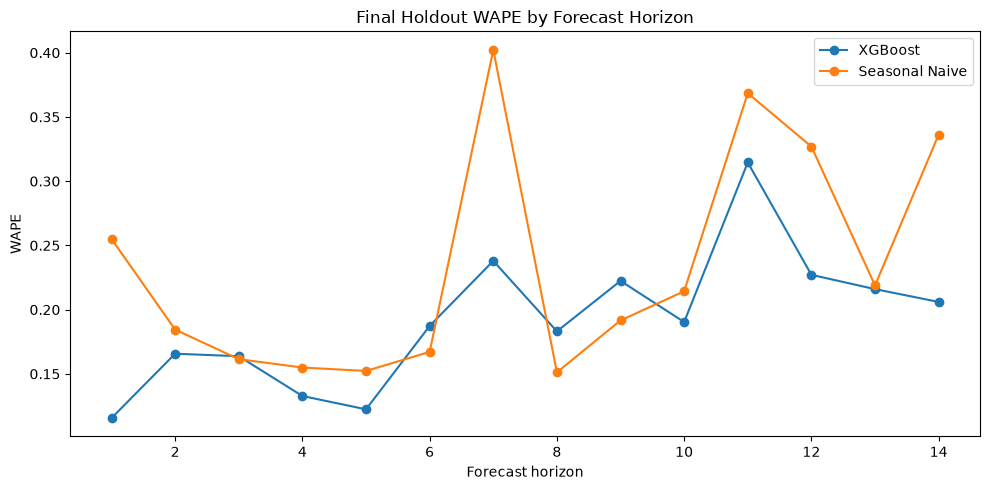

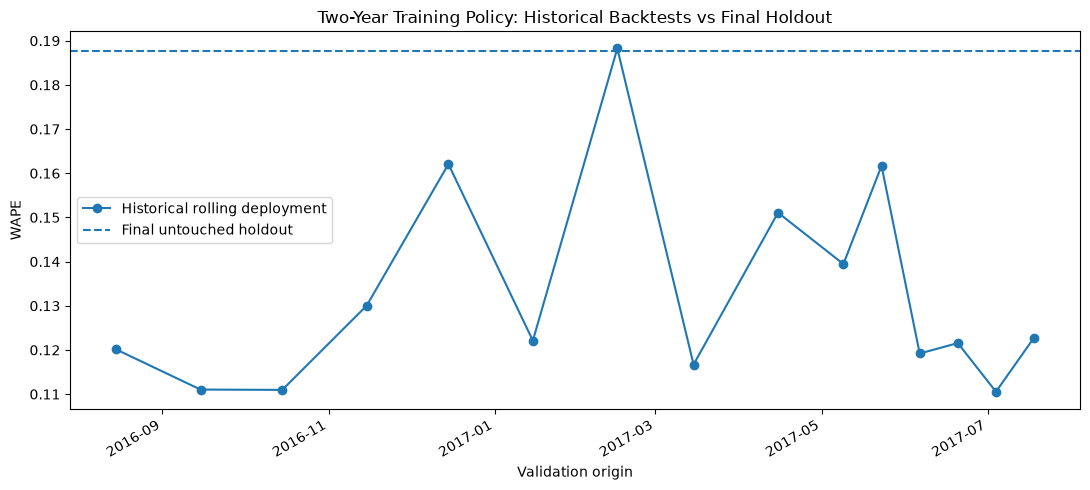

Forecast evidence directory: /Users/zaamine/Desktop/Amine/Training/Kaggle/Corporacion Favorita/retail-demand-forecasting-platform-aws/docs/assets/global_forecasting
Forecast artifact directory: /Users/zaamine/Desktop/Amine/Training/Kaggle/Corporacion Favorita/retail-demand-forecasting-platform-aws/artifacts/global_xgboost

POINT-FORECASTING ARTIFACTS: SAVED


In [187]:
# ---------------------------------------------------------------------
# Persist the most important point-forecasting evidence before moving to
# the promotion / causal layer.
# ---------------------------------------------------------------------

from pathlib import Path
import json
import matplotlib.pyplot as plt


current_directory = Path.cwd()


if (
    current_directory
    / "docs"
).exists():

    project_root = (
        current_directory
    )

elif (
    current_directory.parent
    / "docs"
).exists():

    project_root = (
        current_directory.parent
    )

else:

    raise RuntimeError(
        "Unable to locate project root."
    )


forecast_evidence_dir = (
    project_root
    / "docs"
    / "assets"
    / "global_forecasting"
)


forecast_artifact_dir = (
    project_root
    / "artifacts"
    / "global_xgboost"
)


forecast_evidence_dir.mkdir(
    parents=True,
    exist_ok=True,
)


forecast_artifact_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# ---------------------------------------------------------------------
# Save compact metric tables.
# ---------------------------------------------------------------------

final_model_comparison.to_csv(
    forecast_evidence_dir
    / "final_holdout_model_comparison.csv",
    index=False,
)


final_horizon_metrics.to_csv(
    forecast_evidence_dir
    / "final_holdout_horizon_metrics.csv",
    index=False,
)


series_breadth_summary.to_csv(
    forecast_evidence_dir
    / "final_holdout_series_breadth.csv",
    index=False,
)


series_volume_breadth_summary.to_csv(
    forecast_evidence_dir
    / "final_holdout_series_volume_breadth.csv",
    index=False,
)


series_group_performance.to_csv(
    forecast_evidence_dir
    / "final_holdout_series_group_performance.csv",
    index=False,
)


historical_context.to_csv(
    forecast_evidence_dir
    / "final_holdout_historical_context.csv",
    index=False,
)


# ---------------------------------------------------------------------
# Preserve the label-free final forecast artifact.
# ---------------------------------------------------------------------

final_holdout_forecast.to_parquet(
    forecast_artifact_dir
    / "final_holdout_forecast.parquet",
    index=False,
)


# ---------------------------------------------------------------------
# Preserve the fitted XGBoost model locally.
# The cloud lifecycle / registry will be implemented during Week 4.
# ---------------------------------------------------------------------

final_model.save_model(
    forecast_artifact_dir
    / "xgboost_point_forecast_v1.json"
)


# ---------------------------------------------------------------------
# Save the frozen model contract.
# ---------------------------------------------------------------------

final_model_contract = {
    "champion_id":
        str(
            CHAMPION_ID
        ),

    "training_policy":
        FINAL_TRAINING_POLICY,

    "training_window_years":
        2,

    "forecast_horizon_days":
        int(
            FORECAST_HORIZON
        ),

    "development_end_date":
        str(
            DEVELOPMENT_END_DATE.date()
        ),

    "final_holdout_start":
        str(
            FINAL_HOLDOUT_START.date()
        ),

    "final_holdout_end":
        str(
            FINAL_HOLDOUT_END.date()
        ),

    "n_estimators":
        int(
            FINAL_N_ESTIMATORS
        ),

    "objective":
        str(
            champion_config[
                "objective"
            ]
        ),

    "max_depth":
        int(
            champion_config[
                "max_depth"
            ]
        ),

    "learning_rate":
        float(
            champion_config[
                "learning_rate"
            ]
        ),

    "min_child_weight":
        float(
            champion_config[
                "min_child_weight"
            ]
        ),

    "subsample":
        float(
            champion_config[
                "subsample"
            ]
        ),

    "colsample_bytree":
        float(
            champion_config[
                "colsample_bytree"
            ]
        ),

    "model_features":
        list(
            MODEL_FEATURES_V1
        ),

    "final_holdout_metrics": {
        "wape":
            float(
                xgb_holdout_metrics[
                    "wape"
                ]
            ),

        "mae":
            float(
                xgb_holdout_metrics[
                    "mae"
                ]
            ),

        "rmse":
            float(
                xgb_holdout_metrics[
                    "rmse"
                ]
            ),

        "normalized_bias":
            float(
                xgb_holdout_metrics[
                    "normalized_bias"
                ]
            ),
    },
}


with open(
    forecast_artifact_dir
    / "point_forecast_model_contract_v1.json",
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        final_model_contract,
        file,
        indent=2,
    )


# ---------------------------------------------------------------------
# Portfolio artifact 1: WAPE by forecast horizon.
# ---------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(
        10,
        5,
    )
)


ax.plot(
    final_horizon_metrics[
        "horizon"
    ],
    final_horizon_metrics[
        "xgb_wape"
    ],
    marker="o",
    label="XGBoost",
)


ax.plot(
    final_horizon_metrics[
        "horizon"
    ],
    final_horizon_metrics[
        "seasonal_naive_wape"
    ],
    marker="o",
    label="Seasonal Naive",
)


ax.set_xlabel(
    "Forecast horizon"
)

ax.set_ylabel(
    "WAPE"
)

ax.set_title(
    "Final Holdout WAPE by Forecast Horizon"
)

ax.legend()

fig.tight_layout()


fig.savefig(
    forecast_evidence_dir
    / "final_holdout_wape_by_horizon.png",
    dpi=160,
    bbox_inches="tight",
)


plt.show()


# ---------------------------------------------------------------------
# Portfolio artifact 2: historical rolling deployments vs final holdout.
# ---------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(
        11,
        5,
    )
)


ax.plot(
    selected_policy_history[
        "validation_origin"
    ],
    selected_policy_history[
        "fold_wape"
    ],
    marker="o",
    label="Historical rolling deployment",
)


ax.axhline(
    xgb_holdout_metrics[
        "wape"
    ],
    linestyle="--",
    label="Final untouched holdout",
)


ax.set_xlabel(
    "Validation origin"
)

ax.set_ylabel(
    "WAPE"
)

ax.set_title(
    "Two-Year Training Policy: Historical Backtests vs Final Holdout"
)

ax.legend()

fig.autofmt_xdate()

fig.tight_layout()


fig.savefig(
    forecast_evidence_dir
    / "historical_backtests_vs_final_holdout.png",
    dpi=160,
    bbox_inches="tight",
)


plt.show()


print(
    "Forecast evidence directory:",
    forecast_evidence_dir,
)

print(
    "Forecast artifact directory:",
    forecast_artifact_dir,
)

print()
print(
    "POINT-FORECASTING ARTIFACTS: SAVED"
)

In [191]:
# ---------------------------------------------------------------------
# Build the canonical deployment artifact deterministically.
#
# Heavy model binaries are not versioned in Git. The notebook creates a
# reproducible tar.gz package that can later be uploaded to S3 and
# registered in SageMaker Model Registry.
#
# Archive metadata is normalized so that identical model bytes produce
# the same package SHA-256 across repeated runs.
# ---------------------------------------------------------------------

from pathlib import Path
import gzip
import hashlib
import shutil
import tarfile


artifact_dir = (
    project_root
    / "artifacts"
    / "global_xgboost"
)


raw_model_path = (
    artifact_dir
    / "xgboost_point_forecast_v1.json"
)


package_staging_dir = (
    artifact_dir
    / "package_v1"
)


package_model_path = (
    package_staging_dir
    / "xgboost_point_forecast_v1.json"
)


model_package_path = (
    artifact_dir
    / "model.tar.gz"
)


package_staging_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# Copy the validated raw model into the package staging directory.
shutil.copy2(
    raw_model_path,
    package_model_path,
)


# ---------------------------------------------------------------------
# Create a deterministic tar.gz archive.
#
# Normalizing tar metadata and gzip timestamps avoids a different package
# checksum solely because the packaging command was run at another time.
# ---------------------------------------------------------------------

with open(
    model_package_path,
    "wb",
) as raw_archive:

    with gzip.GzipFile(
        fileobj=raw_archive,
        mode="wb",
        mtime=0,
    ) as gzip_archive:

        with tarfile.open(
            fileobj=gzip_archive,
            mode="w",
        ) as tar_archive:

            tar_info = tar_archive.gettarinfo(
                str(
                    package_model_path
                ),
                arcname="xgboost_point_forecast_v1.json",
            )

            # Normalize filesystem-dependent metadata.
            tar_info.mtime = 0
            tar_info.uid = 0
            tar_info.gid = 0
            tar_info.uname = ""
            tar_info.gname = ""

            with open(
                package_model_path,
                "rb",
            ) as model_file:

                tar_archive.addfile(
                    tar_info,
                    model_file,
                )


def compute_sha256(
    file_path,
    chunk_size=1024 * 1024,
):
    sha256 = hashlib.sha256()

    with open(
        file_path,
        "rb",
    ) as file:

        while True:

            chunk = file.read(
                chunk_size
            )

            if not chunk:
                break

            sha256.update(
                chunk
            )

    return sha256.hexdigest()


raw_model_sha256 = compute_sha256(
    raw_model_path
)

package_sha256 = compute_sha256(
    model_package_path
)


print(
    "Raw model size:",
    f"{raw_model_path.stat().st_size:,}",
    "bytes",
)

print(
    "Raw model SHA-256:",
    raw_model_sha256,
)

print()

print(
    "Model package size:",
    f"{model_package_path.stat().st_size:,}",
    "bytes",
)

print(
    "Model package SHA-256:",
    package_sha256,
)

print()

print(
    "Package contents:"
)

with tarfile.open(
    model_package_path,
    "r:gz",
) as tar_archive:

    for member in tar_archive.getmembers():

        print(
            "-",
            member.name,
        )


assert (
    raw_model_sha256
    == "85115ead6183df4b8eb1024dec26da0359788a9d9d452b187bc1710e839dfffc"
)


assert (
    [
        member.name
        for member in tarfile.open(
            model_package_path,
            "r:gz",
        ).getmembers()
    ]
    == [
        "xgboost_point_forecast_v1.json"
    ]
)


print()
print(
    "DETERMINISTIC MODEL PACKAGE CREATED: PASSED"
)

Raw model size: 99,288,721 bytes
Raw model SHA-256: 85115ead6183df4b8eb1024dec26da0359788a9d9d452b187bc1710e839dfffc

Model package size: 28,303,686 bytes
Model package SHA-256: 003f007a2057bf26b6926a292c9fad2f8e7869ca5e150a6d1b344a3e9a646b73

Package contents:
- xgboost_point_forecast_v1.json

DETERMINISTIC MODEL PACKAGE CREATED: PASSED


In [192]:
# ---------------------------------------------------------------------
# Enrich the frozen model contract with artifact lineage, integrity
# checks and runtime information.
#
# Heavy model and forecast artifacts live in S3.
# Git stores this lightweight contract so the exact validated artifact
# can be identified, audited and reproduced.
# ---------------------------------------------------------------------

from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import xgboost as xgb


# ---------------------------------------------------------------------
# Resolve project paths.
# ---------------------------------------------------------------------

current_directory = Path.cwd()


if (
    current_directory
    / "artifacts"
    / "global_xgboost"
).exists():

    project_root = current_directory

elif (
    current_directory.parent
    / "artifacts"
    / "global_xgboost"
).exists():

    project_root = current_directory.parent

else:

    raise RuntimeError(
        "Unable to locate the project root."
    )


artifact_dir = (
    project_root
    / "artifacts"
    / "global_xgboost"
)


contract_path = (
    artifact_dir
    / "point_forecast_model_contract_v1.json"
)


raw_model_path = (
    artifact_dir
    / "xgboost_point_forecast_v1.json"
)


model_package_path = (
    artifact_dir
    / "model.tar.gz"
)


forecast_path = (
    artifact_dir
    / "final_holdout_forecast.parquet"
)


# ---------------------------------------------------------------------
# Integrity helper.
# ---------------------------------------------------------------------

def compute_sha256(
    file_path,
    chunk_size=1024 * 1024,
):
    sha256 = hashlib.sha256()

    with open(
        file_path,
        "rb",
    ) as file:

        while True:

            chunk = file.read(
                chunk_size
            )

            if not chunk:
                break

            sha256.update(
                chunk
            )

    return sha256.hexdigest()


# ---------------------------------------------------------------------
# Load the existing frozen model contract.
# ---------------------------------------------------------------------

with open(
    contract_path,
    "r",
    encoding="utf-8",
) as file:

    model_contract = json.load(
        file
    )


# ---------------------------------------------------------------------
# Record model artifact lineage.
# ---------------------------------------------------------------------

model_contract[
    "artifact"
] = {
    "model_version":
        "point_forecast_v1",

    "artifact_format":
        "tar.gz",

    "artifact_uri":
        (
            "s3://retail-demand-forecasting-platform-aws-zaamine/"
            "artifacts/global_xgboost/v1/model.tar.gz"
        ),

    "package_size_bytes":
        model_package_path.stat().st_size,

    "package_sha256":
        compute_sha256(
            model_package_path
        ),

    "raw_model_format":
        "xgboost_json",

    "raw_model_uri":
        (
            "s3://retail-demand-forecasting-platform-aws-zaamine/"
            "artifacts/global_xgboost/v1/"
            "xgboost_point_forecast_v1.json"
        ),

    "raw_model_size_bytes":
        raw_model_path.stat().st_size,

    "raw_model_sha256":
        compute_sha256(
            raw_model_path
        ),
}


# ---------------------------------------------------------------------
# Record the frozen, label-free holdout forecast artifact.
# ---------------------------------------------------------------------

model_contract[
    "evaluation_artifacts"
] = {
    "final_holdout_forecast_uri":
        (
            "s3://retail-demand-forecasting-platform-aws-zaamine/"
            "forecasts/global_xgboost/v1/"
            "final_holdout_forecast.parquet"
        ),

    "final_holdout_forecast_size_bytes":
        forecast_path.stat().st_size,

    "final_holdout_forecast_sha256":
        compute_sha256(
            forecast_path
        ),
}


# ---------------------------------------------------------------------
# Record the runtime required to interpret the serialized model.
# ---------------------------------------------------------------------

model_contract[
    "runtime"
] = {
    "python":
        platform.python_version(),

    "xgboost":
        xgb.__version__,

    "pandas":
        pd.__version__,

    "numpy":
        np.__version__,
}


# ---------------------------------------------------------------------
# Validate the two already-frozen model identities.
# ---------------------------------------------------------------------

assert (
    model_contract[
        "artifact"
    ][
        "raw_model_sha256"
    ]
    == "85115ead6183df4b8eb1024dec26da0359788a9d9d452b187bc1710e839dfffc"
)


assert (
    model_contract[
        "artifact"
    ][
        "package_sha256"
    ]
    == "003f007a2057bf26b6926a292c9fad2f8e7869ca5e150a6d1b344a3e9a646b73"
)


# ---------------------------------------------------------------------
# Persist the lightweight contract that will be versioned in Git.
# ---------------------------------------------------------------------

with open(
    contract_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        model_contract,
        file,
        indent=2,
    )


print(
    "Artifact lineage:"
)

print(
    json.dumps(
        model_contract[
            "artifact"
        ],
        indent=2,
    )
)


print()
print(
    "Evaluation artifacts:"
)

print(
    json.dumps(
        model_contract[
            "evaluation_artifacts"
        ],
        indent=2,
    )
)


print()
print(
    "Runtime:"
)

print(
    json.dumps(
        model_contract[
            "runtime"
        ],
        indent=2,
    )
)


print()
print(
    "MODEL CONTRACT ENRICHMENT: PASSED"
)

Artifact lineage:
{
  "model_version": "point_forecast_v1",
  "artifact_format": "tar.gz",
  "artifact_uri": "s3://retail-demand-forecasting-platform-aws-zaamine/artifacts/global_xgboost/v1/model.tar.gz",
  "package_size_bytes": 28303686,
  "package_sha256": "003f007a2057bf26b6926a292c9fad2f8e7869ca5e150a6d1b344a3e9a646b73",
  "raw_model_format": "xgboost_json",
  "raw_model_uri": "s3://retail-demand-forecasting-platform-aws-zaamine/artifacts/global_xgboost/v1/xgboost_point_forecast_v1.json",
  "raw_model_size_bytes": 99288721,
  "raw_model_sha256": "85115ead6183df4b8eb1024dec26da0359788a9d9d452b187bc1710e839dfffc"
}

Evaluation artifacts:
{
  "final_holdout_forecast_uri": "s3://retail-demand-forecasting-platform-aws-zaamine/forecasts/global_xgboost/v1/final_holdout_forecast.parquet",
  "final_holdout_forecast_size_bytes": 407400,
  "final_holdout_forecast_sha256": "61a57c3c3c4ba89b9684380a3044fdceec99c1446a5da4ffb05f6ed4e99b8344"
}

Runtime:
{
  "python": "3.12.9",
  "xgboost": "3.4.1